# NV03 — Phân tích đơn hàng

### Hướng dẫn đọc và chạy bản bàn giao — 15/11/2026

**Nội dung hiện hành:** NV03.1–5: trạng thái, thanh toán, thiết bị, shipment và ngoại lệ; đối chiếu số học và giới hạn quy trình được trình bày riêng.

**Đọc nhanh để trình bày:** **Trạng thái và giá trị đơn** — ô 1, ID `a0587115`; **Shipment và khoảng ngày ghi nhận** — ô 25, ID `a0604d6a`; **Thanh toán và thiết bị** — ô 46, ID `nv033-01`; **Ngoại lệ và chênh COD/non-COD** — ô 66, ID `nv034-01`; **Kết luận nghiệp vụ đơn hàng** — ô 86, ID `nv035-01`. Có thể dùng mục lục của Jupyter/VS Code để đến tiêu đề tương ứng; mọi bảng/hình/kết luận cần thiết đã nằm trong notebook. Chi tiết kiểm toán dài được giữ để truy vết, không cần trình chiếu toàn bộ. Đề xuất liên nghiệp vụ và KPI đánh giá xem [TH01.5](TH01_tong_hop_va_doi_soat_NV01_NV06.ipynb#th01-step4-01).

**Chạy lại:** dùng Python ≥3.11, cài `python -m pip install -r requirements.txt` từ project root; trong VS Code/Jupyter chọn kernel của môi trường đó, rồi **Restart Kernel → Run All**. Chạy NV01→NV06→TH01, không cần biến tạo tay. Mở từ project root hoặc `notebook/04_phan_tich_kinh_doanh/`; các cell tự tìm root qua thư mục cha. Không lưu đè output lịch sử khi chỉ kiểm chứng; chạy trên bản sao ngoài repository nếu cần lưu lượt mới. Chưa chứng nhận cài đặt trên môi trường sạch hoặc mọi phiên bản trong khoảng requirements.

**Đầu vào:** CSV gốc, hai bảng tiền xử lý ở data/processed khi phần phân tích cần, và notebook hàm dùng chung.

**Cách đọc phạm vi:** Một order_id là cấp đơn; tổng hợp item/payment trước JOIN. Payment=Net chưa là thực thu. Thiếu shipment chưa là giao thất bại, khoảng ngày nguồn chưa là SLA, chênh COD chưa là nhân quả.

**Lịch sử và kiểm chứng hiện tại:** các phát biểu “chưa triển khai” trong phần nối trước mô tả thời điểm của phần đó; ưu tiên phạm vi hiện hành ở đây. Output/execution_count/metadata cũ được bảo toàn. Các mốc lịch sử cần đối chiếu được lưu trong notebook hàm dùng chung.

---

## NV03.1 — Tổng quan đơn hàng và trạng thái đơn hàng

**Phạm vi hiện tại (đồng bộ 15/11/2026):** NV03.1–NV03.5 đã có: trạng thái, thời gian đặt hàng, giá trị đơn và tổng hợp; dùng orders/order_items/payments và tham chiếu kiểm chứng đã lưu.
Đơn vị chính là **một order_id duy nhất**. Các nhãn trạng thái được đọc từ CSV và giữ nguyên, không tự gộp thành “thành công/thất bại”.
Ngày bắt đầu/kết thúc là phạm vi order_date quan sát, không phải thời gian toàn bộ vòng đời đơn.

**Cách diễn giải xuyên suốt:** order_date là ngày đặt hàng; order_status là trạng thái được ghi trong bộ dữ liệu.
Không có lịch sử chuyển trạng thái hoặc thời điểm trạng thái trong ba nguồn này.
Cơ cấu theo năm/tháng đặt hàng không phải số sự kiện giao, hủy hoặc trả xảy ra trong cùng năm/tháng.
Không suy diễn thời gian giao thực tế, mô hình hoặc nguyên nhân từ các phân tích mô tả.

Tiền dùng **ĐVT = đơn vị tiền nguồn**, chưa xác minh tên tiền tệ. Net là sau giảm giá, **chưa trừ hoàn tiền**,
chưa mặc định là doanh thu kế toán, tiền thực thu hoặc lợi nhuận.


### Đồng bộ với tiền xử lý chung GD2 — 15/11/2026

GD2 đã nghiệm thu tại commit `fdff37f`, hợp đồng `2.3.1.3-v1`; 139/139 là số kiểm thử của lần nghiệm thu GD2, không phải số chạy lại trong notebook này. Tham chiếu `docs/gd2/preprocessing_contract.md`, `docs/gd2/handoff.md` và báo cáo `docs/reviews/bai_toan_1_gd2_step2_20261115.md`.

`orders_common`: 646.945 dòng, khóa order_id, 30 cột; `order_items_common`: 714.669 dòng, khóa item_row_id, 19 cột. Đọc bằng `src.preprocessing.delivery.read_processed` và schema tương ứng; `\N` là NULL, ID là chuỗi và tiền là Decimal. Giữ 16 lần lặp thêm của cặp đơn–sản phẩm và cả hai slot mã. Tổng Payment/Refund ở cấp đơn; không cộng tiền cấp đơn sau JOIN nhiều dòng hàng.

Quy ước chung: Gross = quantity × unit_price; Discount là số tiền giảm dòng hàng; Net = Gross − Discount, chưa trừ Refund. Payment và Refund là giá trị ghi nhận, chưa là quyết toán/thực thu. Không có bản ghi Returns thì refund_amount_observed là NULL, không phải xác nhận hoàn bằng 0. COGS kiểm chứng từ danh mục phải tách khỏi sales.COGS; ĐVT tiền nguồn vẫn chưa xác minh. Các điều kiện/phát hiện nghiệp vụ thiếu chứng từ không được đóng chỉ vì GD2 hoàn tất.

Giữ các ledger raw để đối chứng độc lập, các kiểm tra khóa/JOIN và xử lý riêng theo nghiệp vụ. Chưa thay toàn bộ nguồn bằng view chung. Output/execution_count/metadata trên đĩa là bằng chứng lịch sử, được bảo toàn; kết quả chạy kiểm chứng Bước 2 được lưu riêng trong báo cáo và hồ sơ JSON. Các ghi chú “chưa triển khai” theo từng lần nối phần ở bên dưới mô tả lịch sử tại thời điểm đó, không thay thế trạng thái hiện tại ở đầu notebook.

NV03 cell 13 dùng exact_sum của GD2 cho tổng Gross/Discount/Net/Payment. Giữ ledger cấp đơn và validate one_to_one sau khi nhóm con; phân bố theo order_date và status snapshot không phải lịch sử chuyển trạng thái. Không thay ngày giao thực tế bằng ngày shipment dự kiến.


### Nguồn, kiểm tra đầu vào và quy tắc tổng hợp

Kiểm tra CSV có header hợp lệ, số cột nhất quán, kiểu đọc, NULL, chuỗi trắng, khóa order_id, ngày và các trường số.
Giữ mã dạng chuỗi; không tự sửa/xóa dữ liệu. order_items có thể nhiều dòng/đơn, payments cũng được tổng hợp theo đơn
trước JOIN dù nguồn hiện tại có thể một dòng/đơn. Cặp order_id–product_id không được mặc định là khóa để xóa dòng trùng.

Công thức kế thừa V02: $Gross_o=\sum quantity_l\times unit\_price_l$;
$Discount_o=\sum discount\_amount_l$; $Net_o=Gross_o-Discount_o$.
discount_amount là tiền của **cả dòng hàng**, không nhân thêm quantity.
Đọc lexeme số gốc vào Decimal, không làm tròn trung gian; dung sai đối chiếu tiền đọc từ V02.
Các tổng theo trạng thái/đơn phải bảo toàn chính xác; dung sai 0,05 chỉ áp dụng đối chiếu tài chính, không cho phép sai số số đơn.

Tham chiếu NV02.1/NV02.3 được đọc từ **bảng output đã lưu** trong notebook NV02, không chạy hoặc sửa notebook đó.
Hash các CSV phải khớp V02/V03. Không xuất bảng chi tiết hoặc báo cáo phụ.


In [17]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime
from decimal import Decimal, InvalidOperation
from html.parser import HTMLParser
import csv, hashlib, json, math, os, platform, sys
import statistics
sys.dont_write_bytecode = True

from pathlib import Path
import json
import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next(
    (path for path in (start, *start.parents)
     if (path / "notebook/00_ham_dung_chung.ipynb").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")

support_file = ROOT / "notebook/00_ham_dung_chung.ipynb"
support_doc = json.loads(support_file.read_text(encoding="utf-8"))
loader = "".join(support_doc["cells"][1]["source"])
exec(compile(loader, str(support_file), "exec"), {"SUPPORT_FILE": support_file})
from datathon.runtime import read_reference, reference_path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display
from datathon.eda.profile_table import read_table
get_ipython().run_line_magic('matplotlib','inline')
plt.rcParams.update({'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_rows',20)
pd.set_option('display.max_columns',12)

from datathon.notebook_integrity import load_notebook_for_audit, snapshot_files
TARGET=ROOT/'notebook/04_phan_tich_kinh_doanh/NV03_phan_tich_don_hang.ipynb'
PATHS={name:ROOT/f'data/raw/{name}.csv' for name in ['orders','order_items','payments']}
NV02_PATH=ROOT/'notebook/04_phan_tich_kinh_doanh/NV02_phan_tich_khach_hang.ipynb'
def digest(path):
    with Path(path).open('rb') as stream:return hashlib.file_digest(stream,'sha256').hexdigest()
def protected_snapshot():
    return {p.relative_to(ROOT).as_posix():digest(p) for p in sorted(ROOT.rglob('*'))
        if p.is_file() and p!=TARGET and not any(x in p.parts for x in ['.git','__pycache__','.ipynb_checkpoints'])}
protected_before=protected_snapshot()
v02=json.loads(reference_path('reports/tables/gd1/validations/v02.json').read_text(encoding='utf-8'),parse_float=Decimal)
v03=json.loads(reference_path('reports/tables/gd1/validations/v03.json').read_text(encoding='utf-8'),parse_float=Decimal)
assert v02['status']=='ok' and all(v02['checks'].values())
assert v03['status'] in {'ok','completed_with_findings'} and all(v03['checks'].values())
ZERO=Decimal(0); TOL=Decimal(str(v02['tolerance']))
assert TOL==Decimal('0.05')
for report in [v02,v03]:
    for name,path in PATHS.items():assert digest(path)==report['sources'][name]['sha256']
frames={name:read_table(path) for name,path in PATHS.items()}
orders,items,payments=(frames[n] for n in ['orders','order_items','payments'])
for name,fields in [('order_items',['quantity','unit_price','discount_amount']),('payments',['payment_value'])]:
    exact=pd.read_csv(PATHS[name],dtype='string',encoding='utf-8-sig',usecols=fields,skip_blank_lines=False)
    assert len(exact)==len(frames[name])
    for field in fields:frames[name][field]=exact[field]
def fmt(value,digits=0):
    if value is None or pd.isna(value):return '—'
    return f'{value:,.{digits}f}'.replace(',','_').replace('.',',').replace('_','.')
def pct(a,b):return Decimal(str(a))/Decimal(str(b))*100 if b else None
def fpct(value):return '—' if value is None or pd.isna(value) else fmt(value,2)+'%'
def divide(a,b):return Decimal(str(a))/Decimal(str(b)) if b else None

class SavedTableParser(HTMLParser):
    def __init__(self):
        super().__init__();self.rows=[];self.row=None;self.cell=None
    def handle_starttag(self,tag,attrs):
        if tag=='tr':self.row=[]
        elif tag in ('th','td') and self.row is not None:self.cell=[]
    def handle_data(self,data):
        if self.cell is not None:self.cell.append(data)
    def handle_endtag(self,tag):
        if tag in ('th','td') and self.cell is not None:
            self.row.append(''.join(self.cell).strip());self.cell=None
        elif tag=='tr' and self.row is not None:
            self.rows.append(self.row);self.row=None
def saved_table(required):
    notebook=json.loads(NV02_PATH.read_text(encoding='utf-8'))
    matches=[]
    for i,cell in enumerate(notebook['cells']):
        for output in cell.get('outputs',[]):
            h=output.get('data',{}).get('text/html')
            if not h:continue
            parser=SavedTableParser();parser.feed(''.join(h) if isinstance(h,list) else h)
            if parser.rows and set(required)<=set(parser.rows[0]):
                header=parser.rows[0]
                matches.append((i,[dict(zip(header,row)) for row in parser.rows[1:] if len(row)==len(header)]))
    assert len(matches)==1, f'Không xác định duy nhất bảng NV02: {required}'
    return matches[0]
def saved_number(text,integer=False):
    cleaned=str(text).strip().replace('%','')
    if integer:return int(cleaned.replace('.','').replace(',',''))
    return Decimal(cleaned.replace('.','').replace(',','.')) if ',' in cleaned else Decimal(cleaned)
nv02_status_cell,nv02_status_rows=saved_table(['Số đơn','Khách có trạng thái','% toàn bộ đơn'])
nv02_counts={row['']:saved_number(row['Số đơn'],True) for row in nv02_status_rows if row['Số đơn']}
nv02_value_cell,nv02_value_rows=saved_table(['Phạm vi','gross (ĐVT)','net (ĐVT)','AOV Net gộp/đơn'])
nv02_delivered_row=next(row for row in nv02_value_rows if row['Phạm vi']=='B — Chỉ delivered')
nv02_delivered_net=saved_number(nv02_delivered_row['net (ĐVT)'])
display(pd.DataFrame([{'Python':platform.python_version(),'Pandas':pd.__version__,
    'V02 hợp lệ':True,'V03 trạng thái':v03['status'],'Hash nguồn khớp':True,
    'Ô output NV02.1 (chỉ số 0)':nv02_status_cell,'Ô output NV02.3 (chỉ số 0)':nv02_value_cell}]))
display(Markdown('Số đếm dùng **đơn** hoặc **khách** như nhãn; tiền dùng ĐVT, tổng lớn có thể trình bày triệu ĐVT. '
    'Dấu chấm tách nghìn, dấu phẩy thập phân; — là thiếu/không áp dụng. Không hiển thị toàn bộ đơn hoặc dòng hàng.'))


,Python,Pandas,V02 hợp lệ,V03 trạng thái,Hash nguồn khớp,Ô output NV02.1 (chỉ số 0),Ô output NV02.3 (chỉ số 0)
0,3.11.7,2.2.3,True,completed_with_findings,True,15,56


Số đếm dùng **đơn** hoặc **khách** như nhãn; tiền dùng ĐVT, tổng lớn có thể trình bày triệu ĐVT. Dấu chấm tách nghìn, dấu phẩy thập phân; — là thiếu/không áp dụng. Không hiển thị toàn bộ đơn hoặc dòng hàng.

In [18]:
expected_columns={
 'orders':['order_id','order_date','customer_id','zip','order_status','payment_method','device_type','order_source'],
 'order_items':['order_id','product_id','quantity','unit_price','discount_amount','promo_id','promo_id_2'],
 'payments':['order_id','payment_method','payment_value','installments']}
for name,frame in frames.items():assert list(frame.columns)==expected_columns[name]
quality=pd.DataFrame([{'Bảng':name,'Trường':field,'Dòng':len(frame),'Kiểu đọc/phân tích':str(frame[field].dtype),
    'NULL':int(frame[field].isna().sum()),'Chuỗi trắng':int(frame[field].astype('string').str.fullmatch(r'\s*',na=False).sum()),
    'Phân biệt không NULL':int(frame[field].nunique())} for name,frame in frames.items() for field in frame.columns])
display(quality)
required={'orders':['order_id','order_date','customer_id','order_status'],
          'order_items':['order_id','product_id','quantity','unit_price','discount_amount'],
          'payments':['order_id','payment_value']}
for name,fields in required.items():
    assert frames[name][fields].notna().all().all()
    assert not frames[name][fields].astype('string').apply(lambda c:c.str.fullmatch(r'\s*',na=False)).any().any()
assert orders.order_id.is_unique
date_text=orders.order_date.astype('string')
orders['date']=pd.to_datetime(date_text.where(date_text.str.fullmatch(r'\d{4}-\d{2}-\d{2}',na=False)),
                              format='%Y-%m-%d',errors='coerce')
assert orders.date.notna().all()
orders['year']=orders.date.dt.year
orders['month']=orders.date.dt.to_period('M').astype(str)
def exact_decimal(text):
    try:value=Decimal(str(text))
    except (InvalidOperation,ValueError):return None
    return value if value.is_finite() else None
numeric_rows=[]
for name,fields in [('order_items',['quantity','unit_price','discount_amount']),('payments',['payment_value'])]:
    for field in fields:
        parsed=frames[name][field].map(exact_decimal);valid=parsed.dropna()
        numeric_rows.append({'Bảng':name,'Trường':field,'NULL/không hợp lệ/không hữu hạn':int(parsed.isna().sum()),
            'Âm':int(valid.lt(0).sum()),'Bằng 0':int(valid.eq(0).sum())})
        assert parsed.notna().all(), f'{name}.{field} không hợp lệ; không tự loại dòng'
        frames[name][field]=parsed
numeric_quality=pd.DataFrame(numeric_rows)
display(numeric_quality)
key_links=pd.DataFrame([
 {'Quan hệ':'orders.order_id','Dòng':len(orders),'Mã đơn phân biệt':orders.order_id.nunique(),
  'Mã NULL':int(orders.order_id.isna().sum()),'Mã trùng dư':int(orders.order_id.duplicated().sum()),'Mồ côi':0,'Đơn thiếu dòng con':0},
 *[{'Quan hệ':name+' → orders','Dòng':len(frame),'Mã đơn phân biệt':frame.order_id.nunique(),
    'Mã NULL':int(frame.order_id.isna().sum()),'Mã trùng dư':int(frame.order_id.duplicated().sum()),
    'Mồ côi':int((~frame.order_id.isin(orders.order_id)).sum()),'Đơn thiếu dòng con':int((~orders.order_id.isin(frame.order_id)).sum())}
    for name,frame in [('order_items',items),('payments',payments)]]])
display(key_links)
assert key_links[['Mã NULL','Mồ côi','Đơn thiếu dòng con']].eq(0).all().all()
duplicate_item_pairs=int(items.duplicated(['order_id','product_id']).sum())
display(Markdown(f'**Quan sát đầu vào:** khóa orders duy nhất; có **{fmt(duplicate_item_pairs)} dòng dư theo cặp order_id–product_id**, '
    'được giữ nguyên vì cặp này chưa được xác lập là khóa. NULL ở trường tùy chọn như mã khuyến mãi được báo nhưng không dùng để loại đơn. '
    '**Ý nghĩa:** cần chọn đúng cấp tổng hợp trước JOIN, nếu không Payment có thể bị cộng lặp theo dòng hàng. '
    '**Giới hạn:** kiểm tra cấu trúc và số hợp lệ chưa xác minh toàn bộ ý nghĩa nghiệp vụ của trạng thái hoặc thanh toán.'))


,Bảng,Trường,Dòng,Kiểu đọc/phân tích,NULL,Chuỗi trắng,Phân biệt không NULL
0,orders,order_id,646945,string,0,0,646945
1,orders,order_date,646945,object,0,0,3833
2,orders,customer_id,646945,string,0,0,90246
3,orders,zip,646945,string,0,0,29932
4,orders,order_status,646945,object,0,0,6
5,orders,payment_method,646945,object,0,0,5
6,orders,device_type,646945,object,0,0,3
7,orders,order_source,646945,object,0,0,6
8,order_items,order_id,714669,string,0,0,646945
9,order_items,product_id,714669,string,0,0,1598


,Bảng,Trường,NULL/không hợp lệ/không hữu hạn,Âm,Bằng 0
0,order_items,quantity,0,0,0
1,order_items,unit_price,0,0,0
2,order_items,discount_amount,0,0,438353
3,payments,payment_value,0,0,0


,Quan hệ,Dòng,Mã đơn phân biệt,Mã NULL,Mã trùng dư,Mồ côi,Đơn thiếu dòng con
0,orders.order_id,646945,646945,0,0,0,0
1,order_items → orders,714669,646945,0,67724,0,0
2,payments → orders,646945,646945,0,0,0,0


**Quan sát đầu vào:** khóa orders duy nhất; có **16 dòng dư theo cặp order_id–product_id**, được giữ nguyên vì cặp này chưa được xác lập là khóa. NULL ở trường tùy chọn như mã khuyến mãi được báo nhưng không dùng để loại đơn. **Ý nghĩa:** cần chọn đúng cấp tổng hợp trước JOIN, nếu không Payment có thể bị cộng lặp theo dòng hàng. **Giới hạn:** kiểm tra cấu trúc và số hợp lệ chưa xác minh toàn bộ ý nghĩa nghiệp vụ của trạng thái hoặc thanh toán.

### NV03.1.1 — Quy mô đơn hàng và trạng thái được ghi nhận

Đếm order_id duy nhất; các trạng thái thực tế được đọc từ dữ liệu rồi xếp theo số đơn giảm dần,
đồng hạng theo nhãn chuỗi tăng dần. Tỷ trọng trạng thái = số đơn trạng thái / toàn bộ đơn.
Khách có thể có nhiều trạng thái ở các đơn khác nhau; nếu tham chiếu số khách theo trạng thái thì không cộng để suy tổng khách duy nhất.


,Chỉ tiêu,Kết quả,Đơn vị
0,Tổng đơn,646.945,order_id duy nhất
1,Ngày đặt đơn đầu/cuối,04/07/2012 – 31/12/2022,"ngày đặt, không phải ngày đổi trạng thái"
2,Ngày có ít nhất một đơn,3.833,ngày
3,Khách phân biệt trong orders,90.246,customer_id
4,Trạng thái thực tế,6,nhãn không NULL


,Số đơn,% toàn bộ đơn
order_status,,
delivered,516.716,"79,87%"
cancelled,59.462,"9,19%"
returned,36.142,"5,59%"
shipped,13.773,"2,13%"
paid,13.577,"2,10%"
created,7.275,"1,12%"


,Trạng thái,CSV hiện tại,NV02.1 output,Sai lệch
0,delivered,516716,516716,0
1,cancelled,59462,59462,0
2,returned,36142,36142,0
3,shipped,13773,13773,0
4,paid,13577,13577,0
5,created,7275,7275,0


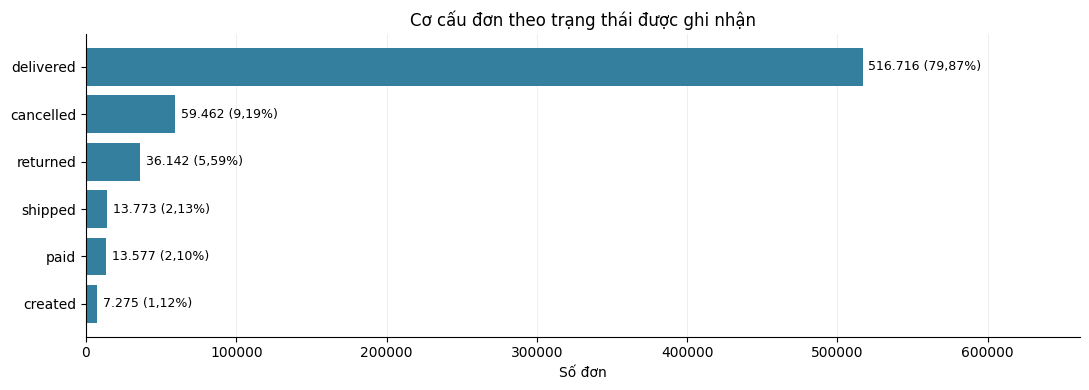

In [19]:
n_orders=len(orders); n_customers_with_orders=orders.customer_id.nunique()
date_start,date_end=orders.date.min(),orders.date.max()
observed_days=orders.date.nunique()
status_counts=orders.groupby('order_status',sort=True).size().rename('orders').reset_index().sort_values(
    ['orders','order_status'],ascending=[False,True],kind='stable').set_index('order_status')
status_order=status_counts.index.to_list()
status_counts['share_pct']=[pct(n,n_orders) for n in status_counts.orders]
overview=pd.DataFrame([
 {'Chỉ tiêu':'Tổng đơn','Kết quả':fmt(n_orders),'Đơn vị':'order_id duy nhất'},
 {'Chỉ tiêu':'Ngày đặt đơn đầu/cuối','Kết quả':f'{date_start:%d/%m/%Y} – {date_end:%d/%m/%Y}','Đơn vị':'ngày đặt, không phải ngày đổi trạng thái'},
 {'Chỉ tiêu':'Ngày có ít nhất một đơn','Kết quả':fmt(observed_days),'Đơn vị':'ngày'},
 {'Chỉ tiêu':'Khách phân biệt trong orders','Kết quả':fmt(n_customers_with_orders),'Đơn vị':'customer_id'},
 {'Chỉ tiêu':'Trạng thái thực tế','Kết quả':fmt(len(status_counts)),'Đơn vị':'nhãn không NULL'}])
display(overview)
status_display=pd.DataFrame({'Số đơn':status_counts.orders.map(fmt),'% toàn bộ đơn':status_counts.share_pct.map(fpct)})
display(status_display)
status_reference=pd.DataFrame([{'Trạng thái':s,'CSV hiện tại':int(r.orders),'NV02.1 output':nv02_counts.get(s),
    'Sai lệch':int(r.orders)-nv02_counts.get(s,0)} for s,r in status_counts.iterrows()])
display(status_reference)
assert set(status_counts.index)==set(nv02_counts) and status_reference['Sai lệch'].eq(0).all()
assert n_orders==v02['metrics']['orders_rows']
fig,ax=plt.subplots(figsize=(11,4))
positions=np.arange(len(status_counts))
ax.barh(positions,status_counts.orders,color='#347f9e')
ax.set(yticks=positions,yticklabels=status_order,xlabel='Số đơn',title='Cơ cấu đơn theo trạng thái được ghi nhận')
for y,(s,r) in enumerate(status_counts.iterrows()):
    ax.text(int(r.orders)+n_orders*.006,y,f'{fmt(r.orders)} ({fpct(r.share_pct)})',va='center',fontsize=9)
ax.invert_yaxis();ax.set_xlim(0,status_counts.orders.max()*1.28);ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();display(fig);plt.close(fig)


In [20]:
largest_status=status_counts.orders.idxmax()
display(Markdown(f'**Kết quả quan sát:** **{fmt(n_orders)} đơn**, **{fmt(n_customers_with_orders)} khách**, '
    f'**{fmt(observed_days)} ngày có đơn**, **{len(status_counts)} trạng thái**. '
    f'**{largest_status}** có **{fmt(status_counts.at[largest_status,"orders"])} đơn**, '
    f'chiếm **{fpct(status_counts.at[largest_status,"share_pct"])}** tổng đơn. '
    '**Ý nghĩa:** các kết quả NV01/NV02 gồm nhiều trạng thái, không chỉ các đơn delivered; xác định phạm vi trạng thái là cần thiết '
    'trước khi gọi một chỉ tiêu là doanh thu hoặc giao dịch thành công. '
    '**Giới hạn:** tỷ trọng delivered chưa phải tỷ lệ hoàn tất quy trình đã được xác minh. '
    '**Câu hỏi tiếp:** trạng thái phản ánh thời điểm trích xuất nào, và từng nhãn có tiêu chí nghiệp vụ gì?'))


**Kết quả quan sát:** **646.945 đơn**, **90.246 khách**, **3.833 ngày có đơn**, **6 trạng thái**. **delivered** có **516.716 đơn**, chiếm **79,87%** tổng đơn. **Ý nghĩa:** các kết quả NV01/NV02 gồm nhiều trạng thái, không chỉ các đơn delivered; xác định phạm vi trạng thái là cần thiết trước khi gọi một chỉ tiêu là doanh thu hoặc giao dịch thành công. **Giới hạn:** tỷ trọng delivered chưa phải tỷ lệ hoàn tất quy trình đã được xác minh. **Câu hỏi tiếp:** trạng thái phản ánh thời điểm trích xuất nào, và từng nhãn có tiêu chí nghiệp vụ gì?

### NV03.1.2 — Cơ cấu theo năm và tháng đặt hàng

Số đơn được phân nhóm theo **order_date**, không theo ngày trạng thái được thiết lập.
Tỷ trọng trong kỳ = số đơn trạng thái / tổng đơn cùng kỳ; thay đổi tỷ trọng biểu diễn bằng **điểm phần trăm (đpt)**,
khác phần trăm tăng trưởng số đơn. Bảng mỗi trạng thái hiển thị **số đơn (tỷ trọng)**.

Năm đầu bắt đầu trong tháng 07; tháng đầu bắt đầu sau ngày 01. Không coi các tổng này là đủ lịch để so với kỳ trọn vẹn.
Cột số ngày có đơn mô tả độ bao phủ quan sát, không tự xác nhận ngày không đơn là thiếu dữ liệu.
So biến động đpt năm chỉ thực hiện giữa năm đủ phạm vi lịch; tháng xếp hạng biến động chỉ dùng hai tháng liền kề có phạm vi đầy đủ.

Cờ **N tháng <2.000 đơn** chỉ là ngưỡng mô tả để nhắc đọc quy mô cùng tỷ lệ, không phải kiểm định hay bảo đảm độ tin cậy.
Không loại tháng nhỏ. Cuối dữ liệu có thể có giới hạn quan sát, nhưng chưa chứng minh đó là nguyên nhân của cơ cấu trạng thái.


In [21]:
year_index=pd.Index(range(date_start.year,date_end.year+1),name='Năm đặt')
month_index=pd.period_range(date_start.to_period('M'),date_end.to_period('M'),freq='M').astype(str)
year_counts=pd.crosstab(orders.year,orders.order_status).reindex(index=year_index,columns=status_order,fill_value=0)
month_counts=pd.crosstab(orders.month,orders.order_status).reindex(index=month_index,columns=status_order,fill_value=0)
year_totals=year_counts.sum(axis=1);month_totals=month_counts.sum(axis=1)
year_shares=year_counts.div(year_totals.replace(0,np.nan),axis=0)*100
month_shares=month_counts.div(month_totals.replace(0,np.nan),axis=0)*100
year_observed_days=orders.groupby('year').date.nunique().reindex(year_index,fill_value=0)
month_observed_days=orders.groupby('month').date.nunique().reindex(month_index,fill_value=0)
year_complete=pd.Series({y:date_start<=pd.Timestamp(year=y,month=1,day=1) and date_end>=pd.Timestamp(year=y,month=12,day=31) for y in year_index})
month_complete=pd.Series({m:date_start<=pd.Period(m).start_time.normalize() and date_end>=pd.Period(m).end_time.normalize() for m in month_index})
SMALL_MONTH_N=2000
def period_table(counts,shares,totals,days,complete,is_month=False):
    out=pd.DataFrame(index=counts.index)
    out.index.name='Tháng đặt' if is_month else 'Năm đặt'
    out['Tổng đơn']=totals.map(fmt);out['Ngày có đơn']=days.map(fmt)
    out['Phạm vi lịch']=complete.map({True:'Đủ phạm vi đầu–cuối kỳ',False:'Chỉ một phần kỳ'})
    if is_month:out['Cờ quy mô']=totals.map(lambda n:'N<2.000 — đọc kèm số đơn' if n<SMALL_MONTH_N else '—')
    for s in status_order:out[s]=[f'{fmt(n)} ({fmt(p,2)}%)' if pd.notna(p) else f'{fmt(n)} (—)' for n,p in zip(counts[s],shares[s])]
    return out
annual_display=period_table(year_counts,year_shares,year_totals,year_observed_days,year_complete)
monthly_display=period_table(month_counts,month_shares,month_totals,month_observed_days,month_complete,True)
with pd.option_context('display.max_columns',None,'display.max_rows',None):
    display(annual_display)
    display(monthly_display)
year_share_change=year_shares.diff().where((year_complete & year_complete.shift(1,fill_value=False)),axis=0)
change_display=year_share_change.copy()
for s in status_order:change_display[s]=change_display[s].map(lambda x:fmt(x,2))
change_display.insert(0,'Tổng đơn kỳ hiện tại',year_totals.map(fmt))
display(Markdown('**Thay đổi cơ cấu so năm liền trước (đpt); — khi chưa có cặp năm đủ phạm vi:**'))
with pd.option_context('display.max_columns',None):display(change_display)


,Tổng đơn,Ngày có đơn,Phạm vi lịch,delivered,cancelled,returned,shipped,paid,created
Năm đặt,,,,,,,,,
2012,32.051,181,Chỉ một phần kỳ,"25.663 (80,07%)","2.898 (9,04%)","1.819 (5,68%)","664 (2,07%)","691 (2,16%)","316 (0,99%)"
2013,76.849,365,Đủ phạm vi đầu–cuối kỳ,"61.588 (80,14%)","7.093 (9,23%)","4.323 (5,63%)","1.479 (1,92%)","1.558 (2,03%)","808 (1,05%)"
2014,80.645,365,Đủ phạm vi đầu–cuối kỳ,"64.688 (80,21%)","7.287 (9,04%)","4.484 (5,56%)","1.672 (2,07%)","1.672 (2,07%)","842 (1,04%)"
2015,82.622,365,Đủ phạm vi đầu–cuối kỳ,"66.163 (80,08%)","7.665 (9,28%)","4.621 (5,59%)","1.672 (2,02%)","1.679 (2,03%)","822 (0,99%)"
2016,82.247,366,Đủ phạm vi đầu–cuối kỳ,"66.067 (80,33%)","7.480 (9,09%)","4.655 (5,66%)","1.668 (2,03%)","1.543 (1,88%)","834 (1,01%)"
2017,76.010,365,Đủ phạm vi đầu–cuối kỳ,"61.144 (80,44%)","6.907 (9,09%)","4.247 (5,59%)","1.552 (2,04%)","1.446 (1,90%)","714 (0,94%)"
2018,69.510,365,Đủ phạm vi đầu–cuối kỳ,"55.740 (80,19%)","6.486 (9,33%)","3.803 (5,47%)","1.423 (2,05%)","1.376 (1,98%)","682 (0,98%)"
2019,41.601,365,Đủ phạm vi đầu–cuối kỳ,"33.259 (79,95%)","3.860 (9,28%)","2.300 (5,53%)","872 (2,10%)","859 (2,06%)","451 (1,08%)"
2020,34.881,366,Đủ phạm vi đầu–cuối kỳ,"27.975 (80,20%)","3.253 (9,33%)","1.950 (5,59%)","670 (1,92%)","682 (1,96%)","351 (1,01%)"


,Tổng đơn,Ngày có đơn,Phạm vi lịch,Cờ quy mô,delivered,cancelled,returned,shipped,paid,created
Tháng đặt,,,,,,,,,,
2012-07,5.294,28,Chỉ một phần kỳ,—,"4.233 (79,96%)","483 (9,12%)","290 (5,48%)","131 (2,47%)","110 (2,08%)","47 (0,89%)"
2012-08,6.427,31,Đủ phạm vi đầu–cuối kỳ,—,"5.132 (79,85%)","609 (9,48%)","353 (5,49%)","117 (1,82%)","145 (2,26%)","71 (1,10%)"
2012-09,5.219,30,Đủ phạm vi đầu–cuối kỳ,—,"4.202 (80,51%)","428 (8,20%)","320 (6,13%)","98 (1,88%)","122 (2,34%)","49 (0,94%)"
2012-10,4.285,31,Đủ phạm vi đầu–cuối kỳ,—,"3.420 (79,81%)","358 (8,35%)","262 (6,11%)","109 (2,54%)","93 (2,17%)","43 (1,00%)"
2012-11,4.142,30,Đủ phạm vi đầu–cuối kỳ,—,"3.279 (79,16%)","422 (10,19%)","237 (5,72%)","76 (1,83%)","85 (2,05%)","43 (1,04%)"
2012-12,6.684,31,Đủ phạm vi đầu–cuối kỳ,—,"5.397 (80,75%)","598 (8,95%)","357 (5,34%)","133 (1,99%)","136 (2,03%)","63 (0,94%)"
2013-01,3.665,31,Đủ phạm vi đầu–cuối kỳ,—,"2.936 (80,11%)","326 (8,89%)","202 (5,51%)","71 (1,94%)","88 (2,40%)","42 (1,15%)"
2013-02,4.661,28,Đủ phạm vi đầu–cuối kỳ,—,"3.726 (79,94%)","444 (9,53%)","264 (5,66%)","80 (1,72%)","99 (2,12%)","48 (1,03%)"
2013-03,6.590,31,Đủ phạm vi đầu–cuối kỳ,—,"5.287 (80,23%)","617 (9,36%)","376 (5,71%)","109 (1,65%)","130 (1,97%)","71 (1,08%)"


**Thay đổi cơ cấu so năm liền trước (đpt); — khi chưa có cặp năm đủ phạm vi:**

order_status,Tổng đơn kỳ hiện tại,delivered,cancelled,returned,shipped,paid,created
Năm đặt,,,,,,,
2012,32.051,—,—,—,—,—,—
2013,76.849,—,—,—,—,—,—
2014,80.645,"0,07","-0,19","-0,07","0,15","0,05","-0,01"
2015,82.622,"-0,13","0,24","0,03","-0,05","-0,04","-0,05"
2016,82.247,"0,25","-0,18","0,07","0,00","-0,16","0,02"
2017,76.010,"0,11","-0,01","-0,07","0,01","0,03","-0,07"
2018,69.510,"-0,25","0,24","-0,12","0,01","0,08","0,04"
2019,41.601,"-0,24","-0,05","0,06","0,05","0,09","0,10"
2020,34.881,"0,25","0,05","0,06","-0,18","-0,11","-0,08"


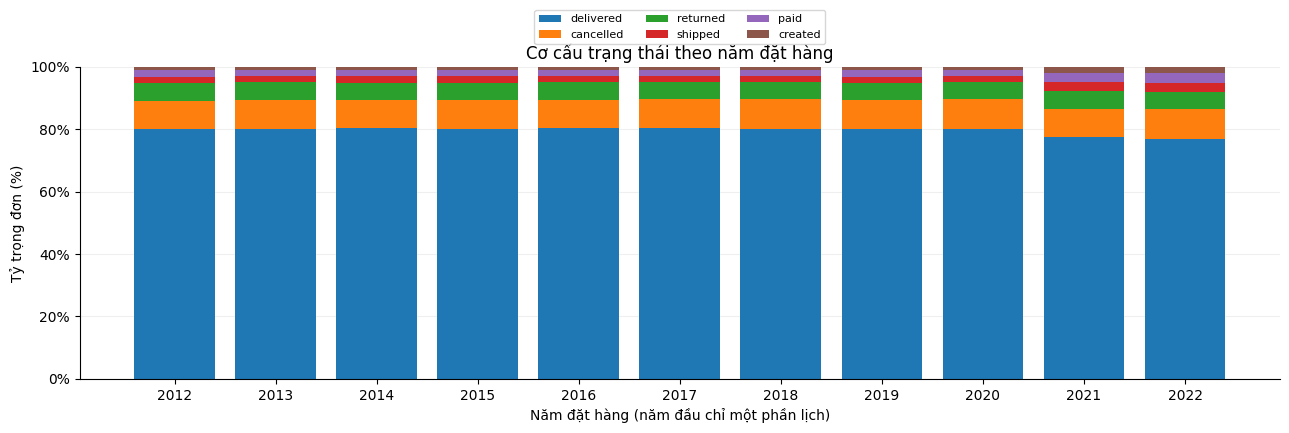

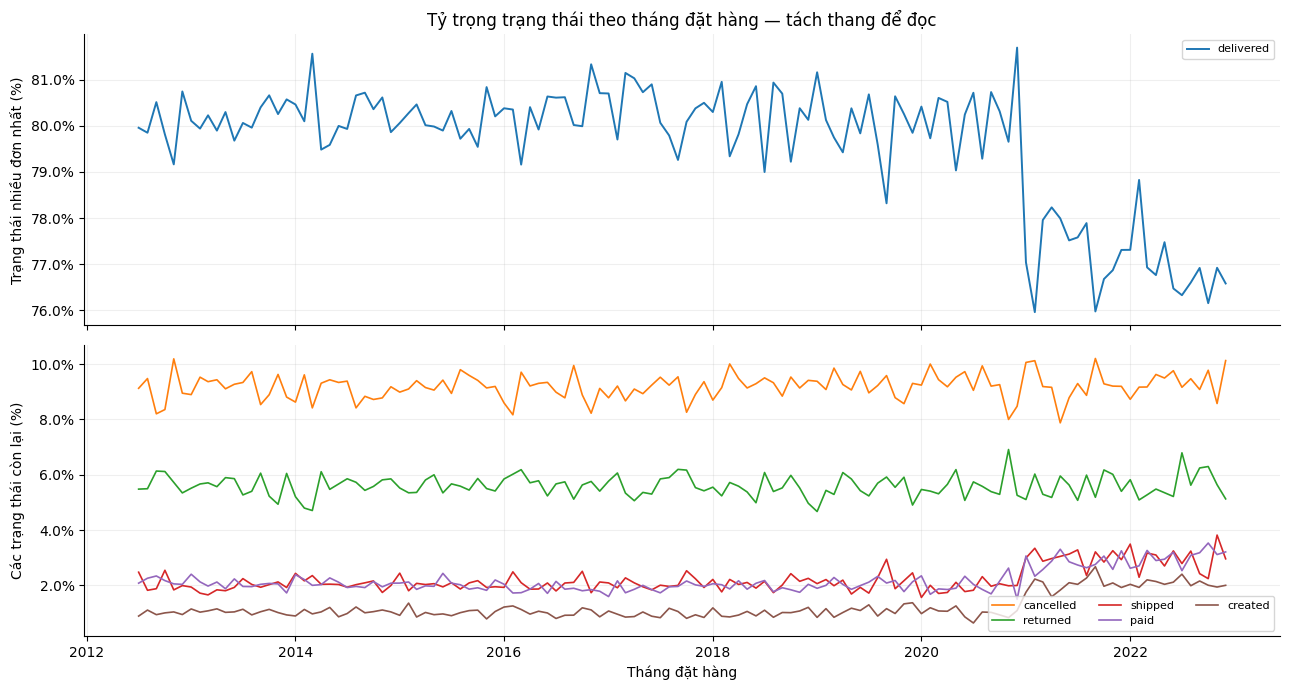

In [22]:
colors=plt.get_cmap('tab10').colors
status_colors={s:colors[i%len(colors)] for i,s in enumerate(status_order)}
fig,ax=plt.subplots(figsize=(13,4.5))
bottom=np.zeros(len(year_counts));x=np.arange(len(year_counts))
for s in status_order:
    values=year_shares[s].fillna(0).to_numpy()
    ax.bar(x,values,bottom=bottom,label=s,color=status_colors[s]);bottom+=values
ax.set(title='Cơ cấu trạng thái theo năm đặt hàng',xlabel='Năm đặt hàng (năm đầu chỉ một phần lịch)',ylabel='Tỷ trọng đơn (%)',
       xticks=x,xticklabels=year_counts.index.astype(str),ylim=(0,100))
ax.yaxis.set_major_formatter(PercentFormatter(100));ax.legend(ncol=3,loc='upper center',bbox_to_anchor=(.5,1.2),fontsize=8)
ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();display(fig);plt.close(fig)

month_dates=pd.to_datetime(month_counts.index+'-01')
fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True)
axes[0].plot(month_dates,month_shares[largest_status],color=status_colors[largest_status],label=largest_status,linewidth=1.4)
axes[0].set(title='Tỷ trọng trạng thái theo tháng đặt hàng — tách thang để đọc',ylabel='Trạng thái nhiều đơn nhất (%)')
for s in status_order:
    if s!=largest_status:axes[1].plot(month_dates,month_shares[s],label=s,color=status_colors[s],linewidth=1.2)
axes[1].set(ylabel='Các trạng thái còn lại (%)',xlabel='Tháng đặt hàng')
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(100));ax.grid(alpha=.2);ax.legend(ncol=3,fontsize=8)
axes[1].xaxis.set_major_locator(mdates.YearLocator(2));axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout();display(fig);plt.close(fig)


In [23]:
month_change=month_shares.diff()
month_pair_eligible=month_complete & month_complete.shift(1,fill_value=False)
month_change_records=[]
for i,m in enumerate(month_counts.index):
    if i==0 or not month_pair_eligible.loc[m]:continue
    prev=month_counts.index[i-1]
    for s in status_order:
        delta=float(month_change.at[m,s])
        if pd.isna(delta):continue
        month_change_records.append({'month':m,'previous':prev,'status':s,'orders':int(month_totals.loc[m]),
            'previous_orders':int(month_totals.loc[prev]),'status_orders':int(month_counts.at[m,s]),
            'previous_status_orders':int(month_counts.at[prev,s]),'share':float(month_shares.at[m,s]),
            'previous_share':float(month_shares.at[prev,s]),'delta_pp':delta,'abs_delta_pp':abs(delta),
            'small_current_or_previous':min(month_totals.loc[m],month_totals.loc[prev])<SMALL_MONTH_N})
month_changes=pd.DataFrame(month_change_records).sort_values(['abs_delta_pp','month','status'],ascending=[False,True,True],kind='stable')
top_month_changes=month_changes.head(10)
display(Markdown('**10 biến động đpt tháng lớn nhất theo trị tuyệt đối; đồng hạng theo tháng rồi nhãn chuỗi:**'))
with pd.option_context('display.max_columns',None):
    display(pd.DataFrame([{'Tháng trước → hiện tại':r.previous+' → '+r.month,'Trạng thái':r.status,
        'N đơn trước':r.previous_orders,'N đơn hiện tại':r.orders,
        'Đơn trạng thái trước':r.previous_status_orders,'Đơn trạng thái hiện tại':r.status_orders,
        '% trước':fmt(r.previous_share,2),'% hiện tại':fmt(r.share,2),'Thay đổi (đpt)':fmt(r.delta_pp,2),
        'Có kỳ N<2.000':r.small_current_or_previous} for r in top_month_changes.itertuples()]))
full_years=year_counts.index[year_complete.reindex(year_counts.index)]
comparison_years=list(full_years[-3:])
year_evidence='; '.join(f'{y}: {fmt(year_counts.at[y,largest_status])}/{fmt(year_totals.loc[y])} đơn '
    f'({fmt(year_shares.at[y,largest_status],2)}%)' for y in comparison_years)
latest_year=int(year_counts.index[-1])
review_labels=[s for s in ['created','paid','shipped'] if s in status_order]
review_evidence='; '.join(f'{s}: {fmt(year_counts.at[latest_year,s])} đơn ({fmt(year_shares.at[latest_year,s],2)}%)' for s in review_labels)
peak=top_month_changes.iloc[0]
display(Markdown(f'**Quan sát:** tỷ trọng **{largest_status}** ở các năm đủ lịch cuối kỳ: **{year_evidence}**. '
    f'Năm {latest_year}, các nhãn cần xác minh thêm gồm **{review_evidence}**. '
    f'Biến động tháng lớn nhất là **{peak["previous"]} → {peak["month"]}, {peak["status"]}: {fmt(peak["delta_pp"],2)} đpt**, '
    f'với **{fmt(peak["previous_orders"])} → {fmt(peak["orders"])} đơn** làm mẫu số. '
    f'Có **{fmt(int(month_totals.lt(SMALL_MONTH_N).sum()))} tháng** dưới ngưỡng mô tả {fmt(SMALL_MONTH_N)} đơn. '
    '**Ý nghĩa:** cơ cấu trạng thái thay đổi theo kỳ đặt hàng, nên so kết quả NV01/NV02 giữa các kỳ cần đọc cả trạng thái và quy mô. '
    '**Giới hạn:** đây chưa phải tỷ lệ chuyển trạng thái hay số sự kiện giao/hủy/trả xảy ra trong kỳ. '
    'Các nhãn cuối dữ liệu có thể chịu giới hạn quan sát; chưa xác minh nguyên nhân và không chỉ dựa tên nhãn để coi quy trình đã/ chưa hoàn tất. '
    '**Câu hỏi tiếp:** lịch sử sự kiện, thời điểm trích xuất hoặc chính sách nhãn có thay đổi theo kỳ không?'))


**10 biến động đpt tháng lớn nhất theo trị tuyệt đối; đồng hạng theo tháng rồi nhãn chuỗi:**

,Tháng trước → hiện tại,Trạng thái,N đơn trước,N đơn hiện tại,Đơn trạng thái trước,Đơn trạng thái hiện tại,% trước,% hiện tại,Thay đổi (đpt),Có kỳ N<2.000
0,2020-12 → 2021-01,delivered,2207,1372,1803,1057,"81,69","77,04","-4,65",True
1,2019-09 → 2019-10,delivered,3026,2345,2370,1891,"78,32","80,64","2,32",False
2,2014-03 → 2014-04,delivered,7653,9627,6242,7652,"81,56","79,48","-2,08",False
3,2020-11 → 2020-12,delivered,1563,2207,1245,1803,"79,65","81,69","2,04",True
4,2021-02 → 2021-03,delivered,1976,4006,1501,3123,"75,96","77,96","2,00",True
5,2018-07 → 2018-08,delivered,7452,6510,5887,5269,"79,00","80,94","1,94",False
6,2021-08 → 2021-09,delivered,3225,2431,2512,1847,"77,89","75,98","-1,91",False
7,2022-02 → 2022-03,delivered,2182,4231,1720,3255,"78,83","76,93","-1,89",False
8,2018-06 → 2018-07,delivered,10851,7452,8774,5887,"80,86","79,00","-1,86",False
9,2012-10 → 2012-11,cancelled,4285,4142,358,422,"8,35","10,19","1,83",False


**Quan sát:** tỷ trọng **delivered** ở các năm đủ lịch cuối kỳ: **2020: 27.975/34.881 đơn (80,20%); 2021: 26.741/34.525 đơn (77,45%); 2022: 27.688/36.004 đơn (76,90%)**. Năm 2022, các nhãn cần xác minh thêm gồm **created: 755 đơn (2,10%); paid: 1.090 đơn (3,03%); shipped: 1.065 đơn (2,96%)**. Biến động tháng lớn nhất là **2020-12 → 2021-01, delivered: -4,65 đpt**, với **2.207 → 1.372 đơn** làm mẫu số. Có **9 tháng** dưới ngưỡng mô tả 2.000 đơn. **Ý nghĩa:** cơ cấu trạng thái thay đổi theo kỳ đặt hàng, nên so kết quả NV01/NV02 giữa các kỳ cần đọc cả trạng thái và quy mô. **Giới hạn:** đây chưa phải tỷ lệ chuyển trạng thái hay số sự kiện giao/hủy/trả xảy ra trong kỳ. Các nhãn cuối dữ liệu có thể chịu giới hạn quan sát; chưa xác minh nguyên nhân và không chỉ dựa tên nhãn để coi quy trình đã/ chưa hoàn tất. **Câu hỏi tiếp:** lịch sử sự kiện, thời điểm trích xuất hoặc chính sách nhãn có thay đổi theo kỳ không?

### NV03.1.3 — Giá trị đơn theo trạng thái

Tính Gross/Discount ở cấp dòng rồi cộng theo order_id; Payment cũng cộng theo order_id riêng, sau đó hai JOIN one_to_one về orders.
Mọi đơn và dòng con phải được bảo toàn. Đối chiếu **Payment − Net**: khớp chính xác nếu 0,
khác 0 nhưng trong dung sai nếu $0<|d|\le0,05$, vượt dung sai nếu $|d|>0,05$.

Theo mỗi trạng thái, báo tổng Gross/Discount/Net, tỷ trọng Net, mean/median Net **trên đơn của trạng thái đó**,
tỷ lệ giảm giá = tổng Discount / tổng Gross khi Gross ≠0. Đây là tỷ lệ gộp, không phải mean tỷ lệ từng dòng.
Net chưa trừ refund; cancelled/returned vẫn có thể có giá trị ghi trong dữ liệu.
V03 cảnh báo bất thường Refund–Payment, nên không tự điều chỉnh tiền hoặc kết luận thực thu ở bước này.


In [24]:
def build_order_ledger(order_keys,line_items,payment_rows):
    assert order_keys.order_id.notna().all() and order_keys.order_id.is_unique
    assert set(line_items.order_id)==set(payment_rows.order_id)==set(order_keys.order_id)
    assert line_items[['quantity','unit_price','discount_amount']].notna().all().all()
    assert payment_rows.payment_value.notna().all()
    lines=line_items[['order_id','quantity','unit_price','discount_amount']].copy()
    lines['gross']=lines.quantity*lines.unit_price
    lines['discount']=lines.discount_amount
    line_totals=lines.groupby('order_id',sort=False).agg(gross=('gross','sum'),discount=('discount','sum'),item_rows=('order_id','size'))
    pay_totals=payment_rows.groupby('order_id',sort=False).agg(payment=('payment_value','sum'),payment_rows=('order_id','size'))
    ledger=order_keys.merge(line_totals,on='order_id',how='left',validate='one_to_one',sort=False)
    ledger=ledger.merge(pay_totals,on='order_id',how='left',validate='one_to_one',sort=False)
    assert len(ledger)==len(order_keys) and ledger.order_id.is_unique
    assert int(ledger.item_rows.sum())==len(line_items) and int(ledger.payment_rows.sum())==len(payment_rows)
    ledger['net']=ledger.gross-ledger.discount
    ledger['payment_difference']=ledger.payment-ledger.net
    return ledger
ledger=build_order_ledger(orders[['order_id','customer_id','order_status','date','year','month']],items,payments)
from datathon.preprocessing.foundation import exact_sum as gd2_exact_sum
totals={f:gd2_exact_sum(ledger[f]) for f in ['gross','discount','net','payment']}
comparison_table=pd.DataFrame([{'Chỉ tiêu':f,'Tính từ CSV (ĐVT)':fmt(totals[f],2),
    'V02 (ĐVT)':fmt(v02['metrics'][f],2),'Sai lệch (ĐVT)':fmt(totals[f]-Decimal(str(v02['metrics'][f])),2)}
    for f in totals])
display(comparison_table)
payment_difference=ledger.payment_difference
payment_comparison=pd.DataFrame([{'Số đơn':len(ledger),'Khớp chính xác':int(payment_difference.eq(0).sum()),
    'Sai lệch khác 0':int(payment_difference.ne(0).sum()),
    'Khác 0 nhưng ≤0,05':int((payment_difference.ne(0)&payment_difference.abs().le(TOL)).sum()),
    'Vượt 0,05':int(payment_difference.abs().gt(TOL).sum()),'Max |sai lệch| ĐVT':fmt(payment_difference.abs().max(),2)}])
display(payment_comparison)
derived_quality=pd.DataFrame([{'Giá trị cấp đơn':f,'NULL':int(ledger[f].isna().sum()),
    'Không hữu hạn':sum(not v.is_finite() for v in ledger[f].dropna()),
    'Âm':int(ledger[f].lt(0).sum()),'Bằng 0':int(ledger[f].eq(0).sum())} for f in ['gross','discount','net','payment']])
display(derived_quality)
join_preservation=pd.DataFrame([{'Đơn trước JOIN':len(orders),'Dòng sau JOIN':len(ledger),'Order_id duy nhất':ledger.order_id.nunique(),
    'Tổng dòng hàng đối chiếu':int(ledger.item_rows.sum()),'Tổng dòng Payment đối chiếu':int(ledger.payment_rows.sum())}])
display(join_preservation)


,Chỉ tiêu,Tính từ CSV (ĐVT),V02 (ĐVT),Sai lệch (ĐVT)
0,gross,"16.430.476.585,53","16.430.476.585,53","0,00"
1,discount,"749.607.320,10","749.607.320,10","0,00"
2,net,"15.680.869.265,43","15.680.869.265,43","0,00"
3,payment,"15.680.869.265,43","15.680.869.265,43","0,00"


,Số đơn,Khớp chính xác,Sai lệch khác 0,"Khác 0 nhưng ≤0,05","Vượt 0,05",Max |sai lệch| ĐVT
0,646945,646945,0,0,0,"0,00"


,Giá trị cấp đơn,NULL,Không hữu hạn,Âm,Bằng 0
0,gross,0,0,0,0
1,discount,0,0,0,398703
2,net,0,0,0,0
3,payment,0,0,0,0


,Đơn trước JOIN,Dòng sau JOIN,Order_id duy nhất,Tổng dòng hàng đối chiếu,Tổng dòng Payment đối chiếu
0,646945,646945,646945,714669,646945


In [25]:
money_status_rows=[]
for s in status_order:
    group=ledger.loc[ledger.order_status.eq(s)]
    values={f:sum(group[f],ZERO) for f in ['gross','discount','net']}
    money_status_rows.append({'status':s,'orders':len(group),'order_share':pct(len(group),n_orders),**values,
        'net_share':pct(values['net'],totals['net']),'mean_net':divide(values['net'],len(group)),
        'median_net':statistics.median(group.net) if len(group) else None,
        'discount_rate':pct(values['discount'],values['gross']),
        'share_gap_pp':pct(values['net'],totals['net'])-pct(len(group),n_orders)})
money_status=pd.DataFrame(money_status_rows).set_index('status')
money_status_display=pd.DataFrame([{'Trạng thái':s,'Số đơn':int(r.orders),'% đơn':fpct(r.order_share),
    'Gross (triệu ĐVT)':fmt(r.gross/1000000,2),'Discount (triệu ĐVT)':fmt(r.discount/1000000,2),
    'Net (triệu ĐVT)':fmt(r.net/1000000,2),'% Net':fpct(r.net_share),
    'Mean Net/đơn (ĐVT)':fmt(r.mean_net,2),'Median Net/đơn (ĐVT)':fmt(r.median_net,2),
    'Discount/Gross':fpct(r.discount_rate)} for s,r in money_status.iterrows()])
with pd.option_context('display.max_columns',None):display(money_status_display)
v02_status_reference={r['order_status']:r for r in v02['reports']['statuses']['records']}
money_reference=pd.DataFrame([{'Trạng thái':s,'Đơn CSV − V02':int(r.orders)-int(v02_status_reference[s]['orders']),
    'Gross CSV − V02 (ĐVT)':fmt(r.gross-Decimal(str(v02_status_reference[s]['gross'])),2),
    'Discount CSV − V02 (ĐVT)':fmt(r.discount-Decimal(str(v02_status_reference[s]['discount'])),2),
    'Net CSV − Payment V02 (ĐVT)':fmt(r.net-Decimal(str(v02_status_reference[s]['payment'])),2)}
    for s,r in money_status.iterrows()])
with pd.option_context('display.max_columns',None):display(money_reference)
delivered_net=money_status.at['delivered','net'] if 'delivered' in money_status.index else None
display(pd.DataFrame([{'Chỉ tiêu':'Net delivered','CSV (ĐVT)':fmt(delivered_net,2),
    'NV02.3 output (ĐVT)':fmt(nv02_delivered_net,2),'Sai lệch (ĐVT)':fmt(delivered_net-nv02_delivered_net,2)}]))


,Trạng thái,Số đơn,% đơn,Gross (triệu ĐVT),Discount (triệu ĐVT),Net (triệu ĐVT),% Net,Mean Net/đơn (ĐVT),Median Net/đơn (ĐVT),Discount/Gross
0,delivered,516716,"79,87%","13.117,09","598,92","12.518,18","79,83%","24.226,41","17.242,60","4,57%"
1,cancelled,59462,"9,19%","1.515,89","68,88","1.447,01","9,23%","24.335,10","17.233,22","4,54%"
2,returned,36142,"5,59%","907,54","41,60","865,94","5,52%","23.959,35","16.851,87","4,58%"
3,shipped,13773,"2,13%","353,38","16,10","337,28","2,15%","24.488,41","17.470,72","4,56%"
4,paid,13577,"2,10%","345,92","15,30","330,63","2,11%","24.352,00","17.150,76","4,42%"
5,created,7275,"1,12%","190,65","8,82","181,84","1,16%","24.994,50","17.758,03","4,62%"


,Trạng thái,Đơn CSV − V02,Gross CSV − V02 (ĐVT),Discount CSV − V02 (ĐVT),Net CSV − Payment V02 (ĐVT)
0,delivered,0,"0,00","0,00","0,00"
1,cancelled,0,"0,00","0,00","0,00"
2,returned,0,"0,00","0,00","0,00"
3,shipped,0,"0,00","0,00","0,00"
4,paid,0,"0,00","0,00","0,00"
5,created,0,"0,00","0,00","0,00"


,Chỉ tiêu,CSV (ĐVT),NV02.3 output (ĐVT),Sai lệch (ĐVT)
0,Net delivered,"12.518.175.957,20","12.518.175.957,20","0,00"


In [26]:
recorded_other=[s for s in ['cancelled','returned'] if s in money_status.index]
money_evidence='; '.join(f'{s}: {fmt(money_status.at[s,"orders"])} đơn, Net {fmt(money_status.at[s,"net"],2)} ĐVT' for s in recorded_other)
display(Markdown(f'**Quan sát:** Gross **{fmt(totals["gross"],2)}**, Discount **{fmt(totals["discount"],2)}**, '
    f'Net **{fmt(totals["net"],2)} ĐVT**, đối chiếu V02. '
    f'Có **{fmt(int(payment_difference.eq(0).sum()))}/{fmt(n_orders)} đơn** khớp Payment = Net chính xác. '
    f'**{money_evidence}**. '
    '**Ý nghĩa:** tên trạng thái không xóa giá trị đơn đã ghi; phạm vi tiền của NV01/NV02 phải được đọc cùng định nghĩa trước/sau giảm giá và trạng thái. '
    f'**Giới hạn V03:** báo cáo trước ghi nhận **{fmt(v03["metrics"]["refund_orders_above_payment"])} đơn Refund vượt Payment**; '
    'Net chưa trừ hoàn tiền, Payment chưa được xác minh là thực nhận; không tự trừ refund để tính thực thu. '
    '**Câu hỏi tiếp:** quy tắc ghi nhận và đối soát của cancelled/returned/delivered là gì? Chi tiết hoàn tiền dành cho bước sau, chưa phân tích tại đây.'))


**Quan sát:** Gross **16.430.476.585,53**, Discount **749.607.320,10**, Net **15.680.869.265,43 ĐVT**, đối chiếu V02. Có **646.945/646.945 đơn** khớp Payment = Net chính xác. **cancelled: 59.462 đơn, Net 1.447.013.637,43 ĐVT; returned: 36.142 đơn, Net 865.938.715,59 ĐVT**. **Ý nghĩa:** tên trạng thái không xóa giá trị đơn đã ghi; phạm vi tiền của NV01/NV02 phải được đọc cùng định nghĩa trước/sau giảm giá và trạng thái. **Giới hạn V03:** báo cáo trước ghi nhận **3.640 đơn Refund vượt Payment**; Net chưa trừ hoàn tiền, Payment chưa được xác minh là thực nhận; không tự trừ refund để tính thực thu. **Câu hỏi tiếp:** quy tắc ghi nhận và đối soát của cancelled/returned/delivered là gì? Chi tiết hoàn tiền dành cho bước sau, chưa phân tích tại đây.

### NV03.1.4 — Tỷ trọng số đơn, tỷ trọng Net và giá trị mỗi đơn

So hai tỷ trọng trên cùng trạng thái, cùng toàn kỳ: chênh lệch = % Net − % số đơn, đơn vị đpt.
Nếu tổng Net dương, chênh lệch này đi cùng việc mean Net trạng thái cao/thấp hơn mean toàn kỳ theo định nghĩa,
chưa cho biết trạng thái gây ra giá trị tiền. Đọc median và tỷ lệ giảm giá gộp để tránh chỉ dùng mean.
Đồng hạng xếp theo nhãn chuỗi; không bỏ ngoại lệ hoặc tự diễn giải delivered là tỷ lệ hoàn tất đã xác minh.


,Trạng thái,N đơn,% đơn,% Net,%Net − %đơn (đpt),Mean Net/đơn (ĐVT),Median Net/đơn (ĐVT),Discount/Gross
0,delivered,516716,"79,87%","79,83%","-0,039","24.226,41","17.242,60","4,57%"
1,cancelled,59462,"9,19%","9,23%","0,037","24.335,10","17.233,22","4,54%"
2,returned,36142,"5,59%","5,52%","-0,064","23.959,35","16.851,87","4,58%"
3,shipped,13773,"2,13%","2,15%","0,022","24.488,41","17.470,72","4,56%"
4,paid,13577,"2,10%","2,11%","0,010","24.352,00","17.150,76","4,42%"
5,created,7275,"1,12%","1,16%","0,035","24.994,50","17.758,03","4,62%"


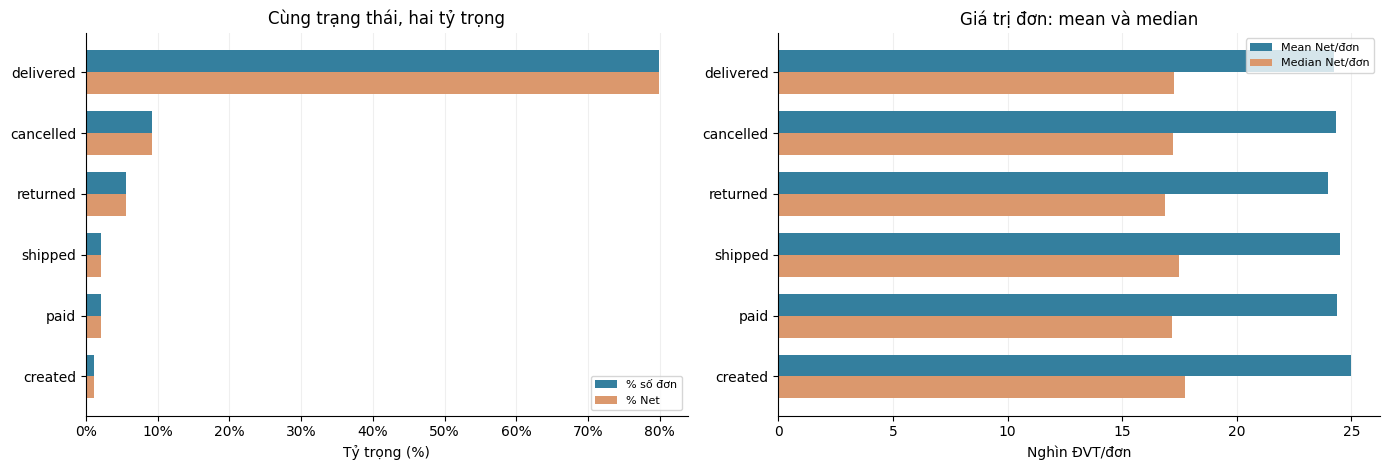

In [27]:
comparison_status=money_status.copy()
comparison_status['rank_orders']=comparison_status.orders.rank(method='min',ascending=False).astype(int)
comparison_status['rank_net']=comparison_status.net.rank(method='min',ascending=False).astype(int)
with pd.option_context('display.max_columns',None):
    display(pd.DataFrame([{'Trạng thái':s,'N đơn':int(r.orders),'% đơn':fpct(r.order_share),'% Net':fpct(r.net_share),
        '%Net − %đơn (đpt)':fmt(r.share_gap_pp,3),'Mean Net/đơn (ĐVT)':fmt(r.mean_net,2),
        'Median Net/đơn (ĐVT)':fmt(r.median_net,2),'Discount/Gross':fpct(r.discount_rate)}
        for s,r in comparison_status.iterrows()]))
fig,axes=plt.subplots(1,2,figsize=(14,4.8))
pos=np.arange(len(status_order))
axes[0].barh(pos-.18,[float(x) for x in money_status.order_share],height=.36,label='% số đơn',color='#347f9e')
axes[0].barh(pos+.18,[float(x) for x in money_status.net_share],height=.36,label='% Net',color='#db986d')
axes[0].set(title='Cùng trạng thái, hai tỷ trọng',xlabel='Tỷ trọng (%)',yticks=pos,yticklabels=status_order)
axes[0].xaxis.set_major_formatter(PercentFormatter(100))
axes[1].barh(pos-.18,[float(x/1000) for x in money_status.mean_net],height=.36,label='Mean Net/đơn',color='#347f9e')
axes[1].barh(pos+.18,[float(x/1000) for x in money_status.median_net],height=.36,label='Median Net/đơn',color='#db986d')
axes[1].set(title='Giá trị đơn: mean và median',xlabel='Nghìn ĐVT/đơn',yticks=pos,yticklabels=status_order)
for ax in axes:ax.invert_yaxis();ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True);ax.legend(fontsize=8)
fig.tight_layout();display(fig);plt.close(fig)


In [28]:
max_net_status=money_status.net.idxmax();max_mean_status=money_status.mean_net.idxmax();min_mean_status=money_status.mean_net.idxmin()
max_gap_status=money_status.share_gap_pp.abs().idxmax()
display(Markdown(f'**Quan sát:** **{largest_status}** dẫn số đơn; **{max_net_status}** dẫn tổng Net '
    f'(**{fpct(money_status.at[max_net_status,"net_share"])}**). '
    f'Mean Net/đơn nằm trong **{fmt(money_status.mean_net.min(),2)}–{fmt(money_status.mean_net.max(),2)} ĐVT**, '
    f'thấp nhất **{min_mean_status}**, cao nhất **{max_mean_status}**. '
    f'Ở **{max_gap_status}**, chênh % Net − % đơn là **{fmt(money_status.at[max_gap_status,"share_gap_pp"],3)} đpt**. '
    f'Discount/Gross giữa các trạng thái nằm trong **{fpct(money_status.discount_rate.min())}–{fpct(money_status.discount_rate.max())}**. '
    '**Ý nghĩa:** tổng tiền lớn có thể chủ yếu đi cùng quy mô đơn; cần tách số đơn khỏi giá trị mỗi đơn để nối với Frequency/Monetary ở NV02. '
    '**Giới hạn:** mean/median và tỷ lệ giảm giá mô tả phân bố, chưa chứng minh trạng thái gây giá trị cao/thấp hoặc tác động của giảm giá. '
    '**Câu hỏi tiếp:** cơ cấu sản phẩm, cửa sổ quan sát và chính sách trạng thái có liên quan đến khác biệt này không?'))


**Quan sát:** **delivered** dẫn số đơn; **delivered** dẫn tổng Net (**79,83%**). Mean Net/đơn nằm trong **23.959,35–24.994,50 ĐVT**, thấp nhất **returned**, cao nhất **created**. Ở **returned**, chênh % Net − % đơn là **-0,064 đpt**. Discount/Gross giữa các trạng thái nằm trong **4,42%–4,62%**. **Ý nghĩa:** tổng tiền lớn có thể chủ yếu đi cùng quy mô đơn; cần tách số đơn khỏi giá trị mỗi đơn để nối với Frequency/Monetary ở NV02. **Giới hạn:** mean/median và tỷ lệ giảm giá mô tả phân bố, chưa chứng minh trạng thái gây giá trị cao/thấp hoặc tác động của giảm giá. **Câu hỏi tiếp:** cơ cấu sản phẩm, cửa sổ quan sát và chính sách trạng thái có liên quan đến khác biệt này không?

### NV03.1.5 — Những gì dữ liệu cho phép nói về quy trình

Ba bảng đang dùng cung cấp ngày đặt, nhãn trạng thái, khách liên quan và giá trị ghi nhận; không cung cấp một nhật ký sự kiện.
Không mô tả created → paid → shipped → delivered là chuỗi đã quan sát ở mỗi đơn.
Đó chỉ có thể là quy trình giả định cần tài liệu hoặc dữ liệu xác minh.

Phân biệt **chưa có trong nguồn đang dùng** với **có thể có ở bảng khác nhưng chưa đối chiếu**:
ví dụ dự án có dữ liệu liên quan vận chuyển/hoàn trả, nhưng NV03.1 chưa JOIN hoặc dùng để suy thời điểm xử lý hay nguyên nhân.
Các câu hỏi dưới đây chỉ chuyển giao cho NV03.2–NV03.4, không triển khai phân tích mới.


In [29]:
process_limits=[
 {'Nội dung':'Ngày đặt và nhãn trạng thái','Đã quan sát':'order_date và một order_status/đơn',
  'Chưa có/chưa xác minh':'Thời điểm trích xuất, thời điểm nhãn được thiết lập, quy tắc nhãn',
  'Hệ quả':'Phân nhóm theo ngày đặt, không đếm sự kiện đổi trạng thái trong cùng kỳ','Câu hỏi tiếp':'NV03.2: có định nghĩa và lịch sử trạng thái đáng tin cậy không?'},
 {'Nội dung':'Lịch sử chuyển trạng thái','Đã quan sát':'Không có nhật ký chuyển trạng thái trong ba nguồn',
  'Chưa có/chưa xác minh':'Chuỗi trạng thái, thời gian giữa các bước, đường đi từng đơn',
  'Hệ quả':'Không tính tỷ lệ chuyển bước, thời gian xử lý hoặc dựng luồng đã quan sát','Câu hỏi tiếp':'NV03.2–NV03.4: có event log/mốc nghiệp vụ nào để đối chiếu?'},
 {'Nội dung':'Thanh toán và ghi nhận tiền','Đã quan sát':'payment_value đối chiếu Net theo đơn',
  'Chưa có/chưa xác minh':'Thời điểm thanh toán/quyết toán, doanh thu kế toán, tiền thực nhận',
  'Hệ quả':'Payment/Net không mặc định là thực thu; không tính thời gian đặt đến trả tiền','Câu hỏi tiếp':'NV03.3: chính sách ghi nhận và mốc thời gian thanh toán là gì?'},
 {'Nội dung':'Giao hàng/hoàn tất','Đã quan sát':'Các nhãn shipped/delivered nếu có trong nguồn',
  'Chưa có/chưa xác minh':'Mốc giao, nhận, hoàn tất và sự tương ứng giữa các bảng',
  'Hệ quả':'Không tính thời gian giao hàng hoặc coi tỷ trọng delivered là hiệu suất hoàn tất','Câu hỏi tiếp':'NV03.4: cần nguồn nào xác minh mốc giao và ý nghĩa hoàn tất?'},
 {'Nội dung':'Hủy và trả hàng','Đã quan sát':'Nhãn cancelled/returned và giá trị đơn vẫn được ghi',
  'Chưa có/chưa xác minh':'Nguyên nhân, ngày sự kiện, phạm vi hoàn tiền và chính sách ghi nhận',
  'Hệ quả':'Không coi giá trị bằng 0, không suy nguyên nhân hoặc tự trừ toàn bộ refund','Câu hỏi tiếp':'NV03.2–NV03.4: định nghĩa đối soát nào cần làm rõ; hoàn tiền chi tiết nối NV04?'},
 {'Nội dung':'Khách liên quan','Đã quan sát':'customer_id trong orders',
  'Chưa có/chưa xác minh':'Một mã có tương ứng một người thực tế và ý nghĩa trạng thái đối với quan hệ khách',
  'Hệ quả':'Đọc kết quả NV02 như hành vi trên mã khách và phạm vi đơn đã định nghĩa','Câu hỏi tiếp':'Có quy tắc định danh và liên kết tài khoản cần xác minh không?'}]
with pd.option_context('display.max_columns',None,'display.max_colwidth',None):display(pd.DataFrame(process_limits))
display(Markdown(f'''
**Kết luận trong phạm vi NV03.1.** Bộ dữ liệu có **{fmt(n_orders)} đơn** từ **{date_start:%d/%m/%Y}** đến
**{date_end:%d/%m/%Y}**; trạng thái **{largest_status}** chiếm phần lớn số đơn nhưng không đại diện cho toàn bộ đơn ghi nhận.
Cơ cấu theo kỳ đặt hàng có thay đổi, đặc biệt ở các năm cuối, trong khi chưa có nhật ký sự kiện để xác định cơ chế tạo thay đổi.
Năm/tháng đầu chỉ là một phần kỳ; cuối kỳ có thể chịu giới hạn quan sát nhưng đó chưa phải nguyên nhân đã xác minh.

Giá trị Gross/Discount/Net được bảo toàn sau tổng hợp cấp đơn và đối chiếu V02/NV02.
Sự khác nhau giữa tỷ trọng số đơn và tỷ trọng Net cần đọc cùng mean/median và tỷ lệ giảm giá.
Net của cancelled/returned/delivered là giá trị theo nhãn được ghi, chưa điều chỉnh hoàn tiền hoặc xác nhận quyết toán.
Vì vậy, các tổng doanh thu trước giảm giá ở NV01 và chỉ tiêu giá trị/tần suất ở NV02 cần giữ định nghĩa phạm vi trạng thái nhất quán.

NV03.1 xác lập nền mô tả và các yêu cầu dữ liệu cho nghiên cứu quy trình tiếp theo, chưa dựng được lịch sử xử lý từng đơn,
chưa đánh giá thời gian giao hàng, hiệu suất chuyển bước hoặc nguyên nhân hủy/trả.
Các câu hỏi được chuyển giao, không thực hiện NV03.2–NV03.5 hoặc mô hình trong notebook này.
'''))


,Nội dung,Đã quan sát,Chưa có/chưa xác minh,Hệ quả,Câu hỏi tiếp
0,Ngày đặt và nhãn trạng thái,order_date và một order_status/đơn,"Thời điểm trích xuất, thời điểm nhãn được thiết lập, quy tắc nhãn","Phân nhóm theo ngày đặt, không đếm sự kiện đổi trạng thái trong cùng kỳ",NV03.2: có định nghĩa và lịch sử trạng thái đáng tin cậy không?
1,Lịch sử chuyển trạng thái,Không có nhật ký chuyển trạng thái trong ba nguồn,"Chuỗi trạng thái, thời gian giữa các bước, đường đi từng đơn","Không tính tỷ lệ chuyển bước, thời gian xử lý hoặc dựng luồng đã quan sát",NV03.2–NV03.4: có event log/mốc nghiệp vụ nào để đối chiếu?
2,Thanh toán và ghi nhận tiền,payment_value đối chiếu Net theo đơn,"Thời điểm thanh toán/quyết toán, doanh thu kế toán, tiền thực nhận",Payment/Net không mặc định là thực thu; không tính thời gian đặt đến trả tiền,NV03.3: chính sách ghi nhận và mốc thời gian thanh toán là gì?
3,Giao hàng/hoàn tất,Các nhãn shipped/delivered nếu có trong nguồn,"Mốc giao, nhận, hoàn tất và sự tương ứng giữa các bảng",Không tính thời gian giao hàng hoặc coi tỷ trọng delivered là hiệu suất hoàn tất,NV03.4: cần nguồn nào xác minh mốc giao và ý nghĩa hoàn tất?
4,Hủy và trả hàng,Nhãn cancelled/returned và giá trị đơn vẫn được ghi,"Nguyên nhân, ngày sự kiện, phạm vi hoàn tiền và chính sách ghi nhận","Không coi giá trị bằng 0, không suy nguyên nhân hoặc tự trừ toàn bộ refund",NV03.2–NV03.4: định nghĩa đối soát nào cần làm rõ; hoàn tiền chi tiết nối NV04?
5,Khách liên quan,customer_id trong orders,Một mã có tương ứng một người thực tế và ý nghĩa trạng thái đối với quan hệ khách,Đọc kết quả NV02 như hành vi trên mã khách và phạm vi đơn đã định nghĩa,Có quy tắc định danh và liên kết tài khoản cần xác minh không?



**Kết luận trong phạm vi NV03.1.** Bộ dữ liệu có **646.945 đơn** từ **04/07/2012** đến
**31/12/2022**; trạng thái **delivered** chiếm phần lớn số đơn nhưng không đại diện cho toàn bộ đơn ghi nhận.
Cơ cấu theo kỳ đặt hàng có thay đổi, đặc biệt ở các năm cuối, trong khi chưa có nhật ký sự kiện để xác định cơ chế tạo thay đổi.
Năm/tháng đầu chỉ là một phần kỳ; cuối kỳ có thể chịu giới hạn quan sát nhưng đó chưa phải nguyên nhân đã xác minh.

Giá trị Gross/Discount/Net được bảo toàn sau tổng hợp cấp đơn và đối chiếu V02/NV02.
Sự khác nhau giữa tỷ trọng số đơn và tỷ trọng Net cần đọc cùng mean/median và tỷ lệ giảm giá.
Net của cancelled/returned/delivered là giá trị theo nhãn được ghi, chưa điều chỉnh hoàn tiền hoặc xác nhận quyết toán.
Vì vậy, các tổng doanh thu trước giảm giá ở NV01 và chỉ tiêu giá trị/tần suất ở NV02 cần giữ định nghĩa phạm vi trạng thái nhất quán.

NV03.1 xác lập nền mô tả và các yêu cầu dữ liệu cho nghiên cứu quy trình tiếp theo, chưa dựng được lịch sử xử lý từng đơn,
chưa đánh giá thời gian giao hàng, hiệu suất chuyển bước hoặc nguyên nhân hủy/trả.
Các câu hỏi được chuyển giao, không thực hiện NV03.2–NV03.5 hoặc mô hình trong notebook này.


### Kiểm chứng độc lập và bảo toàn dữ liệu

Tái đọc ba CSV bằng csv.DictReader, dựng ledger bằng dict/Decimal thay vì Pandas JOIN/groupby.
So **mọi order_id**, tiền từng đơn, số dòng con, số khách/ngày, số đơn trạng thái/năm/tháng và từng ô cơ cấu.
Mean/median tiền được đối chiếu với statistics trên các giá trị độc lập.
Kiểm tra tháng liên tục và ngày có đơn, gồm tháng 02 năm nhuận; kiểm tra kỳ đầu và cặp kỳ được phép so.

Ví dụ nhỏ có nhiều dòng hàng, nhiều Payment/đơn, hai đơn cùng khách, đơn cancelled vẫn có tiền, mã 0 đầu,
discount dòng và giá trị Net 0; thử khóa trùng, dòng con mồ côi và biên dung sai.
Số đếm/tổng tiền đối chiếu chính xác; mean/median tiền cho phép ≤10⁻¹⁸ ĐVT do phép chia Decimal,
tỷ lệ float biểu đồ so với phép tính độc lập trong sai số ≤10⁻¹⁰ điểm phần trăm.

Kiểm tra công thức không xác nhận nghiệp vụ quyết toán hoặc nguyên nhân. Phần phân nhóm chỉ dùng order_date;
không sử dụng ngày giả định giao/hủy/trả. Run All được thực hiện trên hai kernel mới nếu môi trường cho phép.


In [30]:
def csv_rows(path):
    with path.open(encoding='utf-8-sig',newline='') as stream:yield from csv.DictReader(stream)
native={}
native_customers=set();native_days=set()
native_status=Counter();native_year_status=Counter();native_month_status=Counter()
for row in csv_rows(PATHS['orders']):
    oid=row['order_id'];assert oid and oid not in native
    day=datetime.strptime(row['order_date'],'%Y-%m-%d').date()
    native[oid]={'customer':row['customer_id'],'status':row['order_status'],'date':day,
        'gross':ZERO,'discount':ZERO,'payment':ZERO,'item_rows':0,'payment_rows':0}
    native_customers.add(row['customer_id']);native_days.add(day)
    native_status[row['order_status']]+=1
    native_year_status[(day.year,row['order_status'])]+=1
    native_month_status[(day.strftime('%Y-%m'),row['order_status'])]+=1
for row in csv_rows(PATHS['order_items']):
    entry=native[row['order_id']]
    entry['gross']+=Decimal(row['quantity'])*Decimal(row['unit_price'])
    entry['discount']+=Decimal(row['discount_amount']);entry['item_rows']+=1
for row in csv_rows(PATHS['payments']):
    entry=native[row['order_id']]
    entry['payment']+=Decimal(row['payment_value']);entry['payment_rows']+=1
native_money=defaultdict(lambda:{'gross':ZERO,'discount':ZERO,'net':ZERO,'values':[]})
for entry in native.values():
    entry['net']=entry['gross']-entry['discount']
    target=native_money[entry['status']]
    for field in ['gross','discount','net']:target[field]+=entry[field]
    target['values'].append(entry['net'])
fixture_orders=pd.DataFrame([('01','A','delivered'),('2','A','cancelled'),('3','B','created')],
    columns=['order_id','customer_id','order_status'])
fixture_items=pd.DataFrame([('01','P',2,10,3),('01','P',1,20,2),('2','Q',3,5,0),('3','R',1,0,0)],
    columns=['order_id','product_id','quantity','unit_price','discount_amount'])
for field in ['quantity','unit_price','discount_amount']:fixture_items[field]=fixture_items[field].map(Decimal)
fixture_payments=pd.DataFrame([('01',10),('01',25),('2',15),('3',0)],columns=['order_id','payment_value'])
fixture_payments['payment_value']=fixture_payments.payment_value.map(Decimal)
fixture_ledger=build_order_ledger(fixture_orders,fixture_items,fixture_payments)
display(Markdown('**Ví dụ giả lập — không phải dữ liệu đơn thật:** 01 có hai dòng hàng và hai dòng Payment, '
    'Gross=40, Discount=5, Net=35; đơn cancelled 2 vẫn có Net=15; đơn 3 có Net=0 hợp lệ.'))
display(fixture_ledger[['order_id','customer_id','order_status','gross','discount','net','payment','item_rows','payment_rows']])


**Ví dụ giả lập — không phải dữ liệu đơn thật:** 01 có hai dòng hàng và hai dòng Payment, Gross=40, Discount=5, Net=35; đơn cancelled 2 vẫn có Net=15; đơn 3 có Net=0 hợp lệ.

,order_id,customer_id,order_status,gross,discount,net,payment,item_rows,payment_rows
0,01,A,delivered,40,5,35,35,2,2
1,2,A,cancelled,15,0,15,15,1,1
2,3,B,created,0,0,0,0,1,1


In [31]:
verification=[]
def check(name,condition):
    condition=bool(condition);verification.append({'Kiểm tra NV03.1':name,'Đạt':condition});assert condition,name
check('Header/kiểu mã, trường bắt buộc/NULL và ngày hợp lệ',
    all(list(frames[n].columns[:len(expected_columns[n])])==expected_columns[n] for n in frames)
    and orders.order_id.notna().all() and orders.order_id.is_unique and orders.date.notna().all()
    and str(orders.order_id.dtype).startswith('string'))
check('Trường số hữu hạn, không loại dòng; số dòng khớp V02',
    numeric_quality['NULL/không hợp lệ/không hữu hạn'].eq(0).all()
    and len(items)==v02['metrics']['order_items_rows'] and len(payments)==v02['metrics']['payments_rows'])
check('Tổng đơn khớp V02 và NV02.1 đã lưu, không gán mốc thành kết quả',
    n_orders==v02['metrics']['orders_rows']==sum(nv02_counts.values())==len(native))
check('Ngày đầu/cuối, số ngày và khách phân biệt khớp CSV/datetime độc lập',
    observed_days==len(native_days) and n_customers_with_orders==len(native_customers)
    and date_start.date()==min(native_days) and date_end.date()==max(native_days))
check('Từng trạng thái và số đơn khớp NV02.1 và CSV độc lập',
    status_counts.orders.to_dict()==dict(native_status)==nv02_counts
    and int(status_counts.orders.sum())==n_orders)
check('Tổng đơn từng năm/tháng và từng trạng thái bảo toàn toàn kỳ',
    int(year_totals.sum())==int(month_totals.sum())==n_orders
    and year_counts.sum().to_dict()==month_counts.sum().to_dict()==status_counts.orders.to_dict())
check('Mọi ô số đơn năm/tháng khớp Counter độc lập',
    all(int(year_counts.at[y,s])==native_year_status[(y,s)] for y in year_counts.index for s in status_order)
    and all(int(month_counts.at[m,s])==native_month_status[(m,s)] for m in month_counts.index for s in status_order))
check('Tháng liên tục, không mất/trùng kỳ; ngày có đơn khớp lịch trong phạm vi quan sát',
    month_counts.index.is_unique and list(month_counts.index)==list(pd.period_range(date_start.to_period('M'),date_end.to_period('M'),freq='M').astype(str))
    and observed_days==len(pd.date_range(date_start,date_end,freq='D'))
    and int(year_observed_days.sum())==int(month_observed_days.sum())==observed_days)
check('Số ngày từng tháng đúng nguồn độc lập, gồm tháng 02 năm nhuận',
    all(int(month_observed_days.loc[m])==sum(d.strftime('%Y-%m')==m for d in native_days) for m in month_counts.index)
    and all(month_observed_days.loc[str(pd.Period(f'{y}-02'))]==pd.Period(f'{y}-02').days_in_month
            for y in year_counts.index if f'{y}-02' in month_counts.index))
check('Năm/tháng đầu chỉ một phần kỳ; không so tổng như đủ lịch',
    not bool(year_complete.loc[date_start.year]) and not bool(month_complete.loc[date_start.strftime('%Y-%m')])
    and annual_display.loc[date_start.year,'Phạm vi lịch']=='Chỉ một phần kỳ'
    and year_share_change.loc[date_start.year].isna().all()
    and year_share_change.loc[date_start.year+1].isna().all())
ratio_ok=True
for counts,shares,totals_period in [(year_counts,year_shares,year_totals),(month_counts,month_shares,month_totals)]:
    ratio_ok &= shares.dropna().ge(0).all().all() and shares.dropna().le(100).all().all()
    ratio_ok &= all(math.isclose(float(shares.at[p,s]),100*int(counts.at[p,s])/int(totals_period.loc[p]),rel_tol=0,abs_tol=1e-10)
                    for p in counts.index for s in status_order if totals_period.loc[p]>0)
    ratio_ok &= all(math.isclose(float(shares.loc[p].sum()),100,rel_tol=0,abs_tol=1e-10) for p in counts.index if totals_period.loc[p]>0)
check('Tỷ trọng năm/tháng đúng mẫu số trong kỳ và miền 0–100',ratio_ok)
check('Tỷ trọng toàn kỳ nằm trong miền và cộng 100%',
    all(0<=x<=100 for x in status_counts.share_pct)
    and abs(sum(status_counts.share_pct,ZERO)-100)<=Decimal('1e-20'))
check('Thay đổi đpt năm đúng hiệu tỷ trọng và chỉ cặp đủ phạm vi',
    all((math.isclose(float(year_share_change.at[y,s]),float(year_shares.at[y,s]-year_shares.at[y-1,s]),abs_tol=1e-10)
        if bool(year_complete.loc[y] and year_complete.shift(1,fill_value=False).loc[y]) else pd.isna(year_share_change.at[y,s]))
        for y in year_counts.index for s in status_order))
native_month_change=[]
for i,m in enumerate(month_counts.index):
    if i==0 or not month_pair_eligible.loc[m]:continue
    prev=month_counts.index[i-1]
    for s in status_order:
        delta=100*native_month_status[(m,s)]/int(month_totals.loc[m])-100*native_month_status[(prev,s)]/int(month_totals.loc[prev])
        native_month_change.append((abs(delta),m,s,delta,prev))
native_month_change.sort(key=lambda t:(-t[0],t[1],t[2]))
check('Xếp hạng biến động tháng đúng trị tuyệt đối/đồng hạng và nguồn độc lập',
    [(r.month,r.status) for r in top_month_changes.itertuples()]==[(m,s) for a,m,s,d,p in native_month_change[:10]]
    and all(math.isclose(r.delta_pp,d,rel_tol=0,abs_tol=1e-10)
            for r,(a,m,s,d,p) in zip(top_month_changes.itertuples(),native_month_change[:10])))
check('Tháng nhỏ vẫn giữ, có N cạnh tỷ lệ; cờ ở bảng biến động đúng cả hai kỳ',
    len(monthly_display)==len(month_counts)
    and all(('N<2.000' in monthly_display.at[m,'Cờ quy mô'])==(month_totals.loc[m]<SMALL_MONTH_N) for m in month_counts.index)
    and all(r.small_current_or_previous==(min(r.orders,r.previous_orders)<SMALL_MONTH_N) for r in month_changes.itertuples()))
check('Quan hệ dòng con đầy đủ, không mồ côi hoặc NULL',
    key_links[['Mã NULL','Mồ côi','Đơn thiếu dòng con']].eq(0).all().all())
check('JOIN không nhân order_id hoặc dòng hàng/Payment',
    len(ledger)==n_orders and ledger.order_id.is_unique
    and int(ledger.item_rows.sum())==len(items) and int(ledger.payment_rows.sum())==len(payments))
check('Mọi đơn/tiền/số dòng con khớp dict/Decimal độc lập',
    all(all(getattr(r,f)==native[r.order_id][f] for f in ['gross','discount','net','payment','item_rows','payment_rows'])
        and r.customer_id==native[r.order_id]['customer'] and r.order_status==native[r.order_id]['status']
        and r.date.date()==native[r.order_id]['date'] for r in ledger.itertuples()))
check('Công thức Net, sai lệch Payment và tính hữu hạn đúng',
    ledger.net.eq(ledger.gross-ledger.discount).all()
    and ledger.payment_difference.eq(ledger.payment-ledger.net).all()
    and derived_quality[['NULL','Không hữu hạn']].eq(0).all().all())
check('Tổng Gross/Discount/Net/Payment khớp chính xác V02 và CSV độc lập',
    all(totals[f]==Decimal(str(v02['metrics'][f]))==sum((r[f] for r in native.values()),ZERO) for f in totals))
check('Tổng tiền từng trạng thái cộng đúng toàn kỳ, không cần dung sai cho bảo toàn',
    all(sum(money_status[f],ZERO)==totals[f] for f in ['gross','discount','net'])
    and int(money_status.orders.sum())==n_orders)
check('Tiền/từng trạng thái khớp V02 trong dung sai và dict độc lập',
    all(all(row[f]==native_money[s][f] and abs(row[f]-Decimal(str(v02_status_reference[s]['payment' if f=='net' else f])))<=TOL
        for f in ['gross','discount','net']) and row.orders==v02_status_reference[s]['orders'] for s,row in money_status.iterrows()))
check('Mean/median tiền theo trạng thái khớp statistics độc lập',
    all(abs(row.mean_net-statistics.mean(native_money[s]['values']))<=Decimal('1e-18')
        and row.median_net==statistics.median(native_money[s]['values']) for s,row in money_status.iterrows()))
check('AOV theo đơn, tỷ trọng Net, giảm giá và chênh tỷ trọng đúng mẫu số',
    all(row.mean_net==divide(row.net,row.orders) and row.order_share==pct(row.orders,n_orders)
        and row.net_share==pct(row.net,totals['net']) and row.discount_rate==pct(row.discount,row.gross)
        and row.share_gap_pp==row.net_share-row.order_share for s,row in money_status.iterrows()))
v02_order_comparison=next(r for r in v02['reports']['comparisons']['records'] if r['comparison']=='order_payment_vs_gross_minus_discount')
check('Khớp/sai lệch Payment–Net theo đơn đúng V02 và dung sai 0,05',
    int(payment_difference.eq(0).sum())==v02_order_comparison['exact_match_cases']
    and int(payment_difference.ne(0).sum())==v02_order_comparison['nonzero_difference_cases']
    and int(payment_difference.abs().gt(TOL).sum())==v02_order_comparison['over_tolerance_count']
    and payment_difference.abs().max()==v02_order_comparison['max_abs_difference'])
check('Net delivered khớp NV02.3 output đã lưu và V02',
    delivered_net==nv02_delivered_net==Decimal(str(v02_status_reference['delivered']['payment'])))
fixture_index=fixture_ledger.set_index('order_id')
check('Ví dụ nhiều dòng hàng/nhiều Payment không nhân tiền; discount không nhân quantity',
    (fixture_index.at['01','gross'],fixture_index.at['01','discount'],fixture_index.at['01','net'],fixture_index.at['01','payment'])==
    (Decimal(40),Decimal(5),Decimal(35),Decimal(35)) and fixture_index.at['01','item_rows']==2 and fixture_index.at['01','payment_rows']==2)
check('Ví dụ cancelled vẫn có Net, Net 0 và mã 0 đầu giữ hợp lệ',
    fixture_index.at['2','order_status']=='cancelled' and fixture_index.at['2','net']==15
    and fixture_index.at['3','net']==0 and set(fixture_index.index)=={'01','2','3'}
    and divide(ZERO,ZERO) is None)
fixture_rejections=[]
for case in ['duplicate_order','orphan_item','missing_payment']:
    fo,fi,fp=fixture_orders.copy(),fixture_items.copy(),fixture_payments.copy()
    if case=='duplicate_order':fo=pd.concat([fo,fo.iloc[[0]]],ignore_index=True)
    elif case=='orphan_item':fi.loc[0,'order_id']='unknown'
    else:fp=fp.loc[fp.order_id.ne('3')]
    blocked=False
    try:build_order_ledger(fo,fi,fp)
    except (AssertionError,pd.errors.MergeError):blocked=True
    fixture_rejections.append(blocked)
check('Ví dụ khóa trùng/dòng con mồ côi/thiếu Payment bị chặn',all(fixture_rejections))
check('Biên 0,05 gồm trong dung sai; >0,05 vượt; số không hữu hạn bị phát hiện',
    [abs(Decimal(x))>TOL for x in ['0','0.05','-0.05','0.0501','-0.0501']]==[False,False,False,True,True]
    and exact_decimal('NaN') is None and exact_decimal('Infinity') is None and exact_decimal('invalid') is None)
check('Phân nhóm chỉ từ order_date, không dùng ngày giả định đổi trạng thái',
    orders.year.eq(orders.date.dt.year).all() and orders.month.eq(orders.date.dt.to_period('M').astype(str)).all()
    and all(r['Chưa có/chưa xác minh'] and r['Hệ quả'] and r['Câu hỏi tiếp'] for r in process_limits))
check('SHA-256 mọi file ngoài notebook, gồm NV01/NV02/raw/V01–V09/untracked, không đổi',
    protected_snapshot()==protected_before)
with pd.option_context('display.max_rows',None,'display.max_colwidth',None):display(pd.DataFrame(verification))


,Kiểm tra NV03.1,Đạt
0,"Header/kiểu mã, trường bắt buộc/NULL và ngày hợp lệ",True
1,"Trường số hữu hạn, không loại dòng; số dòng khớp V02",True
2,"Tổng đơn khớp V02 và NV02.1 đã lưu, không gán mốc thành kết quả",True
3,"Ngày đầu/cuối, số ngày và khách phân biệt khớp CSV/datetime độc lập",True
4,Từng trạng thái và số đơn khớp NV02.1 và CSV độc lập,True
5,Tổng đơn từng năm/tháng và từng trạng thái bảo toàn toàn kỳ,True
6,Mọi ô số đơn năm/tháng khớp Counter độc lập,True
7,"Tháng liên tục, không mất/trùng kỳ; ngày có đơn khớp lịch trong phạm vi quan sát",True
8,"Số ngày từng tháng đúng nguồn độc lập, gồm tháng 02 năm nhuận",True
9,Năm/tháng đầu chỉ một phần kỳ; không so tổng như đủ lịch,True


In [32]:
assert all(r['Đạt'] for r in verification)
display(Markdown(f'''
**Hoàn thành chỉ NV03.1:** **{fmt(n_orders)} đơn**, **{len(status_counts)} trạng thái**,
**{len(year_counts)} năm đặt** (năm đầu một phần lịch), **{len(month_counts)} tháng đặt**.
Gross **{fmt(totals['gross'],2)}**, Discount **{fmt(totals['discount'],2)}**, Net **{fmt(totals['net'],2)} ĐVT**,
đối chiếu đúng V02 và Net delivered đúng NV02.3.
**{len(verification)}/{len(verification)} nhóm kiểm chứng đạt**;
**{len(protected_before)} file ngoài notebook** không đổi theo SHA-256.

Bằng chứng **Restart Kernel → Run All trên hai kernel mới** lưu trong output và metadata execution_validation.
Chưa suy lịch sử chuyển trạng thái, nguyên nhân, thời gian giao hàng hoặc thực thu; chưa triển khai NV03.2–NV03.5.
Không sửa dữ liệu, NV01/NV02/module V01–V09; không tạo báo cáo phụ, không stage/commit/push.
'''))



**Hoàn thành chỉ NV03.1:** **646.945 đơn**, **6 trạng thái**,
**11 năm đặt** (năm đầu một phần lịch), **126 tháng đặt**.
Gross **16.430.476.585,53**, Discount **749.607.320,10**, Net **15.680.869.265,43 ĐVT**,
đối chiếu đúng V02 và Net delivered đúng NV02.3.
**32/32 nhóm kiểm chứng đạt**;
**87 file ngoài notebook** không đổi theo SHA-256.

Bằng chứng **Restart Kernel → Run All trên hai kernel mới** lưu trong output và metadata execution_validation.
Chưa suy lịch sử chuyển trạng thái, nguyên nhân, thời gian giao hàng hoặc thực thu; chưa triển khai NV03.2–NV03.5.
Không sửa dữ liệu, NV01/NV02/module V01–V09; không tạo báo cáo phụ, không stage/commit/push.


## NV03.2 — Vận chuyển và chênh lệch ngày xử lý đơn

Chỉ bổ sung NV03.2 sau 24 ô NV03.1. Run All chạy lại phần cũ để kiểm tra liên tục; phần mới chỉ dùng orders và shipments,
không mở phân tích thanh toán/hoàn tiền/tồn kho.

**Mức xác minh:** khảo sát nguồn xác nhận ship_date/delivery_date là trường ngày ISO; kiểm tra dưới đây xác nhận định dạng và thứ tự số học.
Chưa tìm thấy tài liệu xác nhận mốc là **thực tế hay kế hoạch**, ship là bàn giao nào, delivery là nhận hàng/hoàn tất nào.
Vì vậy chỉ tính **chênh lệch ngày lịch của mốc ghi nhận**, chưa xác nhận thời gian giao thực tế, hiệu suất hay SLA.
Tên chuẩn bị/vận chuyển/đặt–giao là diễn giải ứng viên theo tên trường.

Phân biệt **dòng shipment**, **order_id** và **cặp ngày tính được**. Không có giờ, không gọi thời gian chính xác đến giờ;
không coi order_date là lúc thanh toán. Các ghi chú chưa tính vận chuyển ở NV03.1 phản ánh phạm vi phần trước.


In [33]:
SHIP_PATH=ROOT/'data/raw/shipments.csv'
ship_profile=json.loads(reference_path('reports/tables/gd1/profiles/shipments.json').read_text(encoding='utf-8'),parse_float=Decimal)
ship_source_hash=digest(SHIP_PATH)
assert ship_source_hash==ship_profile['source_sha256']
ship_raw=read_table(SHIP_PATH)
assert list(ship_raw.columns)==['order_id','ship_date','delivery_date','shipping_fee']
ship_inventory=pd.DataFrame([{'Trường':c,'Kiểu đọc':str(ship_raw[c].dtype),'NULL':int(ship_raw[c].isna().sum()),
    '% NULL/dòng':fpct(pct(int(ship_raw[c].isna().sum()),len(ship_raw))),
    'Chuỗi trắng':int(ship_raw[c].astype('string').str.fullmatch(r'\s*',na=False).sum()),
    'Phân biệt không NULL':int(ship_raw[c].nunique())} for c in ship_raw.columns])
display(ship_inventory)
ship_roles=pd.DataFrame([
 {'Trường/nhóm':'order_id','Có':'Có','Ý nghĩa/giới hạn':'Mã JOIN orders; khóa ứng viên trong file, chưa phải mã kiện vật lý'},
 {'Trường/nhóm':'ship_date','Có':'Có','Ý nghĩa/giới hạn':'Ngày ISO; ứng viên xuất/bàn giao theo tên; chưa xác minh actual/planned'},
 {'Trường/nhóm':'delivery_date','Có':'Có','Ý nghĩa/giới hạn':'Ngày ISO; ứng viên giao theo tên; chưa xác minh actual/planned/hoàn tất'},
 {'Trường/nhóm':'shipping_fee','Có':'Có','Ý nghĩa/giới hạn':'Chỉ kiểm tra chất lượng trường số; chưa rõ tiền tệ, thực thu/chi phí'},
 {'Trường/nhóm':'Mã shipment riêng, trạng thái shipment','Có':'Không','Ý nghĩa/giới hạn':'Không đếm kiện theo mã riêng hoặc lập bảng chéo hai trạng thái'},
 {'Trường/nhóm':'Nhà vận chuyển/phương thức giao/giờ/SLA','Có':'Không','Ý nghĩa/giới hạn':'Không đánh giá hãng, chính xác đến giờ hoặc trễ hạn'}])
with pd.option_context('display.max_colwidth',None):display(ship_roles)
ship_fee_exact=pd.read_csv(SHIP_PATH,usecols=['shipping_fee'],dtype='string',encoding='utf-8-sig').shipping_fee.map(exact_decimal)
ship_fee_quality=pd.DataFrame([{'Dòng':len(ship_raw),'Cột':len(ship_raw.columns),'order_id phân biệt':ship_raw.order_id.nunique(),
    'Trùng toàn bộ dư':int(ship_raw.duplicated().sum()),'Phí NULL/không hữu hạn/không hợp lệ':int(ship_fee_exact.isna().sum()),
    'Phí âm':int(ship_fee_exact.dropna().lt(0).sum()),'Phí 0':int(ship_fee_exact.dropna().eq(0).sum()),
    'Min phí nguồn':fmt(ship_fee_exact.dropna().min(),2),'Max phí nguồn':fmt(ship_fee_exact.dropna().max(),2)}])
with pd.option_context('display.max_columns',None):display(ship_fee_quality)
display(Markdown(f'**Quan sát:** {fmt(len(ship_raw))} dòng, {len(ship_raw.columns)} cột; giữ nguyên nguồn. '
    '**Ý nghĩa:** có mốc ngày bổ sung cho order_status nhưng không có nhật ký vận chuyển. '
    '**Giới hạn:** cú pháp/tên trường chưa xác nhận mốc thực tế. **Cần làm rõ:** định nghĩa mốc và ý nghĩa phí/tiền tệ.'))


,Trường,Kiểu đọc,NULL,% NULL/dòng,Chuỗi trắng,Phân biệt không NULL
0,order_id,string,0,"0,00%",0,566067
1,ship_date,object,0,"0,00%",0,3831
2,delivery_date,object,0,"0,00%",0,3831
3,shipping_fee,float64,0,"0,00%",0,1856


,Trường/nhóm,Có,Ý nghĩa/giới hạn
0,order_id,Có,"Mã JOIN orders; khóa ứng viên trong file, chưa phải mã kiện vật lý"
1,ship_date,Có,Ngày ISO; ứng viên xuất/bàn giao theo tên; chưa xác minh actual/planned
2,delivery_date,Có,Ngày ISO; ứng viên giao theo tên; chưa xác minh actual/planned/hoàn tất
3,shipping_fee,Có,"Chỉ kiểm tra chất lượng trường số; chưa rõ tiền tệ, thực thu/chi phí"
4,"Mã shipment riêng, trạng thái shipment",Không,Không đếm kiện theo mã riêng hoặc lập bảng chéo hai trạng thái
5,Nhà vận chuyển/phương thức giao/giờ/SLA,Không,"Không đánh giá hãng, chính xác đến giờ hoặc trễ hạn"


,Dòng,Cột,order_id phân biệt,Trùng toàn bộ dư,Phí NULL/không hữu hạn/không hợp lệ,Phí âm,Phí 0,Min phí nguồn,Max phí nguồn
0,566067,4,566067,0,0,0,805,"0,00","32,00"


**Quan sát:** 566.067 dòng, 4 cột; giữ nguyên nguồn. **Ý nghĩa:** có mốc ngày bổ sung cho order_status nhưng không có nhật ký vận chuyển. **Giới hạn:** cú pháp/tên trường chưa xác nhận mốc thực tế. **Cần làm rõ:** định nghĩa mốc và ý nghĩa phí/tiền tệ.

### NV03.2.1 — Quan hệ đơn–shipment

Kiểm tra khóa, mã mồ côi, dòng trùng và số dòng/đơn trước JOIN.
Cấp shipment dùng many_to_one về orders; cấp đơn chỉ ghép số đếm, giữ đúng một dòng/đơn và mọi đơn không shipment.

Với nhiều shipment, giữ mọi dòng để tính số học từng dòng; **không chọn first/last** hoặc mặc định min/max là hoàn tất đơn.
Chỉ gán khoảng ngày ở cấp đơn khi có đúng một dòng shipment. Thiếu shipment không chứng minh chưa giao.


,Chỉ tiêu,N,Đơn vị
0,Dòng shipment,566067,dòng
1,order_id phân biệt trong shipment,566067,đơn
2,Dòng mồ côi,0,dòng
3,Đơn có shipment,566067,đơn
4,Đơn không shipment,80878,đơn
5,Đơn đúng một dòng,566067,đơn
6,Đơn nhiều dòng,0,đơn
7,Dòng trùng toàn bộ dư,0,"dòng, không tự xóa"
8,Đơn sau JOIN bảng cấp đơn,646945,order_id duy nhất


,order_status,N đơn,Có shipment,Không shipment,% có/N nhóm,Dòng shipment,Dòng/N mọi đơn,Dòng/N có shipment,N nhiều dòng
0,cancelled,59462,0,59462,"0,00%",0,"0,000",—,0
1,created,7275,0,7275,"0,00%",0,"0,000",—,0
2,delivered,516716,516192,524,"99,90%",516192,"0,999","1,000",0
3,paid,13577,0,13577,"0,00%",0,"0,000",—,0
4,returned,36142,36113,29,"99,92%",36113,"0,999","1,000",0
5,shipped,13773,13762,11,"99,92%",13762,"0,999","1,000",0


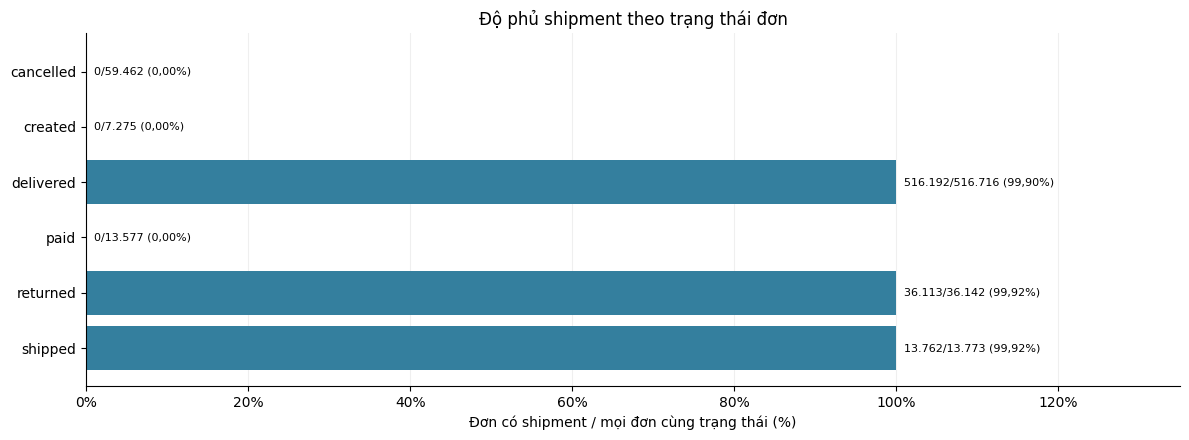

In [34]:
SHIP_METRICS={
 'prep_days':('ship_date_parsed','order_date_parsed','Δ ship−order'),
 'transit_days':('delivery_date_parsed','ship_date_parsed','Δ delivery−ship'),
 'total_days':('delivery_date_parsed','order_date_parsed','Δ delivery−order')}
def parse_ship_date(series):
    text=series.astype('string')
    return pd.to_datetime(text.where(text.str.fullmatch(r'\d{4}-\d{2}-\d{2}',na=False)),format='%Y-%m-%d',errors='coerce')
def build_shipping_views(order_source,shipment_source):
    assert order_source.order_id.notna().all() and order_source.order_id.is_unique
    assert shipment_source.order_id.notna().all()
    assert set(shipment_source.order_id)<=set(order_source.order_id), 'Mã shipment mồ côi'
    parent=order_source[['order_id','order_date','order_status']].copy()
    parent['order_date_parsed']=parse_ship_date(parent.order_date)
    assert parent.order_date_parsed.notna().all()
    parent['order_year']=parent.order_date_parsed.dt.year
    record=shipment_source.copy();record['source_row']=np.arange(1,len(record)+1)
    for f in ['ship_date','delivery_date']:record[f+'_parsed']=parse_ship_date(record[f])
    record=record.merge(parent,on='order_id',how='left',validate='many_to_one',sort=False)
    assert len(record)==len(shipment_source)
    for m,(end,start,label) in SHIP_METRICS.items():record[m]=(record[end]-record[start]).dt.days.astype('Int64')
    counts=record.groupby('order_id',sort=True).agg(n_shipments=('order_id','size'),
        n_ship_dates=('ship_date_parsed','count'),n_delivery_dates=('delivery_date_parsed','count'))
    view=parent.merge(counts,on='order_id',how='left',validate='one_to_one',sort=False)
    for f in ['n_shipments','n_ship_dates','n_delivery_dates']:view[f]=view[f].fillna(0).astype('int64')
    view['has_shipment']=view.n_shipments.gt(0)
    single_ids=set(view.loc[view.n_shipments.eq(1),'order_id'])
    single=record.loc[record.order_id.isin(single_ids),['order_id',*SHIP_METRICS]]
    assert single.order_id.is_unique
    view=view.merge(single,on='order_id',how='left',validate='one_to_one',sort=False)
    assert len(view)==len(parent) and view.order_id.is_unique
    return record,view
ship_orders_source=orders[['order_id','order_date','order_status']].copy()
ship_orphans=int((~ship_raw.order_id.isin(ship_orders_source.order_id)).sum())
ship_records,ship_orders=build_shipping_views(ship_orders_source,ship_raw)
ship_with=int(ship_orders.has_shipment.sum());ship_without=int((~ship_orders.has_shipment).sum())
ship_multi=int(ship_orders.n_shipments.gt(1).sum())
ship_overview=pd.DataFrame([
 {'Chỉ tiêu':'Dòng shipment','N':len(ship_raw),'Đơn vị':'dòng'},
 {'Chỉ tiêu':'order_id phân biệt trong shipment','N':ship_raw.order_id.nunique(),'Đơn vị':'đơn'},
 {'Chỉ tiêu':'Dòng mồ côi','N':ship_orphans,'Đơn vị':'dòng'},
 {'Chỉ tiêu':'Đơn có shipment','N':ship_with,'Đơn vị':'đơn'},
 {'Chỉ tiêu':'Đơn không shipment','N':ship_without,'Đơn vị':'đơn'},
 {'Chỉ tiêu':'Đơn đúng một dòng','N':int(ship_orders.n_shipments.eq(1).sum()),'Đơn vị':'đơn'},
 {'Chỉ tiêu':'Đơn nhiều dòng','N':ship_multi,'Đơn vị':'đơn'},
 {'Chỉ tiêu':'Dòng trùng toàn bộ dư','N':int(ship_raw.duplicated().sum()),'Đơn vị':'dòng, không tự xóa'},
 {'Chỉ tiêu':'Đơn sau JOIN bảng cấp đơn','N':len(ship_orders),'Đơn vị':'order_id duy nhất'}])
display(ship_overview)
ship_status=ship_orders.groupby('order_status',sort=True).agg(orders=('order_id','size'),with_shipment=('has_shipment','sum'),
    shipment_rows=('n_shipments','sum'),multi_orders=('n_shipments',lambda s:int(s.gt(1).sum())))
ship_status['without_shipment']=ship_status.orders-ship_status.with_shipment
ship_status['coverage_pct']=[pct(a,n) for a,n in zip(ship_status.with_shipment,ship_status.orders)]
with pd.option_context('display.max_columns',None):
    display(pd.DataFrame([{'order_status':s,'N đơn':int(r.orders),'Có shipment':int(r.with_shipment),
        'Không shipment':int(r.without_shipment),'% có/N nhóm':fpct(r.coverage_pct),'Dòng shipment':int(r.shipment_rows),
        'Dòng/N mọi đơn':fmt(divide(r.shipment_rows,r.orders),3),
        'Dòng/N có shipment':fmt(divide(r.shipment_rows,r.with_shipment),3),'N nhiều dòng':int(r.multi_orders)}
        for s,r in ship_status.iterrows()]))
fig,ax=plt.subplots(figsize=(12,4.5));pos=np.arange(len(ship_status))
ax.barh(pos,[float(x) for x in ship_status.coverage_pct],color='#347f9e')
for y,(s,r) in enumerate(ship_status.iterrows()):
    ax.text(min(float(r.coverage_pct)+1,101),y,f'{fmt(r.with_shipment)}/{fmt(r.orders)} ({fpct(r.coverage_pct)})',va='center',fontsize=8)
ax.set(yticks=pos,yticklabels=ship_status.index,xlabel='Đơn có shipment / mọi đơn cùng trạng thái (%)',
    title='Độ phủ shipment theo trạng thái đơn',xlim=(0,135))
ax.xaxis.set_major_formatter(PercentFormatter(100));ax.invert_yaxis();ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();display(fig);plt.close(fig)


In [35]:
ship_record_state=ship_records.groupby('order_status').agg(rows=('order_id','size'),delivery_date_present=('delivery_date_parsed','count'))
display(ship_record_state.rename(columns={'rows':'Dòng shipment','delivery_date_present':'Dòng có delivery_date đọc được'}))
display(Markdown(f'**Quan sát:** {fmt(ship_with)}/{fmt(len(ship_orders))} đơn có shipment '
    f'({fpct(pct(ship_with,len(ship_orders)))}); {fmt(ship_without)} đơn không có; {fmt(ship_multi)} đơn nhiều dòng. '
    '**Ý nghĩa:** mẫu shipment bổ sung mốc ngày nhưng không đại diện tự động mọi đơn. '
    '**Giới hạn:** không có shipping_status để lập bảng chéo; không thay bằng việc có delivery_date. '
    'Nhãn shipped/returned đi cùng delivery_date cần xác minh actual/planned và thời điểm cập nhật, chưa coi là lỗi. '
    '**Cần làm rõ:** nguồn lưu sự kiện hay kế hoạch; nguyên tắc định danh và ghi nhận thiếu dòng là gì?'))


,Dòng shipment,Dòng có delivery_date đọc được
order_status,,
delivered,516192,516192
returned,36113,36113
shipped,13762,13762


**Quan sát:** 566.067/646.945 đơn có shipment (87,50%); 80.878 đơn không có; 0 đơn nhiều dòng. **Ý nghĩa:** mẫu shipment bổ sung mốc ngày nhưng không đại diện tự động mọi đơn. **Giới hạn:** không có shipping_status để lập bảng chéo; không thay bằng việc có delivery_date. Nhãn shipped/returned đi cùng delivery_date cần xác minh actual/planned và thời điểm cập nhật, chưa coi là lỗi. **Cần làm rõ:** nguồn lưu sự kiện hay kế hoạch; nguyên tắc định danh và ghi nhận thiếu dòng là gì?

### NV03.2.3 — Mốc ngày, công thức và điều kiện

Ngày ISO YYYY-MM-DD được kiểm tra NULL, định dạng, min/max và thứ tự; không điền thiếu.
Δ ship−order, Δ delivery−ship, Δ delivery−order là các khoảng **ngày lịch ghi nhận**.
Cách gọi chuẩn bị/xuất, vận chuyển, đặt–giao chỉ là diễn giải ứng viên theo tên, chưa xác minh actual/planned.

Đủ điều kiện số học = hai ngày đọc được và order liên kết hợp lệ. Giữ cả âm/0/cực trị trong bảng gốc;
thống kê dùng mọi cặp đọc được, kể cả âm nếu có, và báo riêng số cặp thuận thứ tự.
Không coi đây là thời gian giao thực tế đã xác minh; nhiều shipment không cho thời gian hoàn tất toàn đơn.


,Mốc/phạm vi,N dòng,NULL gốc,Không NULL nhưng không đọc được,Đọc được,Min,Max
0,order_date (mọi đơn),646945,0,0,646945,2012-07-04,2022-12-31
1,ship_date (dòng shipment),566067,0,0,566067,2012-07-04,2022-12-29
2,delivery_date (dòng shipment),566067,0,0,566067,2012-07-06,2022-12-31


,Khoảng ngày ghi nhận,n,min,max,mean,median,std,p25,p75,p90,p95,p99,Thiếu cặp,Âm,Bằng 0,Thuận thứ tự
0,Δ ship−order,566067,"0,000","3,000","1,498","1,000","1,118","0,000","2,000","3,000","3,000","3,000",0,0,141993,566067
1,Δ delivery−ship,566067,"2,000","7,000","4,499","4,000","1,707","3,000","6,000","7,000","7,000","7,000",0,0,0,566067
2,Δ delivery−order,566067,"2,000","10,000","5,998","6,000","2,040","4,000","7,000","9,000","9,000","10,000",0,0,0,566067


,Δ ship−order,Δ delivery−ship,Δ delivery−order
Khoảng ngày mô tả — không phải SLA,,,
Âm,"0 (0,00%)","0 (0,00%)","0 (0,00%)"
0,"141.993 (25,08%)","0 (0,00%)","0 (0,00%)"
1,"141.245 (24,95%)","0 (0,00%)","0 (0,00%)"
2–3,"282.829 (49,96%)","188.640 (33,32%)","70.777 (12,50%)"
4–7,"0 (0,00%)","377.427 (66,68%)","354.240 (62,58%)"
>7,"0 (0,00%)","0 (0,00%)","141.050 (24,92%)"


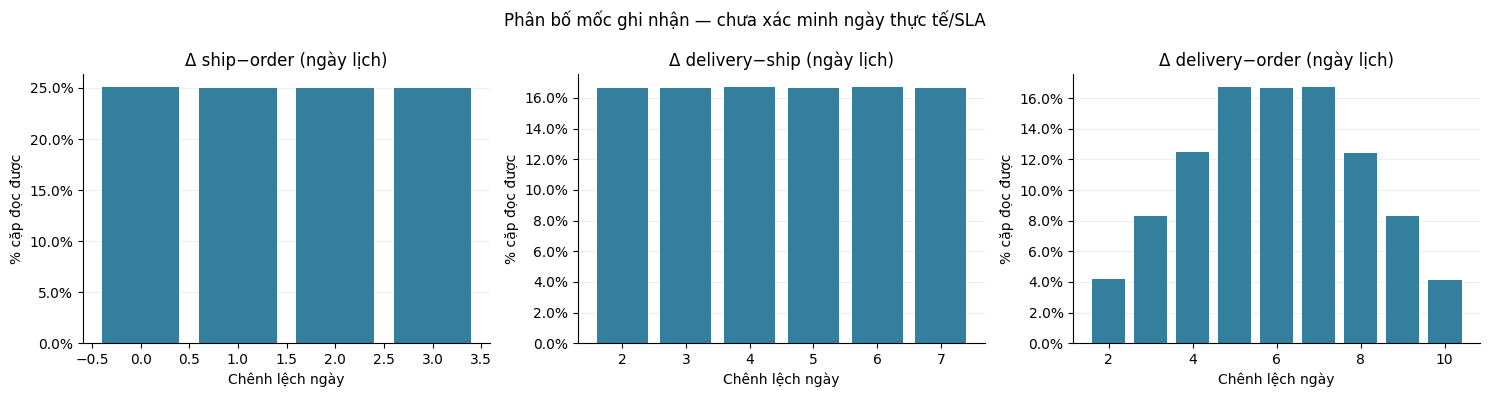

**Quan sát:** 566.067 cặp delivery−ship đủ điều kiện số học; mean 4,499, median 4,00 ngày. Có 141.993 cặp ship−order bằng 0: cùng ngày, không phải 0 giờ xử lý. **Ý nghĩa:** mô tả được khoảng ngày trong mẫu có shipment. **Giới hạn:** chưa xác nhận số đơn có thời gian giao thực tế do thiếu định nghĩa actual/planned, không có SLA để gọi trễ. **Cần làm rõ:** sự kiện, múi giờ và cam kết ở NV03.4.

In [36]:
ship_date_rows=[]
for name,text,parsed in [('order_date (mọi đơn)',ship_orders.order_date,ship_orders.order_date_parsed),
    ('ship_date (dòng shipment)',ship_records.ship_date,ship_records.ship_date_parsed),
    ('delivery_date (dòng shipment)',ship_records.delivery_date,ship_records.delivery_date_parsed)]:
    ship_date_rows.append({'Mốc/phạm vi':name,'N dòng':len(text),'NULL gốc':int(text.isna().sum()),
        'Không NULL nhưng không đọc được':int((text.notna()&parsed.isna()).sum()),
        'Đọc được':int(parsed.notna().sum()),'Min':parsed.min(),'Max':parsed.max()})
display(pd.DataFrame(ship_date_rows))
SHIP_QUANTILES=[.25,.75,.90,.95,.99]
def ship_describe(series):
    vals=pd.Series(series).dropna().astype(float)
    if len(vals)==0:return {'n':0,'min':None,'max':None,'mean':None,'median':None,'std':None,**{f'p{int(q*100)}':None for q in SHIP_QUANTILES}}
    return {'n':len(vals),'min':float(vals.min()),'max':float(vals.max()),'mean':float(vals.mean()),
        'median':float(vals.median()),'std':float(vals.std(ddof=1)) if len(vals)>1 else None,
        **{f'p{int(q*100)}':float(vals.quantile(q,interpolation='linear')) for q in SHIP_QUANTILES}}
ship_stats={};ship_bins={};ship_stat_rows=[]
SHIP_BIN_EDGES=[-float('inf'),-1,0,1,3,7,float('inf')]
SHIP_BIN_LABELS=['Âm','0','1','2–3','4–7','>7']
for m,(_,_,label) in SHIP_METRICS.items():
    series=ship_records[m];record=ship_describe(series);ship_stats[m]=record
    ship_stat_rows.append({'Khoảng ngày ghi nhận':label,**{k:(v if k=='n' else fmt(v,3)) for k,v in record.items()},
        'Thiếu cặp':int(series.isna().sum()),'Âm':int(series.lt(0).sum()),'Bằng 0':int(series.eq(0).sum()),
        'Thuận thứ tự':int(series.ge(0).sum())})
    ship_bins[m]=pd.cut(series.dropna().astype(int),bins=SHIP_BIN_EDGES,labels=SHIP_BIN_LABELS).value_counts(sort=False).reindex(SHIP_BIN_LABELS,fill_value=0)
with pd.option_context('display.max_columns',None):display(pd.DataFrame(ship_stat_rows))
ship_bin_display=pd.DataFrame(index=SHIP_BIN_LABELS)
ship_bin_display.index.name='Khoảng ngày mô tả — không phải SLA'
for m,(_,_,label) in SHIP_METRICS.items():
    ship_bin_display[label]=[f'{fmt(n)} ({fpct(pct(int(n),ship_stats[m]["n"]))})' for n in ship_bins[m]]
display(ship_bin_display)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,(m,(_,_,label)) in zip(axes,SHIP_METRICS.items()):
    counts=ship_records[m].dropna().astype(int).value_counts().sort_index()
    ax.bar(counts.index,[float(pct(int(n),int(counts.sum()))) for n in counts],color='#347f9e')
    ax.set(title=label+' (ngày lịch)',xlabel='Chênh lệch ngày',ylabel='% cặp đọc được')
    ax.yaxis.set_major_formatter(PercentFormatter(100));ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
fig.suptitle('Phân bố mốc ghi nhận — chưa xác minh ngày thực tế/SLA',fontsize=12)
fig.tight_layout();display(fig);plt.close(fig)
display(Markdown(f'**Quan sát:** {fmt(ship_stats["transit_days"]["n"])} cặp delivery−ship đủ điều kiện số học; '
    f'mean {fmt(ship_stats["transit_days"]["mean"],3)}, median {fmt(ship_stats["transit_days"]["median"],2)} ngày. '
    f'Có {fmt(int(ship_records.prep_days.eq(0).sum()))} cặp ship−order bằng 0: cùng ngày, không phải 0 giờ xử lý. '
    '**Ý nghĩa:** mô tả được khoảng ngày trong mẫu có shipment. **Giới hạn:** chưa xác nhận số đơn có thời gian giao thực tế '
    'do thiếu định nghĩa actual/planned, không có SLA để gọi trễ. **Cần làm rõ:** sự kiện, múi giờ và cam kết ở NV03.4.'))


### NV03.2.4 — Cực trị và đồng hạng

Chọn 5 ngắn nhất và 5 dài nhất mỗi khoảng có đủ cặp ngày, sau đó order_id chuỗi và STT dòng tăng dần.
Không mở rộng đồng hạng; báo số dòng cùng ngưỡng. STT dòng dữ liệu chỉ là chỉ số để đối soát, không phải shipment_id.
Không gọi dài là trễ hạn hoặc tự bỏ cực trị. Giá trị âm vẫn được giữ nếu có.


In [37]:
ship_extreme_rows=[];ship_extreme_ties=[]
for m,(_,_,label) in SHIP_METRICS.items():
    available=ship_records.loc[ship_records[m].notna()]
    for direction,ascending in [('Ngắn nhất',True),('Dài nhất',False)]:
        ranked=available.sort_values([m,'order_id','source_row'],ascending=[ascending,True,True],kind='stable').head(5)
        if len(ranked):
            threshold=ranked[m].iloc[-1]
            ship_extreme_ties.append({'Chỉ tiêu':label,'Hướng':direction,'Chọn':len(ranked),'Ngưỡng ngày':int(threshold),
                'Dòng cùng ngưỡng toàn mẫu':int(available[m].eq(threshold).sum())})
        for r in ranked.itertuples():
            ship_extreme_rows.append({'Chỉ tiêu':label,'Hướng':direction,'order_id':r.order_id,'STT dòng dữ liệu':r.source_row,
                'order_status':r.order_status,'order_date':r.order_date,'ship_date':r.ship_date,
                'delivery_date':r.delivery_date,'Chênh lệch ngày':int(getattr(r,m))})
with pd.option_context('display.max_rows',None,'display.max_columns',None):display(pd.DataFrame(ship_extreme_rows))
display(pd.DataFrame(ship_extreme_ties))
display(Markdown('**Nhận xét:** nhiều dòng có thể đồng hạng vì các khoảng ghi nhận là ngày nguyên. '
    'Chưa có căn cứ suy cơ chế tạo dữ liệu hay tự coi cực trị là lỗi; cần tài liệu và đối soát trước khi gọi nhanh/chậm/không đạt cam kết.'))


,Chỉ tiêu,Hướng,order_id,STT dòng dữ liệu,order_status,order_date,ship_date,delivery_date,Chênh lệch ngày
0,Δ ship−order,Ngắn nhất,100006,67952,delivered,2013-07-21,2013-07-21,2013-07-23,0
1,Δ ship−order,Ngắn nhất,100017,67959,delivered,2013-07-21,2013-07-21,2013-07-24,0
2,Δ ship−order,Ngắn nhất,100019,67960,delivered,2013-07-25,2013-07-25,2013-07-29,0
3,Δ ship−order,Ngắn nhất,100022,67963,delivered,2013-07-22,2013-07-22,2013-07-27,0
4,Δ ship−order,Ngắn nhất,100025,67965,delivered,2013-07-24,2013-07-24,2013-07-27,0
5,Δ ship−order,Dài nhất,1,1,delivered,2012-07-04,2012-07-07,2012-07-11,3
6,Δ ship−order,Dài nhất,100002,67948,delivered,2013-07-22,2013-07-25,2013-08-01,3
7,Δ ship−order,Dài nhất,100004,67950,returned,2013-07-23,2013-07-26,2013-08-01,3
8,Δ ship−order,Dài nhất,100014,67957,delivered,2013-07-23,2013-07-26,2013-07-31,3
9,Δ ship−order,Dài nhất,10002,6739,delivered,2012-08-13,2012-08-16,2012-08-20,3


,Chỉ tiêu,Hướng,Chọn,Ngưỡng ngày,Dòng cùng ngưỡng toàn mẫu
0,Δ ship−order,Ngắn nhất,5,0,141993
1,Δ ship−order,Dài nhất,5,3,141283
2,Δ delivery−ship,Ngắn nhất,5,2,94299
3,Δ delivery−ship,Dài nhất,5,7,94109
4,Δ delivery−order,Ngắn nhất,5,2,23670
5,Δ delivery−order,Dài nhất,5,10,23502


**Nhận xét:** nhiều dòng có thể đồng hạng vì các khoảng ghi nhận là ngày nguyên. Chưa có căn cứ suy cơ chế tạo dữ liệu hay tự coi cực trị là lỗi; cần tài liệu và đối soát trước khi gọi nhanh/chậm/không đạt cam kết.

### NV03.2.5 — Năm đặt, trạng thái và độ phủ

Giữ mọi đơn khi báo tỷ lệ thiếu. Phân biệt thiếu cả shipment với có dòng nhưng NULL/không đọc được mốc ngày.
Thống kê cấp đơn chỉ dùng đúng một shipment và cặp ngày đọc được; nhiều dòng không tự cho thời gian hoàn tất.

Hiển thị N và độ phủ bên cạnh mean/median. Mẫu chỉ có đủ mốc có thể chịu sai lệch lựa chọn;
thời gian ngắn hơn chưa chứng minh hiệu quả hơn. Năm đầu chỉ một phần lịch như NV03.1.


,Năm đặt,order_status,N mọi đơn,Có shipment,Không shipment,Dòng shipment,Dòng thiếu/không đọc ship_date,Dòng thiếu/không đọc delivery_date,Đơn đủ 3 khoảng (1 dòng),% thiếu khoảng/N mọi đơn
0,2012,cancelled,2898,0,2898,0,0,0,0,"100,00%"
1,2012,created,316,0,316,0,0,0,0,"100,00%"
2,2012,delivered,25663,25663,0,25663,0,0,25663,"0,00%"
3,2012,paid,691,0,691,0,0,0,0,"100,00%"
4,2012,returned,1819,1819,0,1819,0,0,1819,"0,00%"
5,2012,shipped,664,664,0,664,0,0,664,"0,00%"
6,2013,cancelled,7093,0,7093,0,0,0,0,"100,00%"
7,2013,created,808,0,808,0,0,0,0,"100,00%"
8,2013,delivered,61588,61588,0,61588,0,0,61588,"0,00%"
9,2013,paid,1558,0,1558,0,0,0,0,"100,00%"


,Nhóm order_year,N mọi đơn,N có shipment,% có shipment,N đủ 3 khoảng (1 dòng),Δ ship−order mean,Δ ship−order median,Δ ship−order std,Δ ship−order p95,Δ delivery−ship mean,Δ delivery−ship median,Δ delivery−ship std,Δ delivery−ship p95,Δ delivery−order mean,Δ delivery−order median,Δ delivery−order std,Δ delivery−order p95
0,2012,32051,28146,"87,82%",28146,"1,50","2,00","1,11","3,00","4,51","5,00","1,71","7,00","6,01","6,00","2,04","9,00"
1,2013,76849,67390,"87,69%",67390,"1,49","1,00","1,12","3,00","4,50","5,00","1,71","7,00","6,00","6,00","2,04","9,00"
2,2014,80645,70844,"87,85%",70844,"1,50","2,00","1,12","3,00","4,48","4,00","1,71","7,00","5,98","6,00","2,04","9,00"
3,2015,82622,72456,"87,70%",72456,"1,50","2,00","1,12","3,00","4,49","4,00","1,71","7,00","6,00","6,00","2,04","9,00"
4,2016,82247,72390,"88,02%",72390,"1,50","1,00","1,12","3,00","4,50","5,00","1,70","7,00","6,00","6,00","2,03","9,00"
5,2017,76010,66943,"88,07%",66943,"1,50","2,00","1,12","3,00","4,49","4,00","1,70","7,00","6,00","6,00","2,04","9,00"
6,2018,69510,60966,"87,71%",60966,"1,50","1,00","1,12","3,00","4,51","5,00","1,71","7,00","6,00","6,00","2,05","9,00"
7,2019,41601,36431,"87,57%",36431,"1,49","1,00","1,12","3,00","4,50","5,00","1,71","7,00","5,99","6,00","2,04","9,00"
8,2020,34881,30595,"87,71%",30595,"1,50","1,00","1,11","3,00","4,50","5,00","1,71","7,00","6,00","6,00","2,03","9,00"
9,2021,34525,29695,"86,01%",29695,"1,49","1,00","1,12","3,00","4,51","5,00","1,71","7,00","6,00","6,00","2,04","9,00"


,Nhóm order_status,N mọi đơn,N có shipment,% có shipment,N đủ 3 khoảng (1 dòng),Δ ship−order mean,Δ ship−order median,Δ ship−order std,Δ ship−order p95,Δ delivery−ship mean,Δ delivery−ship median,Δ delivery−ship std,Δ delivery−ship p95,Δ delivery−order mean,Δ delivery−order median,Δ delivery−order std,Δ delivery−order p95
0,cancelled,59462,0,"0,00%",0,—,—,—,—,—,—,—,—,—,—,—,—
1,created,7275,0,"0,00%",0,—,—,—,—,—,—,—,—,—,—,—,—
2,delivered,516716,516192,"99,90%",516192,"1,50","1,00","1,12","3,00","4,50","4,00","1,71","7,00","6,00","6,00","2,04","9,00"
3,paid,13577,0,"0,00%",0,—,—,—,—,—,—,—,—,—,—,—,—
4,returned,36142,36113,"99,92%",36113,"1,50","1,00","1,11","3,00","4,48","4,00","1,70","7,00","5,98","6,00","2,03","9,00"
5,shipped,13773,13762,"99,92%",13762,"1,49","1,00","1,12","3,00","4,50","5,00","1,71","7,00","6,00","6,00","2,04","9,00"


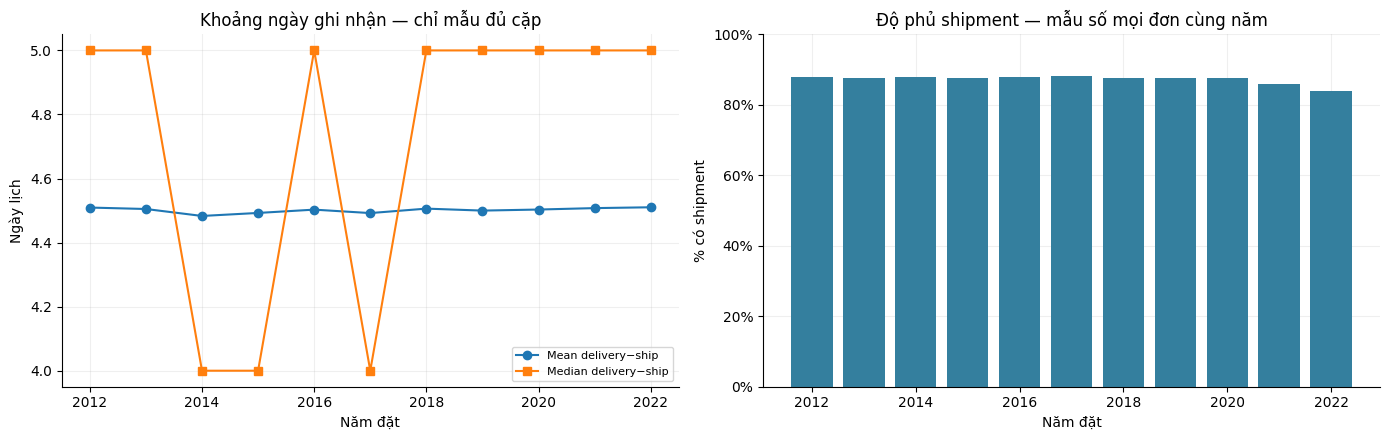

**Quan sát:** mean delivery−ship theo năm trong mẫu đủ cặp nằm trong 4,483–4,510 ngày. **Ý nghĩa:** đọc trung tâm cùng N/độ phủ. **Giới hạn:** nhóm không có mốc ngày để —, không gán thời gian 0; khác biệt chưa chứng minh hiệu quả nhân viên/nhà vận chuyển. **Câu hỏi tiếp:** thời gian/độ phủ có thay đổi do mẫu đạt mốc bị chọn lọc không?

In [38]:
ship_orders['joint_complete']=ship_orders.n_shipments.eq(1)&ship_orders[list(SHIP_METRICS)].notna().all(axis=1)
ship_missing_by_year_status=ship_orders.groupby(['order_year','order_status'],sort=True).agg(
    orders=('order_id','size'),with_shipment=('has_shipment','sum'),rows=('n_shipments','sum'),
    ship_dates=('n_ship_dates','sum'),delivery_dates=('n_delivery_dates','sum'),eligible=('joint_complete','sum'))
ship_missing_by_year_status['missing_shipment']=ship_missing_by_year_status.orders-ship_missing_by_year_status.with_shipment
ship_missing_by_year_status['missing_any_interval']=ship_missing_by_year_status.orders-ship_missing_by_year_status.eligible
with pd.option_context('display.max_rows',None,'display.max_columns',None):
    display(pd.DataFrame([{'Năm đặt':y,'order_status':s,'N mọi đơn':int(r.orders),'Có shipment':int(r.with_shipment),
        'Không shipment':int(r.missing_shipment),'Dòng shipment':int(r.rows),
        'Dòng thiếu/không đọc ship_date':int(r.rows-r.ship_dates),
        'Dòng thiếu/không đọc delivery_date':int(r.rows-r.delivery_dates),
        'Đơn đủ 3 khoảng (1 dòng)':int(r.eligible),'% thiếu khoảng/N mọi đơn':fpct(pct(r.missing_any_interval,r.orders))}
        for (y,s),r in ship_missing_by_year_status.iterrows()]))
ship_group_summaries={};ship_group_tables={}
for dim in ['order_year','order_status']:
    records=[]
    for label,group in ship_orders.groupby(dim,sort=True):
        row={'group':label,'orders':len(group),'with_shipment':int(group.has_shipment.sum()),
            'eligible':int(group.joint_complete.sum()),'coverage':pct(int(group.has_shipment.sum()),len(group))}
        for m in SHIP_METRICS:
            stats=ship_describe(group.loc[group.n_shipments.eq(1),m]);ship_group_summaries[(dim,label,m)]=stats
            for k in ['n','mean','median','std','p95']:row[m+'_'+k]=stats[k]
        records.append(row)
    ship_group_tables[dim]=pd.DataFrame(records).set_index('group')
    with pd.option_context('display.max_columns',None):
        display(pd.DataFrame([{'Nhóm '+dim:label,'N mọi đơn':int(r.orders),'N có shipment':int(r.with_shipment),
            '% có shipment':fpct(r.coverage),'N đủ 3 khoảng (1 dòng)':int(r.eligible),
            **{f'{SHIP_METRICS[m][2]} {k}':fmt(r[m+'_'+k],2) for m in SHIP_METRICS for k in ['mean','median','std','p95']}}
            for label,r in ship_group_tables[dim].iterrows()]))
ship_year_table=ship_group_tables['order_year']
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
axes[0].plot(ship_year_table.index,ship_year_table.transit_days_mean.astype(float),marker='o',label='Mean delivery−ship')
axes[0].plot(ship_year_table.index,ship_year_table.transit_days_median.astype(float),marker='s',label='Median delivery−ship')
axes[0].set(title='Khoảng ngày ghi nhận — chỉ mẫu đủ cặp',xlabel='Năm đặt',ylabel='Ngày lịch');axes[0].legend(fontsize=8)
axes[1].bar(ship_year_table.index,[float(x) for x in ship_year_table.coverage],color='#347f9e')
axes[1].set(title='Độ phủ shipment — mẫu số mọi đơn cùng năm',xlabel='Năm đặt',ylabel='% có shipment',ylim=(0,100))
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
for ax in axes:ax.grid(alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();display(fig);plt.close(fig)
display(Markdown(f'**Quan sát:** mean delivery−ship theo năm trong mẫu đủ cặp nằm trong '
    f'{fmt(ship_year_table.transit_days_mean.min(),3)}–{fmt(ship_year_table.transit_days_mean.max(),3)} ngày. '
    '**Ý nghĩa:** đọc trung tâm cùng N/độ phủ. **Giới hạn:** nhóm không có mốc ngày để —, không gán thời gian 0; '
    'khác biệt chưa chứng minh hiệu quả nhân viên/nhà vận chuyển. **Câu hỏi tiếp:** thời gian/độ phủ có thay đổi do mẫu đạt mốc bị chọn lọc không?'))


### Giới hạn quan sát cuối kỳ

Lấy các nhãn order_status có ít nhất một shipment trong toàn kỳ, rồi xem đơn thiếu dòng ở các nhãn đó.
Đây là tập mô tả, không xác nhận chính sách trạng thái bắt buộc có shipment.
Thiếu tập trung gần cuối kỳ và delivery_date dừng ở cuối lịch sử chỉ gợi giả thuyết cần xác minh về phạm vi trích xuất/cắt kỳ;
không tự điền ngày giao hoặc khẳng định nguyên nhân thiếu.


In [39]:
ship_states_observed=set(ship_status.index[ship_status.with_shipment.gt(0)])
ship_missing_observed_states=ship_orders.loc[~ship_orders.has_shipment & ship_orders.order_status.isin(ship_states_observed)]
ship_cutoff=date_end
ship_records_after_cutoff={f:int(ship_records[f+'_parsed'].gt(ship_cutoff).sum()) for f in ['ship_date','delivery_date']}
ship_late_summary=pd.DataFrame([{'Nhãn có shipment toàn kỳ':', '.join(sorted(ship_states_observed)),
    'Đơn thiếu shipment trong các nhãn':len(ship_missing_observed_states),
    'Ngày đặt sớm nhất tập thiếu':ship_missing_observed_states.order_date_parsed.min(),
    'Ngày đặt muộn nhất tập thiếu':ship_missing_observed_states.order_date_parsed.max(),
    'Max ship_date':ship_records.ship_date_parsed.max(),'Max delivery_date':ship_records.delivery_date_parsed.max(),
    'Ngày cuối orders':ship_cutoff,'Dòng ship_date sau cuối orders':ship_records_after_cutoff['ship_date'],
    'Dòng delivery_date sau cuối orders':ship_records_after_cutoff['delivery_date']}])
with pd.option_context('display.max_columns',None):display(ship_late_summary)
ship_cutoff_missing_counts=ship_missing_observed_states.groupby(['order_date','order_status']).size().unstack(fill_value=0)
display(ship_cutoff_missing_counts)
ship_late_status=ship_missing_observed_states.groupby('order_status').size()
display(pd.DataFrame({'Đơn thiếu shipment trong nhãn có shipment toàn kỳ':ship_late_status}))
display(Markdown(f'**Quan sát:** {fmt(len(ship_missing_observed_states))} đơn thiếu shipment trong các nhãn có shipment ở đơn khác, '
    f'được đặt từ {ship_missing_observed_states.order_date_parsed.min():%d/%m/%Y} đến '
    f'{ship_missing_observed_states.order_date_parsed.max():%d/%m/%Y}. '
    '**Ý nghĩa:** cần đánh giá sai lệch lựa chọn và dữ liệu cuối kỳ. '
    '**Giới hạn:** không chứng minh các đơn đã/chưa giao hoặc bao nhiêu ngày thực tế bị thiếu. '
    '**Cần làm rõ ở NV03.4:** quy tắc trích xuất, cập nhật và theo dõi sau cuối kỳ.'))


,Nhãn có shipment toàn kỳ,Đơn thiếu shipment trong các nhãn,Ngày đặt sớm nhất tập thiếu,Ngày đặt muộn nhất tập thiếu,Max ship_date,Max delivery_date,Ngày cuối orders,Dòng ship_date sau cuối orders,Dòng delivery_date sau cuối orders
0,"delivered, returned, shipped",564,2022-12-22,2022-12-31,2022-12-29,2022-12-31,2022-12-31,0,0


order_status,delivered,returned,shipped
order_date,,,
2022-12-22,3,0,0
2022-12-23,7,1,1
2022-12-24,13,1,1
2022-12-25,24,1,0
2022-12-26,42,2,2
2022-12-27,66,4,2
2022-12-28,113,4,4
2022-12-29,104,7,1
2022-12-30,85,8,0


,Đơn thiếu shipment trong nhãn có shipment toàn kỳ
order_status,
delivered,524
returned,29
shipped,11


**Quan sát:** 564 đơn thiếu shipment trong các nhãn có shipment ở đơn khác, được đặt từ 22/12/2022 đến 31/12/2022. **Ý nghĩa:** cần đánh giá sai lệch lựa chọn và dữ liệu cuối kỳ. **Giới hạn:** không chứng minh các đơn đã/chưa giao hoặc bao nhiêu ngày thực tế bị thiếu. **Cần làm rõ ở NV03.4:** quy tắc trích xuất, cập nhật và theo dõi sau cuối kỳ.

### NV03.2.6 — Phân loại chất lượng

**A — kỹ thuật:** khóa NULL/mồ côi, ngày không đọc được.
**B — nghiệp vụ cần xác minh:** ngày ngược, nhiều dòng/đơn, tổ hợp nhãn đơn và mốc ngày, mốc ngoài phạm vi orders.
**C — chưa đủ dữ liệu:** thiếu shipment, thiếu định nghĩa actual/planned/trạng thái/khóa kiện/SLA.

Các dòng vấn đề có thể chồng lấp; không cộng thành số đơn khác biệt. Ngày âm được giữ trong số học, không sửa/xóa nguồn.
Trường không tồn tại phải ghi không áp dụng, không ghi số 0 như đã kiểm tra.


In [40]:
ship_quality_findings=[
 {'Loại':'A','Hiện tượng':'order_id shipment NULL','N':int(ship_raw.order_id.isna().sum()),'Đơn vị':'dòng','Diễn giải':'Vi phạm khóa nếu có'},
 {'Loại':'A','Hiện tượng':'Shipment mồ côi','N':ship_orphans,'Đơn vị':'dòng','Diễn giải':'Không liên kết được orders'},
 {'Loại':'A','Hiện tượng':'Ngày không NULL nhưng sai cú pháp','N':sum(int((ship_records[f].notna()&ship_records[f+'_parsed'].isna()).sum()) for f in ['ship_date','delivery_date']),'Đơn vị':'ô ngày','Diễn giải':'Không tự điền/loại'},
 {'Loại':'B','Hiện tượng':'Trùng toàn bộ dư','N':int(ship_raw.duplicated().sum()),'Đơn vị':'dòng','Diễn giải':'Chưa có khóa nghiệp vụ để tự xóa'},
 {'Loại':'B','Hiện tượng':'Đơn nhiều dòng','N':ship_multi,'Đơn vị':'đơn','Diễn giải':'Không tự coi lỗi hoặc lấy một dòng làm hoàn tất'},
 *[{'Loại':'B','Hiện tượng':label+' âm','N':int(ship_records[m].lt(0).sum()),'Đơn vị':'dòng','Diễn giải':'Cần xác minh thứ tự/ý nghĩa mốc'} for m,(_,_,label) in SHIP_METRICS.items()],
 {'Loại':'B','Hiện tượng':'Nhãn shipped có delivery_date đọc được','N':int((ship_records.order_status.eq('shipped')&ship_records.delivery_date_parsed.notna()).sum()),'Đơn vị':'dòng','Diễn giải':'Không tự gọi lỗi khi chưa rõ actual/planned/thời điểm nhãn'},
 {'Loại':'B','Hiện tượng':'Mốc ngày sau cuối orders','N':sum(ship_records_after_cutoff.values()),'Đơn vị':'ô ngày','Diễn giải':'Nếu có chưa chắc sai vì xử lý có thể sau kỳ đặt'},
 {'Loại':'C','Hiện tượng':'Không shipment','N':ship_without,'Đơn vị':'đơn','Diễn giải':'Không chứng minh chưa giao'},
 {'Loại':'C','Hiện tượng':'NULL ngày trong dòng shipment','N':int(ship_records[['ship_date','delivery_date']].isna().sum().sum()),'Đơn vị':'ô ngày','Diễn giải':'Khác thiếu cả dòng shipment'},
 {'Loại':'C','Hiện tượng':'Mã kiện/trạng thái/nhà vận chuyển/SLA','N':'Không áp dụng','Đơn vị':'Không có cột','Diễn giải':'Không suy kiện, lịch sử trạng thái, chất lượng hãng hoặc trễ'},
 {'Loại':'C','Hiện tượng':'Số đơn có thời gian giao thực tế đã xác minh','N':'Chưa xác định','Đơn vị':'Cần tài liệu','Diễn giải':'Cặp ngày tính được không thay actual/planned'}]
with pd.option_context('display.max_rows',None,'display.max_columns',None,'display.max_colwidth',None):display(pd.DataFrame(ship_quality_findings))
display(Markdown('**5 ví dụ đơn thiếu shipment trong các nhãn có dòng ở đơn khác** — xếp ngày rồi mã chuỗi, chưa xác định chưa giao:'))
display(ship_missing_observed_states.sort_values(['order_date_parsed','order_id'],kind='stable').head(5)[['order_id','order_status','order_date']])


,Loại,Hiện tượng,N,Đơn vị,Diễn giải
0,A,order_id shipment NULL,0,dòng,Vi phạm khóa nếu có
1,A,Shipment mồ côi,0,dòng,Không liên kết được orders
2,A,Ngày không NULL nhưng sai cú pháp,0,ô ngày,Không tự điền/loại
3,B,Trùng toàn bộ dư,0,dòng,Chưa có khóa nghiệp vụ để tự xóa
4,B,Đơn nhiều dòng,0,đơn,Không tự coi lỗi hoặc lấy một dòng làm hoàn tất
5,B,Δ ship−order âm,0,dòng,Cần xác minh thứ tự/ý nghĩa mốc
6,B,Δ delivery−ship âm,0,dòng,Cần xác minh thứ tự/ý nghĩa mốc
7,B,Δ delivery−order âm,0,dòng,Cần xác minh thứ tự/ý nghĩa mốc
8,B,Nhãn shipped có delivery_date đọc được,13762,dòng,Không tự gọi lỗi khi chưa rõ actual/planned/thời điểm nhãn
9,B,Mốc ngày sau cuối orders,0,ô ngày,Nếu có chưa chắc sai vì xử lý có thể sau kỳ đặt


**5 ví dụ đơn thiếu shipment trong các nhãn có dòng ở đơn khác** — xếp ngày rồi mã chuỗi, chưa xác định chưa giao:

,order_id,order_status,order_date
646058,833169,delivered,2022-12-22
646085,833207,delivered,2022-12-22
646094,833217,delivered,2022-12-22
645849,832884,delivered,2022-12-23
645881,832929,shipped,2022-12-23


### Nhận xét tổng hợp và chuyển giao NV03.4

Shipment bổ sung mốc ngày mà một order_status không cho biết. Phải tách đủ trường trong một dòng với đủ độ phủ trên mọi đơn,
và tách mốc trừ được về số học với thời điểm thực tế đã được xác minh.
Cần làm rõ actual/planned; sự kiện bàn giao/nhận; cập nhật nhãn; khóa kiện/split shipment; trích xuất cuối kỳ;
ngày giờ/múi giờ; SLA và theo dõi sau kỳ. Chỉ ghi câu hỏi, không triển khai NV03.3–NV03.5 hoặc suy nguyên nhân,
sự hài lòng, hiệu suất nhân viên hay nhà vận chuyển.


In [41]:
display(Markdown(f'''
**Kết luận NV03.2:** {fmt(len(ship_raw))} dòng shipment liên kết {fmt(ship_with)} đơn
({fpct(pct(ship_with,len(ship_orders)))} mọi đơn); {fmt(ship_without)} đơn không có dòng.
File hiện tại có {fmt(ship_multi)} đơn nhiều dòng; độ phủ khác theo order_status.
Thiếu shipment chưa chứng minh chưa giao; delivery_date không tự xác nhận hoàn tất.

Trên {fmt(ship_stats['transit_days']['n'])} cặp ngày đọc được, mean Δ ship−order / Δ delivery−ship / Δ delivery−order là
**{fmt(ship_stats['prep_days']['mean'],3)} / {fmt(ship_stats['transit_days']['mean'],3)} / {fmt(ship_stats['total_days']['mean'],3)} ngày**,
median tương ứng **{fmt(ship_stats['prep_days']['median'])} / {fmt(ship_stats['transit_days']['median'])} / {fmt(ship_stats['total_days']['median'])} ngày**.
Đây là khoảng ngày ghi nhận, chưa xác minh thời gian giao thực tế hoặc SLA.

Có {fmt(len(ship_missing_observed_states))} đơn thiếu shipment ở các nhãn có dòng ở đơn khác, tập trung gần cuối kỳ.
Quan sát đặt câu hỏi về độ phủ và sai lệch lựa chọn, chưa xác nhận cơ chế thiếu hay kết quả sau kỳ.
NV03.4 cần tài liệu mốc ngày và nguồn theo dõi để đánh giá quy trình thực tế.
'''))



**Kết luận NV03.2:** 566.067 dòng shipment liên kết 566.067 đơn
(87,50% mọi đơn); 80.878 đơn không có dòng.
File hiện tại có 0 đơn nhiều dòng; độ phủ khác theo order_status.
Thiếu shipment chưa chứng minh chưa giao; delivery_date không tự xác nhận hoàn tất.

Trên 566.067 cặp ngày đọc được, mean Δ ship−order / Δ delivery−ship / Δ delivery−order là
**1,498 / 4,499 / 5,998 ngày**,
median tương ứng **1 / 4 / 6 ngày**.
Đây là khoảng ngày ghi nhận, chưa xác minh thời gian giao thực tế hoặc SLA.

Có 564 đơn thiếu shipment ở các nhãn có dòng ở đơn khác, tập trung gần cuối kỳ.
Quan sát đặt câu hỏi về độ phủ và sai lệch lựa chọn, chưa xác nhận cơ chế thiếu hay kết quả sau kỳ.
NV03.4 cần tài liệu mốc ngày và nguồn theo dõi để đánh giá quy trình thực tế.


### Kiểm chứng NV03.2

Tái đọc CSV/datetime và dùng dict/Counter để đối chiếu mọi dòng, phép trừ và nhóm năm/trạng thái.
Phân vị inclusive, std mẫu dùng statistics độc lập; sai số tối đa 10⁻⁹ ngày, số đếm/ngày nguyên khớp chính xác.
Ví dụ bộ nhớ có một đơn nhiều dòng, thiếu shipment, thiếu ngày, ngày ngược/sai cú pháp, mốc sau cuối orders, mã 0 đầu.

Ghi riêng **Đạt** cho kiểm tra áp dụng và **Không áp dụng** kèm lý do cho thiếu cột/định nghĩa; không cộng mục không áp dụng vào số đạt.
Kiểm chứng số học không xác minh nghiệp vụ actual/planned hoặc SLA.


In [42]:
ship_native_orders={}
for row in csv_rows(PATHS['orders']):
    oid=row['order_id'];assert oid not in ship_native_orders
    ship_native_orders[oid]={'status':row['order_status'],'date':datetime.strptime(row['order_date'],'%Y-%m-%d').date()}
ship_native_counts=Counter();ship_native_rows=[]
for i,row in enumerate(csv_rows(SHIP_PATH),1):
    oid=row['order_id'];assert oid in ship_native_orders
    parent=ship_native_orders[oid]
    sd=datetime.strptime(row['ship_date'],'%Y-%m-%d').date() if row['ship_date'] else None
    dd=datetime.strptime(row['delivery_date'],'%Y-%m-%d').date() if row['delivery_date'] else None
    ship_native_counts[oid]+=1
    ship_native_rows.append({'source_row':i,'order_id':oid,'status':parent['status'],'order_date':parent['date'],
        'ship_date':sd,'delivery_date':dd,'prep_days':(sd-parent['date']).days if sd else None,
        'transit_days':(dd-sd).days if sd and dd else None,'total_days':(dd-parent['date']).days if dd else None})
ship_native_by_group=defaultdict(list)
for row in ship_native_rows:
    for m in SHIP_METRICS:
        if row[m] is not None:
            ship_native_by_group[('all','all',m)].append(row[m])
            if ship_native_counts[row['order_id']]==1:
                ship_native_by_group[('order_year',row['order_date'].year,m)].append(row[m])
                ship_native_by_group[('order_status',row['status'],m)].append(row[m])
ship_fixture_orders=pd.DataFrame([('01','2022-12-20','delivered'),('2','2022-12-21','shipped'),
    ('3','2022-12-22','delivered'),('4','2022-12-23','created'),('5','2022-12-24','returned')],
    columns=['order_id','order_date','order_status'])
ship_fixture_raw=pd.DataFrame([('01','2022-12-21','2022-12-24','0'),('01','2022-12-22','2022-12-27','0'),
    ('2','2022-12-21',None,'0'),('3','2022-12-20','2022-12-19','0'),('5','not-a-date','2023-01-03','0')],
    columns=['order_id','ship_date','delivery_date','shipping_fee'])
ship_fixture_records,ship_fixture_orders_view=build_shipping_views(ship_fixture_orders,ship_fixture_raw)
display(Markdown('**Ví dụ giả lập:** 01 hai dòng, không gán hoàn tất đơn; 2 thiếu delivery_date; 3 ngày ngược; '
    '4 không shipment; 5 sai ship_date và delivery_date sau kỳ đặt.'))
display(ship_fixture_orders_view[['order_id','n_shipments','n_ship_dates','n_delivery_dates',*SHIP_METRICS]])
display(ship_fixture_records[['source_row','order_id','ship_date','delivery_date',*SHIP_METRICS]])


**Ví dụ giả lập:** 01 hai dòng, không gán hoàn tất đơn; 2 thiếu delivery_date; 3 ngày ngược; 4 không shipment; 5 sai ship_date và delivery_date sau kỳ đặt.

,order_id,n_shipments,n_ship_dates,n_delivery_dates,prep_days,transit_days,total_days
0,01,2,2,2,<NA>,<NA>,<NA>
1,2,1,1,0,0,<NA>,<NA>
2,3,1,1,1,-2,-1,-3
3,4,0,0,0,<NA>,<NA>,<NA>
4,5,1,0,1,<NA>,<NA>,10


,source_row,order_id,ship_date,delivery_date,prep_days,transit_days,total_days
0,1,01,2022-12-21,2022-12-24,1,3,4
1,2,01,2022-12-22,2022-12-27,2,5,7
2,3,2,2022-12-21,None,0,<NA>,<NA>
3,4,3,2022-12-20,2022-12-19,-2,-1,-3
4,5,5,not-a-date,2023-01-03,<NA>,<NA>,10


In [43]:
shipping_verification=[]
def shipping_check(name,condition):
    condition=bool(condition)
    shipping_verification.append({'Kiểm tra NV03.2':name,'Trạng thái':'Đạt' if condition else 'Không đạt','Lý do/phạm vi':'Áp dụng'})
    assert condition,name
def shipping_na(name,reason):
    shipping_verification.append({'Kiểm tra NV03.2':name,'Trạng thái':'Không áp dụng','Lý do/phạm vi':reason})
shipping_check('Cấu trúc và hash khớp hồ sơ nguồn',
    list(ship_raw.columns)==ship_profile['column_names'] and len(ship_raw)==ship_profile['rows']
    and digest(SHIP_PATH)==ship_source_hash==ship_profile['source_sha256'])
shipping_check('Tổng đơn khớp NV03.1/V02 và CSV độc lập; mỗi order_id một dòng',
    len(ship_orders)==n_orders==v02['metrics']['orders_rows']==len(ship_native_orders) and ship_orders.order_id.is_unique)
shipping_check('Số dòng, order_id và dòng trùng xác định từ nguồn',
    len(ship_records)==len(ship_raw)==len(ship_native_rows)
    and ship_raw.order_id.nunique()==len(ship_native_counts)
    and ship_raw.order_id.is_unique==(max(ship_native_counts.values())==1)
    and int(ship_raw.duplicated().sum())==ship_profile['duplicate_rows_excess'])
shipping_check('Có/không shipment phân hoạch đơn; mọi số đếm khớp Counter',
    ship_with+ship_without==n_orders and int(ship_orders.n_shipments.sum())==len(ship_raw)
    and all(r.n_shipments==ship_native_counts[r.order_id] for r in ship_orders.itertuples()))
shipping_check('Không mồ côi/NULL khóa, JOIN bản ghi không mất hoặc nhân dòng',
    ship_orphans==0 and ship_raw.order_id.notna().all() and len(ship_records)==len(ship_raw) and ship_records.source_row.is_unique)
shipping_check('Bảo toàn trạng thái đơn và số dòng shipment',
    ship_status.orders.to_dict()==status_counts.orders.to_dict() and int(ship_status.shipment_rows.sum())==len(ship_raw)
    and all(r.order_status==ship_native_orders[r.order_id]['status'] for r in ship_orders.itertuples()))
shipping_check('Đơn một/nhiều dòng đúng Counter độc lập',
    ship_multi==sum(n>1 for n in ship_native_counts.values())
    and int(ship_orders.n_shipments.eq(1).sum())==sum(n==1 for n in ship_native_counts.values()))
shipping_check('Tỷ lệ có shipment đúng N từng trạng thái, miền 0–100',
    all(r.coverage_pct==pct(r.with_shipment,r.orders) and 0<=r.coverage_pct<=100
        and r.with_shipment+r.without_shipment==r.orders for r in ship_status.itertuples()))
shipping_check('Ngày đọc được/NULL khớp nguồn độc lập, không tự điền',
    ship_records[['ship_date','delivery_date']].isna().sum().to_dict()==ship_raw[['ship_date','delivery_date']].isna().sum().to_dict()
    and all((pd.isna(r.ship_date_parsed) if n['ship_date'] is None else r.ship_date_parsed.date()==n['ship_date'])
        and (pd.isna(r.delivery_date_parsed) if n['delivery_date'] is None else r.delivery_date_parsed.date()==n['delivery_date'])
        for r,n in zip(ship_records.itertuples(),ship_native_rows)))
shipping_check('Mọi phép trừ ngày khớp datetime độc lập',
    all(r.order_id==n['order_id'] and r.source_row==n['source_row']
        and all(pd.isna(getattr(r,m)) if n[m] is None else int(getattr(r,m))==n[m] for m in SHIP_METRICS)
        for r,n in zip(ship_records.itertuples(),ship_native_rows)))
shipping_check('Số âm/0/thiếu mọi khoảng khớp độc lập',
    all(int(ship_records[m].lt(0).sum())==sum(n[m] is not None and n[m]<0 for n in ship_native_rows)
        and int(ship_records[m].eq(0).sum())==sum(n[m]==0 for n in ship_native_rows)
        and int(ship_records[m].isna().sum())==sum(n[m] is None for n in ship_native_rows) for m in SHIP_METRICS))
ship_stats_ok=True
for m,record in ship_stats.items():
    vals=ship_native_by_group[('all','all',m)];q=statistics.quantiles(vals,n=100,method='inclusive')
    ship_stats_ok &= record['n']==len(vals) and record['min']==min(vals) and record['max']==max(vals)
    ship_stats_ok &= math.isclose(record['mean'],statistics.mean(vals),abs_tol=1e-9,rel_tol=0)
    ship_stats_ok &= record['median']==statistics.median(vals) and math.isclose(record['std'],statistics.stdev(vals),abs_tol=1e-9,rel_tol=0)
    ship_stats_ok &= all(math.isclose(record[f'p{int(p*100)}'],q[int(p*100)-1],abs_tol=1e-9,rel_tol=0) for p in SHIP_QUANTILES)
shipping_check('Mọi thống kê/phân vị toàn kỳ khớp statistics độc lập',ship_stats_ok)
ship_bin_ok=True
for m in SHIP_METRICS:
    expected=Counter('Âm' if r[m]<0 else '0' if r[m]==0 else '1' if r[m]==1 else '2–3' if r[m]<=3 else '4–7' if r[m]<=7 else '>7'
        for r in ship_native_rows if r[m] is not None)
    ship_bin_ok &= all(int(ship_bins[m].loc[label])==expected[label] for label in SHIP_BIN_LABELS)
    ship_bin_ok &= int(ship_bins[m].sum())==ship_stats[m]['n']
shipping_check('Nhóm khoảng ngày rời nhau, phủ mẫu và đúng Counter độc lập',ship_bin_ok)
ship_group_ok=True
for (dim,label,m),record in ship_group_summaries.items():
    vals=ship_native_by_group[(dim,label,m)]
    ship_group_ok &= record['n']==len(vals)
    if vals:
        q=statistics.quantiles(vals,n=100,method='inclusive') if len(vals)>1 else None
        ship_group_ok &= math.isclose(record['mean'],statistics.mean(vals),abs_tol=1e-9,rel_tol=0) and record['median']==statistics.median(vals)
        ship_group_ok &= math.isclose(record['p95'],q[94] if q else vals[0],abs_tol=1e-9,rel_tol=0)
        if len(vals)>1:ship_group_ok &= math.isclose(record['std'],statistics.stdev(vals),abs_tol=1e-9,rel_tol=0)
    else:ship_group_ok &= all(record[f] is None for f in ['min','max','mean','median','std','p95'])
shipping_check('Thống kê năm/trạng thái khớp đối chứng, mẫu rỗng để thiếu',ship_group_ok)
shipping_check('Bảng thiếu năm×trạng thái bảo toàn đơn/dòng và công thức',
    int(ship_missing_by_year_status.orders.sum())==n_orders and int(ship_missing_by_year_status.rows.sum())==len(ship_raw)
    and all(r.missing_shipment==r.orders-r.with_shipment and r.missing_any_interval==r.orders-r.eligible
        for r in ship_missing_by_year_status.itertuples()))
shipping_check('Cấp đơn chỉ gán khoảng khi đúng một dòng; nhiều dòng không chọn first/last',
    ship_orders.loc[ship_orders.n_shipments.ne(1),list(SHIP_METRICS)].isna().all().all()
    and ship_fixture_orders_view.loc[ship_fixture_orders_view.order_id.eq('01'),list(SHIP_METRICS)].isna().all().all())
shipping_check('Tập thiếu shipment ở nhãn có dòng và tổng theo ngày khớp độc lập',
    set(ship_missing_observed_states.order_id)=={oid for oid,r in ship_native_orders.items() if oid not in ship_native_counts and r['status'] in ship_states_observed}
    and len(ship_missing_observed_states)==int(ship_cutoff_missing_counts.to_numpy().sum()))
shipping_check('Đếm mốc sau ngày cuối orders đúng, không coi tự động là lỗi',
    all(ship_records_after_cutoff[f]==sum(n[f] is not None and n[f]>date_end.date() for n in ship_native_rows)
        for f in ['ship_date','delivery_date']))
ship_extreme_ok=True
for m,(_,_,label) in SHIP_METRICS.items():
    available=[n for n in ship_native_rows if n[m] is not None]
    for direction,asc in [('Ngắn nhất',True),('Dài nhất',False)]:
        expected=sorted(available,key=lambda n:(n[m] if asc else -n[m],n['order_id'],n['source_row']))[:5]
        shown=[r for r in ship_extreme_rows if r['Chỉ tiêu']==label and r['Hướng']==direction]
        ship_extreme_ok &= [(r['order_id'],r['STT dòng dữ liệu'],r['Chênh lệch ngày']) for r in shown]==[(n['order_id'],n['source_row'],n[m]) for n in expected]
        tie=next(r for r in ship_extreme_ties if r['Chỉ tiêu']==label and r['Hướng']==direction)
        ship_extreme_ok &= tie['Dòng cùng ngưỡng toàn mẫu']==sum(n[m]==expected[-1][m] for n in available)
shipping_check('Top ngắn/dài và đồng hạng đúng thứ tự chuỗi với oracle',ship_extreme_ok)
fx=ship_fixture_orders_view.set_index('order_id')
shipping_check('Ví dụ một đơn nhiều dòng không gán hoàn tất đơn',
    fx.at['01','n_shipments']==2 and ship_fixture_records.loc[ship_fixture_records.order_id.eq('01'),'total_days'].to_list()==[4,7]
    and fx.loc['01',list(SHIP_METRICS)].isna().all())
shipping_check('Ví dụ thiếu cả shipment khác thiếu delivery_date trong dòng',
    fx.at['4','n_shipments']==0 and fx.loc['4',list(SHIP_METRICS)].isna().all()
    and fx.at['2','n_shipments']==1 and fx.at['2','n_ship_dates']==1 and fx.at['2','n_delivery_dates']==0
    and fx.at['2','prep_days']==0 and pd.isna(fx.at['2','transit_days']))
shipping_check('Ví dụ ngày âm giữ nguyên, không cắt hoặc điền',
    fx.at['3','prep_days']==-2 and fx.at['3','transit_days']==-1 and fx.at['3','total_days']==-3)
shipping_check('Ví dụ ngày sai/ngoài kỳ, mã 0 đầu xử lý đúng',
    fx.at['5','n_ship_dates']==0 and fx.at['5','n_delivery_dates']==1 and pd.isna(fx.at['5','prep_days'])
    and fx.at['5','total_days']==10 and '01' in fx.index)
orphan_blocked=False
try:
    bad=ship_fixture_raw.copy();bad.loc[0,'order_id']='unknown'
    build_shipping_views(ship_fixture_orders,bad)
except AssertionError:orphan_blocked=True
shipping_check('Ví dụ mã mồ côi bị chặn trước JOIN',orphan_blocked)
shipping_check('Mẫu số 0/mẫu rỗng để thiếu, không gán thời gian 0',
    divide(1,0) is None and pct(1,0) is None and ship_describe(pd.Series([],dtype=float))['mean'] is None)
shipping_check('NV03.1 vẫn 32/32, tổng đơn không thay đổi',
    len(verification)==32 and all(r['Đạt'] for r in verification) and len(ship_orders)==n_orders)
shipping_check('Mọi file ngoài notebook không đổi SHA-256, gồm NV01/NV02/raw/V01–V09/untracked',
    protected_snapshot()==protected_before)
shipping_na('Bảng chéo order_status × trạng thái vận chuyển','Không có cột trạng thái vận chuyển; không thay bằng việc có ngày giao')
shipping_na('Shipment vật lý phân biệt theo mã riêng','Không có mã shipment/kiện riêng; chỉ kiểm tra dòng và order_id')
shipping_na('Thời gian giao thực tế đã được xác minh','Chưa có tài liệu xác nhận actual/planned và ý nghĩa sự kiện')
shipping_na('Tỷ lệ trễ/SLA và chất lượng nhà vận chuyển','Không có SLA, thời hạn cam kết hoặc đơn vị vận chuyển')
shipping_na('Thời gian chính xác đến giờ/lịch sử trạng thái','Chỉ có ngày, không có nhật ký sự kiện')
with pd.option_context('display.max_rows',None,'display.max_colwidth',None):display(pd.DataFrame(shipping_verification))


,Kiểm tra NV03.2,Trạng thái,Lý do/phạm vi
0,Cấu trúc và hash khớp hồ sơ nguồn,Đạt,Áp dụng
1,Tổng đơn khớp NV03.1/V02 và CSV độc lập; mỗi order_id một dòng,Đạt,Áp dụng
2,"Số dòng, order_id và dòng trùng xác định từ nguồn",Đạt,Áp dụng
3,Có/không shipment phân hoạch đơn; mọi số đếm khớp Counter,Đạt,Áp dụng
4,"Không mồ côi/NULL khóa, JOIN bản ghi không mất hoặc nhân dòng",Đạt,Áp dụng
5,Bảo toàn trạng thái đơn và số dòng shipment,Đạt,Áp dụng
6,Đơn một/nhiều dòng đúng Counter độc lập,Đạt,Áp dụng
7,"Tỷ lệ có shipment đúng N từng trạng thái, miền 0–100",Đạt,Áp dụng
8,"Ngày đọc được/NULL khớp nguồn độc lập, không tự điền",Đạt,Áp dụng
9,Mọi phép trừ ngày khớp datetime độc lập,Đạt,Áp dụng


In [44]:
shipping_applied=[r for r in shipping_verification if r['Trạng thái']!='Không áp dụng']
shipping_not_applicable=[r for r in shipping_verification if r['Trạng thái']=='Không áp dụng']
assert all(r['Trạng thái']=='Đạt' for r in shipping_applied)
display(Markdown(f'''
**Hoàn thành chỉ NV03.2:** {fmt(len(ship_raw))} dòng shipment, {fmt(ship_with)} đơn có dòng,
{fmt(ship_without)} đơn không có; không nhân bản bảng cấp đơn.
**{len(shipping_applied)}/{len(shipping_applied)} kiểm chứng áp dụng đạt**;
**{len(shipping_not_applicable)} mục không áp dụng có lý do**, không tính là đạt. NV03.1 vẫn **32/32**.

Chênh lệch ngày chỉ mô tả mốc ghi nhận, chưa xác minh thời gian giao thực tế hoặc SLA.
Giữ nguyên 24 ô NV03.1; SHA-256 **{len(protected_before)} tệp ngoài notebook không đổi**.
Bằng chứng hai lượt **Restart Kernel → Run All** lưu trong metadata execution_validation.
Không triển khai NV03.3–NV03.5, không mở phân tích thanh toán/hoàn tiền/tồn kho,
không tạo tệp phụ hoặc stage/commit/push.
'''))



**Hoàn thành chỉ NV03.2:** 566.067 dòng shipment, 566.067 đơn có dòng,
80.878 đơn không có; không nhân bản bảng cấp đơn.
**27/27 kiểm chứng áp dụng đạt**;
**5 mục không áp dụng có lý do**, không tính là đạt. NV03.1 vẫn **32/32**.

Chênh lệch ngày chỉ mô tả mốc ghi nhận, chưa xác minh thời gian giao thực tế hoặc SLA.
Giữ nguyên 24 ô NV03.1; SHA-256 **87 tệp ngoài notebook không đổi**.
Bằng chứng hai lượt **Restart Kernel → Run All** lưu trong metadata execution_validation.
Không triển khai NV03.3–NV03.5, không mở phân tích thanh toán/hoàn tiền/tồn kho,
không tạo tệp phụ hoặc stage/commit/push.


# NV03.3 — Phân tích phương thức thanh toán và thiết bị đặt hàng

**Phạm vi:** chỉ NV03.3, bổ sung sau 45 ô NV03.1–NV03.2 và giữ nguyên nội dung/kết quả đã lưu. Dùng orders, payments và ledger Gross/Discount/Net cấp đơn đã kiểm chứng ở NV03.1. Không mở rộng refund, vận chuyển, mô hình hoặc NV03.4–NV03.5.

Đơn vị phân tích là **một order_id**. Giữ toàn bộ trạng thái, kể cả cancelled, created và returned. Nhãn payment_method không xác nhận thanh toán thành công; device_type là thuộc tính của **đơn**, không xác nhận thiết bị sở hữu hoặc thiết bị duy nhất của khách. Các cơ cấu theo thời gian dùng **order_date**, không phải thời điểm thanh toán hoặc chuyển trạng thái.

Gross = tổng quantity × unit_price; Discount = tổng discount_amount của dòng hàng; Net = Gross − Discount, **chưa trừ hoàn tiền**. Tiền dùng ĐVT (chưa xác minh tên tiền tệ). Tỷ trọng đơn/Net dùng tổng đơn/Net toàn kỳ; Discount/Gross dùng tỷ số tổng, không lấy trung bình tỷ lệ từng đơn. Mẫu số 0 để trống (—). Số khách phân biệt trong mỗi nhóm có thể trùng giữa các nhóm, **không cộng thành tổng khách**.


In [29]:
raw033={name:read_table(PATHS[name]) for name in ['orders','payments']}
o033,p033=raw033['orders'],raw033['payments']
inventory033=pd.DataFrame([{'Bảng':name,'Số dòng':len(frame),'Số cột':len(frame.columns),'Trường':c,
    'Kiểu đọc':str(frame[c].dtype),'NULL':int(frame[c].isna().sum()),
    'Chuỗi trắng':int(frame[c].astype('string').str.fullmatch(r'\s*',na=False).sum()),
    'Phân biệt không NULL':int(frame[c].nunique())}
    for name,frame in raw033.items() for c in frame.columns])
with pd.option_context('display.max_rows',None,'display.max_columns',None):display(inventory033)
assert list(o033.columns)==expected_columns['orders'] and list(p033.columns)==expected_columns['payments']
assert o033.order_id.is_unique and o033.order_id.notna().all()
assert o033[['customer_id','order_date','order_status','payment_method','device_type']].notna().all().all()
assert not inventory033['Chuỗi trắng'].any()
payment_text033=pd.read_csv(PATHS['payments'],dtype='string',encoding='utf-8-sig',skip_blank_lines=False)
payment_parsed033=payment_text033.payment_value.map(exact_decimal)
installments033=payment_text033.installments.map(exact_decimal)
numeric033=[]
for field,values in [('payment_value',payment_parsed033),('installments',installments033)]:
    numeric033.append({'Trường':field,'NULL gốc':int(payment_text033[field].isna().sum()),
        'Không đọc được/không hữu hạn (gồm NULL)':int(values.isna().sum()),
        'Âm':int(values.dropna().lt(0).sum()),'Bằng 0':int(values.dropna().eq(0).sum()),
        'Không nguyên':sum(v!=v.to_integral_value() for v in values.dropna()),
        'Min':fmt(values.dropna().min(),2),'Max':fmt(values.dropna().max(),2)})
display(pd.DataFrame(numeric033))
assert payment_parsed033.notna().all()
categories033=pd.DataFrame([{'Nguồn/trường':name+'.'+field,'Giá trị ghi nhận':', '.join(sorted(frame[field].dropna().astype(str).unique())),
    'NULL':int(frame[field].isna().sum())} for name,frame,field in [
        ('orders',o033,'payment_method'),('payments',p033,'payment_method'),('orders',o033,'device_type')]])
with pd.option_context('display.max_colwidth',None):display(categories033)
display(Markdown('**Quan sát:** bảng trên ghi tên trường/kiểu đọc thực tế, NULL và miền số; payment_value được đọc lại '
    'từ chuỗi nguồn bằng Decimal, không cộng float hay làm tròn trung gian. **Ý nghĩa:** phân tích dùng thuộc tính thật ở cấp đơn. '
    '**Giới hạn:** installments chỉ được kiểm tra cấu trúc, không suy diễn lịch trả góp; nguồn không có payment_id, '
    'payment_date, trạng thái giao dịch hoặc chứng từ quyết toán. **Cần làm rõ:** payment_value là ghi nhận dự kiến hay kết quả thu tiền?'))


,Bảng,Số dòng,Số cột,Trường,Kiểu đọc,NULL,Chuỗi trắng,Phân biệt không NULL
0,orders,646945,8,order_id,string,0,0,646945
1,orders,646945,8,order_date,object,0,0,3833
2,orders,646945,8,customer_id,string,0,0,90246
3,orders,646945,8,zip,string,0,0,29932
4,orders,646945,8,order_status,object,0,0,6
5,orders,646945,8,payment_method,object,0,0,5
6,orders,646945,8,device_type,object,0,0,3
7,orders,646945,8,order_source,object,0,0,6
8,payments,646945,4,order_id,string,0,0,646945
9,payments,646945,4,payment_method,object,0,0,5


,Trường,NULL gốc,Không đọc được/không hữu hạn (gồm NULL),Âm,Bằng 0,Không nguyên,Min,Max
0,payment_value,0,0,0,0,634579,"389,74","331.570,40"
1,installments,0,0,0,0,0,"1,00","12,00"


,Nguồn/trường,Giá trị ghi nhận,NULL
0,orders.payment_method,"apple_pay, bank_transfer, cod, credit_card, paypal",0
1,payments.payment_method,"apple_pay, bank_transfer, cod, credit_card, paypal",0
2,orders.device_type,"desktop, mobile, tablet",0


**Quan sát:** bảng trên ghi tên trường/kiểu đọc thực tế, NULL và miền số; payment_value được đọc lại từ chuỗi nguồn bằng Decimal, không cộng float hay làm tròn trung gian. **Ý nghĩa:** phân tích dùng thuộc tính thật ở cấp đơn. **Giới hạn:** installments chỉ được kiểm tra cấu trúc, không suy diễn lịch trả góp; nguồn không có payment_id, payment_date, trạng thái giao dịch hoặc chứng từ quyết toán. **Cần làm rõ:** payment_value là ghi nhận dự kiến hay kết quả thu tiền?

### NV03.3.1 — Khóa, quan hệ và chính sách nhiều payment

Kiểm tra trước JOIN: khóa orders, khóa payment, số dòng/đơn, thiếu/mồ côi và phương thức ở cả hai nguồn. order_id trong payments là khóa ứng viên của file hiện tại, không thay thế mã giao dịch thanh toán.

**Chính sách:** tổng hợp payment_value bằng Decimal theo order_id rồi JOIN one_to_one với bảng cấp đơn. Giữ số dòng, số giá trị hợp lệ và **tập nhãn phương thức**; không chọn first/last khi một đơn có nhiều phương thức. Nếu một dòng tiền không đọc được, tổng payment của đơn để thiếu, không cộng bỏ qua dòng sai. Không có payment khác payment bằng 0. Khóa rỗng, khóa orders trùng hoặc payment mồ côi chặn JOIN. Số khách/tiền đơn chỉ tính từ bảng một dòng/đơn; phân nhóm phương thức dùng orders.payment_method.


In [30]:
def aggregate_payments033(order_ids,payment_rows):
    assert order_ids.order_id.notna().all() and order_ids.order_id.is_unique
    assert not order_ids.order_id.astype('string').str.fullmatch(r'\s*',na=False).any()
    assert payment_rows.order_id.notna().all()
    assert not payment_rows.order_id.astype('string').str.fullmatch(r'\s*',na=False).any()
    assert payment_rows.order_id.isin(order_ids.order_id).all(), 'Payment mồ côi'
    work=payment_rows[['order_id','payment_method','payment_value']].copy()
    work['parsed_value']=work.payment_value.map(exact_decimal)
    result=work.groupby('order_id',sort=False).agg(n_payment_rows=('order_id','size'),
        n_valid_values=('parsed_value','count'),
        payment_total=('parsed_value',lambda s:sum(s,ZERO) if s.notna().all() else None),
        payment_methods=('payment_method',lambda s:tuple(sorted(set('<NULL>' if pd.isna(v) or not str(v).strip() else str(v) for v in s)))))
    return result.reset_index()

pay033=aggregate_payments033(o033[['order_id']],payment_text033)
base033=ledger[['order_id','customer_id','order_status','date','year','gross','discount','net']].merge(
    o033[['order_id','payment_method','device_type']],on='order_id',how='left',validate='one_to_one')
view033=base033.merge(pay033,on='order_id',how='left',validate='one_to_one',sort=False)
view033['n_payment_rows']=view033.n_payment_rows.fillna(0).astype(int)
orphans033=int((~p033.order_id.isin(o033.order_id)).sum())
key033=pd.DataFrame([
    {'Nguồn/phép JOIN':'orders','Dòng':len(o033),'order_id phân biệt':o033.order_id.nunique(),
        'NULL khóa':int(o033.order_id.isna().sum()),'Khóa trùng dư':int(o033.order_id.duplicated().sum()),'Mồ côi':0},
    {'Nguồn/phép JOIN':'payments gốc','Dòng':len(p033),'order_id phân biệt':p033.order_id.nunique(),
        'NULL khóa':int(p033.order_id.isna().sum()),'Khóa trùng dư':int(p033.order_id.duplicated().sum()),'Mồ côi':orphans033},
    {'Nguồn/phép JOIN':'orders + tiền cấp đơn + payment tổng hợp','Dòng':len(view033),'order_id phân biệt':view033.order_id.nunique(),
        'NULL khóa':int(view033.order_id.isna().sum()),'Khóa trùng dư':int(view033.order_id.duplicated().sum()),'Mồ côi':0}])
with pd.option_context('display.max_columns',None):display(key033)
pay_frequency033=view033.groupby('n_payment_rows').size().rename('Số đơn').to_frame()
pay_frequency033.index.name='Số dòng payment/đơn'
pay_frequency033['% toàn bộ đơn']=[fpct(pct(n,len(view033))) for n in pay_frequency033['Số đơn']]
display(pay_frequency033)
pair033=p033[['order_id','payment_method']].merge(o033[['order_id','payment_method']],on='order_id',
    how='left',validate='many_to_one',suffixes=('_payments','_orders'))
method_mismatch033=int(pair033.payment_method_payments.ne(pair033.payment_method_orders).sum())
display(pd.DataFrame([{'Đơn không payment':int(view033.n_payment_rows.eq(0).sum()),
    'Đơn nhiều payment':int(view033.n_payment_rows.gt(1).sum()),
    'Dòng payment khác nhãn orders':method_mismatch033,'Trùng toàn dòng payments dư':int(p033.duplicated().sum()),
    'Khách toàn kỳ (không cộng nhóm)':view033.customer_id.nunique()}]))
display(Markdown(f'**Quan sát:** {fmt(len(p033))} dòng payment cho {fmt(len(pay033))} đơn; '
    f'{fmt(int(view033.n_payment_rows.eq(0).sum()))} đơn không payment, {fmt(orphans033)} dòng mồ côi, '
    f'{fmt(int(view033.n_payment_rows.gt(1).sum()))} đơn nhiều payment; {fmt(method_mismatch033)} dòng khác phương thức giữa hai nguồn. '
    '**Ý nghĩa:** JOIN hiện bảo toàn một dòng/đơn; chính sách tổng hợp vẫn được kiểm thử bằng ví dụ nhiều payment. '
    '**Giới hạn:** cùng order_id và cùng nhãn không chứng minh giao dịch thành công. **Cần làm rõ:** mã giao dịch và lịch sử đối soát.'))


,Nguồn/phép JOIN,Dòng,order_id phân biệt,NULL khóa,Khóa trùng dư,Mồ côi
0,orders,646945,646945,0,0,0
1,payments gốc,646945,646945,0,0,0
2,orders + tiền cấp đơn + payment tổng hợp,646945,646945,0,0,0


,Số đơn,% toàn bộ đơn
Số dòng payment/đơn,,
1,646945,"100,00%"


,Đơn không payment,Đơn nhiều payment,Dòng payment khác nhãn orders,Trùng toàn dòng payments dư,Khách toàn kỳ (không cộng nhóm)
0,0,0,0,0,90246


**Quan sát:** 646.945 dòng payment cho 646.945 đơn; 0 đơn không payment, 0 dòng mồ côi, 0 đơn nhiều payment; 0 dòng khác phương thức giữa hai nguồn. **Ý nghĩa:** JOIN hiện bảo toàn một dòng/đơn; chính sách tổng hợp vẫn được kiểm thử bằng ví dụ nhiều payment. **Giới hạn:** cùng order_id và cùng nhãn không chứng minh giao dịch thành công. **Cần làm rõ:** mã giao dịch và lịch sử đối soát.

### NV03.3.2 — Phân bố phương thức thanh toán

Mỗi phương thức hiển thị số đơn, số khách phân biệt, tổng Gross/Discount/Net, tỷ trọng đơn/Net, Net bình quân/trung vị mỗi đơn và tỷ lệ tổng Discount/Gross. Đồng hạng xếp theo nhãn chuỗi. Khách có thể dùng nhiều phương thức; tổng Net lớn có thể chủ yếu do nhiều đơn, cần đọc kèm bình quân/trung vị.

Bảng dùng triệu ĐVT cho tổng tiền, ĐVT cho tiền mỗi đơn; các phép kiểm chứng vẫn dùng Decimal chưa làm tròn.


,Nhóm phương thức,Số đơn,% đơn,Khách phân biệt trong nhóm,Gross (triệu ĐVT),Discount (triệu ĐVT),Net (triệu ĐVT),% Net,Mean Net/đơn (ĐVT),Median Net/đơn (ĐVT),Discount/Gross
0,credit_card,356.352,"55,08%",76.543,"9.042,37","412,31","8.630,07","55,04%","24.217,82","17.222,08","4,56%"
1,paypal,97.018,"15,00%",45.617,"2.478,10","114,42","2.363,68","15,07%","24.363,32","17.331,95","4,62%"
2,cod,96.681,"14,94%",45.545,"2.458,30","111,35","2.346,95","14,97%","24.275,17","17.197,20","4,53%"
3,apple_pay,64.763,"10,01%",36.587,"1.638,58","74,31","1.564,27","9,98%","24.153,75","17.206,84","4,53%"
4,bank_transfer,32.131,"4,97%",23.131,"813,13","37,22","775,90","4,95%","24.148,10","17.104,35","4,58%"


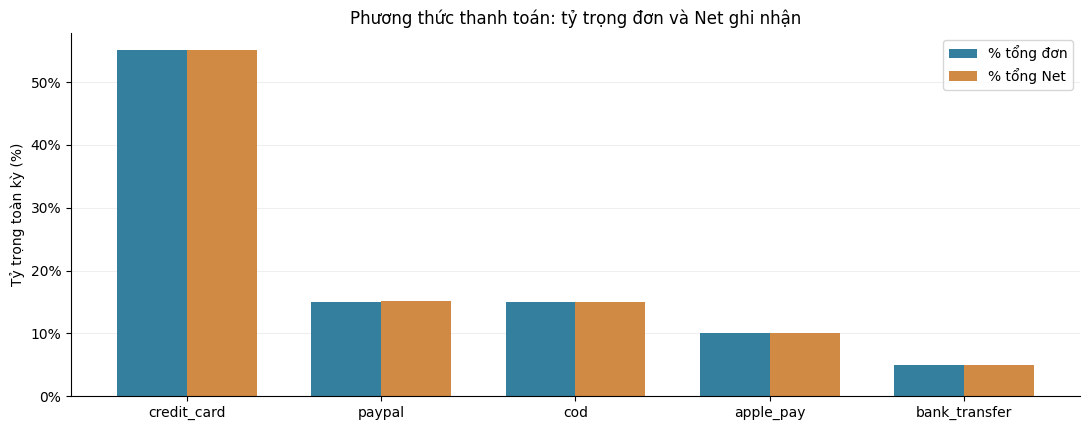

**Quan sát:** credit_card đứng đầu số đơn: 356.352 (55,08%); credit_card đứng đầu Net: 8.630.069.413,19 ĐVT (55,04%). Có 60.896/90.246 khách dùng hơn một phương thức. **Ý nghĩa:** cần phân biệt quy mô đơn với tiền mỗi đơn và tệp khách chồng lặp. **Giới hạn:** chưa phải thị phần thanh toán thành công, thực thu hoặc giá trị sau hoàn tiền. **Cần làm rõ:** chính sách lựa chọn và ghi nhận phương thức của từng nhóm đơn.

In [31]:
MONEY033=['gross','discount','net']
def summarize033(frame,dimension):
    rows=[]
    for label,g in frame.groupby(dimension,sort=True,dropna=False):
        amounts={f:sum(g[f],ZERO) for f in MONEY033}
        rows.append({'label':label,'orders':len(g),'customers':g.customer_id.nunique(),**amounts,
            'order_share':pct(len(g),len(frame)),'net_share':pct(amounts['net'],sum(frame.net,ZERO)),
            'mean_net':divide(amounts['net'],len(g)),'median_net':statistics.median(g.net),
            'discount_rate':pct(amounts['discount'],amounts['gross'])})
    return pd.DataFrame(rows).set_index('label').sort_values(['orders','label'],ascending=[False,True],kind='stable')

def summary_display033(summary,dimension):
    return pd.DataFrame([{'Nhóm '+dimension:label,'Số đơn':fmt(r.orders),'% đơn':fpct(r.order_share),
        'Khách phân biệt trong nhóm':fmt(r.customers),'Gross (triệu ĐVT)':fmt(r.gross/1000000,2),
        'Discount (triệu ĐVT)':fmt(r.discount/1000000,2),'Net (triệu ĐVT)':fmt(r.net/1000000,2),
        '% Net':fpct(r.net_share),'Mean Net/đơn (ĐVT)':fmt(r.mean_net,2),
        'Median Net/đơn (ĐVT)':fmt(r.median_net,2),'Discount/Gross':fpct(r.discount_rate)} for label,r in summary.iterrows()])

method033=summarize033(view033,'payment_method')
device033=summarize033(view033,'device_type')
with pd.option_context('display.max_columns',None):display(summary_display033(method033,'phương thức'))
fig,ax=plt.subplots(figsize=(11,4.4))
x=np.arange(len(method033));w=.36
ax.bar(x-w/2,method033.order_share.map(float),w,label='% tổng đơn',color='#347f9e')
ax.bar(x+w/2,method033.net_share.map(float),w,label='% tổng Net',color='#d18a43')
ax.set(xticks=x,xticklabels=method033.index,ylabel='Tỷ trọng toàn kỳ (%)',
    title='Phương thức thanh toán: tỷ trọng đơn và Net ghi nhận')
ax.yaxis.set_major_formatter(PercentFormatter(100));ax.legend();ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();display(fig);plt.close(fig)
top_method_orders033=method033.orders.idxmax();top_method_net033=method033.net.idxmax()
customer_methods033=view033.groupby('customer_id').payment_method.nunique()
display(Markdown(f'**Quan sát:** {top_method_orders033} đứng đầu số đơn: '
    f'{fmt(method033.at[top_method_orders033,"orders"])} ({fpct(method033.at[top_method_orders033,"order_share"])}); '
    f'{top_method_net033} đứng đầu Net: {fmt(method033.at[top_method_net033,"net"],2)} ĐVT '
    f'({fpct(method033.at[top_method_net033,"net_share"])}). '
    f'Có {fmt(int(customer_methods033.gt(1).sum()))}/{fmt(len(customer_methods033))} khách dùng hơn một phương thức. '
    '**Ý nghĩa:** cần phân biệt quy mô đơn với tiền mỗi đơn và tệp khách chồng lặp. '
    '**Giới hạn:** chưa phải thị phần thanh toán thành công, thực thu hoặc giá trị sau hoàn tiền. '
    '**Cần làm rõ:** chính sách lựa chọn và ghi nhận phương thức của từng nhóm đơn.'))


### NV03.3.3 — Thiết bị và trạng thái đơn hàng

Dùng orders.device_type tại thời điểm ghi nhận đơn. Bảng chéo hiển thị **số đơn (tỷ trọng trong hàng)** và cột N là tổng số đơn của từng thiết bị. Không cộng khách của nhiều thiết bị. Khác biệt Net hoặc trạng thái giữa thiết bị chỉ là liên hệ mô tả, chưa kiểm soát khách hàng, giá trị giỏ hàng, năm hay các thuộc tính khác.


,Nhóm thiết bị,Số đơn,% đơn,Khách phân biệt trong nhóm,Gross (triệu ĐVT),Discount (triệu ĐVT),Net (triệu ĐVT),% Net,Mean Net/đơn (ĐVT),Median Net/đơn (ĐVT),Discount/Gross
0,mobile,291.482,"45,06%",71.750,"7.403,12","336,33","7.066,79","45,07%","24.244,34","17.246,90","4,54%"
1,desktop,258.855,"40,01%",68.912,"6.564,85","299,81","6.265,04","39,95%","24.202,90","17.187,77","4,57%"
2,tablet,96.608,"14,93%",45.572,"2.462,50","113,47","2.349,04","14,98%","24.315,16","17.273,64","4,61%"


,N đơn trong hàng,cancelled — đơn (% hàng),created — đơn (% hàng),delivered — đơn (% hàng),paid — đơn (% hàng),returned — đơn (% hàng),shipped — đơn (% hàng)
Thiết bị,,,,,,,
desktop,258.855,"23.719 (9,16%)","2.891 (1,12%)","206.820 (79,90%)","5.371 (2,07%)","14.541 (5,62%)","5.513 (2,13%)"
mobile,291.482,"26.712 (9,16%)","3.228 (1,11%)","232.872 (79,89%)","6.175 (2,12%)","16.335 (5,60%)","6.160 (2,11%)"
tablet,96.608,"9.031 (9,35%)","1.156 (1,20%)","77.024 (79,73%)","2.031 (2,10%)","5.266 (5,45%)","2.100 (2,17%)"


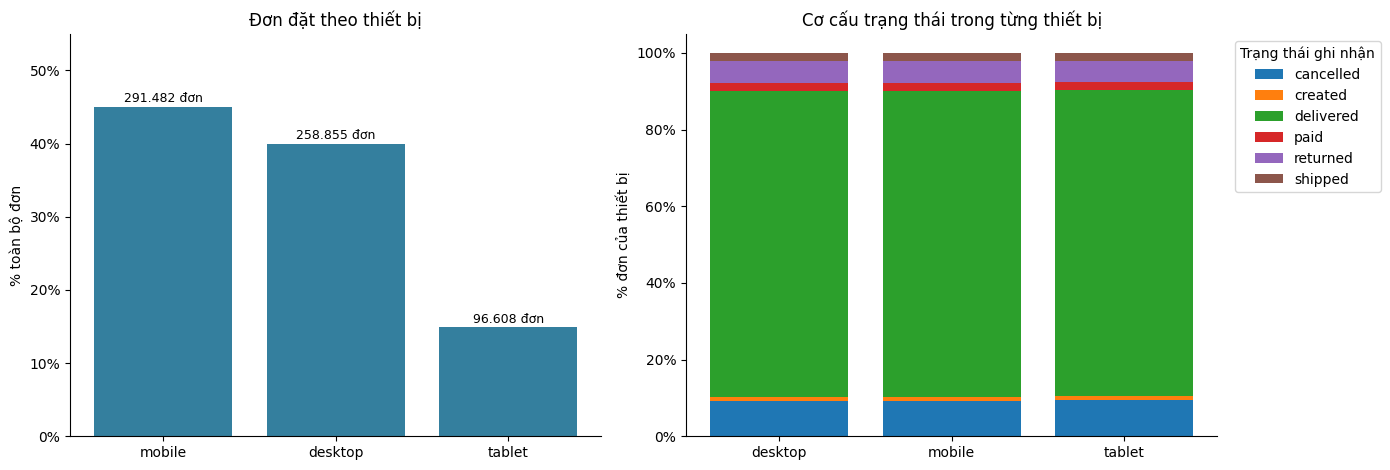

**Quan sát:** mobile có nhiều đơn nhất (291.482, 45,06%); 61.056 khách có đơn trên hơn một loại thiết bị. Tỷ trọng delivered giữa các thiết bị chênh tối đa 0,170 đpt. **Ý nghĩa:** cơ cấu trạng thái giữa thiết bị trong toàn kỳ khá gần nhau; vẫn phải đọc tiền mỗi đơn riêng. **Giới hạn:** không xác nhận thiết bị gây ra thay đổi tiền/trạng thái hoặc thể hiện sở hữu thiết bị. **Cần làm rõ:** liệu khác biệt còn giữ khi xét cùng kỳ và cùng nhóm khách?

In [32]:
method_labels033=method033.index.to_list();device_labels033=device033.index.to_list()
statuses033=sorted(view033.order_status.unique())
def cross033(frame,row,col,columns=None):
    counts=pd.crosstab(frame[row],frame[col],dropna=False)
    if columns is not None:counts=counts.reindex(columns=columns,fill_value=0)
    return counts,counts.div(counts.sum(axis=1).replace(0,np.nan),axis=0)*100

def cross_display033(counts,shares,row_label):
    out=pd.DataFrame(index=counts.index);out.index.name=row_label
    out['N đơn trong hàng']=counts.sum(axis=1).map(fmt)
    for col in counts.columns:
        out[str(col)+' — đơn (% hàng)']=[fmt(counts.at[i,col])+' ('+fpct(shares.at[i,col])+')' for i in counts.index]
    return out

ds033,dsp033=cross033(view033,'device_type','order_status',statuses033)
with pd.option_context('display.max_columns',None):
    display(summary_display033(device033,'thiết bị'))
    display(cross_display033(ds033,dsp033,'Thiết bị'))
fig,axes=plt.subplots(1,2,figsize=(14,4.8))
axes[0].bar(device033.index,device033.order_share.map(float),label='% tổng đơn',color='#347f9e')
for i,(label,r) in enumerate(device033.iterrows()):
    axes[0].text(i,float(r.order_share)+.6,fmt(r.orders)+' đơn',ha='center',fontsize=9)
axes[0].set(title='Đơn đặt theo thiết bị',ylabel='% toàn bộ đơn',ylim=(0,55))
bottom=np.zeros(len(ds033))
for s in statuses033:
    axes[1].bar(ds033.index,dsp033[s],bottom=bottom,label=s);bottom+=dsp033[s].to_numpy()
axes[1].set(title='Cơ cấu trạng thái trong từng thiết bị',ylabel='% đơn của thiết bị')
for ax in axes:ax.yaxis.set_major_formatter(PercentFormatter(100))
axes[1].legend(title='Trạng thái ghi nhận',bbox_to_anchor=(1.02,1),loc='upper left')
fig.tight_layout();display(fig);plt.close(fig)
customer_devices033=view033.groupby('customer_id').device_type.nunique()
delivered_device_range033=dsp033['delivered'].max()-dsp033['delivered'].min()
display(Markdown(f'**Quan sát:** {device033.orders.idxmax()} có nhiều đơn nhất '
    f'({fmt(device033.orders.max())}, {fpct(device033.at[device033.orders.idxmax(),"order_share"])}); '
    f'{fmt(int(customer_devices033.gt(1).sum()))} khách có đơn trên hơn một loại thiết bị. '
    f'Tỷ trọng delivered giữa các thiết bị chênh tối đa {fmt(delivered_device_range033,3)} đpt. '
    '**Ý nghĩa:** cơ cấu trạng thái giữa thiết bị trong toàn kỳ khá gần nhau; vẫn phải đọc tiền mỗi đơn riêng. '
    '**Giới hạn:** không xác nhận thiết bị gây ra thay đổi tiền/trạng thái hoặc thể hiện sở hữu thiết bị. '
    '**Cần làm rõ:** liệu khác biệt còn giữ khi xét cùng kỳ và cùng nhóm khách?'))


### NV03.3.4–NV03.3.5 — Phương thức × trạng thái và thiết bị × phương thức

Mỗi bảng chéo có N đơn trong hàng và số đơn (% trong hàng). Bảng phương thức × trạng thái trả lời cơ cấu trạng thái **trong từng phương thức**; bảng thiết bị × phương thức trả lời lựa chọn phương thức **trong từng thiết bị**. Không so phần trăm có mẫu số khác nhau mà bỏ qua N.

order_status là nhãn trong dữ liệu, không có lịch sử chuyển trạng thái. delivered không phải tỷ lệ thanh toán thành công; COD + delivered chưa chứng minh thu được tiền. Không suy phương thức gây hủy/trả hoặc đề xuất thay đổi chính sách từ bảng mô tả.


,N đơn trong hàng,cancelled — đơn (% hàng),created — đơn (% hàng),delivered — đơn (% hàng),paid — đơn (% hàng),returned — đơn (% hàng),shipped — đơn (% hàng)
Phương thức,,,,,,,
apple_pay,64.763,"5.190 (8,01%)","732 (1,13%)","52.836 (81,58%)","1.331 (2,06%)","3.269 (5,05%)","1.405 (2,17%)"
bank_transfer,32.131,"2.535 (7,89%)","343 (1,07%)","26.263 (81,74%)","688 (2,14%)","1.605 (5,00%)","697 (2,17%)"
cod,96.681,"15.468 (16,00%)","1.082 (1,12%)","67.355 (69,67%)","2.127 (2,20%)","8.620 (8,92%)","2.029 (2,10%)"
credit_card,356.352,"28.452 (7,98%)","4.028 (1,13%)","291.073 (81,68%)","7.405 (2,08%)","17.807 (5,00%)","7.587 (2,13%)"
paypal,97.018,"7.817 (8,06%)","1.090 (1,12%)","79.189 (81,62%)","2.026 (2,09%)","4.841 (4,99%)","2.055 (2,12%)"


,N đơn trong hàng,credit_card — đơn (% hàng),paypal — đơn (% hàng),cod — đơn (% hàng),apple_pay — đơn (% hàng),bank_transfer — đơn (% hàng)
Thiết bị,,,,,,
desktop,258.855,"142.444 (55,03%)","39.065 (15,09%)","38.587 (14,91%)","25.840 (9,98%)","12.919 (4,99%)"
mobile,291.482,"160.852 (55,18%)","43.462 (14,91%)","43.462 (14,91%)","29.268 (10,04%)","14.438 (4,95%)"
tablet,96.608,"53.056 (54,92%)","14.491 (15,00%)","14.632 (15,15%)","9.655 (9,99%)","4.774 (4,94%)"


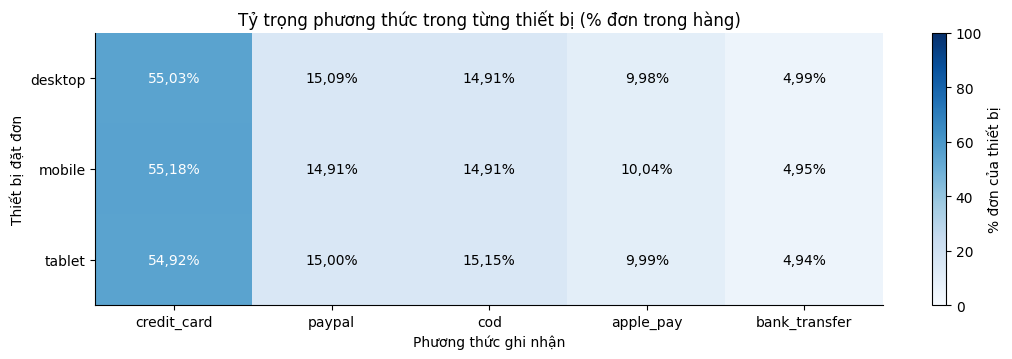

**Quan sát:** COD có 96.681 đơn; cancelled 16,00% và returned 8,92%. So nhóm gộp phương thức còn lại (N=550.264), chênh lần lượt 8,00 và 3,91 đpt. Tổ hợp nhiều đơn nhất là mobile × credit_card: 160.852 đơn. Chênh lớn nhất giữa các thiết bị về tỷ trọng một phương thức là 0,265 đpt (credit_card). **Ý nghĩa:** có liên hệ mô tả đáng chú ý giữa COD và cơ cấu trạng thái, trong khi cơ cấu phương thức giữa thiết bị gần nhau. **Giới hạn:** chưa kiểm soát yếu tố gây nhiễu hoặc chứng minh nhân quả/thu tiền. **Cần làm rõ:** quy tắc trạng thái, thời điểm chốt dữ liệu và cơ cấu khách/giỏ hàng theo phương thức.

In [33]:
ms033,msp033=cross033(view033,'payment_method','order_status',statuses033)
dp033,dpp033=cross033(view033,'device_type','payment_method',method_labels033)
with pd.option_context('display.max_columns',None):
    display(cross_display033(ms033,msp033,'Phương thức'))
    display(cross_display033(dp033,dpp033,'Thiết bị'))
fig,ax=plt.subplots(figsize=(11,3.7))
im=ax.imshow(dpp033.to_numpy(),cmap='Blues',vmin=0,vmax=100,aspect='auto')
ax.set(xticks=np.arange(len(dpp033.columns)),xticklabels=dpp033.columns,
    yticks=np.arange(len(dpp033.index)),yticklabels=dpp033.index,
    xlabel='Phương thức ghi nhận',ylabel='Thiết bị đặt đơn',
    title='Tỷ trọng phương thức trong từng thiết bị (% đơn trong hàng)')
for i in range(len(dpp033)):
    for j in range(len(dpp033.columns)):
        ax.text(j,i,fmt(dpp033.iloc[i,j],2)+'%',ha='center',va='center',
            color='white' if dpp033.iloc[i,j]>50 else 'black')
fig.colorbar(im,ax=ax,label='% đơn của thiết bị');fig.tight_layout();display(fig);plt.close(fig)
cod033=msp033.loc['cod'];others033=ms033.drop(index='cod').sum()
other_n033=int(others033.sum())
cancel_gap033=float(cod033['cancelled'])-100*int(others033['cancelled'])/other_n033
return_gap033=float(cod033['returned'])-100*int(others033['returned'])/other_n033
top_pair033=dp033.stack().sort_values(ascending=False,kind='stable').index[0]
method_device_range033=(dpp033.max()-dpp033.min())
display(Markdown(f'**Quan sát:** COD có {fmt(ms033.loc["cod"].sum())} đơn; cancelled '
    f'{fpct(cod033["cancelled"])} và returned {fpct(cod033["returned"])}. '
    f'So nhóm gộp phương thức còn lại (N={fmt(other_n033)}), chênh lần lượt '
    f'{fmt(cancel_gap033,2)} và {fmt(return_gap033,2)} đpt. '
    f'Tổ hợp nhiều đơn nhất là {top_pair033[0]} × {top_pair033[1]}: {fmt(dp033.loc[top_pair033])} đơn. '
    f'Chênh lớn nhất giữa các thiết bị về tỷ trọng một phương thức là {fmt(method_device_range033.max(),3)} đpt '
    f'({method_device_range033.idxmax()}). '
    '**Ý nghĩa:** có liên hệ mô tả đáng chú ý giữa COD và cơ cấu trạng thái, trong khi cơ cấu phương thức giữa thiết bị gần nhau. '
    '**Giới hạn:** chưa kiểm soát yếu tố gây nhiễu hoặc chứng minh nhân quả/thu tiền. '
    '**Cần làm rõ:** quy tắc trạng thái, thời điểm chốt dữ liệu và cơ cấu khách/giỏ hàng theo phương thức.'))


### NV03.3.6 — Đối chiếu giá trị Payment và Net ở cấp đơn

Gọi Δ = **tổng payment_value theo order_id − NetOrder** (ĐVT). Phân loại rời nhau: thiếu cặp; khớp chính xác Δ=0; khác 0 nhưng |Δ|≤0,05; |Δ|>0,05. Báo thêm tổng số đơn trong dung sai **bao gồm khớp chính xác** để tránh nhầm với nhóm khác 0. Dùng Decimal từ chuỗi nguồn, không làm tròn rồi mới so; biên ±0,05 nằm trong dung sai.

Đối chiếu toàn kỳ Gross/Discount/Net với V02, nhưng không dùng các mốc tham chiếu làm kết quả mới. Phân bố sai lệch theo phương thức × trạng thái giữ cả các nhóm có 0 sai lệch.

**Giới hạn bắt buộc:** Payment=Net chỉ xác nhận nhất quán số học của dữ liệu; chưa xác minh tiền thực thu, quyết toán, giao dịch thất bại hoặc hoàn tiền. payment_value chưa phải doanh thu sau hoàn tiền. Phân tích refund chi tiết dành cho NV04.


In [34]:
def difference033(net,payment):
    if net is None or payment is None or pd.isna(net) or pd.isna(payment):return None
    return payment-net

def difference_class033(delta):
    if delta is None or pd.isna(delta):return 'Thiếu cặp đối chiếu'
    if delta==0:return 'Khớp chính xác'
    return 'Khác 0, trong 0,05' if abs(delta)<=TOL else 'Vượt 0,05'

view033['delta']=pd.Series([difference033(n,p) for n,p in zip(view033.net,view033.payment_total)],index=view033.index,dtype=object)
view033['comparison_class']=view033.delta.map(difference_class033)
payment_counts033=view033.comparison_class.value_counts().reindex(
    ['Khớp chính xác','Khác 0, trong 0,05','Vượt 0,05','Thiếu cặp đối chiếu'],fill_value=0)
reconciliation033=pd.DataFrame({'Phân loại rời nhau':payment_counts033.index,'Số đơn':payment_counts033.values,
    '% toàn bộ đơn':[fpct(pct(n,len(view033))) for n in payment_counts033]})
display(reconciliation033)
finite_delta033=view033.delta.dropna()
payment_totals033={f:sum(view033[f],ZERO) for f in MONEY033}
payment_totals033['payment']=sum(pay033.payment_total,ZERO)
display(pd.DataFrame([{'Chỉ tiêu':f,'Tính từ nguồn (ĐVT)':fmt(value,2),
    'V02 (ĐVT)':fmt(v02['metrics'][f],2),'Sai lệch (ĐVT)':fmt(value-v02['metrics'][f],2)}
    for f,value in payment_totals033.items()]))
with pd.option_context('display.max_columns',None):
    display(pd.DataFrame([{'Đơn có đủ cặp':len(finite_delta033),
        'Đơn trong 0,05 (gồm khớp đúng)':int(finite_delta033.abs().le(TOL).sum()),
        'Tổng Δ (ĐVT)':fmt(sum(finite_delta033,ZERO),2),'Min Δ (ĐVT)':fmt(finite_delta033.min(),2),
        'Max Δ (ĐVT)':fmt(finite_delta033.max(),2),'Max |Δ| (ĐVT)':fmt(finite_delta033.abs().max(),2),
        'Mean |Δ| (ĐVT)':fmt(divide(sum(finite_delta033.abs(),ZERO),len(finite_delta033)),4)}]))
diff_groups033=[]
for labels,g in view033.groupby(['payment_method','order_status'],sort=True):
    deltas=g.delta.dropna()
    diff_groups033.append({'Phương thức':labels[0],'Trạng thái':labels[1],'N đơn':len(g),
        'Khớp chính xác':int(g.comparison_class.eq('Khớp chính xác').sum()),
        'Khác 0, trong 0,05':int(g.comparison_class.eq('Khác 0, trong 0,05').sum()),
        'Vượt 0,05':int(g.comparison_class.eq('Vượt 0,05').sum()),
        'Thiếu cặp':len(g)-len(deltas),'Tổng Δ (ĐVT)':fmt(sum(deltas,ZERO),2),
        'Max |Δ| (ĐVT)':fmt(deltas.abs().max() if len(deltas) else None,2)})
with pd.option_context('display.max_columns',None,'display.max_rows',None):display(pd.DataFrame(diff_groups033))
display(Markdown(f'**Quan sát:** {fmt(int(payment_counts033["Khớp chính xác"]))}/{fmt(len(view033))} đơn '
    f'khớp chính xác Payment=Net; {fmt(int(payment_counts033["Vượt 0,05"]))} đơn vượt dung sai; '
    f'tổng payment_value {fmt(payment_totals033["payment"],2)} ĐVT. '
    '**Ý nghĩa:** công thức giữa dòng hàng, tiền cấp đơn và payment nhất quán ở mọi đơn trong nguồn. '
    '**Giới hạn:** kể cả cancelled/returned có số tiền khớp cũng chưa chứng minh thực thu hoặc số tiền còn lại sau hoàn. '
    '**Cần làm rõ:** nguồn giao dịch, trạng thái quyết toán và chính sách ghi nhận; không mở phân tích refund tại đây.'))


,Phân loại rời nhau,Số đơn,% toàn bộ đơn
0,Khớp chính xác,646945,"100,00%"
1,"Khác 0, trong 0,05",0,"0,00%"
2,"Vượt 0,05",0,"0,00%"
3,Thiếu cặp đối chiếu,0,"0,00%"


,Chỉ tiêu,Tính từ nguồn (ĐVT),V02 (ĐVT),Sai lệch (ĐVT)
0,gross,"16.430.476.585,53","16.430.476.585,53","0,00"
1,discount,"749.607.320,10","749.607.320,10","0,00"
2,net,"15.680.869.265,43","15.680.869.265,43","0,00"
3,payment,"15.680.869.265,43","15.680.869.265,43","0,00"


,Đơn có đủ cặp,"Đơn trong 0,05 (gồm khớp đúng)",Tổng Δ (ĐVT),Min Δ (ĐVT),Max Δ (ĐVT),Max |Δ| (ĐVT),Mean |Δ| (ĐVT)
0,646945,646945,"0,00","0,00","0,00","0,00","0,0000"


,Phương thức,Trạng thái,N đơn,Khớp chính xác,"Khác 0, trong 0,05","Vượt 0,05",Thiếu cặp,Tổng Δ (ĐVT),Max |Δ| (ĐVT)
0,apple_pay,cancelled,5190,5190,0,0,0,"0,00","0,00"
1,apple_pay,created,732,732,0,0,0,"0,00","0,00"
2,apple_pay,delivered,52836,52836,0,0,0,"0,00","0,00"
3,apple_pay,paid,1331,1331,0,0,0,"0,00","0,00"
4,apple_pay,returned,3269,3269,0,0,0,"0,00","0,00"
5,apple_pay,shipped,1405,1405,0,0,0,"0,00","0,00"
6,bank_transfer,cancelled,2535,2535,0,0,0,"0,00","0,00"
7,bank_transfer,created,343,343,0,0,0,"0,00","0,00"
8,bank_transfer,delivered,26263,26263,0,0,0,"0,00","0,00"
9,bank_transfer,paid,688,688,0,0,0,"0,00","0,00"


**Quan sát:** 646.945/646.945 đơn khớp chính xác Payment=Net; 0 đơn vượt dung sai; tổng payment_value 15.680.869.265,43 ĐVT. **Ý nghĩa:** công thức giữa dòng hàng, tiền cấp đơn và payment nhất quán ở mọi đơn trong nguồn. **Giới hạn:** kể cả cancelled/returned có số tiền khớp cũng chưa chứng minh thực thu hoặc số tiền còn lại sau hoàn. **Cần làm rõ:** nguồn giao dịch, trạng thái quyết toán và chính sách ghi nhận; không mở phân tích refund tại đây.

### NV03.3.7 — Cơ cấu theo năm đặt hàng

Phân nhóm từ orders.order_date; không dùng năm thanh toán vì payments không có ngày giao dịch. Hai bảng năm hiển thị N đơn và số đơn (% trong năm). Tỷ trọng so sánh theo **điểm phần trăm (đpt)**, khác tăng trưởng số đơn.

Năm 2012 chỉ có 04/07–31/12: giữ để mô tả phạm vi nhưng không so tổng như năm đủ lịch. So thay đổi cơ cấu 2013→2022 và biến động năm liền kề chỉ dùng các năm đủ phạm vi 2013–2022; chênh 2012→2013 để trống. Năm 2022 đủ phạm vi ngày đặt không bảo đảm vòng đời đơn đã được quan sát đầy đủ. Không suy xu hướng công nghệ hay tác động marketing từ các tỷ trọng.


,N đơn trong hàng,Phạm vi lịch,apple_pay — đơn (% hàng),bank_transfer — đơn (% hàng),cod — đơn (% hàng),credit_card — đơn (% hàng),paypal — đơn (% hàng)
Năm đặt — payment_method,,,,,,,
2012,32.051,Chỉ 04/07–31/12,"3.267 (10,19%)","1.570 (4,90%)","4.740 (14,79%)","17.801 (55,54%)","4.673 (14,58%)"
2013,76.849,Đủ phạm vi ngày đặt,"7.673 (9,98%)","3.716 (4,84%)","11.494 (14,96%)","42.391 (55,16%)","11.575 (15,06%)"
2014,80.645,Đủ phạm vi ngày đặt,"8.024 (9,95%)","3.917 (4,86%)","11.976 (14,85%)","44.530 (55,22%)","12.198 (15,13%)"
2015,82.622,Đủ phạm vi ngày đặt,"8.161 (9,88%)","4.179 (5,06%)","12.411 (15,02%)","45.453 (55,01%)","12.418 (15,03%)"
2016,82.247,Đủ phạm vi ngày đặt,"8.175 (9,94%)","4.105 (4,99%)","12.197 (14,83%)","45.306 (55,09%)","12.464 (15,15%)"
2017,76.010,Đủ phạm vi ngày đặt,"7.761 (10,21%)","3.835 (5,05%)","11.320 (14,89%)","41.768 (54,95%)","11.326 (14,90%)"
2018,69.510,Đủ phạm vi ngày đặt,"6.776 (9,75%)","3.517 (5,06%)","10.527 (15,14%)","38.232 (55,00%)","10.458 (15,05%)"
2019,41.601,Đủ phạm vi ngày đặt,"4.285 (10,30%)","2.073 (4,98%)","6.250 (15,02%)","22.854 (54,94%)","6.139 (14,76%)"
2020,34.881,Đủ phạm vi ngày đặt,"3.582 (10,27%)","1.674 (4,80%)","5.164 (14,80%)","19.213 (55,08%)","5.248 (15,05%)"


,N đơn trong hàng,Phạm vi lịch,desktop — đơn (% hàng),mobile — đơn (% hàng),tablet — đơn (% hàng)
Năm đặt — device_type,,,,,
2012,32.051,Chỉ 04/07–31/12,"12.796 (39,92%)","14.481 (45,18%)","4.774 (14,90%)"
2013,76.849,Đủ phạm vi ngày đặt,"30.677 (39,92%)","34.707 (45,16%)","11.465 (14,92%)"
2014,80.645,Đủ phạm vi ngày đặt,"32.407 (40,18%)","36.295 (45,01%)","11.943 (14,81%)"
2015,82.622,Đủ phạm vi ngày đặt,"33.117 (40,08%)","37.026 (44,81%)","12.479 (15,10%)"
2016,82.247,Đủ phạm vi ngày đặt,"32.886 (39,98%)","37.010 (45,00%)","12.351 (15,02%)"
2017,76.010,Đủ phạm vi ngày đặt,"30.381 (39,97%)","34.344 (45,18%)","11.285 (14,85%)"
2018,69.510,Đủ phạm vi ngày đặt,"27.825 (40,03%)","31.349 (45,10%)","10.336 (14,87%)"
2019,41.601,Đủ phạm vi ngày đặt,"16.680 (40,10%)","18.674 (44,89%)","6.247 (15,02%)"
2020,34.881,Đủ phạm vi ngày đặt,"14.019 (40,19%)","15.622 (44,79%)","5.240 (15,02%)"


,Thuộc tính,Nhãn,N đơn 2013,% năm 2013,N đơn 2022,% năm 2022,2022 − 2013 (đpt)
0,payment_method,apple_pay,76849,"9,985",36004,"9,946","-0,038"
1,payment_method,bank_transfer,76849,"4,835",36004,"5,122","0,286"
2,payment_method,cod,76849,"14,957",36004,"14,932","-0,025"
3,payment_method,credit_card,76849,"55,161",36004,"55,183","0,021"
4,payment_method,paypal,76849,"15,062",36004,"14,818","-0,244"
5,device_type,desktop,76849,"39,919",36004,"39,618","-0,301"
6,device_type,mobile,76849,"45,163",36004,"45,403","0,241"
7,device_type,tablet,76849,"14,919",36004,"14,979","0,060"


,Thuộc tính,Năm trước → hiện tại,Nhãn,N đơn trước,N đơn hiện tại,Chênh lệch (đpt)
0,payment_method,2018 → 2019,apple_pay,69510,41601,"0,552"
1,device_type,2020 → 2021,mobile,34881,34525,"0,476"
2,payment_method,2017 → 2018,apple_pay,76010,69510,"-0,462"
3,device_type,2021 → 2022,desktop,34525,36004,"-0,362"
4,payment_method,2021 → 2022,credit_card,34525,36004,"0,336"
5,payment_method,2020 → 2021,cod,34881,34525,"0,332"
6,device_type,2014 → 2015,tablet,80645,82622,"0,294"
7,payment_method,2019 → 2020,paypal,41601,34881,"0,289"


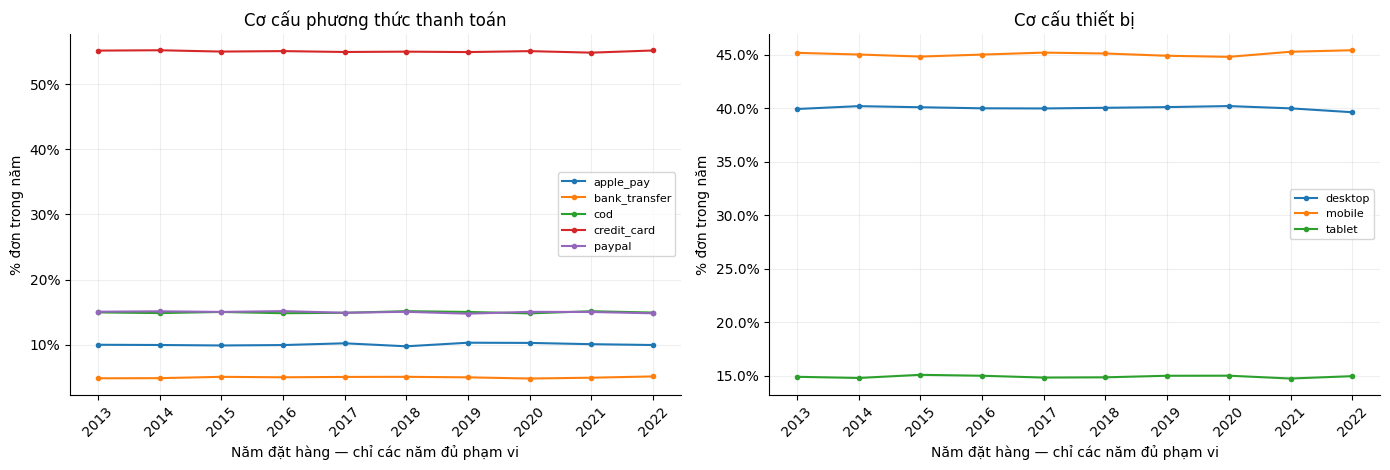

**Quan sát:** biến động cơ cấu năm liền kề lớn nhất trong hai thuộc tính là payment_method / apple_pay, 2018→2019: 0,552 đpt (N=69.510→41.601). **Ý nghĩa:** cơ cấu khá ổn định trong phạm vi quan sát, dù quy mô đơn giữa năm có thể khác nhiều. **Giới hạn:** đây là dữ liệu hồi cứu của các đơn đặt trong năm, không phải diễn biến giao dịch thanh toán theo ngày. **Cần làm rõ:** thay đổi kênh, khả năng ghi nhận thiết bị và phạm vi mẫu trước khi giải thích cơ cấu.

In [35]:
years033=sorted(view033.year.unique())
annual_counts033={};annual_shares033={};annual_changes033={}
for dim in ['payment_method','device_type']:
    counts,shares=cross033(view033,'year',dim)
    counts=counts.reindex(index=years033)
    shares=shares.reindex(index=years033)
    annual_counts033[dim]=counts;annual_shares033[dim]=shares
    changes=shares.diff()
    eligible=pd.Series({y:bool(year_complete.loc[y] and year_complete.shift(1,fill_value=False).loc[y]) for y in years033})
    changes.loc[~eligible,:]=np.nan;annual_changes033[dim]=changes
    table=cross_display033(counts,shares,'Năm đặt — '+dim)
    table.insert(1,'Phạm vi lịch',['Đủ phạm vi ngày đặt' if year_complete.loc[y] else 'Chỉ 04/07–31/12' for y in table.index])
    with pd.option_context('display.max_columns',None):display(table)
endpoint033=[];largest_changes033=[]
for dim,shares in annual_shares033.items():
    for label in shares.columns:
        endpoint033.append({'Thuộc tính':dim,'Nhãn':label,'N đơn 2013':int(annual_counts033[dim].loc[2013].sum()),
            '% năm 2013':fmt(shares.at[2013,label],3),'N đơn 2022':int(annual_counts033[dim].loc[2022].sum()),
            '% năm 2022':fmt(shares.at[2022,label],3),'2022 − 2013 (đpt)':fmt(shares.at[2022,label]-shares.at[2013,label],3)})
    for y,row in annual_changes033[dim].iterrows():
        for label,delta in row.items():
            if pd.notna(delta):largest_changes033.append({'dimension':dim,'year':int(y),'label':label,'delta':float(delta),
                'previous_n':int(annual_counts033[dim].loc[y-1].sum()),'n':int(annual_counts033[dim].loc[y].sum())})
with pd.option_context('display.max_columns',None):display(pd.DataFrame(endpoint033))
largest_changes033=sorted(largest_changes033,key=lambda r:(-abs(r['delta']),r['year'],r['dimension'],r['label']))
display(pd.DataFrame([{'Thuộc tính':r['dimension'],'Năm trước → hiện tại':str(r['year']-1)+' → '+str(r['year']),
    'Nhãn':r['label'],'N đơn trước':r['previous_n'],'N đơn hiện tại':r['n'],'Chênh lệch (đpt)':fmt(r['delta'],3)}
    for r in largest_changes033[:8]]))
fig,axes=plt.subplots(1,2,figsize=(14,4.8))
for ax,(dim,shares) in zip(axes,annual_shares033.items()):
    plot_data=shares.loc[2013:2022]
    for label in plot_data.columns:ax.plot(plot_data.index,plot_data[label],marker='o',ms=3,label=label)
    ax.set(title='Cơ cấu '+('phương thức thanh toán' if dim=='payment_method' else 'thiết bị'),
        xlabel='Năm đặt hàng — chỉ các năm đủ phạm vi',ylabel='% đơn trong năm',xticks=range(2013,2023))
    ax.yaxis.set_major_formatter(PercentFormatter(100));ax.grid(alpha=.2);ax.tick_params(axis='x',rotation=45)
    ax.legend(fontsize=8)
fig.tight_layout();display(fig);plt.close(fig)
peak_change033=largest_changes033[0]
display(Markdown(f'**Quan sát:** biến động cơ cấu năm liền kề lớn nhất trong hai thuộc tính là '
    f'{peak_change033["dimension"]} / {peak_change033["label"]}, {peak_change033["year"]-1}→{peak_change033["year"]}: '
    f'{fmt(peak_change033["delta"],3)} đpt (N={fmt(peak_change033["previous_n"])}→{fmt(peak_change033["n"])}). '
    '**Ý nghĩa:** cơ cấu khá ổn định trong phạm vi quan sát, dù quy mô đơn giữa năm có thể khác nhiều. '
    '**Giới hạn:** đây là dữ liệu hồi cứu của các đơn đặt trong năm, không phải diễn biến giao dịch thanh toán theo ngày. '
    '**Cần làm rõ:** thay đổi kênh, khả năng ghi nhận thiết bị và phạm vi mẫu trước khi giải thích cơ cấu.'))


### Nhận xét tổng hợp và câu hỏi dành cho NV03.4

**Đã xác minh:** số đơn, khóa, thuộc tính ghi nhận, tiền cấp đơn và cơ cấu đều được kiểm tra bảo toàn. Payment=Net mô tả tính nhất quán của bộ dữ liệu.

**Nhận xét được hỗ trợ:** phương thức dẫn đầu tổng tiền cần đọc cùng tỷ trọng đơn và tiền mỗi đơn; khác biệt cơ cấu trạng thái của COD đáng kiểm tra thêm. Cơ cấu phương thức giữa thiết bị và thay đổi cơ cấu theo năm có biên độ nhỏ trong mẫu hiện tại. Số khách theo nhóm chồng lặp.

**Chưa chứng minh:** thanh toán đã thành công/thực thu, COD đã thu tiền khi delivered, thiết bị/phương thức gây thay đổi giá trị đơn, nguyên nhân khác biệt hoặc tác động chiến dịch. Chưa đề xuất đổi chính sách thanh toán.

**Cần làm rõ ở NV03.4 (chỉ ghi câu hỏi, chưa triển khai):** định nghĩa trạng thái và thời điểm trích xuất; lịch sử sự kiện/khóa giao dịch; ý nghĩa payment_value và installments; việc một đơn có nhiều giao dịch/phương thức; trường hợp cuối kỳ chưa đủ thời gian quan sát; đơn vị tiền, thời điểm quyết toán và cơ chế đối soát. Chi tiết hoàn tiền để NV04.


### Kiểm chứng độc lập, ví dụ nhỏ và bảo toàn

Tái đọc orders/payments bằng csv.DictReader; dùng Counter, set, dict và Decimal thay cho Pandas JOIN/groupby để đối chiếu **mọi ô** của các bảng cơ cấu, tiền từng đơn và các tổng theo nhóm. Tiền hàng từng đơn kế thừa dict/Decimal độc lập đã dựng từ order_items ở NV03.1. Đối chiếu mean/median, tỷ trọng, số khách riêng từng nhóm và thay đổi năm.

Ví dụ giả lập có khách nhiều đơn, nhiều phương thức/thiết bị, một đơn nhiều dòng hàng và nhiều payment (cùng/khác phương thức), không payment, tiền 0 và tiền không hợp lệ. Kiểm thử khóa lỗi và biên ±0,05. Ví dụ không phải dữ liệu thật, không đưa vào tổng phân tích.

Số đếm/tổng Decimal phải khớp chính xác; phép chia Decimal cho mean/tỷ lệ cho phép sai số 10⁻¹⁸; tỷ lệ float cho phép 10⁻¹⁰ đpt. Mục không đủ nguồn kiểm tra tách **Không áp dụng**, không tính đạt. Giữ nguyên 45 ô cũ; chạy toàn bộ code theo thứ tự trên hai kernel mới và so kết quả cũ trước khi lưu nguyên bản.


In [36]:
# Oracle độc lập: CSV + Counter/set/dict, không dùng groupby hoặc JOIN để tính lại.
native_orders033={r['order_id']:r for r in csv_rows(PATHS['orders'])}
native_pay033=defaultdict(lambda:{'rows':0,'value':ZERO,'methods':set()})
for r in csv_rows(PATHS['payments']):
    t=native_pay033[r['order_id']];t['rows']+=1;t['value']+=Decimal(r['payment_value']);t['methods'].add(r['payment_method'])
oracle033={};oracle_cross033={};oracle_annual033={}
for dim in ['payment_method','device_type']:
    groups=defaultdict(lambda:{'orders':0,'customers':set(),'gross':ZERO,'discount':ZERO,'net':ZERO,'nets':[]})
    cross_counts=Counter();annual_counts=Counter()
    for oid,r in native_orders033.items():
        label=r[dim];t=groups[label];t['orders']+=1;t['customers'].add(r['customer_id'])
        for f in MONEY033:t[f]+=native[oid][f]
        t['nets'].append(native[oid]['net'])
        cross_counts[(label,r['order_status'])]+=1
        annual_counts[(datetime.strptime(r['order_date'],'%Y-%m-%d').year,label)]+=1
    oracle033[dim]=groups;oracle_cross033[dim]=cross_counts;oracle_annual033[dim]=annual_counts
oracle_dp033=Counter((r['device_type'],r['payment_method']) for r in native_orders033.values())

fxo033=pd.DataFrame([('01','A','delivered','credit_card','mobile'),
    ('2','A','cancelled','cod','desktop'),('3','B','created','paypal','tablet'),
    ('4','B','paid','cod','mobile'),('5','C','returned','credit_card','desktop')],
    columns=['order_id','customer_id','order_status','payment_method','device_type'])
fxi033=pd.DataFrame([('01',2,10,3),('01',1,20,2),('2',3,5,0),('3',1,0,0),
    ('4',1,12,2),('5',1,9,0)],columns=['order_id','quantity','unit_price','discount_amount'])
for f in ['quantity','unit_price','discount_amount']:fxi033[f]=fxi033[f].map(Decimal)
fxp033=pd.DataFrame([('01','credit_card','10'),('01','credit_card','25'),('2','cod','5'),
    ('2','paypal','10'),('3','paypal','0'),('5','credit_card','bad')],
    columns=['order_id','payment_method','payment_value'])
fxpay033=aggregate_payments033(fxo033[['order_id']],fxp033)
fxlines033=fxi033.assign(gross=fxi033.quantity*fxi033.unit_price,discount=fxi033.discount_amount).groupby('order_id').agg(
    gross=('gross','sum'),discount=('discount','sum'))
fx033=fxo033.merge(fxlines033,on='order_id',validate='one_to_one').merge(fxpay033,on='order_id',how='left',validate='one_to_one')
fx033['net']=fx033.gross-fx033.discount
fx033['n_payment_rows']=fx033.n_payment_rows.fillna(0).astype(int)
fx033['comparison_class']=[difference_class033(difference033(n,p)) for n,p in zip(fx033.net,fx033.payment_total)]
fxsummary033=summarize033(fx033,'payment_method')
display(Markdown('**Ví dụ giả lập:** 01 có Net=35 và hai payment cùng phương thức; 2 có Net=15 và hai phương thức; '
    '3 có tiền 0; 4 không có payment (không điền 0); 5 có chuỗi tiền sai nên tổng payment để thiếu.'))
with pd.option_context('display.max_columns',None):display(fx033)
display(summary_display033(fxsummary033,'phương thức — ví dụ giả lập'))
# Đáp án được tính tay/dict, độc lập với nhóm Pandas.
fxexpected033={'credit_card':(2,2,Decimal(49),Decimal(5),Decimal(44),Decimal(22)),
    'cod':(2,2,Decimal(27),Decimal(2),Decimal(25),Decimal('12.5')),
    'paypal':(1,1,ZERO,ZERO,ZERO,ZERO)}
fxbyid033=fx033.set_index('order_id')


**Ví dụ giả lập:** 01 có Net=35 và hai payment cùng phương thức; 2 có Net=15 và hai phương thức; 3 có tiền 0; 4 không có payment (không điền 0); 5 có chuỗi tiền sai nên tổng payment để thiếu.

,order_id,customer_id,order_status,payment_method,device_type,gross,discount,n_payment_rows,n_valid_values,payment_total,payment_methods,net,comparison_class
0,01,A,delivered,credit_card,mobile,40,5,2,2.0,35,"(credit_card,)",35,Khớp chính xác
1,2,A,cancelled,cod,desktop,15,0,2,2.0,15,"(cod, paypal)",15,Khớp chính xác
2,3,B,created,paypal,tablet,0,0,1,1.0,0,"(paypal,)",0,Khớp chính xác
3,4,B,paid,cod,mobile,12,2,0,NaN,NaN,NaN,10,Thiếu cặp đối chiếu
4,5,C,returned,credit_card,desktop,9,0,1,0.0,None,"(credit_card,)",9,Thiếu cặp đối chiếu


,Nhóm phương thức — ví dụ giả lập,Số đơn,% đơn,Khách phân biệt trong nhóm,Gross (triệu ĐVT),Discount (triệu ĐVT),Net (triệu ĐVT),% Net,Mean Net/đơn (ĐVT),Median Net/đơn (ĐVT),Discount/Gross
0,cod,2,"40,00%",2,"0,00","0,00","0,00","36,23%","12,50","12,50","7,41%"
1,credit_card,2,"40,00%",2,"0,00","0,00","0,00","63,77%","22,00","22,00","10,20%"
2,paypal,1,"20,00%",1,"0,00","0,00","0,00","0,00%","0,00","0,00",—


In [37]:
checks033=[]
def check033(name,condition):
    ok=bool(condition)
    checks033.append({'Kiểm chứng NV03.3':name,'Trạng thái':'Đạt' if ok else 'Không đạt','Phạm vi/lý do':'Áp dụng'})
    assert ok,name
def na033(name,reason):
    checks033.append({'Kiểm chứng NV03.3':name,'Trạng thái':'Không áp dụng','Phạm vi/lý do':reason})

check033('Cấu trúc thật và SHA-256 hai nguồn khớp V02',
    all(list(raw033[n].columns)==expected_columns[n] and digest(PATHS[n])==v02['sources'][n]['sha256'] for n in raw033))
check033('NULL/chuỗi trắng, khóa orders duy nhất, ngày và nhãn dùng được',
    inventory033[['NULL','Chuỗi trắng']].eq(0).all().all()
    and o033.order_id.is_unique and view033.date.notna().all()
    and set(o033.payment_method)==set(p033.payment_method))
check033('Payment số hữu hạn, không âm; installments nguyên dương trong nguồn',
    payment_parsed033.notna().all() and payment_parsed033.ge(0).all()
    and installments033.notna().all() and installments033.gt(0).all()
    and all(v==v.to_integral_value() for v in installments033))
check033('Tổng đơn khớp CSV độc lập, NV03.1 và V02',
    len(view033)==len(o033)==len(native_orders033)==n_orders==v02['metrics']['orders_rows'])
check033('JOIN một dòng/đơn, bảo toàn tập mã, Gross/Discount/Net',
    view033.order_id.is_unique and set(view033.order_id)==set(o033.order_id)
    and all(sum(view033[f],ZERO)==totals[f] for f in MONEY033))
check033('Cardinality payment/số dòng/đơn, không mồ côi, không nhân số tiền',
    orphans033==0 and int(view033.n_payment_rows.sum())==len(p033)
    and all(r.n_payment_rows==native_pay033[r.order_id]['rows']
        and r.payment_total==native_pay033[r.order_id]['value']
        and set(r.payment_methods)==native_pay033[r.order_id]['methods'] for r in view033.itertuples()))
check033('Phương thức orders/payments khớp từng dòng trong dữ liệu hiện tại',
    method_mismatch033==sum(r['payment_method']!=native_orders033[r['order_id']]['payment_method']
        for r in csv_rows(PATHS['payments']))==0)
check033('Thuộc tính khách/phương thức/thiết bị/năm đúng CSV từng đơn',
    all(r.customer_id==native_orders033[r.order_id]['customer_id']
        and r.payment_method==native_orders033[r.order_id]['payment_method']
        and r.device_type==native_orders033[r.order_id]['device_type']
        and r.year==datetime.strptime(native_orders033[r.order_id]['order_date'],'%Y-%m-%d').year
        for r in view033.itertuples()))
check033('Tổng số đơn theo phương thức và thiết bị bảo toàn',
    int(method033.orders.sum())==int(device033.orders.sum())==len(view033))
for dim,summary in [('payment_method',method033),('device_type',device033)]:
    groups=oracle033[dim]
    check033(dim+': mọi số đơn/khách/tổng tiền nhóm khớp dict/set độc lập',
        set(summary.index)==set(groups) and all(r.orders==groups[label]['orders']
            and r.customers==len(groups[label]['customers'])
            and all(r[f]==groups[label][f] for f in MONEY033) for label,r in summary.iterrows()))
    check033(dim+': tổng Gross/Discount/Net khớp V02 chính xác, không dùng dung sai',
        all(sum(summary[f],ZERO)==v02['metrics'][f] for f in MONEY033))
    check033(dim+': mean/median, tỷ trọng đơn/Net và Discount/Gross đúng mẫu số',
        all(abs(r.mean_net-groups[label]['net']/groups[label]['orders'])<=Decimal('1e-18')
            and r.median_net==statistics.median(groups[label]['nets'])
            and abs(r.order_share-pct(groups[label]['orders'],len(native_orders033)))<=Decimal('1e-18')
            and abs(r.net_share-pct(groups[label]['net'],payment_totals033['net']))<=Decimal('1e-18')
            and abs(r.discount_rate-pct(groups[label]['discount'],groups[label]['gross']))<=Decimal('1e-18')
            for label,r in summary.iterrows())
        and abs(sum(summary.order_share,ZERO)-100)<=Decimal('1e-18')
        and abs(sum(summary.net_share,ZERO)-100)<=Decimal('1e-18'))
    check033(dim+': không cộng khách chồng lặp; số khách từng nhóm và hợp tập đúng',
        set.union(*(g['customers'] for g in groups.values()))==set(view033.customer_id)
        and all(summary.at[k,'customers']==len(g['customers']) for k,g in groups.items())
        and view033.customer_id.nunique()==n_customers_with_orders)

def compare_cross033(counts,shares,oracle):
    return (int(counts.to_numpy().sum())==len(view033)
        and all(int(counts.at[a,b])==oracle[(a,b)] for a in counts.index for b in counts.columns)
        and all(math.isclose(shares.at[a,b],100*oracle[(a,b)]/sum(oracle[(a,k)] for k in counts.columns),
            abs_tol=1e-10,rel_tol=0) for a in counts.index for b in counts.columns)
        and np.allclose(shares.sum(axis=1),100,rtol=0,atol=1e-10))
check033('Phương thức × trạng thái: từng ô và tỷ trọng trong hàng đúng oracle',
    compare_cross033(ms033,msp033,oracle_cross033['payment_method']))
check033('Thiết bị × trạng thái: từng ô và tỷ trọng trong hàng đúng oracle',
    compare_cross033(ds033,dsp033,oracle_cross033['device_type']))
check033('Thiết bị × phương thức: từng ô và tỷ trọng trong hàng đúng oracle',
    compare_cross033(dp033,dpp033,oracle_dp033))
check033('Các biên bảng chéo khớp số đơn phương thức/thiết bị/trạng thái',
    ms033.sum(axis=1).to_dict()==method033.orders.to_dict()
    and dp033.sum(axis=0).to_dict()==method033.orders.to_dict()
    and dp033.sum(axis=1).to_dict()==device033.orders.to_dict()
    and ms033.sum().to_dict()==ds033.sum().to_dict()==dict(native_status))
check033('Tiền cấp đơn không NULL/âm/không hữu hạn; Net=Gross−Discount',
    all(view033[f].notna().all() and all(v.is_finite() and v>=0 for v in view033[f]) for f in MONEY033)
    and view033.net.eq(view033.gross-view033.discount).all())
check033('Mọi Δ và phân loại Payment−Net khớp phép tính Decimal độc lập',
    all(r.delta==native_pay033[r.order_id]['value']-native[r.order_id]['net']
        and r.comparison_class==difference_class033(native_pay033[r.order_id]['value']-native[r.order_id]['net'])
        for r in view033.itertuples())
    and int(payment_counts033.sum())==len(view033))
check033('Tổng payment và tổng Δ bảo toàn/khớp V02',
    payment_totals033['payment']==v02['metrics']['payment']==sum((r['value'] for r in native_pay033.values()),ZERO)
    and sum(finite_delta033,ZERO)==payment_totals033['payment']-payment_totals033['net'])


In [38]:
native_diff_groups033=defaultdict(Counter)
for oid,r in native_orders033.items():
    d=native_pay033[oid]['value']-native[oid]['net']
    native_diff_groups033[(r['payment_method'],r['order_status'])][difference_class033(d)]+=1
check033('Mọi ô phân bố sai lệch phương thức × trạng thái bảo toàn/đúng oracle',
    sum(r['N đơn'] for r in diff_groups033)==len(view033)
    and all(r['N đơn']==sum(native_diff_groups033[(r['Phương thức'],r['Trạng thái'])].values())
        and all(r[shown]==native_diff_groups033[(r['Phương thức'],r['Trạng thái'])][category]
            for shown,category in [('Khớp chính xác','Khớp chính xác'),('Khác 0, trong 0,05','Khác 0, trong 0,05'),
                ('Vượt 0,05','Vượt 0,05'),('Thiếu cặp','Thiếu cặp đối chiếu')]) for r in diff_groups033))
for dim in annual_counts033:
    counts=annual_counts033[dim];shares=annual_shares033[dim];oc=oracle_annual033[dim]
    check033(dim+': cơ cấu năm từ order_date, mọi ô và tỷ lệ khớp Counter',
        int(counts.to_numpy().sum())==len(view033)
        and all(int(counts.at[y,k])==oc[(y,k)]
            and math.isclose(shares.at[y,k],100*oc[(y,k)]/sum(oc[(y,j)] for j in counts.columns),
                abs_tol=1e-10,rel_tol=0) for y in counts.index for k in counts.columns))
    check033(dim+': đpt đúng cặp đủ lịch, 2012/2013 để thiếu; mốc 2013→2022 đúng',
        annual_changes033[dim].loc[[2012,2013]].isna().all().all()
        and all(math.isclose(annual_changes033[dim].at[y,k],
            100*oc[(y,k)]/sum(oc[(y,j)] for j in counts.columns)
            -100*oc[(y-1,k)]/sum(oc[(y-1,j)] for j in counts.columns),
            abs_tol=1e-10,rel_tol=0) for y in range(2014,2023) for k in counts.columns))
independent_changes033=[]
for dim,oc in oracle_annual033.items():
    labels=annual_counts033[dim].columns
    for y in range(2014,2023):
        for label in labels:
            d=100*oc[(y,label)]/sum(oc[(y,k)] for k in labels)-100*oc[(y-1,label)]/sum(oc[(y-1,k)] for k in labels)
            independent_changes033.append((dim,y,label,d))
independent_changes033.sort(key=lambda r:(-abs(r[3]),r[1],r[0],r[2]))
check033('Xếp hạng biến động năm/đồng hạng đúng oracle',
    [(r['dimension'],r['year'],r['label']) for r in largest_changes033[:8]]
        ==[(d,y,k) for d,y,k,v in independent_changes033[:8]])
check033('Ví dụ nhỏ: nhiều đơn/khách, nhiều phương thức/thiết bị; tiền và khách theo nhóm đúng tính tay',
    len(fx033)==len(fxo033)==5 and fx033.order_id.is_unique and fx033.customer_id.nunique()==3
    and all((int(fxsummary033.at[k,'orders']),int(fxsummary033.at[k,'customers']),
        fxsummary033.at[k,'gross'],fxsummary033.at[k,'discount'],fxsummary033.at[k,'net'],
        fxsummary033.at[k,'median_net'])==v for k,v in fxexpected033.items())
    and int(fxsummary033.customers.sum())==5 and fx033.customer_id.nunique()==3)
check033('Ví dụ nhiều payment cùng/khác phương thức không nhân đơn/tiền hoặc chọn first',
    fxbyid033.at['01','n_payment_rows']==2 and fxbyid033.at['01','net']==35
    and fxbyid033.at['01','payment_total']==35 and fxbyid033.at['01','payment_methods']==('credit_card',)
    and fxbyid033.at['2','n_payment_rows']==2 and fxbyid033.at['2','payment_total']==15
    and fxbyid033.at['2','payment_methods']==('cod','paypal') and sum(fx033.net,ZERO)==69)
check033('Ví dụ thiếu payment khác tiền 0; chuỗi sai không được cộng bỏ qua',
    fxbyid033.at['3','payment_total']==0 and fxbyid033.at['3','comparison_class']=='Khớp chính xác'
    and fxbyid033.at['4','n_payment_rows']==0 and pd.isna(fxbyid033.at['4','payment_total'])
    and fxbyid033.at['4','comparison_class']=='Thiếu cặp đối chiếu'
    and pd.isna(fxbyid033.at['5','payment_total']) and fxbyid033.at['5','n_valid_values']==0)
bad_mix033=pd.concat([fxp033,pd.DataFrame([('01','credit_card','NaN')],columns=fxp033.columns)],ignore_index=True)
bad_agg033=aggregate_payments033(fxo033[['order_id']],bad_mix033).set_index('order_id')
check033('Ví dụ một dòng sai giữa nhiều dòng hợp lệ: tổng đơn để thiếu',
    pd.isna(bad_agg033.at['01','payment_total']) and bad_agg033.at['01','n_payment_rows']==3
    and bad_agg033.at['01','n_valid_values']==2
    and all(exact_decimal(s) is None for s in ['NaN','Infinity','bad']))
check033('Biên dung sai Decimal ±0,05; mẫu số 0/thiếu để trống',
    [difference_class033(Decimal(s)) for s in ['0','.0499','.05','-.05','.0501','-.0501']]
        ==['Khớp chính xác','Khác 0, trong 0,05','Khác 0, trong 0,05','Khác 0, trong 0,05','Vượt 0,05','Vượt 0,05']
    and difference_class033(None)=='Thiếu cặp đối chiếu' and pct(1,0) is None and divide(1,0) is None
    and fxsummary033.at['paypal','discount_rate'] is None)
blocked033=[]
for case in ['orphan','duplicate_orders','null_payment_key','blank_payment_key']:
    oo=fxo033[['order_id']].copy();pp=fxp033.copy()
    if case=='orphan':pp.loc[0,'order_id']='unknown'
    elif case=='duplicate_orders':oo=pd.concat([oo,oo.iloc[:1]],ignore_index=True)
    elif case=='null_payment_key':pp.loc[0,'order_id']=None
    else:pp.loc[0,'order_id']=' '
    try:aggregate_payments033(oo,pp);blocked033.append(False)
    except AssertionError:blocked033.append(True)
check033('Ví dụ khóa mồ côi/trùng/NULL/trắng chặn trước JOIN',all(blocked033))
check033('NV03.1 và NV03.2 vẫn đạt các kiểm chứng áp dụng',
    len(verification)==32 and all(r['Đạt'] for r in verification)
    and len(shipping_applied)==27 and all(r['Trạng thái']=='Đạt' for r in shipping_applied)
    and len(shipping_not_applicable)==5)
prefix033=load_notebook_for_audit(TARGET)['cells'][:45]
check033('45 ô gốc NV03.1–NV03.2 giữ nguyên Markdown/code/output đã lưu',
    hashlib.sha256(json.dumps(prefix033,ensure_ascii=False,sort_keys=True).encode()).hexdigest()=='a7762539329199932f9ce361c07e1f0eafb2f6a9780dbbe7a8033587c8de43e3')
check033('SHA-256 mọi file khác, gồm NV01/NV02/raw/V01–V09/untracked không đổi',
    protected_snapshot()==protected_before)
na033('Xác minh thực thu/quyết toán/thất bại giao dịch','Không có trạng thái giao dịch, chứng từ thu hoặc quyết toán')
na033('Xác minh payment_value là số tiền sau hoàn','Không đủ định nghĩa/chứng từ; chưa mở phân tích refund (NV04)')
na033('Cơ cấu theo ngày thanh toán hoặc lịch sử chuyển trạng thái','Payments không có ngày giao dịch; orders không có lịch sử trạng thái')
na033('Đếm giao dịch phân biệt bằng mã payment riêng','Nguồn không có payment_id; chỉ xác minh số dòng và order_id')
with pd.option_context('display.max_rows',None,'display.max_colwidth',None):display(pd.DataFrame(checks033))


,Kiểm chứng NV03.3,Trạng thái,Phạm vi/lý do
0,Cấu trúc thật và SHA-256 hai nguồn khớp V02,Đạt,Áp dụng
1,"NULL/chuỗi trắng, khóa orders duy nhất, ngày và nhãn dùng được",Đạt,Áp dụng
2,"Payment số hữu hạn, không âm; installments nguyên dương trong nguồn",Đạt,Áp dụng
3,"Tổng đơn khớp CSV độc lập, NV03.1 và V02",Đạt,Áp dụng
4,"JOIN một dòng/đơn, bảo toàn tập mã, Gross/Discount/Net",Đạt,Áp dụng
5,"Cardinality payment/số dòng/đơn, không mồ côi, không nhân số tiền",Đạt,Áp dụng
6,Phương thức orders/payments khớp từng dòng trong dữ liệu hiện tại,Đạt,Áp dụng
7,Thuộc tính khách/phương thức/thiết bị/năm đúng CSV từng đơn,Đạt,Áp dụng
8,Tổng số đơn theo phương thức và thiết bị bảo toàn,Đạt,Áp dụng
9,payment_method: mọi số đơn/khách/tổng tiền nhóm khớp dict/set độc lập,Đạt,Áp dụng


In [39]:
passed033=sum(r['Trạng thái']=='Đạt' for r in checks033)
failed033=sum(r['Trạng thái']=='Không đạt' for r in checks033)
na_count033=sum(r['Trạng thái']=='Không áp dụng' for r in checks033)
assert failed033==0
display(Markdown(f'''**Hoàn thành chỉ NV03.3:** {fmt(len(view033))} đơn, {len(method033)} phương thức,
{len(device033)} loại thiết bị. Gross {fmt(payment_totals033['gross'],2)}, Discount
{fmt(payment_totals033['discount'],2)}, Net {fmt(payment_totals033['net'],2)} ĐVT; khớp V02.
**{passed033} kiểm chứng đạt, {failed033} không đạt, {na_count033} không áp dụng** (tách riêng).
NV03.1 vẫn 32/32; NV03.2 vẫn 27/27 áp dụng và 5 không áp dụng.

Giữ nguyên 45 ô trước; hai lượt Restart Kernel → Run All được ghi trong metadata execution_validation.
Payment=Net chưa xác nhận thực thu; không có suy luận nhân quả hoặc đề xuất chính sách thanh toán.
Không thực hiện NV03.4–NV03.5/NV04–NV06, không tạo tệp phụ và không stage/commit/push.
'''))


**Hoàn thành chỉ NV03.3:** 646.945 đơn, 5 phương thức,
3 loại thiết bị. Gross 16.430.476.585,53, Discount
749.607.320,10, Net 15.680.869.265,43 ĐVT; khớp V02.
**39 kiểm chứng đạt, 0 không đạt, 4 không áp dụng** (tách riêng).
NV03.1 vẫn 32/32; NV03.2 vẫn 27/27 áp dụng và 5 không áp dụng.

Giữ nguyên 45 ô trước; hai lượt Restart Kernel → Run All được ghi trong metadata execution_validation.
Payment=Net chưa xác nhận thực thu; không có suy luận nhân quả hoặc đề xuất chính sách thanh toán.
Không thực hiện NV03.4–NV03.5/NV04–NV06, không tạo tệp phụ và không stage/commit/push.


# NV03.4 — Đối chiếu quy trình và tính nhất quán giữa các bảng

**Chỉ NV03.4:** bổ sung sau 65 ô NV03.1–NV03.3, giữ nguyên cả nội dung và kết quả đã lưu. Đối chiếu orders, shipments, payments và Gross/Discount/Net đã tổng hợp từ order_items; tham khảo V02/V03. Không mở phân tích returns/refunds, tồn kho, NV03.5 hoặc mô hình.

Đơn vị là **một order_id**, không phải dòng hàng/kiện/giao dịch. Tái sử dụng bảng cấp đơn của NV03.3; tổng hợp số dòng shipment rồi liên kết one_to_one. Nếu một đơn có nhiều dòng shipment thì giữ số dòng nhưng không chọn first/last để gán ngày hay phí; các mốc/phí cấp đơn để thiếu. Số lượng dòng bằng 0 là kết quả đếm, khác với tự điền ngày/tiền bằng 0.

**Ba khái niệm riêng:** (1) Net sau giảm giá, chưa trừ hoàn tiền; (2) payment_value ghi trong payments, tổng theo đơn; (3) tiền thực thu/đã quyết toán. Chỉ đối chiếu được (1) với (2). shipping_fee chỉ kiểm tra giá trị/hiện diện, chưa xác minh là chi phí, tiền đã thu hoặc thành phần Net; không cộng vào Payment hoặc tính lợi nhuận.

Ngày cuối orders là **ngày đặt hàng cuối quan sát**, chưa phải thời điểm trích xuất toàn hệ thống. Các mốc shipment là ngày ghi nhận, chưa xác nhận actual/planned. order_status là nhãn hiện có, chưa có lịch sử chuyển trạng thái. Không suy dựng vòng đời, SLA, nhân quả hoặc tự gọi hiện tượng khác thường là lỗi.


In [40]:
# Kế thừa tiền cấp đơn đã kiểm chứng, không JOIN dòng hàng với shipment/payment.
ship_text034=pd.read_csv(SHIP_PATH,dtype='string',encoding='utf-8-sig',skip_blank_lines=False)
base034=view033[['order_id','customer_id','date','year','order_status','payment_method','device_type',
    'gross','discount','net','payment_total','n_payment_rows']].rename(columns={'date':'order_date','payment_total':'payment_value'}).copy()

def build_cross034(base,shipment_source):
    assert base.order_id.notna().all() and base.order_id.is_unique
    assert not base.order_id.astype('string').str.fullmatch(r'\s*',na=False).any()
    assert shipment_source.order_id.notna().all() and shipment_source.order_id.isin(base.order_id).all()
    assert not shipment_source.order_id.astype('string').str.fullmatch(r'\s*',na=False).any()
    counts=shipment_source.groupby('order_id',sort=False).size().rename('n_shipments')
    # Đơn nhiều dòng không chọn một dòng đại diện để suy hoàn tất.
    single=shipment_source.loc[~shipment_source.order_id.duplicated(keep=False),
        ['order_id','ship_date','delivery_date','shipping_fee']].copy()
    single=single.rename(columns={'ship_date':'ship_date_text','delivery_date':'delivery_date_text','shipping_fee':'shipping_fee_text'})
    out=base.merge(counts,on='order_id',how='left',validate='one_to_one').merge(single,on='order_id',how='left',validate='one_to_one')
    out['n_shipments']=out.n_shipments.fillna(0).astype(int)
    out['has_shipment']=out.n_shipments.gt(0);out['has_payment']=out.n_payment_rows.gt(0)
    out['order_date']=parse_ship_date(out.order_date);assert out.order_date.notna().all()
    for f in ['ship_date','delivery_date']:out[f]=parse_ship_date(out[f+'_text'])
    out['shipping_fee']=out.shipping_fee_text.map(exact_decimal)
    for m,end,start in [('prep_days','ship_date','order_date'),('transit_days','delivery_date','ship_date'),
                        ('total_days','delivery_date','order_date')]:
        out[m]=(out[end]-out[start]).dt.days.astype('Int64')
    out['payment_delta']=pd.Series([difference033(n,p) for n,p in zip(out.net,out.payment_value)],index=out.index,dtype=object)
    return out

cross034=build_cross034(base034,ship_text034)
end034=cross034.order_date.max()
assert cross034.order_id.is_unique and len(cross034)==len(base034)
money034={f:sum(cross034[f],ZERO) for f in ['gross','discount','net','payment_value']}
with pd.option_context('display.max_columns',None):
    display(pd.DataFrame([{'Chỉ tiêu':f,'Bảng đối chiếu (ĐVT)':fmt(value,2),
        'NV03.1 (ĐVT)':fmt(totals['payment' if f=='payment_value' else f],2),
        'V02 (ĐVT)':fmt(v02['metrics']['payment' if f=='payment_value' else f],2),
        'Sai lệch V02 (ĐVT)':fmt(value-v02['metrics']['payment' if f=='payment_value' else f],2)} for f,value in money034.items()]))
    display(pd.DataFrame([{'Đơn gốc':len(base034),'Dòng sau JOIN':len(cross034),
        'order_id phân biệt':cross034.order_id.nunique(),'Có shipment':int(cross034.has_shipment.sum()),
        'Không shipment':int((~cross034.has_shipment).sum()),'Nhiều dòng shipment':int(cross034.n_shipments.gt(1).sum()),
        'Có payment':int(cross034.has_payment.sum()),'Đọc được phí (1 dòng)':int(cross034.shipping_fee.notna().sum()),
        'Phí âm':int(cross034.shipping_fee.dropna().lt(0).sum()),'Phí bằng 0':int(cross034.shipping_fee.dropna().eq(0).sum())}]))
display(Markdown(f'**Quan sát:** {fmt(len(cross034))} đơn duy nhất; tổng Gross/Discount/Net/Payment không đổi so với NV03.1/V02. '
    f'Có {fmt(int(cross034.has_shipment.sum()))} đơn có shipment, {fmt(int((~cross034.has_shipment).sum()))} đơn không có. '
    '**Ý nghĩa:** có thể đối chiếu thuộc tính mà không nhân tiền theo dòng chi tiết. '
    '**Giới hạn:** shipping_fee được giữ riêng; khớp số học chưa xác minh thực thu, vai trò phí hay hoàn tất quy trình. '
    '**Cần làm rõ:** định nghĩa các bảng lưu chứng từ, kế hoạch hay sự kiện.'))


,Chỉ tiêu,Bảng đối chiếu (ĐVT),NV03.1 (ĐVT),V02 (ĐVT),Sai lệch V02 (ĐVT)
0,gross,"16.430.476.585,53","16.430.476.585,53","16.430.476.585,53","0,00"
1,discount,"749.607.320,10","749.607.320,10","749.607.320,10","0,00"
2,net,"15.680.869.265,43","15.680.869.265,43","15.680.869.265,43","0,00"
3,payment_value,"15.680.869.265,43","15.680.869.265,43","15.680.869.265,43","0,00"


,Đơn gốc,Dòng sau JOIN,order_id phân biệt,Có shipment,Không shipment,Nhiều dòng shipment,Có payment,Đọc được phí (1 dòng),Phí âm,Phí bằng 0
0,646945,646945,646945,566067,80878,0,646945,566067,0,805


**Quan sát:** 646.945 đơn duy nhất; tổng Gross/Discount/Net/Payment không đổi so với NV03.1/V02. Có 566.067 đơn có shipment, 80.878 đơn không có. **Ý nghĩa:** có thể đối chiếu thuộc tính mà không nhân tiền theo dòng chi tiết. **Giới hạn:** shipping_fee được giữ riêng; khớp số học chưa xác minh thực thu, vai trò phí hay hoàn tất quy trình. **Cần làm rõ:** định nghĩa các bảng lưu chứng từ, kế hoạch hay sự kiện.

### NV03.4.2 — Trạng thái đơn và shipment: các trường hợp cần xác minh

Tái tính số đơn và tỷ lệ trên **toàn bộ đơn cùng trạng thái**. Nhóm trường hợp A/B/C lần lượt là delivered/returned/shipped không shipment; D là shipped có shipment và delivery_date đọc được; E tách riêng cancelled, created, paid không shipment. **Tên nhóm trường hợp A–E khác với mức độ bằng chứng A/B/C** ở phần phân loại cuối.

Các nhóm trường hợp dưới đây rời nhau trong mẫu hiện tại, nhưng không đại diện toàn bộ vấn đề có thể có. Phân bố order_date của A/B/C xem chi tiết từng ngày ở phần cuối kỳ; D/E xem theo năm và phạm vi ngày để tránh in hàng nghìn ngày. Không mặc định thiếu shipment là chưa giao hoặc có delivery_date là đã giao thực tế.


In [41]:
state034=cross034.groupby('order_status',sort=True).agg(n=('order_id','size'),with_ship=('has_shipment','sum'))
state034['without_ship']=state034.n-state034.with_ship
display(pd.DataFrame([{'Trạng thái':s,'N đơn trạng thái':fmt(r.n),'Có shipment':fmt(r.with_ship),
    'Không shipment':fmt(r.without_ship),'% không shipment/N trạng thái':fpct(pct(r.without_ship,r.n))}
    for s,r in state034.iterrows()]))
def cases034(frame):
    return {
        'A':frame.order_status.eq('delivered')&~frame.has_shipment,
        'B':frame.order_status.eq('returned')&~frame.has_shipment,
        'C':frame.order_status.eq('shipped')&~frame.has_shipment,
        'D':frame.order_status.eq('shipped')&frame.has_shipment&frame.delivery_date.notna(),
        **{'E_'+s:frame.order_status.eq(s)&~frame.has_shipment for s in ['cancelled','created','paid']}}
case_masks034=cases034(cross034)
case_status034={'A':'delivered','B':'returned','C':'shipped','D':'shipped',
    **{'E_'+s:s for s in ['cancelled','created','paid']}}
case_summary034=[];case_year034={}
for code,mask in case_masks034.items():
    group=cross034.loc[mask];s=case_status034[code];den=int(state034.at[s,'n'])
    case_summary034.append({'Nhóm trường hợp':code,'Trạng thái':s,'N đơn':len(group),
        'N toàn trạng thái':den,'% trong trạng thái':fpct(pct(len(group),den)),
        'Ngày đặt đầu':group.order_date.min().strftime('%d/%m/%Y') if len(group) else '—',
        'Ngày đặt cuối':group.order_date.max().strftime('%d/%m/%Y') if len(group) else '—',
        'Số ngày có trường hợp':group.order_date.nunique(),
        'Mức bằng chứng':'B — hiện tượng có thật, chưa có quy tắc xác nhận đúng/sai'})
    case_year034[code]=group.groupby(group.order_date.dt.year).size().reindex(years033,fill_value=0)
with pd.option_context('display.max_columns',None,'display.max_colwidth',None):display(pd.DataFrame(case_summary034))
case_year_counts034=pd.DataFrame(case_year034)
case_year_display034=case_year_counts034.copy()
for code in case_year_counts034:
    total=int(case_year_counts034[code].sum())
    case_year_display034[code]=[fmt(n)+' ('+fpct(pct(n,total))+')' for n in case_year_counts034[code]]
case_year_display034.index.name='Năm đặt — ô là đơn (% trong toàn nhóm trường hợp)'
with pd.option_context('display.max_columns',None):display(case_year_display034)
missing_states034=['delivered','returned','shipped']
focus_mask034=cross034.order_status.isin(missing_states034)
missing_focus034=cross034.loc[focus_mask034&~cross034.has_shipment]
display(Markdown(f'**Quan sát:** A/B/C có {fmt(sum(int(case_masks034[k].sum()) for k in ["A","B","C"]))} đơn thiếu shipment; '
    f'D có {fmt(int(case_masks034["D"].sum()))} đơn shipped có delivery_date đọc được. '
    '**Ý nghĩa:** cần đối chiếu định nghĩa nhãn, nghĩa mốc ngày và chính sách bắt buộc lưu shipment. '
    '**Giới hạn:** chưa gọi A/B/C là lỗi giao hàng, D là mâu thuẫn hay E là thiếu dữ liệu sai quy trình; '
    'một nhãn đơn không thay cho lịch sử xử lý. **Cần làm rõ:** delivery_date có thể là dự kiến không, nhãn cập nhật khi nào '
    'và mỗi loại đơn có bắt buộc một shipment không?'))


,Trạng thái,N đơn trạng thái,Có shipment,Không shipment,% không shipment/N trạng thái
0,cancelled,59.462,0,59.462,"100,00%"
1,created,7.275,0,7.275,"100,00%"
2,delivered,516.716,516.192,524,"0,10%"
3,paid,13.577,0,13.577,"100,00%"
4,returned,36.142,36.113,29,"0,08%"
5,shipped,13.773,13.762,11,"0,08%"


,Nhóm trường hợp,Trạng thái,N đơn,N toàn trạng thái,% trong trạng thái,Ngày đặt đầu,Ngày đặt cuối,Số ngày có trường hợp,Mức bằng chứng
0,A,delivered,524,516716,"0,10%",22/12/2022,31/12/2022,10,"B — hiện tượng có thật, chưa có quy tắc xác nhận đúng/sai"
1,B,returned,29,36142,"0,08%",23/12/2022,31/12/2022,9,"B — hiện tượng có thật, chưa có quy tắc xác nhận đúng/sai"
2,C,shipped,11,13773,"0,08%",23/12/2022,29/12/2022,6,"B — hiện tượng có thật, chưa có quy tắc xác nhận đúng/sai"
3,D,shipped,13762,13773,"99,92%",04/07/2012,29/12/2022,3512,"B — hiện tượng có thật, chưa có quy tắc xác nhận đúng/sai"
4,E_cancelled,cancelled,59462,59462,"100,00%",04/07/2012,31/12/2022,3824,"B — hiện tượng có thật, chưa có quy tắc xác nhận đúng/sai"
5,E_created,created,7275,7275,"100,00%",06/07/2012,31/12/2022,2954,"B — hiện tượng có thật, chưa có quy tắc xác nhận đúng/sai"
6,E_paid,paid,13577,13577,"100,00%",04/07/2012,31/12/2022,3480,"B — hiện tượng có thật, chưa có quy tắc xác nhận đúng/sai"


,A,B,C,D,E_cancelled,E_created,E_paid
Năm đặt — ô là đơn (% trong toàn nhóm trường hợp),,,,,,,
2012,"0 (0,00%)","0 (0,00%)","0 (0,00%)","664 (4,82%)","2.898 (4,87%)","316 (4,34%)","691 (5,09%)"
2013,"0 (0,00%)","0 (0,00%)","0 (0,00%)","1.479 (10,75%)","7.093 (11,93%)","808 (11,11%)","1.558 (11,48%)"
2014,"0 (0,00%)","0 (0,00%)","0 (0,00%)","1.672 (12,15%)","7.287 (12,25%)","842 (11,57%)","1.672 (12,31%)"
2015,"0 (0,00%)","0 (0,00%)","0 (0,00%)","1.672 (12,15%)","7.665 (12,89%)","822 (11,30%)","1.679 (12,37%)"
2016,"0 (0,00%)","0 (0,00%)","0 (0,00%)","1.668 (12,12%)","7.480 (12,58%)","834 (11,46%)","1.543 (11,36%)"
2017,"0 (0,00%)","0 (0,00%)","0 (0,00%)","1.552 (11,28%)","6.907 (11,62%)","714 (9,81%)","1.446 (10,65%)"
2018,"0 (0,00%)","0 (0,00%)","0 (0,00%)","1.423 (10,34%)","6.486 (10,91%)","682 (9,37%)","1.376 (10,13%)"
2019,"0 (0,00%)","0 (0,00%)","0 (0,00%)","872 (6,34%)","3.860 (6,49%)","451 (6,20%)","859 (6,33%)"
2020,"0 (0,00%)","0 (0,00%)","0 (0,00%)","670 (4,87%)","3.253 (5,47%)","351 (4,82%)","682 (5,02%)"


**Quan sát:** A/B/C có 564 đơn thiếu shipment; D có 13.762 đơn shipped có delivery_date đọc được. **Ý nghĩa:** cần đối chiếu định nghĩa nhãn, nghĩa mốc ngày và chính sách bắt buộc lưu shipment. **Giới hạn:** chưa gọi A/B/C là lỗi giao hàng, D là mâu thuẫn hay E là thiếu dữ liệu sai quy trình; một nhãn đơn không thay cho lịch sử xử lý. **Cần làm rõ:** delivery_date có thể là dự kiến không, nhãn cập nhật khi nào và mỗi loại đơn có bắt buộc một shipment không?

### NV03.4.3 — Tập thiếu shipment và phần cuối lịch sử đơn hàng

Mốc so sánh là **ngày đặt cuối quan sát**. Cửa sổ 10 ngày cuối gồm ngày cuối và 9 ngày trước, được xác định theo ngày lịch; kiểm tra riêng có trùng 22–31/12/2022 không. Khoảng cách = ngày đặt cuối − order_date, không phải thời gian chờ giao.

Bảng ngày hiển thị cả N mọi đơn và N đơn delivered/returned/shipped. Tỷ lệ thiếu tương ứng dùng đúng hai mẫu số; cancelled/created/paid có thể làm tỷ lệ toàn bộ khác đáng kể. Giữ ngày có N=0 và để tỷ lệ trống. So sánh trước cửa sổ, cửa sổ 10 ngày và một số nhóm ngày cuối giúp nhận diện mức tập trung. Các cửa sổ tóm tắt có phần chồng lặp, **không cộng các dòng**.

Sự tập trung cuối kỳ có thể phù hợp giả thuyết giới hạn quan sát/cập nhật, nhưng chưa chứng minh cắt phải, chưa biết thời điểm trích xuất và chưa xác nhận các ngày shipment là thực tế.


,Ngày đặt,Cách ngày cuối (ngày),N mọi đơn,Thiếu shipment mọi trạng thái,% thiếu/N mọi đơn,N delivered/returned/shipped,Thiếu delivered,Thiếu returned,Thiếu shipped,Thiếu trong ba trạng thái,% thiếu/N ba trạng thái
0,22/12/2022,9,82,18,"21,95%",67,3,0,0,3,"4,48%"
1,23/12/2022,8,76,32,"42,11%",53,7,1,1,9,"16,98%"
2,24/12/2022,7,77,24,"31,17%",68,13,1,1,15,"22,06%"
3,25/12/2022,6,69,31,"44,93%",63,24,1,0,25,"39,68%"
4,26/12/2022,5,101,59,"58,42%",88,42,2,2,46,"52,27%"
5,27/12/2022,4,108,86,"79,63%",94,66,4,2,72,"76,60%"
6,28/12/2022,3,164,152,"92,68%",133,113,4,4,121,"90,98%"
7,29/12/2022,2,143,136,"95,10%",119,104,7,1,112,"94,12%"
8,30/12/2022,1,106,106,"100,00%",93,85,8,0,93,"100,00%"
9,31/12/2022,0,74,74,"100,00%",68,67,1,0,68,"100,00%"


,Nhóm ngày,N mọi đơn,Thiếu mọi trạng thái,% thiếu/N mọi đơn,N ba trạng thái,Thiếu trong ba trạng thái,% thiếu/N ba trạng thái
0,Trước 10 ngày cuối,645945,80160,"12,41%",565785,0,"0,00%"
1,10 ngày cuối,1000,718,"71,80%",846,564,"66,67%"
2,7 ngày cuối,765,644,"84,18%",658,537,"81,61%"
3,3 ngày cuối,323,316,"97,83%",280,273,"97,50%"


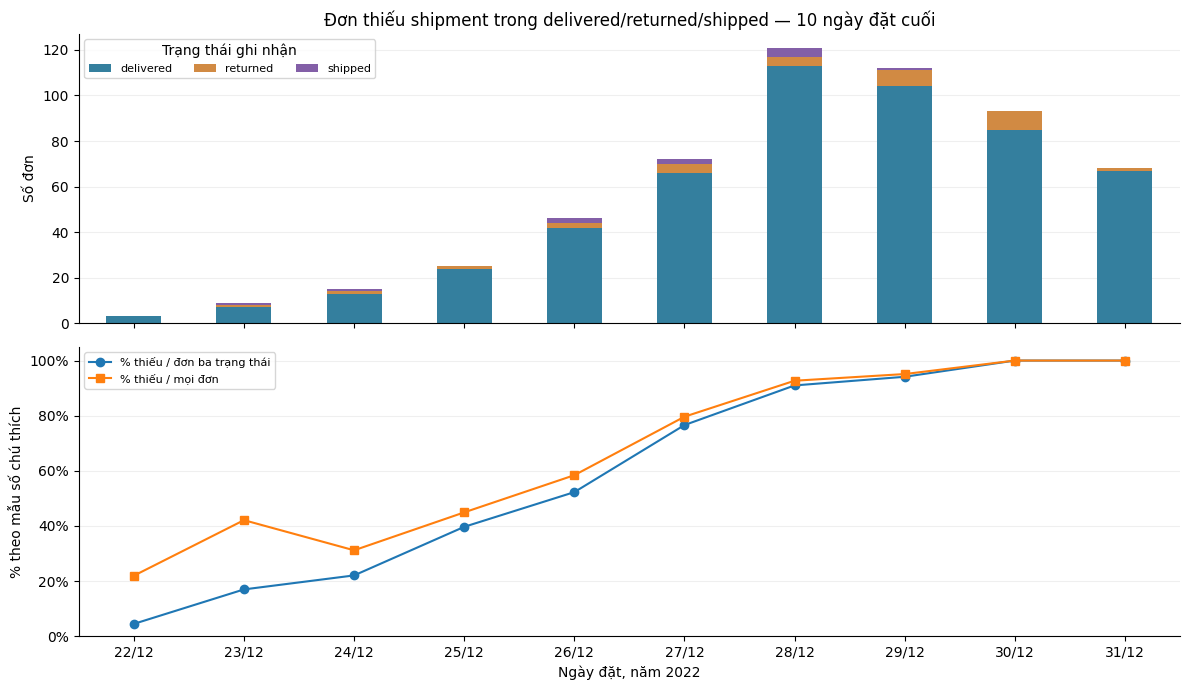

,Trường,N dòng,NULL nguồn,Không NULL nhưng không đọc được,Ngày đầu,Ngày cuối,Ngày cuối orders − max trường (ngày),Dòng sau ngày cuối orders
0,order_date,646945,0,0,04/07/2012,31/12/2022,0,0
1,ship_date,566067,0,0,04/07/2012,29/12/2022,2,0
2,delivery_date,566067,0,0,06/07/2012,31/12/2022,0,0


**Quan sát:** 564 trường hợp đều trong cửa sổ cuối: True. Trước cửa sổ: 0/565.785; 10 ngày cuối: 564/846 (66,67%). **Ý nghĩa:** hiện tượng tập trung mạnh vào cuối phạm vi order_date; không đánh đồng với mẫu số mọi trạng thái. **Giới hạn:** ngày cuối orders không xác nhận ngày trích xuất; max mốc shipment không đủ chứng minh ngày thực tế hay cắt phải. **Giả thuyết chưa xác minh:** giới hạn quan sát, lịch ghi nhận hoặc cập nhật nhãn có thể liên quan. **Cần bổ sung:** quy tắc trích xuất từng bảng, thời điểm cập nhật, định nghĩa mốc và theo dõi sau kỳ.

In [42]:
start_tail034=end034-pd.Timedelta(days=9)
daily034=cross034.assign(focus=focus_mask034,missing=~cross034.has_shipment,
    missing_focus=focus_mask034&~cross034.has_shipment).groupby('order_date').agg(
        all_n=('order_id','size'),all_missing=('missing','sum'),focus_n=('focus','sum'),focus_missing=('missing_focus','sum'))
tail_daily034=daily034.reindex(pd.date_range(start_tail034,end034,freq='D'),fill_value=0)
missing_by_day034=pd.crosstab(missing_focus034.order_date,missing_focus034.order_status).reindex(
    index=tail_daily034.index,columns=missing_states034,fill_value=0)
tail_display034=pd.DataFrame([{'Ngày đặt':f'{day:%d/%m/%Y}','Cách ngày cuối (ngày)':(end034-day).days,
    'N mọi đơn':int(r.all_n),'Thiếu shipment mọi trạng thái':int(r.all_missing),
    '% thiếu/N mọi đơn':fpct(pct(r.all_missing,r.all_n)),'N delivered/returned/shipped':int(r.focus_n),
    **{'Thiếu '+s:int(missing_by_day034.at[day,s]) for s in missing_states034},
    'Thiếu trong ba trạng thái':int(r.focus_missing),'% thiếu/N ba trạng thái':fpct(pct(r.focus_missing,r.focus_n))}
    for day,r in tail_daily034.iterrows()])
with pd.option_context('display.max_columns',None):display(tail_display034)
periods034=[
    ('Trước 10 ngày cuối',cross034.order_date.lt(start_tail034)),
    ('10 ngày cuối',cross034.order_date.between(start_tail034,end034)),
    ('7 ngày cuối',cross034.order_date.between(end034-pd.Timedelta(days=6),end034)),
    ('3 ngày cuối',cross034.order_date.between(end034-pd.Timedelta(days=2),end034))]
period_summary034=[]
for label,mask in periods034:
    g=cross034.loc[mask];f=g.loc[g.order_status.isin(missing_states034)]
    period_summary034.append({'Nhóm ngày':label,'N mọi đơn':len(g),'Thiếu mọi trạng thái':int((~g.has_shipment).sum()),
        '% thiếu/N mọi đơn':fpct(pct(int((~g.has_shipment).sum()),len(g))),
        'N ba trạng thái':len(f),'Thiếu trong ba trạng thái':int((~f.has_shipment).sum()),
        '% thiếu/N ba trạng thái':fpct(pct(int((~f.has_shipment).sum()),len(f)))})
with pd.option_context('display.max_columns',None):display(pd.DataFrame(period_summary034))
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True,gridspec_kw={'height_ratios':[1,1]})
missing_by_day034.plot.bar(stacked=True,ax=axes[0],color=['#347f9e','#d18a43','#835fa7'],rot=0)
axes[0].set(title='Đơn thiếu shipment trong delivered/returned/shipped — 10 ngày đặt cuối',ylabel='Số đơn')
axes[0].legend(title='Trạng thái ghi nhận',ncol=3,fontsize=8)
x=np.arange(len(tail_daily034))
axes[1].plot(x,tail_daily034.focus_missing.div(tail_daily034.focus_n.replace(0,np.nan))*100,
    marker='o',label='% thiếu / đơn ba trạng thái')
axes[1].plot(x,tail_daily034.all_missing.div(tail_daily034.all_n.replace(0,np.nan))*100,
    marker='s',label='% thiếu / mọi đơn')
axes[1].set(xticks=x,xticklabels=[f'{d:%d/%m}' for d in tail_daily034.index],xlabel='Ngày đặt, năm 2022',
    ylabel='% theo mẫu số chú thích',ylim=(0,105))
axes[1].yaxis.set_major_formatter(PercentFormatter(100));axes[1].legend(fontsize=8)
for ax in axes:ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();display(fig);plt.close(fig)
range_rows034=[]
for f,raw,parsed in [('order_date',orders.order_date,cross034.order_date),
                    ('ship_date',ship_records.ship_date,ship_records.ship_date_parsed),
                    ('delivery_date',ship_records.delivery_date,ship_records.delivery_date_parsed)]:
    range_rows034.append({'Trường':f,'N dòng':len(parsed),'NULL nguồn':int(raw.isna().sum()),
        'Không NULL nhưng không đọc được':int((raw.notna().to_numpy()&parsed.isna().to_numpy()).sum()),
        'Ngày đầu':parsed.min().strftime('%d/%m/%Y'),'Ngày cuối':parsed.max().strftime('%d/%m/%Y'),
        'Ngày cuối orders − max trường (ngày)':(end034-parsed.max()).days,
        'Dòng sau ngày cuối orders':int(parsed.gt(end034).sum())})
display(pd.DataFrame(range_rows034))
tail_all034=missing_focus034.order_date.between(start_tail034,end034).all()
before034=period_summary034[0];last034=period_summary034[1]
display(Markdown(f'**Quan sát:** {fmt(len(missing_focus034))} trường hợp đều trong cửa sổ cuối: {bool(tail_all034)}. '
    f'Trước cửa sổ: {fmt(before034["Thiếu trong ba trạng thái"])}/{fmt(before034["N ba trạng thái"])}; '
    f'10 ngày cuối: {fmt(last034["Thiếu trong ba trạng thái"])}/{fmt(last034["N ba trạng thái"])} '
    f'({last034["% thiếu/N ba trạng thái"]}). '
    '**Ý nghĩa:** hiện tượng tập trung mạnh vào cuối phạm vi order_date; không đánh đồng với mẫu số mọi trạng thái. '
    '**Giới hạn:** ngày cuối orders không xác nhận ngày trích xuất; max mốc shipment không đủ chứng minh ngày thực tế hay cắt phải. '
    '**Giả thuyết chưa xác minh:** giới hạn quan sát, lịch ghi nhận hoặc cập nhật nhãn có thể liên quan. '
    '**Cần bổ sung:** quy tắc trích xuất từng bảng, thời điểm cập nhật, định nghĩa mốc và theo dõi sau kỳ.'))


### NV03.4.4 — Thứ tự các mốc ngày và tổ hợp trạng thái

Kiểm tra số học các cặp có đủ dữ liệu: order_date ≤ ship_date, ship_date ≤ delivery_date và delivery_date − order_date. Âm, bằng 0, min/max chỉ mô tả **ngày lịch ghi nhận**; bằng 0 là cùng ngày, không phải 0 giờ. Giữ thiếu cặp riêng, không coi là vi phạm thứ tự hoặc điền 0.

Các khoảng ngày cực trị được tóm tắt kèm số đơn đồng hạng và phân bố theo trạng thái; không lặp lại bảng top đơn và biểu đồ thời gian của NV03.2. Chưa có tài liệu actual/planned hoặc SLA nên chưa đánh giá giao thực tế, đúng/chậm hạn hay chuỗi chuyển trạng thái.


In [43]:
intervals034={'prep_days':'ship_date − order_date','transit_days':'delivery_date − ship_date',
    'total_days':'delivery_date − order_date'}
date_summary034=[];date_state034=[]
for m,label in intervals034.items():
    v=cross034[m].dropna()
    date_summary034.append({'Cặp mốc ghi nhận':label,'N đủ cặp':len(v),'Thiếu cặp trên mọi đơn':int(cross034[m].isna().sum()),
        'Âm':int(v.lt(0).sum()),'Bằng 0':int(v.eq(0).sum()),'Dương':int(v.gt(0).sum()),
        'Min ngày':int(v.min()) if len(v) else None,'Max ngày':int(v.max()) if len(v) else None,
        'N bằng min':int(v.eq(v.min()).sum()) if len(v) else 0,'N bằng max':int(v.eq(v.max()).sum()) if len(v) else 0})
for s,g in cross034.groupby('order_status',sort=True):
    date_state034.append({'Trạng thái':s,'N đơn':len(g),'Có shipment':int(g.has_shipment.sum()),
        'Có ship_date đọc được':int(g.ship_date.notna().sum()),'Có delivery_date đọc được':int(g.delivery_date.notna().sum()),
        **{label+' — min/max (N âm; N=0)':('—' if g[m].notna().sum()==0 else
            f'{int(g[m].min())}/{int(g[m].max())} ({int(g[m].lt(0).sum())}; {int(g[m].eq(0).sum())})')
            for m,label in intervals034.items()}})
with pd.option_context('display.max_columns',None):
    display(pd.DataFrame(date_summary034))
    display(pd.DataFrame(date_state034))
display(Markdown(f'**Quan sát:** tổng {fmt(sum(int(cross034[m].lt(0).sum()) for m in intervals034))} cặp chênh ngày âm; '
    f'{fmt(int(cross034.prep_days.eq(0).sum()))} đơn có ship_date cùng ngày order_date. '
    f'Khoảng delivery−order đọc được nằm trong {fmt(cross034.total_days.min())}–{fmt(cross034.total_days.max())} ngày. '
    '**Ý nghĩa:** các cặp hiện có tuân theo thứ tự không giảm về mặt lịch. '
    '**Giới hạn:** thứ tự phù hợp không xác nhận sự kiện giao thực tế; shipped đi cùng delivery_date vẫn cần định nghĩa. '
    '**Cần làm rõ:** actual/planned, timestamp, múi giờ, thời điểm trạng thái và ngày cam kết trước khi đánh giá vận hành.'))


,Cặp mốc ghi nhận,N đủ cặp,Thiếu cặp trên mọi đơn,Âm,Bằng 0,Dương,Min ngày,Max ngày,N bằng min,N bằng max
0,ship_date − order_date,566067,80878,0,141993,424074,0,3,141993,141283
1,delivery_date − ship_date,566067,80878,0,0,566067,2,7,94299,94109
2,delivery_date − order_date,566067,80878,0,0,566067,2,10,23670,23502


,Trạng thái,N đơn,Có shipment,Có ship_date đọc được,Có delivery_date đọc được,ship_date − order_date — min/max (N âm; N=0),delivery_date − ship_date — min/max (N âm; N=0),delivery_date − order_date — min/max (N âm; N=0)
0,cancelled,59462,0,0,0,—,—,—
1,created,7275,0,0,0,—,—,—
2,delivered,516716,516192,516192,516192,0/3 (0; 129536),2/7 (0; 0),2/10 (0; 0)
3,paid,13577,0,0,0,—,—,—
4,returned,36142,36113,36113,36113,0/3 (0; 8992),2/7 (0; 0),2/10 (0; 0)
5,shipped,13773,13762,13762,13762,0/3 (0; 3465),2/7 (0; 0),2/10 (0; 0)


**Quan sát:** tổng 0 cặp chênh ngày âm; 141.993 đơn có ship_date cùng ngày order_date. Khoảng delivery−order đọc được nằm trong 2–10 ngày. **Ý nghĩa:** các cặp hiện có tuân theo thứ tự không giảm về mặt lịch. **Giới hạn:** thứ tự phù hợp không xác nhận sự kiện giao thực tế; shipped đi cùng delivery_date vẫn cần định nghĩa. **Cần làm rõ:** actual/planned, timestamp, múi giờ, thời điểm trạng thái và ngày cam kết trước khi đánh giá vận hành.

### NV03.4.5 — Payment và Net theo trạng thái đơn

Với mỗi nhãn order_status, đếm đơn, đơn có dòng payment, tổng Net và Payment, số khớp chính xác, khác 0 trong dung sai, vượt 0,05 và thiếu cặp. Tỷ trọng Payment dùng **tổng Payment toàn bộ trạng thái**, không phải tỷ lệ đơn hoặc xác suất thanh toán.

Cancelled/created/returned có payment_value chưa chứng minh đã thu, thu rồi hoàn hoặc sai dữ liệu. Delivered có payment_value cũng chưa chứng minh quyết toán. V02 xác minh công thức; V03 nêu giới hạn của snapshot trạng thái, thời điểm và quy tắc hoàn tiền. Chỉ kế thừa giới hạn V03, **không tái phân tích returns/refunds** và không lấy Payment − Refund làm thực thu.


In [44]:
payment_state034=[]
for s,g in cross034.groupby('order_status',sort=True):
    d=g.payment_delta.dropna();classes=g.payment_delta.map(difference_class033)
    net=sum(g.net,ZERO);pay=sum(g.payment_value.dropna(),ZERO)
    payment_state034.append({'status':s,'n':len(g),'has_payment':int(g.has_payment.sum()),
        'net':net,'payment':pay,'exact':int(classes.eq('Khớp chính xác').sum()),
        'within_nonzero':int(classes.eq('Khác 0, trong 0,05').sum()),
        'over':int(classes.eq('Vượt 0,05').sum()),'missing':int(classes.eq('Thiếu cặp đối chiếu').sum()),
        'payment_share':pct(pay,money034['payment_value']),'sum_delta':sum(d,ZERO)})
with pd.option_context('display.max_columns',None):
    display(pd.DataFrame([{'Trạng thái':r['status'],'N đơn':fmt(r['n']),'Có payment':fmt(r['has_payment']),
        'Net (ĐVT)':fmt(r['net'],2),'Payment (ĐVT)':fmt(r['payment'],2),'% tổng Payment':fpct(r['payment_share']),
        'Khớp chính xác':fmt(r['exact']),'Khác 0 trong 0,05':fmt(r['within_nonzero']),
        'Vượt 0,05':fmt(r['over']),'Thiếu cặp':fmt(r['missing']),'Tổng Δ (ĐVT)':fmt(r['sum_delta'],2)}
        for r in payment_state034]))
display(Markdown(f'**Quan sát:** {fmt(sum(r["exact"] for r in payment_state034))} đơn khớp chính xác, '
    'bao gồm cancelled, created và returned; bảng cho số tiền ghi nhận ở từng nhãn. '
    '**Ý nghĩa:** Payment phản ánh cùng giá trị số học với Net trong nguồn trên mọi trạng thái. '
    '**Giới hạn:** không có cột trạng thái thanh toán, ngày giao dịch hoặc quyết toán để xác minh tiền thực thu. '
    '**Cần làm rõ:** nguồn payment là giá trị đơn, yêu cầu thanh toán hay chứng từ thực hiện; đối soát ở cấp giao dịch ra sao?'))


,Trạng thái,N đơn,Có payment,Net (ĐVT),Payment (ĐVT),% tổng Payment,Khớp chính xác,"Khác 0 trong 0,05","Vượt 0,05",Thiếu cặp,Tổng Δ (ĐVT)
0,cancelled,59.462,59.462,"1.447.013.637,43","1.447.013.637,43","9,23%",59.462,0,0,0,"0,00"
1,created,7.275,7.275,"181.835.018,77","181.835.018,77","1,16%",7.275,0,0,0,"0,00"
2,delivered,516.716,516.716,"12.518.175.957,20","12.518.175.957,20","79,83%",516.716,0,0,0,"0,00"
3,paid,13.577,13.577,"330.627.096,24","330.627.096,24","2,11%",13.577,0,0,0,"0,00"
4,returned,36.142,36.142,"865.938.715,59","865.938.715,59","5,52%",36.142,0,0,0,"0,00"
5,shipped,13.773,13.773,"337.278.840,20","337.278.840,20","2,15%",13.773,0,0,0,"0,00"


**Quan sát:** 646.945 đơn khớp chính xác, bao gồm cancelled, created và returned; bảng cho số tiền ghi nhận ở từng nhãn. **Ý nghĩa:** Payment phản ánh cùng giá trị số học với Net trong nguồn trên mọi trạng thái. **Giới hạn:** không có cột trạng thái thanh toán, ngày giao dịch hoặc quyết toán để xác minh tiền thực thu. **Cần làm rõ:** nguồn payment là giá trị đơn, yêu cầu thanh toán hay chứng từ thực hiện; đối soát ở cấp giao dịch ra sao?

### NV03.4.6 — COD và non-COD: toàn kỳ, từng năm và cùng cơ cấu năm

COD = orders.payment_method == cod; **non-COD = tất cả phương thức ghi nhận còn lại**, không mang nghĩa trả trước hoặc đã thanh toán. Tỷ trọng cancelled/returned trong mỗi nhóm = số đơn mang nhãn / N mọi đơn cùng nhóm. Chênh lệch = tỷ trọng COD − non-COD, đơn vị **điểm phần trăm**, không phải tăng trưởng hay tác động nhân quả.

Giữ bảng toàn kỳ, nhưng so theo năm chỉ dùng 2013–2022 đủ phạm vi ngày đặt, vẫn nêu giới hạn vòng đời cuối kỳ. Đọc số đơn ở cả hai nhóm; không dùng nhóm nhỏ để suy kết luận chung.

Để kiểm tra vai trò cơ cấu năm, tính thêm tỷ trọng chuẩn hóa mô tả: với mỗi năm y, trọng số chung w_y = N mọi đơn năm y / N mọi đơn 2013–2022; tỷ trọng chuẩn hóa của mỗi nhóm = tổng w_y × tỷ trọng nhóm trong năm y. So với tỷ trọng gộp **cùng phạm vi 2013–2022**, không trộn với toàn kỳ có năm 2012. Đây chỉ là đặt hai nhóm vào cùng cơ cấu năm, **chưa kiểm soát các yếu tố khác và không phải ước lượng nhân quả**.


,Phạm vi,Nhóm,N đơn nhóm,Cancelled — đơn (%),Returned — đơn (%)
0,Toàn kỳ,COD,96.681,"15.468 (16,00%)","8.620 (8,92%)"
1,Toàn kỳ,non-COD,550.264,"43.994 (8,00%)","27.522 (5,00%)"
2,2013–2022,COD,91.941,"14.753 (16,05%)","8.176 (8,89%)"
3,2013–2022,non-COD,522.953,"41.811 (8,00%)","26.147 (5,00%)"


,Năm đặt,N COD,N non-COD,cancelled — COD đơn (%),returned — COD đơn (%),cancelled — non-COD đơn (%),returned — non-COD đơn (%),cancelled Δ (đpt),returned Δ (đpt)
0,2013,11494,65355,"1.852 (16,11%)","1.019 (8,87%)","5.241 (8,02%)","3.304 (5,06%)","8,093","3,810"
1,2014,11976,68669,"1.908 (15,93%)","1.039 (8,68%)","5.379 (7,83%)","3.445 (5,02%)","8,099","3,659"
2,2015,12411,70211,"2.040 (16,44%)","1.138 (9,17%)","5.625 (8,01%)","3.483 (4,96%)","8,425","4,209"
3,2016,12197,70050,"1.951 (16,00%)","1.122 (9,20%)","5.529 (7,89%)","3.533 (5,04%)","8,103","4,155"
4,2017,11320,64690,"1.767 (15,61%)","1.017 (8,98%)","5.140 (7,95%)","3.230 (4,99%)","7,664","3,991"
5,2018,10527,58983,"1.684 (16,00%)","896 (8,51%)","4.802 (8,14%)","2.907 (4,93%)","7,856","3,583"
6,2019,6250,35351,"1.017 (16,27%)","548 (8,77%)","2.843 (8,04%)","1.752 (4,96%)","8,230","3,812"
7,2020,5164,29717,"839 (16,25%)","472 (9,14%)","2.414 (8,12%)","1.478 (4,97%)","8,124","4,167"
8,2021,5226,29299,"842 (16,11%)","455 (8,71%)","2.307 (7,87%)","1.463 (4,99%)","8,238","3,713"
9,2022,5376,30628,"853 (15,87%)","470 (8,74%)","2.531 (8,26%)","1.552 (5,07%)","7,603","3,675"


,Nhãn trạng thái,COD gộp (%),non-COD gộp (%),Δ gộp (đpt),COD cùng trọng số năm (%),non-COD cùng trọng số năm (%),Δ cùng trọng số năm (đpt),Δ chuẩn hóa − Δ gộp (đpt)
0,cancelled,"16,046","7,995","8,051","16,046","7,995","8,050","-0,0006"
1,returned,"8,893","5,000","3,893","8,894","5,000","3,894","0,0009"


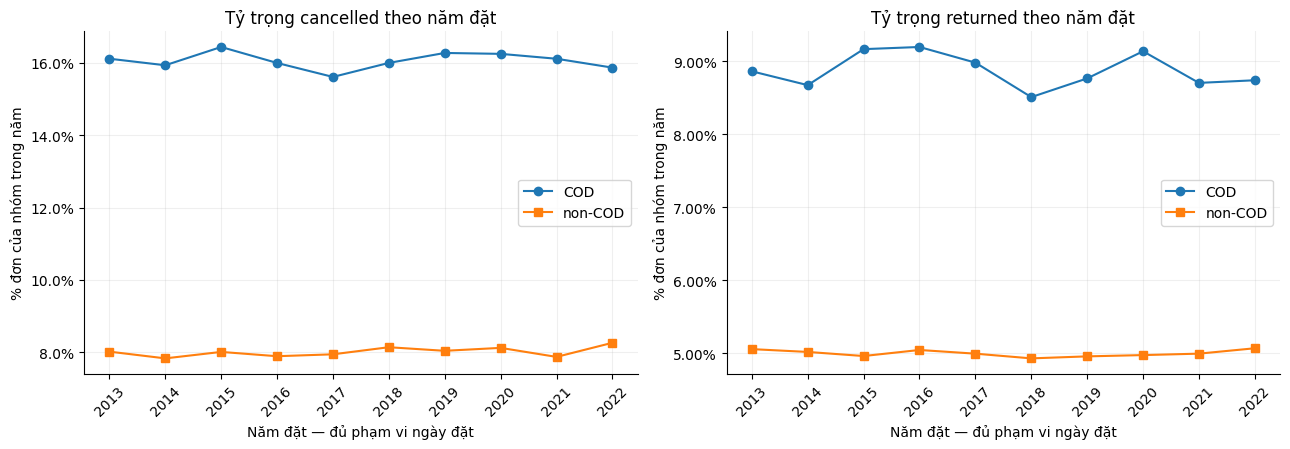

**Quan sát:** dấu COD cao hơn non-COD giữ ở 10/10 năm với cancelled, 10/10 năm với returned. Sau cùng trọng số năm, chênh là 8,050 và 3,894 đpt. **Ý nghĩa:** khác biệt tổng hợp không chỉ xuất hiện do hai nhóm có tỷ trọng năm khác nhau trong mẫu này. **Giới hạn:** chưa kiểm soát cơ cấu khách, giá trị đơn, kênh hoặc quy tắc trạng thái; không chứng minh COD gây hủy/trả. **Cần nghiên cứu tiếp:** chất lượng nhãn, thời điểm ghi nhận, khác biệt nhóm khách/giỏ hàng và khả năng theo dõi vòng đời; không khuyến nghị loại bỏ COD hoặc đổi chính sách từ kết quả hiện tại.

In [45]:
def cod_counts034(frame):
    work=frame[['order_id','order_date','order_status','payment_method']].copy()
    work['year']=work.order_date.dt.year;work['group']=np.where(work.payment_method.eq('cod'),'COD','non-COD')
    out=work.groupby(['year','group'],sort=True).agg(n=('order_id','size'),
        cancelled=('order_status',lambda s:int(s.eq('cancelled').sum())),
        returned=('order_status',lambda s:int(s.eq('returned').sum())))
    for s in ['cancelled','returned']:out[s+'_pct']=out[s]/out.n.replace(0,np.nan)*100
    return out

cod_year034=cod_counts034(cross034).loc[pd.IndexSlice[2013:2022,:],:]
cod_all034=[]
for name,mask in [('Toàn kỳ',pd.Series(True,index=cross034.index)),
                  ('2013–2022',cross034.order_date.dt.year.between(2013,2022))]:
    scope=cross034.loc[mask]
    for group,is_cod in [('COD',True),('non-COD',False)]:
        g=scope.loc[scope.payment_method.eq('cod').eq(is_cod)]
        cod_all034.append({'scope':name,'group':group,'n':len(g),
            **{s:int(g.order_status.eq(s).sum()) for s in ['cancelled','returned']},
            **{s+'_pct':pct(int(g.order_status.eq(s).sum()),len(g)) for s in ['cancelled','returned']}})
display(pd.DataFrame([{'Phạm vi':r['scope'],'Nhóm':r['group'],'N đơn nhóm':fmt(r['n']),
    'Cancelled — đơn (%)':fmt(r['cancelled'])+' ('+fpct(r['cancelled_pct'])+')',
    'Returned — đơn (%)':fmt(r['returned'])+' ('+fpct(r['returned_pct'])+')'} for r in cod_all034]))
cod_year_rows034=[]
for y in range(2013,2023):
    a=cod_year034.loc[(y,'COD')];b=cod_year034.loc[(y,'non-COD')]
    cod_year_rows034.append({'Năm đặt':y,'N COD':int(a.n),'N non-COD':int(b.n),
        **{s+' — COD đơn (%)':fmt(int(a[s]))+' ('+fpct(a[s+'_pct'])+')' for s in ['cancelled','returned']},
        **{s+' — non-COD đơn (%)':fmt(int(b[s]))+' ('+fpct(b[s+'_pct'])+')' for s in ['cancelled','returned']},
        **{s+' Δ (đpt)':fmt(a[s+'_pct']-b[s+'_pct'],3) for s in ['cancelled','returned']}})
with pd.option_context('display.max_columns',None):display(pd.DataFrame(cod_year_rows034))
weights034=cod_year034.n.groupby(level='year').sum()
weights034=weights034/weights034.sum()
cod_standard034={}
standard_rows034=[]
for s in ['cancelled','returned']:
    raw={r['group']:r[s+'_pct'] for r in cod_all034 if r['scope']=='2013–2022'}
    std={group:sum(float(weights034.loc[y])*float(cod_year034.at[(y,group),s+'_pct'])
        for y in weights034.index) for group in ['COD','non-COD']}
    cod_standard034[s]=std
    raw_gap=float(raw['COD']-raw['non-COD']);std_gap=std['COD']-std['non-COD']
    standard_rows034.append({'Nhãn trạng thái':s,'COD gộp (%)':fmt(raw['COD'],3),
        'non-COD gộp (%)':fmt(raw['non-COD'],3),'Δ gộp (đpt)':fmt(raw_gap,3),
        'COD cùng trọng số năm (%)':fmt(std['COD'],3),'non-COD cùng trọng số năm (%)':fmt(std['non-COD'],3),
        'Δ cùng trọng số năm (đpt)':fmt(std_gap,3),'Δ chuẩn hóa − Δ gộp (đpt)':fmt(std_gap-raw_gap,4)})
with pd.option_context('display.max_columns',None):display(pd.DataFrame(standard_rows034))
fig,axes=plt.subplots(1,2,figsize=(13,4.6))
for ax,s in zip(axes,['cancelled','returned']):
    for group,style in [('COD','o-'),('non-COD','s-')]:
        vals=cod_year034.xs(group,level='group')[s+'_pct'];ax.plot(vals.index,vals,style,label=group)
    ax.set(title='Tỷ trọng '+s+' theo năm đặt',xlabel='Năm đặt — đủ phạm vi ngày đặt',ylabel='% đơn của nhóm trong năm',
        xticks=range(2013,2023));ax.tick_params(axis='x',rotation=45)
    ax.yaxis.set_major_formatter(PercentFormatter(100));ax.grid(alpha=.2);ax.legend()
fig.tight_layout();display(fig);plt.close(fig)
positive_years034={s:sum(cod_year034.at[(y,'COD'),s+'_pct']>cod_year034.at[(y,'non-COD'),s+'_pct'] for y in range(2013,2023))
    for s in ['cancelled','returned']}
display(Markdown(f'**Quan sát:** dấu COD cao hơn non-COD giữ ở {positive_years034["cancelled"]}/10 năm với cancelled, '
    f'{positive_years034["returned"]}/10 năm với returned. Sau cùng trọng số năm, chênh là '
    f'{fmt(cod_standard034["cancelled"]["COD"]-cod_standard034["cancelled"]["non-COD"],3)} và '
    f'{fmt(cod_standard034["returned"]["COD"]-cod_standard034["returned"]["non-COD"],3)} đpt. '
    '**Ý nghĩa:** khác biệt tổng hợp không chỉ xuất hiện do hai nhóm có tỷ trọng năm khác nhau trong mẫu này. '
    '**Giới hạn:** chưa kiểm soát cơ cấu khách, giá trị đơn, kênh hoặc quy tắc trạng thái; không chứng minh COD gây hủy/trả. '
    '**Cần nghiên cứu tiếp:** chất lượng nhãn, thời điểm ghi nhận, khác biệt nhóm khách/giỏ hàng và khả năng theo dõi vòng đời; '
    'không khuyến nghị loại bỏ COD hoặc đổi chính sách từ kết quả hiện tại.'))


### NV03.4.7 — Bảng vấn đề và mức độ bằng chứng

**A — kỹ thuật:** chỉ gọi lỗi khi vi phạm ràng buộc đã xác định (khóa/JOIN, khả năng đọc ngày/tiền, công thức). Nếu không thấy vi phạm thì ghi rõ phạm vi, không tạo lỗi giả. Thứ tự ngày âm nếu có vẫn cần định nghĩa nghiệp vụ trước khi gọi lỗi sự kiện.

**B — nghiệp vụ cần làm rõ:** hiện tượng và số lượng đã quan sát, chưa có quy tắc xác nhận đúng/sai. **C — giới hạn dữ liệu:** thiếu thông tin để kết luận. Ưu tiên nghiên cứu là thứ tự cần làm rõ, **không phải xác suất/chắc chắn đó là lỗi**. Các vấn đề có thể liên quan cùng một đơn, không cộng số đơn giữa các dòng vấn đề.


In [46]:
technical034={
    'Khóa NULL orders':int(orders.order_id.isna().sum()),
    'Khóa orders trùng dư':int(orders.order_id.duplicated().sum()),
    'Shipment mồ côi':int((~ship_text034.order_id.isin(orders.order_id)).sum()),
    'Payment mồ côi':int((~payment_text033.order_id.isin(orders.order_id)).sum()),
    'Khóa shipment/payment NULL':int(ship_text034.order_id.isna().sum()+payment_text033.order_id.isna().sum()),
    'JOIN cấp đơn trùng dư':int(cross034.order_id.duplicated().sum()),
    'Ngày nguồn không NULL nhưng không đọc được':sum(r['Không NULL nhưng không đọc được'] for r in range_rows034),
    'Payment không đọc được/không hữu hạn':int(payment_parsed033.isna().sum()),
    'Sai công thức Net':int(cross034.net.ne(cross034.gross-cross034.discount).sum()),
    'Sai lệch Payment−Net vượt 0,05':int(cross034.payment_delta.dropna().abs().gt(TOL).sum())}
display(pd.DataFrame([{'Ràng buộc kỹ thuật đã kiểm tra':k,'Số vi phạm quan sát':v} for k,v in technical034.items()]))
extraction_timestamp034=None  # Không có trong nguồn: không gán ngày cuối orders làm thời điểm trích xuất.
issues034=[]
def issue034(code,kind,phenomenon,amount,source,checked,limit,needed,next_step,priority):
    issues034.append({'Mã vấn đề':code,'Loại bằng chứng':kind,'Hiện tượng':phenomenon,'Số đơn/giá trị liên quan':amount,
        'Nguồn':source,'Kiểm tra đã thực hiện':checked,'Giới hạn kết luận':limit,
        'Thông tin cần bổ sung':needed,'Hướng nghiên cứu tiếp':next_step,'Ưu tiên nghiên cứu':priority})
issue034('KT-01','A','Không phát hiện vi phạm trong ràng buộc kỹ thuật đã kiểm tra',
    str(sum(technical034.values()))+' vi phạm','orders/items/payments/shipments; V02',
    'Khóa, JOIN, ngày, tiền hữu hạn và công thức; chi tiết bảng trên',
    'Không chứng minh toàn bộ dữ liệu/quy trình đúng nghiệp vụ','Định nghĩa và ràng buộc nghiệp vụ',
    'Tiếp tục kiểm soát khi bổ sung dữ liệu','Theo dõi')
for code in ['A','B','C']:
    issue034('NV-'+code,'B',case_status034[code]+' không shipment',fmt(int(case_masks034[code].sum()))+' đơn',
        'orders + shipments','Đếm cấp đơn; tỷ lệ/N trạng thái; ngày đặt',
        'Chưa có quy tắc bắt buộc dòng shipment, chưa kết luận lỗi/đã giao','Quy tắc lưu shipment và nhật ký trạng thái',
        'NV03.5 tổng hợp câu hỏi; đối soát nghiệp vụ','Cao')
issue034('NV-D','B','shipped có delivery_date đọc được',fmt(int(case_masks034['D'].sum()))+' đơn',
    'orders + shipments','Số đơn, phạm vi ngày và phân bố năm','Chưa rõ actual/planned và thời điểm nhãn; chưa coi mâu thuẫn',
    'Từ điển ngày và lịch sử cập nhật','NV03.5 tổng hợp giới hạn mốc','Cao')
issue034('NV-E','B','cancelled/created/paid không shipment',
    fmt(sum(int(case_masks034['E_'+s].sum()) for s in ['cancelled','created','paid']))+' đơn',
    'orders + shipments','Tách N từng trạng thái, phạm vi ngày, năm','Sự vắng mặt chưa tự xác nhận đúng/sai quy trình',
    'Điều kiện phát sinh shipment','Đối chiếu quy tắc trạng thái','Vừa')
issue034('NV-COD','B','COD có tỷ trọng cancelled/returned cao hơn',
    str(positive_years034['cancelled'])+'/10 và '+str(positive_years034['returned'])+'/10 năm cùng dấu',
    'orders','N nhóm, tỷ lệ từng năm và cùng trọng số năm','Mô tả, chưa kiểm soát mọi yếu tố, không chứng minh nhân quả',
    'Chất lượng nhãn, hồ sơ khách/giỏ hàng, lịch sử xử lý','Ghi câu hỏi kiểm tra tiếp; chưa đổi chính sách','Vừa')
issue034('GH-01','C','Thiếu shipment tập trung cuối lịch sử đặt hàng',fmt(len(missing_focus034))+' đơn',
    'orders + shipments','Ngày đặt, cửa sổ 10 ngày, so với trước cửa sổ','Giới hạn quan sát/cập nhật là giả thuyết, chưa chứng minh cắt phải',
    'Thời điểm trích xuất từng bảng và theo dõi sau kỳ','NV03.5 ghi giới hạn quan sát','Cao')
issue034('GH-02','C','Payment=Net ở mọi trạng thái',fmt(len(cross034))+' đơn; Payment '+fmt(money034['payment_value'],2)+' ĐVT',
    'orders/items/payments; V02/V03','Đối chiếu từng đơn và tổng từng trạng thái','Không xác minh thực thu/quyết toán/sau hoàn',
    'Định nghĩa payment, trạng thái giao dịch, chứng từ quyết toán','NV04 đối chiếu hoàn tiền theo quy tắc xác minh','Cao')
issue034('GH-03','C','Ngày cuối orders không xác nhận ngày trích xuất',f'{end034:%d/%m/%Y}',
    'orders','Max order_date; so max ship/delivery','Không biết thời điểm trích xuất toàn hệ thống',
    'Metadata trích xuất và cập nhật','Giữ riêng phạm vi quan sát và thời điểm trích xuất','Cao')
issue034('GH-04','C','Chưa xác minh mốc giao thực tế/SLA','Không áp dụng',
    'shipments','Kiểm tra ngày ghi nhận, không tự gán actual/planned','Không tính giao đúng/chậm hạn hoặc hiệu suất thực tế',
    'Định nghĩa sự kiện, timestamp/múi giờ, ngày cam kết','NV03.5 tổng hợp giới hạn; xin tài liệu nghiệp vụ','Cao')
issue034('GH-05','C','Thiếu lịch sử trạng thái và mã giao dịch/kiện riêng','Không áp dụng',
    'orders/payments/shipments','Kiểm tra cấu trúc nguồn','Không khôi phục đầy đủ vòng đời đơn hoặc đếm giao dịch/kiện vật lý',
    'Event log, payment_id/shipment_id, thời điểm nhãn','Định nghĩa khóa và lịch sử liên kết','Vừa')
issue034('GH-06','C','shipping_fee chưa xác minh vai trò',fmt(int(cross034.shipping_fee.notna().sum()))+' đơn đọc được phí',
    'shipments','Số hợp lệ, âm, 0 và hiện diện; giữ riêng','Không coi là chi phí, thực thu hay thành phần Net',
    'Từ điển phí và chính sách ghi nhận','Xác minh định nghĩa trước khi dùng vào chỉ tiêu tiền','Vừa')
with pd.option_context('display.max_rows',None,'display.max_columns',None,'display.max_colwidth',None):
    display(pd.DataFrame(issues034))
display(Markdown('**Quan sát:** không phát hiện vi phạm kỹ thuật trong các ràng buộc liệt kê; '
    'các tổ hợp trạng thái/ngày/tiền được ghi thành B hoặc C với giới hạn cụ thể. '
    '**Ý nghĩa:** ưu tiên bổ sung định nghĩa và bằng chứng, không tự loại/sửa dữ liệu hoặc coi mọi trường hợp là lỗi. '
    '**Giới hạn:** cùng một đơn có thể liên quan nhiều dòng vấn đề. **Cần làm rõ:** chủ sở hữu trường, quy tắc nghiệp vụ và nguồn sự kiện.'))


,Ràng buộc kỹ thuật đã kiểm tra,Số vi phạm quan sát
0,Khóa NULL orders,0
1,Khóa orders trùng dư,0
2,Shipment mồ côi,0
3,Payment mồ côi,0
4,Khóa shipment/payment NULL,0
5,JOIN cấp đơn trùng dư,0
6,Ngày nguồn không NULL nhưng không đọc được,0
7,Payment không đọc được/không hữu hạn,0
8,Sai công thức Net,0
9,"Sai lệch Payment−Net vượt 0,05",0


,Mã vấn đề,Loại bằng chứng,Hiện tượng,Số đơn/giá trị liên quan,Nguồn,Kiểm tra đã thực hiện,Giới hạn kết luận,Thông tin cần bổ sung,Hướng nghiên cứu tiếp,Ưu tiên nghiên cứu
0,KT-01,A,Không phát hiện vi phạm trong ràng buộc kỹ thuật đã kiểm tra,0 vi phạm,orders/items/payments/shipments; V02,"Khóa, JOIN, ngày, tiền hữu hạn và công thức; chi tiết bảng trên",Không chứng minh toàn bộ dữ liệu/quy trình đúng nghiệp vụ,Định nghĩa và ràng buộc nghiệp vụ,Tiếp tục kiểm soát khi bổ sung dữ liệu,Theo dõi
1,NV-A,B,delivered không shipment,524 đơn,orders + shipments,Đếm cấp đơn; tỷ lệ/N trạng thái; ngày đặt,"Chưa có quy tắc bắt buộc dòng shipment, chưa kết luận lỗi/đã giao",Quy tắc lưu shipment và nhật ký trạng thái,NV03.5 tổng hợp câu hỏi; đối soát nghiệp vụ,Cao
2,NV-B,B,returned không shipment,29 đơn,orders + shipments,Đếm cấp đơn; tỷ lệ/N trạng thái; ngày đặt,"Chưa có quy tắc bắt buộc dòng shipment, chưa kết luận lỗi/đã giao",Quy tắc lưu shipment và nhật ký trạng thái,NV03.5 tổng hợp câu hỏi; đối soát nghiệp vụ,Cao
3,NV-C,B,shipped không shipment,11 đơn,orders + shipments,Đếm cấp đơn; tỷ lệ/N trạng thái; ngày đặt,"Chưa có quy tắc bắt buộc dòng shipment, chưa kết luận lỗi/đã giao",Quy tắc lưu shipment và nhật ký trạng thái,NV03.5 tổng hợp câu hỏi; đối soát nghiệp vụ,Cao
4,NV-D,B,shipped có delivery_date đọc được,13.762 đơn,orders + shipments,"Số đơn, phạm vi ngày và phân bố năm",Chưa rõ actual/planned và thời điểm nhãn; chưa coi mâu thuẫn,Từ điển ngày và lịch sử cập nhật,NV03.5 tổng hợp giới hạn mốc,Cao
5,NV-E,B,cancelled/created/paid không shipment,80.314 đơn,orders + shipments,"Tách N từng trạng thái, phạm vi ngày, năm",Sự vắng mặt chưa tự xác nhận đúng/sai quy trình,Điều kiện phát sinh shipment,Đối chiếu quy tắc trạng thái,Vừa
6,NV-COD,B,COD có tỷ trọng cancelled/returned cao hơn,10/10 và 10/10 năm cùng dấu,orders,"N nhóm, tỷ lệ từng năm và cùng trọng số năm","Mô tả, chưa kiểm soát mọi yếu tố, không chứng minh nhân quả","Chất lượng nhãn, hồ sơ khách/giỏ hàng, lịch sử xử lý",Ghi câu hỏi kiểm tra tiếp; chưa đổi chính sách,Vừa
7,GH-01,C,Thiếu shipment tập trung cuối lịch sử đặt hàng,564 đơn,orders + shipments,"Ngày đặt, cửa sổ 10 ngày, so với trước cửa sổ","Giới hạn quan sát/cập nhật là giả thuyết, chưa chứng minh cắt phải",Thời điểm trích xuất từng bảng và theo dõi sau kỳ,NV03.5 ghi giới hạn quan sát,Cao
8,GH-02,C,Payment=Net ở mọi trạng thái,"646.945 đơn; Payment 15.680.869.265,43 ĐVT",orders/items/payments; V02/V03,Đối chiếu từng đơn và tổng từng trạng thái,Không xác minh thực thu/quyết toán/sau hoàn,"Định nghĩa payment, trạng thái giao dịch, chứng từ quyết toán",NV04 đối chiếu hoàn tiền theo quy tắc xác minh,Cao
9,GH-03,C,Ngày cuối orders không xác nhận ngày trích xuất,31/12/2022,orders,Max order_date; so max ship/delivery,Không biết thời điểm trích xuất toàn hệ thống,Metadata trích xuất và cập nhật,Giữ riêng phạm vi quan sát và thời điểm trích xuất,Cao


**Quan sát:** không phát hiện vi phạm kỹ thuật trong các ràng buộc liệt kê; các tổ hợp trạng thái/ngày/tiền được ghi thành B hoặc C với giới hạn cụ thể. **Ý nghĩa:** ưu tiên bổ sung định nghĩa và bằng chứng, không tự loại/sửa dữ liệu hoặc coi mọi trường hợp là lỗi. **Giới hạn:** cùng một đơn có thể liên quan nhiều dòng vấn đề. **Cần làm rõ:** chủ sở hữu trường, quy tắc nghiệp vụ và nguồn sự kiện.

### Nhận xét kết thúc NV03.4 — chưa phải kết luận cuối cùng NV03

**Điểm nhất quán đã kiểm tra:** một dòng/đơn sau liên kết; tiền và số đơn bảo toàn; Payment=Net ở từng đơn và từng trạng thái; các cặp ngày đọc được có thứ tự không giảm trong mẫu hiện tại.

**Tổ hợp cần xác minh:** delivered/returned/shipped không shipment; shipped có delivery_date; cancelled/created/paid vẫn có Payment nhưng không shipment. Độ tập trung thiếu shipment ở cuối lịch sử đặt hàng được hỗ trợ bằng số đếm và mẫu số, nhưng nguyên nhân chưa được chứng minh. COD cao hơn non-COD về cancelled/returned trong từng năm và sau cùng trọng số năm, chưa chứng minh COD gây ra kết quả đó.

**Chưa đủ thông tin:** lịch sử chuyển trạng thái, nghĩa actual/planned của mốc ngày, thời điểm trích xuất/cập nhật, trạng thái giao dịch và quyết toán. Vì vậy chưa khôi phục đầy đủ vòng đời, xác nhận thực thu, ngày giao thực tế hoặc SLA.

**Chuyển tiếp dưới dạng câu hỏi:** NV03.5 tổng hợp các giới hạn và điểm vận hành cần xác minh; NV04 đối chiếu returns/refunds theo chính sách và thời điểm đã xác nhận. Chưa triển khai các phần đó, chưa trừ Refund để tính thực thu, chưa khuyến nghị thay đổi COD.


### Kiểm chứng độc lập và ví dụ nhỏ

Đối chứng bằng CSV/Decimal/datetime/Counter: kế thừa dict tiền cấp đơn và orders/payments độc lập ở NV03.1/NV03.3, đọc lại shipments bằng csv.DictReader. So **mọi order_id**, ngày/phí/số dòng, số đếm trạng thái/trường hợp/ngày/năm, tiền theo trạng thái và COD/non-COD. Dùng Fraction để tính lại tỷ lệ cùng trọng số năm, độc lập với phép tính Pandas/float.

Ví dụ nhỏ bao gồm thiếu shipment, shipped có delivery_date, cùng Payment=Net ở các trạng thái khác nhau, ngày nhuận, ngày sai/âm, nhiều shipment và tiền/phi bằng 0. Thiếu dữ liệu giữ thiếu; ngày/phí không được chọn tùy ý cho đơn nhiều dòng. Số đếm và tổng Decimal khớp chính xác; tỷ lệ float cho phép sai số 10⁻¹⁰ đpt.

Kiểm tra không thể thực hiện do thiếu nguồn được ghi riêng **Không áp dụng**, không tính đạt. Hai lượt Run All trên kernel mới phải chạy toàn bộ code, so kết quả 65 ô cũ và lưu nguyên bản chúng.


In [47]:
from fractions import Fraction
from datetime import timedelta as timedelta034
native_ship034={}
for r in csv_rows(SHIP_PATH):
    oid=r['order_id'];assert oid not in native_ship034
    native_ship034[oid]=(datetime.strptime(r['ship_date'],'%Y-%m-%d').date() if r['ship_date'] else None,
        datetime.strptime(r['delivery_date'],'%Y-%m-%d').date() if r['delivery_date'] else None,
        Decimal(r['shipping_fee']) if r['shipping_fee'] else None)
native_end034=max(r['date'] for r in native.values())
native_cases034={k:set() for k in case_masks034};native_daily034=defaultdict(Counter)
native_year_cases034=Counter();native_date_values034={m:Counter() for m in intervals034}
native_cod034=Counter();native_cod_n034=Counter();native_payment_state034=defaultdict(lambda:{
    'n':0,'payment_n':0,'net':ZERO,'payment':ZERO,'exact':0,'nonzero':0})
for oid,r in native_orders033.items():
    status=r['order_status'];day=native[oid]['date'];y=day.year
    sh=native_ship034.get(oid);is_focus=status in missing_states034
    d=native_daily034[day];d['all_n']+=1;d['all_missing']+=sh is None
    d['focus_n']+=is_focus;d['focus_missing']+=is_focus and sh is None
    code=('A' if status=='delivered' else 'B' if status=='returned' else 'C' if status=='shipped' else
        'E_'+status if status in ['cancelled','created','paid'] else None) if sh is None else (
        'D' if status=='shipped' and sh[1] is not None else None)
    if code:
        native_cases034[code].add(oid);native_year_cases034[(y,code)]+=1
    if sh:
        sd,dd,fee=sh
        values={'prep_days':(sd-day).days if sd else None,
            'transit_days':(dd-sd).days if sd and dd else None,'total_days':(dd-day).days if dd else None}
        for m,v in values.items():
            if v is not None:native_date_values034[m][v]+=1
    group='COD' if r['payment_method']=='cod' else 'non-COD'
    native_cod_n034[(y,group)]+=1;native_cod034[(y,group,status)]+=1
    p=native_payment_state034[status];p['n']+=1;p['payment_n']+=oid in native_pay033
    p['net']+=native[oid]['net'];p['payment']+=native_pay033[oid]['value']
    delta=native_pay033[oid]['value']-native[oid]['net'];p['exact']+=delta==0;p['nonzero']+=delta!=0

fxbase034=pd.DataFrame([
    ('01','2020-02-28','delivered','cod',Decimal(10),Decimal(0),Decimal(10),Decimal(10),1),
    ('2','2020-02-28','shipped','cod',Decimal(20),Decimal(0),Decimal(20),Decimal(20),1),
    ('3','2020-02-29','cancelled','paypal',Decimal(30),Decimal(0),Decimal(30),Decimal(30),1),
    ('4','2020-03-01','returned','credit_card',Decimal(40),Decimal(0),Decimal(40),Decimal(40),1),
    ('5','2020-03-01','created','credit_card',Decimal(0),Decimal(0),Decimal(0),Decimal(0),1),
    ('6','2020-03-01','paid','credit_card',Decimal(5),Decimal(0),Decimal(5),None,0),
    ('7','2020-03-01','shipped','paypal',Decimal(7),Decimal(0),Decimal(7),Decimal(7),1)],
    columns=['order_id','order_date','order_status','payment_method','gross','discount','net','payment_value','n_payment_rows'])
fxships034=pd.DataFrame([('2','2020-02-29','2020-03-01','0'),
    ('4','2020-03-02','2020-03-03','2'),('4','2020-03-03','2020-03-05','3'),
    ('6','2020-02-29','2020-02-28','1'),('7','bad-date','2020-03-03','bad-fee')],
    columns=['order_id','ship_date','delivery_date','shipping_fee'])
fx034=build_cross034(fxbase034,fxships034);fxby034=fx034.set_index('order_id')
fxcases034=cases034(fx034)
display(Markdown('**Ví dụ giả lập, không phải đơn thật:** 01 delivered thiếu shipment; 2 shipped có delivery_date và đi qua ngày nhuận; '
    '3 cancelled vẫn Payment=Net; 4 nhiều shipment nên không gán ngày/phí cấp đơn; 5 tiền 0 khác thiếu tiền ở 6; 6 có ngày âm; '
    '7 có ngày/phí sai giữ thiếu. Không suy thực thu hoặc sửa dữ liệu từ các nhãn này.'))
with pd.option_context('display.max_columns',None):
    display(fx034[['order_id','order_status','has_shipment','n_shipments','ship_date','delivery_date','shipping_fee',
        'net','payment_value','has_payment','payment_delta','prep_days','transit_days','total_days']])


**Ví dụ giả lập, không phải đơn thật:** 01 delivered thiếu shipment; 2 shipped có delivery_date và đi qua ngày nhuận; 3 cancelled vẫn Payment=Net; 4 nhiều shipment nên không gán ngày/phí cấp đơn; 5 tiền 0 khác thiếu tiền ở 6; 6 có ngày âm; 7 có ngày/phí sai giữ thiếu. Không suy thực thu hoặc sửa dữ liệu từ các nhãn này.

,order_id,order_status,has_shipment,n_shipments,ship_date,delivery_date,shipping_fee,net,payment_value,has_payment,payment_delta,prep_days,transit_days,total_days
0,01,delivered,False,0,NaT,NaT,None,10,10,True,0,<NA>,<NA>,<NA>
1,2,shipped,True,1,2020-02-29,2020-03-01,0,20,20,True,0,1,1,2
2,3,cancelled,False,0,NaT,NaT,None,30,30,True,0,<NA>,<NA>,<NA>
3,4,returned,True,2,NaT,NaT,None,40,40,True,0,<NA>,<NA>,<NA>
4,5,created,False,0,NaT,NaT,None,0,0,True,0,<NA>,<NA>,<NA>
5,6,paid,True,1,2020-02-29,2020-02-28,1,5,None,False,None,-1,-1,-2
6,7,shipped,True,1,NaT,2020-03-03,None,7,7,True,0,<NA>,<NA>,2


In [48]:
checks034=[]
def check034(name,condition):
    ok=bool(condition);checks034.append({'Kiểm chứng NV03.4':name,'Trạng thái':'Đạt' if ok else 'Không đạt','Phạm vi/lý do':'Áp dụng'})
    assert ok,name
def na034(name,reason):
    checks034.append({'Kiểm chứng NV03.4':name,'Trạng thái':'Không áp dụng','Phạm vi/lý do':reason})
check034('Số đơn/khóa duy nhất khớp orders, V02 và các phần trước',
    len(cross034)==n_orders==v02['metrics']['orders_rows']==len(native_orders033)
    and cross034.order_id.is_unique and cross034.order_id.notna().all())
check034('Tập mã và tổng dòng shipment/payment không nhân bản hoặc mất',
    set(cross034.order_id)==set(native_orders033)
    and int(cross034.n_shipments.sum())==len(ship_text034)==len(native_ship034)
    and int(cross034.n_payment_rows.sum())==len(payment_text033))
check034('Tổng Gross/Discount/Net/Payment khớp chính xác V02/NV03.1/NV03.3',
    all(money034[f]==v02['metrics']['payment' if f=='payment_value' else f]
        ==totals['payment' if f=='payment_value' else f]
        ==payment_totals033['payment' if f=='payment_value' else f] for f in money034))
check034('Mọi tiền cấp đơn/thuộc tính bảo toàn, không cộng phí vào Payment',
    all(r.gross==native[r.order_id]['gross'] and r.discount==native[r.order_id]['discount']
        and r.net==native[r.order_id]['net'] and r.payment_value==native_pay033[r.order_id]['value']
        and r.order_status==native_orders033[r.order_id]['order_status']
        and r.payment_method==native_orders033[r.order_id]['payment_method']
        and r.device_type==native_orders033[r.order_id]['device_type'] for r in cross034.itertuples()))
check034('Số đơn có/không shipment khớp NV03.2 và tra cứu CSV độc lập',
    int(cross034.has_shipment.sum())==ship_with==len(native_ship034)
    and int((~cross034.has_shipment).sum())==ship_without==len(native_orders033)-len(native_ship034)
    and all(r.has_shipment==(r.order_id in native_ship034) for r in cross034.itertuples()))
check034('Mọi trạng thái × shipment và tổng trạng thái khớp Counter',
    state034.n.to_dict()==dict(native_status)==status_counts.orders.to_dict()
    and all(int(state034.at[s,'with_ship'])==sum(oid in native_ship034 for oid,r in native_orders033.items() if r['order_status']==s)
        and int(state034.at[s,'without_ship'])==sum(oid not in native_ship034 for oid,r in native_orders033.items() if r['order_status']==s)
        for s in state034.index))
check034('Tập mã mỗi trường hợp A–E khớp định nghĩa độc lập, không trùng giữa nhóm',
    all(set(cross034.loc[mask,'order_id'])==native_cases034[code] for code,mask in case_masks034.items())
    and sum(int(mask.sum()) for mask in case_masks034.values())==len(set.union(*native_cases034.values())))
check034('Tỷ lệ trường hợp dùng đúng N trạng thái, không dùng N toàn kỳ',
    all(r['N đơn']==len(native_cases034[r['Nhóm trường hợp']])
        and r['N toàn trạng thái']==native_status[r['Trạng thái']]
        and r['% trong trạng thái']==fpct(pct(r['N đơn'],native_status[r['Trạng thái']])) for r in case_summary034))
check034('A/B/C và D khớp mốc NV03.2 (564 và 13.762 là tham chiếu kiểm tra)',
    sum(int(case_masks034[k].sum()) for k in ['A','B','C'])==len(ship_missing_observed_states)==564
    and int(case_masks034['A'].sum())==int(ship_late_status.loc['delivered'])
    and int(case_masks034['B'].sum())==int(ship_late_status.loc['returned'])
    and int(case_masks034['C'].sum())==int(ship_late_status.loc['shipped'])
    and int(case_masks034['D'].sum())==int(ship_record_state.loc['shipped','delivery_date_present'])==13762)
check034('Phân bố năm từng trường hợp đúng Counter/không mất mẫu',
    all(int(case_year_counts034.at[y,k])==native_year_cases034[(y,k)]
        for y in case_year_counts034.index for k in case_year_counts034.columns)
    and all(int(case_year_counts034[k].sum())==int(case_masks034[k].sum()) for k in case_year_counts034))
check034('Mọi ngày có N mọi đơn, N ba trạng thái, số thiếu khớp CSV độc lập',
    all(int(r[f])==native_daily034[day.date()][f] for day,r in daily034.iterrows()
        for f in ['all_n','all_missing','focus_n','focus_missing'])
    and len(daily034)==len(native_daily034))
check034('564 đơn đều trong 22–31/12/2022, khoảng cách ngày lịch đúng',
    end034.date()==native_end034 and start_tail034==pd.Timestamp('2022-12-22')
    and missing_focus034.order_date.between(start_tail034,end034).all()
    and len(missing_focus034)==sum(native_daily034[d]['focus_missing'] for d in native_daily034 if 0<=(native_end034-d).days<10)
    and set((end034-missing_focus034.order_date).dt.days)<=set(range(10)))
check034('Từng ô phân bố cuối kỳ theo trạng thái khớp tập mã độc lập',
    all(int(missing_by_day034.at[day,s])==sum(native[oid]['date']==day.date() for oid in native_cases034[code])
        for day in missing_by_day034.index for code,s in [('A','delivered'),('B','returned'),('C','shipped')])
    and int(missing_by_day034.to_numpy().sum())==len(missing_focus034))
window_ok034=True
for r,threshold in zip(period_summary034,[None,10,7,3]):
    selected=[d for d in native_daily034 if (native_end034-d).days>=10] if threshold is None else [
        d for d in native_daily034 if 0<=(native_end034-d).days<threshold]
    totals_native={f:sum(native_daily034[d][f] for d in selected) for f in ['all_n','all_missing','focus_n','focus_missing']}
    window_ok034 &= (r['N mọi đơn']==totals_native['all_n'] and r['Thiếu mọi trạng thái']==totals_native['all_missing']
        and r['N ba trạng thái']==totals_native['focus_n'] and r['Thiếu trong ba trạng thái']==totals_native['focus_missing']
        and r['% thiếu/N mọi đơn']==fpct(pct(totals_native['all_missing'],totals_native['all_n']))
        and r['% thiếu/N ba trạng thái']==fpct(pct(totals_native['focus_missing'],totals_native['focus_n'])))
check034('So cửa sổ cuối/trước đó và mọi tỷ lệ đúng mẫu số/không chồng cộng',window_ok034)
check034('Ngày và phí từng đơn đúng CSV/datetime/Decimal, thiếu giữ thiếu',
    all((pd.isna(r.ship_date) and pd.isna(r.delivery_date) and pd.isna(r.shipping_fee)) if r.order_id not in native_ship034 else
        (r.ship_date.date()==native_ship034[r.order_id][0] and r.delivery_date.date()==native_ship034[r.order_id][1]
         and r.shipping_fee==native_ship034[r.order_id][2]) for r in cross034.itertuples()))
check034('Mọi phân bố khoảng ngày/âm/0/min/max đúng datetime độc lập',
    all(cross034[m].dropna().astype(int).value_counts().to_dict()==dict(native_date_values034[m]) for m in intervals034)
    and all(r['Min ngày']==min(native_date_values034[m]) and r['Max ngày']==max(native_date_values034[m])
        and r['N bằng min']==native_date_values034[m][min(native_date_values034[m])]
        and r['N bằng max']==native_date_values034[m][max(native_date_values034[m])]
        for m,r in zip(intervals034,date_summary034)))
check034('Min/max ngày shipment và số sau ngày cuối orders khớp CSV độc lập',
    all(ship_records[f+'_parsed'].min().date()==min(v[pos] for v in native_ship034.values() if v[pos] is not None)
        and ship_records[f+'_parsed'].max().date()==max(v[pos] for v in native_ship034.values() if v[pos] is not None)
        and int(ship_records[f+'_parsed'].gt(end034).sum())==sum(v[pos]>native_end034 for v in native_ship034.values() if v[pos] is not None)
        for f,pos in [('ship_date',0),('delivery_date',1)]))
check034('Chỉ dùng ngày cuối orders làm mốc quan sát, không gán timestamp trích xuất',
    end034==cross034.order_date.max() and extraction_timestamp034 is None)
check034('Phí hiện diện/0 đúng nguồn, không coi thiếu phí là 0',
    int(cross034.shipping_fee.notna().sum())==sum(v[2] is not None for v in native_ship034.values())
    and int(cross034.shipping_fee.eq(0).sum())==sum(v[2]==0 for v in native_ship034.values())
    and cross034.loc[~cross034.has_shipment,'shipping_fee'].isna().all())
check034('Payment/Net từng trạng thái, N mẫu và tổng khớp dict độc lập',
    all(r['n']==native_payment_state034[r['status']]['n'] and r['has_payment']==native_payment_state034[r['status']]['payment_n']
        and r['net']==native_payment_state034[r['status']]['net'] and r['payment']==native_payment_state034[r['status']]['payment']
        and r['exact']==native_payment_state034[r['status']]['exact']
        and r['within_nonzero']+r['over']==native_payment_state034[r['status']]['nonzero']
        and r['payment_share']==pct(r['payment'],money034['payment_value']) for r in payment_state034)
    and sum(r['n'] for r in payment_state034)==len(cross034)
    and sum((r['payment'] for r in payment_state034),ZERO)==money034['payment_value'])
check034('COD/non-COD toàn kỳ và 2013–2022 đúng N nhóm và số trạng thái',
    all(r['n']==sum(n for (y,g),n in native_cod_n034.items() if g==r['group'] and (r['scope']=='Toàn kỳ' or 2013<=y<=2022))
        and all(r[s]==sum(n for (y,g,st),n in native_cod034.items()
            if g==r['group'] and st==s and (r['scope']=='Toàn kỳ' or 2013<=y<=2022))
            and r[s+'_pct']==pct(r[s],r['n']) for s in ['cancelled','returned']) for r in cod_all034))
check034('Mọi ô COD từng năm và tỷ lệ đúng Counter, phạm vi chỉ 2013–2022',
    set(cod_year034.index.get_level_values('year'))==set(range(2013,2023))
    and all(int(r.n)==native_cod_n034[(y,g)] and all(int(r[s])==native_cod034[(y,g,s)]
        and math.isclose(float(r[s+'_pct']),100*native_cod034[(y,g,s)]/native_cod_n034[(y,g)],rel_tol=0,abs_tol=1e-10)
        for s in ['cancelled','returned']) for (y,g),r in cod_year034.iterrows()))
native_std034={}
native_total_year034={y:sum(native_cod_n034[(y,g)] for g in ['COD','non-COD']) for y in range(2013,2023)}
for s in ['cancelled','returned']:
    for g in ['COD','non-COD']:
        native_std034[(s,g)]=sum((Fraction(native_total_year034[y],sum(native_total_year034.values()))
            *Fraction(100*native_cod034[(y,g,s)],native_cod_n034[(y,g)]) for y in range(2013,2023)),Fraction(0))
check034('Cùng trọng số năm khớp Fraction độc lập, tổng trọng số 1',
    math.isclose(weights034.sum(),1,rel_tol=0,abs_tol=1e-12)
    and all(math.isclose(float(cod_standard034[s][g]),float(native_std034[(s,g)]),rel_tol=0,abs_tol=1e-10)
        for s in ['cancelled','returned'] for g in ['COD','non-COD']))
check034('Dấu chênh từng năm và phạm vi cùng trọng số không trộn 2012',
    all(positive_years034[s]==sum(Fraction(native_cod034[(y,'COD',s)],native_cod_n034[(y,'COD')])
        >Fraction(native_cod034[(y,'non-COD',s)],native_cod_n034[(y,'non-COD')]) for y in range(2013,2023))
        for s in ['cancelled','returned'])
    and weights034.index.to_list()==list(range(2013,2023)))


In [49]:
check034('Ví dụ thiếu shipment, shipped có delivery_date, nhãn khác vẫn cùng Payment=Net',
    not fxby034.at['01','has_shipment'] and fxby034.at['01','payment_delta']==0
    and bool(fxcases034['A'].loc[fx034.order_id.eq('01')].iloc[0])
    and bool(fxcases034['D'].loc[fx034.order_id.eq('2')].iloc[0])
    and fxby034.at['2','delivery_date']==pd.Timestamp('2020-03-01')
    and fxby034.at['3','order_status']=='cancelled' and fxby034.at['3','payment_delta']==0)
check034('Ví dụ lịch nhuận, ngày âm và ngày sai không bị tự sửa',
    fxby034.at['2','prep_days']==1 and fxby034.at['2','transit_days']==1 and fxby034.at['2','total_days']==2
    and fxby034.at['6','prep_days']==-1 and fxby034.at['6','transit_days']==-1 and fxby034.at['6','total_days']==-2
    and pd.isna(fxby034.at['7','ship_date']) and fxby034.at['7','total_days']==2
    and pd.isna(fxby034.at['7','shipping_fee']))
check034('Ví dụ nhiều shipment không nhân đơn hoặc tùy ý chọn ngày/phí',
    len(fx034)==len(fxbase034) and fx034.order_id.is_unique and int(fx034.n_shipments.sum())==len(fxships034)
    and fxby034.at['4','n_shipments']==2
    and fxby034.loc['4',['ship_date','delivery_date','shipping_fee','prep_days','transit_days','total_days']].isna().all())
check034('Ví dụ tiền/phí 0 khác thiếu tiền/phí; mẫu số 0 để trống',
    fxby034.at['2','shipping_fee']==0 and pd.isna(fxby034.at['01','shipping_fee'])
    and fxby034.at['5','payment_value']==0 and bool(fxby034.at['5','has_payment'])
    and pd.isna(fxby034.at['6','payment_value']) and not fxby034.at['6','has_payment']
    and pd.isna(fxby034.at['6','payment_delta']) and pct(1,0) is None)
fxcod034=cod_counts034(fx034)
check034('Ví dụ COD mẫu số đúng và không mặc định COD luôn có tỷ lệ cao hơn',
    fxcod034.at[(2020,'COD'),'n']==2 and fxcod034.at[(2020,'non-COD'),'n']==5
    and fxcod034.at[(2020,'COD'),'cancelled_pct']==0
    and fxcod034.at[(2020,'non-COD'),'cancelled_pct']==20
    and fxcod034.at[(2020,'non-COD'),'returned_pct']==20)
blocked034=[]
for mode in ['duplicate_orders','orphan','null_key']:
    b=fxbase034.copy();s=fxships034.copy()
    if mode=='duplicate_orders':b=pd.concat([b,b.iloc[:1]],ignore_index=True)
    elif mode=='orphan':s.loc[0,'order_id']='unknown'
    else:s.loc[0,'order_id']=None
    try:build_cross034(b,s);blocked034.append(False)
    except AssertionError:blocked034.append(True)
check034('Ví dụ khóa trùng/mồ côi/NULL chặn JOIN',all(blocked034))
check034('Phân loại bằng chứng A/B/C rõ, không tạo lỗi kỹ thuật giả, ưu tiên riêng',
    sum(technical034.values())==0 and len({r['Mã vấn đề'] for r in issues034})==len(issues034)
    and {r['Loại bằng chứng'] for r in issues034}=={'A','B','C'}
    and all(r['Kiểm tra đã thực hiện'] and r['Giới hạn kết luận'] and r['Thông tin cần bổ sung']
        and r['Hướng nghiên cứu tiếp'] and r['Ưu tiên nghiên cứu'] for r in issues034)
    and all(r['Loại bằng chứng']=='B' for r in issues034 if r['Mã vấn đề'].startswith('NV-'))
    and all(r['Loại bằng chứng']=='C' for r in issues034 if r['Mã vấn đề'].startswith('GH-')))
check034('NV03.1–NV03.3 tiếp tục đạt kết quả kiểm chứng cũ',
    len(verification)==32 and all(r['Đạt'] for r in verification)
    and len(shipping_applied)==27 and all(r['Trạng thái']=='Đạt' for r in shipping_applied)
    and len(shipping_not_applicable)==5 and passed033==39 and failed033==0 and na_count033==4)
prefix034=load_notebook_for_audit(TARGET)['cells'][:65]
check034('65 ô gốc NV03.1–NV03.3 giữ nguyên Markdown/code/output đã lưu',
    hashlib.sha256(json.dumps(prefix034,ensure_ascii=False,sort_keys=True).encode()).hexdigest()=='2ecea3cb43c489432655be0d6772f000b061246b8319db6c326d67611d02d329')
check034('SHA-256 mọi file ngoài notebook, gồm untracked/raw/V01–V09/NV01/NV02 không đổi',
    protected_snapshot()==protected_before)
na034('Xác nhận thời điểm trích xuất toàn hệ thống','Không có metadata trích xuất; max order_date chỉ là ngày đặt cuối quan sát')
na034('Xác nhận thời gian giao thực tế','Thiếu định nghĩa actual/planned của các mốc ngày')
na034('Giao đúng hạn/chậm hạn/SLA','Không có ngày cam kết hoặc SLA')
na034('Tiền thực thu/quyết toán/thất bại giao dịch','Không có trạng thái giao dịch, chứng từ hoặc lịch quyết toán')
na034('Khôi phục đầy đủ vòng đời/chuyển trạng thái','Không có event log và timestamp trạng thái/giao dịch/kiện')
na034('Payment sau hoàn tiền hoặc doanh thu thực nhận','Thiếu quy tắc nghiệp vụ; chưa triển khai phân tích NV04')
with pd.option_context('display.max_rows',None,'display.max_colwidth',None):display(pd.DataFrame(checks034))


,Kiểm chứng NV03.4,Trạng thái,Phạm vi/lý do
0,"Số đơn/khóa duy nhất khớp orders, V02 và các phần trước",Đạt,Áp dụng
1,Tập mã và tổng dòng shipment/payment không nhân bản hoặc mất,Đạt,Áp dụng
2,Tổng Gross/Discount/Net/Payment khớp chính xác V02/NV03.1/NV03.3,Đạt,Áp dụng
3,"Mọi tiền cấp đơn/thuộc tính bảo toàn, không cộng phí vào Payment",Đạt,Áp dụng
4,Số đơn có/không shipment khớp NV03.2 và tra cứu CSV độc lập,Đạt,Áp dụng
5,Mọi trạng thái × shipment và tổng trạng thái khớp Counter,Đạt,Áp dụng
6,"Tập mã mỗi trường hợp A–E khớp định nghĩa độc lập, không trùng giữa nhóm",Đạt,Áp dụng
7,"Tỷ lệ trường hợp dùng đúng N trạng thái, không dùng N toàn kỳ",Đạt,Áp dụng
8,A/B/C và D khớp mốc NV03.2 (564 và 13.762 là tham chiếu kiểm tra),Đạt,Áp dụng
9,Phân bố năm từng trường hợp đúng Counter/không mất mẫu,Đạt,Áp dụng


In [50]:
passed034=sum(r['Trạng thái']=='Đạt' for r in checks034)
failed034=sum(r['Trạng thái']=='Không đạt' for r in checks034)
na_count034=sum(r['Trạng thái']=='Không áp dụng' for r in checks034)
assert failed034==0
display(Markdown(f'''**Hoàn thành chỉ NV03.4:** {fmt(len(cross034))} đơn duy nhất; tiền và số đơn bảo toàn.
Có {fmt(int(cross034.has_shipment.sum()))} đơn có shipment; {fmt(len(missing_focus034))} trường hợp
delivered/returned/shipped thiếu shipment tập trung cuối lịch sử order_date; chưa chứng minh nguyên nhân.
Payment=Net không xác nhận thực thu; các mốc ngày chưa xác nhận actual/planned.

**{passed034} kiểm chứng đạt, {failed034} không đạt, {na_count034} không áp dụng** (có lý do riêng, không tính đạt).
NV03.1: 32/32; NV03.2: 27/27 áp dụng + 5 không áp dụng; NV03.3: 39/39 áp dụng + 4 không áp dụng.
Giữ nguyên 65 ô trước; bằng chứng hai lượt Run All trên kernel mới lưu trong metadata execution_validation.
Không triển khai NV03.5/NV04–NV06, không tạo file phụ, không stage/commit/push.
'''))


**Hoàn thành chỉ NV03.4:** 646.945 đơn duy nhất; tiền và số đơn bảo toàn.
Có 566.067 đơn có shipment; 564 trường hợp
delivered/returned/shipped thiếu shipment tập trung cuối lịch sử order_date; chưa chứng minh nguyên nhân.
Payment=Net không xác nhận thực thu; các mốc ngày chưa xác nhận actual/planned.

**34 kiểm chứng đạt, 0 không đạt, 6 không áp dụng** (có lý do riêng, không tính đạt).
NV03.1: 32/32; NV03.2: 27/27 áp dụng + 5 không áp dụng; NV03.3: 39/39 áp dụng + 4 không áp dụng.
Giữ nguyên 65 ô trước; bằng chứng hai lượt Run All trên kernel mới lưu trong metadata execution_validation.
Không triển khai NV03.5/NV04–NV06, không tạo file phụ, không stage/commit/push.


# NV03.5 — Tổng hợp phát hiện và kết luận nghiệp vụ đơn hàng

Đây là phần kết thúc NV03, chỉ tổng hợp kết quả NV03.1–NV03.4. Giữ nguyên 85 ô trước, không đọc lại CSV để khảo sát mới, không tạo bảng chi tiết/biểu đồ trùng lặp, không triển khai NV04–NV06 hoặc mô hình. Các phép tổng hợp mới chỉ lấy một số lượng nhỏ dòng từ bảng/kết quả đã có trong bộ nhớ.

**Quy ước bằng chứng:** “đã xác minh” chỉ áp dụng cho kết quả số học, khóa và phân bố đã kiểm tra; quan hệ mô tả không thay quan hệ nhân quả. Giả thuyết về giới hạn quan sát/cập nhật được ghi rõ chưa xác minh. Thiếu tài liệu trong các nguồn đang xét không đồng nghĩa thông tin đó không tồn tại ở hệ thống khác.

### NV03.5.1 — Bảng chỉ tiêu tổng hợp

Bảng dưới ghép quy mô, trạng thái, vận chuyển, tiền, phương thức/thiết bị và mức độ bằng chứng. Mỗi hàng có đơn vị, mẫu số/phạm vi và nguồn ô/biến. Số ô nguồn **đánh từ 1**; mã ô notebook được giữ trong danh mục nguồn để kiểm chứng. Tổng tiền dùng ĐVT chưa xác minh tên tiền tệ; Net chưa trừ hoàn tiền. Tỷ trọng đơn, tỷ trọng Net, tỷ trọng trong trạng thái và điểm phần trăm được ghi riêng.

Phần A/C gom số đơn và Net theo trạng thái thành cùng hàng, không tái tạo các bảng chéo chi tiết. Năm đầu chỉ có một phần lịch; các tỷ trọng năm là cơ cấu nhãn của đơn đặt trong năm, không phải số sự kiện hoàn tất trong năm.


In [51]:
# Chỉ truy xuất kết quả đã tính; không đọc CSV, không JOIN/groupby lại bảng chi tiết.
sources035={
 'status':('NV03.1',5,('n_orders','n_customers_with_orders','date_start','date_end','status_counts')),
 'year':('NV03.1',8,('year_counts','year_shares','year_complete')),
 'money':('NV03.1',12,('totals',)),
 'status_money':('NV03.1',13,('money_status',)),
 'shipment':('NV03.2',27,('ship_with','ship_without','ship_multi')),
 'interval':('NV03.2',30,('ship_stats',)),
 'method_device':('NV03.3',50,('method033','device033')),
 'case':('NV03.4',68,('case_summary034','missing_focus034')),
 'tail':('NV03.4',70,('last034','before034','range_rows034','start_tail034','end034')),
 'payment_status':('NV03.4',74,('payment_state034',)),
 'cod':('NV03.4',76,('cod_all034','cod_year034','cod_standard034','positive_years034','weights034')),
 'quality':('NV03.4',78,('technical034','issues034')),
 'check1':('NV03.1',22,('verification',)),
 'check2':('NV03.2',44,('shipping_applied','shipping_not_applicable')),
 'check3':('NV03.3',64,('passed033','failed033','na_count033')),
 'check4':('NV03.4',84,('passed034','failed034','na_count034'))}
doc035=load_notebook_for_audit(TARGET)
source_catalog035={key:{'Phần':sec,'Ô (từ 1)':i+1,'Mã ô':doc035['cells'][i]['id'],'Biến':', '.join(variables)}
    for key,(sec,i,variables) in sources035.items()}
case_lookup035={r['Nhóm trường hợp']:r for r in case_summary034}
range_lookup035={r['Trường']:r for r in range_rows034}
cod_all_lookup035={r['group']:r for r in cod_all034 if r['scope']=='Toàn kỳ'}
issue_classes035=Counter(r['Loại bằng chứng'] for r in issues034)
old_counts035=[
    {'Phần':'NV03.1','Đạt':len(verification),'Không đạt':sum(not r['Đạt'] for r in verification),'Không áp dụng':0},
    {'Phần':'NV03.2','Đạt':len(shipping_applied),'Không đạt':sum(r['Trạng thái']!='Đạt' for r in shipping_applied),
        'Không áp dụng':len(shipping_not_applicable)},
    {'Phần':'NV03.3','Đạt':passed033,'Không đạt':failed033,'Không áp dụng':na_count033},
    {'Phần':'NV03.4','Đạt':passed034,'Không đạt':failed034,'Không áp dụng':na_count034}]
snap035={
 'orders':n_orders,'customers':n_customers_with_orders,'first_date':date_start,'last_date':date_end,
 'ship_with':ship_with,'ship_without':ship_without,'ship_coverage':pct(ship_with,n_orders),
 'missing_focus':sum(case_lookup035[k]['N đơn'] for k in ['A','B','C']),
 'shipped_date':case_lookup035['D']['N đơn'],'shipped_n':int(status_counts.at['shipped','orders']),
 'payment_exact':sum(r['exact'] for r in payment_state034),
 'payment_missing':sum(r['missing'] for r in payment_state034),
 'gross':totals['gross'],'discount':totals['discount'],'net':totals['net'],'payment':totals['payment'],
 'method_top':method033.orders.idxmax(),'device_top':device033.orders.idxmax(),
 'technical_rules':len(technical034),'technical_violations':sum(technical034.values()),
 'business_questions':issue_classes035['B'],'data_limits':issue_classes035['C'],
 'old_applied':sum(r['Đạt'] for r in old_counts035),'old_na':sum(r['Không áp dụng'] for r in old_counts035)}
cod_gap035={s:cod_all_lookup035['COD'][s+'_pct']-cod_all_lookup035['non-COD'][s+'_pct']
    for s in ['cancelled','returned']}
std_gap035={s:cod_standard034[s]['COD']-cod_standard034[s]['non-COD'] for s in ['cancelled','returned']}
delivered_years035={y:{'n':int(year_counts.at[y,'delivered']),'den':int(year_counts.loc[y].sum()),
    'pct':float(year_shares.at[y,'delivered'])} for y in [2020,2021,2022]}
kpis035=[];kpi_refs035={}
def add_kpi035(code,domain,name,value,unit,scope,refs):
    kpi_refs035[code]=tuple(refs)
    trace='; '.join(sources035[key][0]+' / ô '+str(sources035[key][1]+1)+' / '+', '.join(sources035[key][2]) for key in refs)
    kpis035.append({'Mã chỉ tiêu':code,'Nhóm':domain,'Chỉ tiêu':name,'Kết quả':value,
        'Đơn vị':unit,'Mẫu số/phạm vi':scope,'Nguồn ô/biến':trace})
add_kpi035('A01','A','Quy mô đơn; khách có đơn',fmt(snap035['orders'])+' đơn; '+fmt(snap035['customers'])+' khách',
    'order_id; customer_id duy nhất','Toàn kỳ, tất cả trạng thái',['status'])
add_kpi035('A02','A','Phạm vi order_date',f'{date_start:%d/%m/%Y}–{date_end:%d/%m/%Y}','Ngày đặt quan sát',
    'Không phải ngày sự kiện hoặc ngày trích xuất',['status'])
for s,r in status_counts.iterrows():
    add_kpi035('AC_'+s,'A/C',s,fmt(r.orders)+' đơn ('+fpct(r.share_pct)+'); Net '+fmt(money_status.at[s,'net'],2)+
        ' ĐVT ('+fpct(money_status.at[s,'net_share'])+' tổng Net)','Đơn; ĐVT',
        '% đơn / '+fmt(n_orders)+' đơn; % Net / '+fmt(totals['net'],2)+' ĐVT',['status','status_money'])
for y,r in delivered_years035.items():
    add_kpi035('AY_'+str(y),'A','Delivered năm '+str(y),fmt(r['n'])+'/'+fmt(r['den'])+' ('+fpct(r['pct'])+')',
        'Đơn (% trong năm)','Đơn đặt năm '+str(y)+'; đủ phạm vi lịch, chưa xác nhận hoàn tất',['year'])
add_kpi035('AY_delta','A','Delivered 2022 − 2020',fmt(delivered_years035[2022]['pct']-delivered_years035[2020]['pct'],3),
    'Điểm phần trăm','Hiệu tỷ trọng hai năm đặt, không phải tỷ lệ chuyển trạng thái',['year'])
add_kpi035('B01','B','Bao phủ shipment',fmt(ship_with)+' có; '+fmt(ship_without)+' không; '+fpct(snap035['ship_coverage'])+' có',
    'Đơn; % tổng đơn','Mẫu số '+fmt(n_orders)+' đơn; chưa xác nhận đã/chưa giao',['shipment'])
add_kpi035('B02','B','Ba trạng thái thiếu shipment',
    '; '.join(case_lookup035[k]['Trạng thái']+': '+fmt(case_lookup035[k]['N đơn']) for k in ['A','B','C']),
    'Đơn','Delivered/returned/shipped; tổng '+fmt(snap035['missing_focus'])+' đơn',['case'])
add_kpi035('B03','B','Shipped có delivery_date',fmt(snap035['shipped_date'])+'/'+fmt(snap035['shipped_n'])+
    ' ('+fpct(pct(snap035['shipped_date'],snap035['shipped_n']))+')','Đơn (% trong shipped)',
    'Ngày đọc được; chưa xác minh thực tế/dự kiến',['case','status'])
for f in ['ship_date','delivery_date']:
    r=range_lookup035[f]
    add_kpi035('B_'+f,'B','Phạm vi '+f,r['Ngày đầu']+'–'+r['Ngày cuối'],'Ngày ghi nhận',
        'Trên dòng shipment, không tự gán actual/planned',['tail'])
for m,label in [('prep_days','ship−order'),('transit_days','delivery−ship'),('total_days','delivery−order')]:
    r=ship_stats[m]
    add_kpi035('B_'+m,'B',label,fmt(r['mean'],3)+' trung bình; '+fmt(r['median'],3)+' trung vị',
        'Ngày lịch','N đủ cặp '+fmt(r['n'])+'; không phải thời gian thực tế/SLA đã xác minh',['interval'])
add_kpi035('B_tail','B','Thiếu shipment cuối kỳ (ba trạng thái)',
    fmt(last034['Thiếu trong ba trạng thái'])+'/'+fmt(last034['N ba trạng thái'])+' ('+last034['% thiếu/N ba trạng thái']+
    '); trước cửa sổ '+fmt(before034['Thiếu trong ba trạng thái'])+'/'+fmt(before034['N ba trạng thái']),
    'Đơn (% trong ba trạng thái)',f'{start_tail034:%d/%m/%Y}–{end034:%d/%m/%Y}; ngày đặt cuối chưa phải ngày trích xuất',['tail','case'])
add_kpi035('B_tail_all','B','Mẫu số mọi trạng thái cùng cửa sổ',
    fmt(last034['Thiếu mọi trạng thái'])+'/'+fmt(last034['N mọi đơn'])+' ('+last034['% thiếu/N mọi đơn']+')',
    'Đơn (% mọi trạng thái)','Khác mẫu số ba trạng thái; không cộng hai tập',['tail'])
for f in ['gross','discount','net','payment']:
    add_kpi035('C_'+f,'C','Tổng '+f,fmt(snap035[f],2),'ĐVT','Tất cả trạng thái; Net chưa trừ hoàn, Payment chưa xác minh thực thu',['money'])
add_kpi035('C_exact','C','Payment=Net chính xác',fmt(snap035['payment_exact'])+'/'+fmt(n_orders)+
    ' ('+fpct(pct(snap035['payment_exact'],n_orders))+')','Đơn (% toàn kỳ)','Nhất quán số học, không xác nhận quyết toán',['payment_status','money'])
for dim,table,label in [('method',method033,'Phương thức nhiều đơn nhất'),('device',device033,'Thiết bị nhiều đơn nhất')]:
    top=snap035['method_top' if dim=='method' else 'device_top'];r=table.loc[top]
    add_kpi035('D_'+dim,'D',label,top+': '+fmt(r.orders)+' ('+fpct(r.order_share)+'); '+fpct(r.net_share)+
        ' tổng Net; mean Net '+fmt(r.mean_net,2)+' ĐVT/đơn','Đơn; %; ĐVT/đơn',
        'Tỷ trọng đơn/Net toàn kỳ; mean trên đơn trong nhóm',['method_device'])
add_kpi035('D_cod','D','COD trong toàn bộ đơn',fmt(cod_all_lookup035['COD']['n'])+' ('+
    fpct(pct(cod_all_lookup035['COD']['n'],n_orders))+')','Đơn (% toàn kỳ)','non-COD là các phương thức khác, không đồng nghĩa trả trước',['cod'])
for s in ['cancelled','returned']:
    add_kpi035('D_'+s,'D',s+': COD và non-COD',
        '; '.join(g+': '+fmt(cod_all_lookup035[g][s])+'/'+fmt(cod_all_lookup035[g]['n'])+
            ' ('+fpct(cod_all_lookup035[g][s+'_pct'])+')' for g in ['COD','non-COD'])+
        '; Δ='+fmt(cod_gap035[s],3)+' đpt','Đơn; % nhóm; điểm phần trăm',
        'Toàn kỳ; mỗi tỷ lệ có N của chính nhóm phương thức',['cod'])
    add_kpi035('DY_'+s,'D',s+': chênh lệch theo năm',
        str(positive_years034[s])+'/'+str(len(weights034))+' năm cùng dấu; Δ cùng trọng số năm '+fmt(std_gap035[s],3)+' đpt',
        'Năm; điểm phần trăm','2013–2022, trọng số N mọi đơn từng năm; mô tả, chưa kiểm soát yếu tố khác',['cod'])
add_kpi035('E01','E','Ràng buộc kỹ thuật và vi phạm',fmt(snap035['technical_rules'])+' ràng buộc; '+
    fmt(snap035['technical_violations'])+' vi phạm quan sát','Ràng buộc; vi phạm',
    'Phạm vi technical034; không khẳng định mọi dữ liệu đúng nghiệp vụ',['quality'])
add_kpi035('E02','E','Vấn đề nghiệp vụ; giới hạn dữ liệu',fmt(snap035['business_questions'])+' mục B; '+
    fmt(snap035['data_limits'])+' mục C','Mục vấn đề, không phải đơn duy nhất',
    'Phân loại NV03.4; một đơn có thể thuộc nhiều mục',['quality'])
add_kpi035('E03','E','Kiểm chứng trước NV03.5',fmt(snap035['old_applied'])+' đạt; '+fmt(snap035['old_na'])+' không áp dụng',
    'Kiểm chứng','Khác số ràng buộc kỹ thuật; không áp dụng không tính đạt',['check1','check2','check3','check4'])
with pd.option_context('display.max_rows',None,'display.max_columns',None,'display.max_colwidth',None):
    display(pd.DataFrame(kpis035))
display(Markdown('**Cách đọc:** bảng này kế thừa các kết quả đã kiểm chứng. Các mốc ngày đo khoảng cách lịch; '
    'độ bao phủ chỉ đo sự có mặt bản ghi. Net theo trạng thái và Payment chưa thay cho doanh thu thực nhận. '
    'Các chỉ tiêu đếm vấn đề/ràng buộc không được cộng thành số đơn lỗi.'))


,Mã chỉ tiêu,Nhóm,Chỉ tiêu,Kết quả,Đơn vị,Mẫu số/phạm vi,Nguồn ô/biến
0,A01,A,Quy mô đơn; khách có đơn,646.945 đơn; 90.246 khách,order_id; customer_id duy nhất,"Toàn kỳ, tất cả trạng thái","NV03.1 / ô 6 / n_orders, n_customers_with_orders, date_start, date_end, status_counts"
1,A02,A,Phạm vi order_date,04/07/2012–31/12/2022,Ngày đặt quan sát,Không phải ngày sự kiện hoặc ngày trích xuất,"NV03.1 / ô 6 / n_orders, n_customers_with_orders, date_start, date_end, status_counts"
2,AC_delivered,A/C,delivered,"516.716 đơn (79,87%); Net 12.518.175.957,20 ĐVT (79,83% tổng Net)",Đơn; ĐVT,"% đơn / 646.945 đơn; % Net / 15.680.869.265,43 ĐVT","NV03.1 / ô 6 / n_orders, n_customers_with_orders, date_start, date_end, status_counts; NV03.1 / ô 14 / money_status"
3,AC_cancelled,A/C,cancelled,"59.462 đơn (9,19%); Net 1.447.013.637,43 ĐVT (9,23% tổng Net)",Đơn; ĐVT,"% đơn / 646.945 đơn; % Net / 15.680.869.265,43 ĐVT","NV03.1 / ô 6 / n_orders, n_customers_with_orders, date_start, date_end, status_counts; NV03.1 / ô 14 / money_status"
4,AC_returned,A/C,returned,"36.142 đơn (5,59%); Net 865.938.715,59 ĐVT (5,52% tổng Net)",Đơn; ĐVT,"% đơn / 646.945 đơn; % Net / 15.680.869.265,43 ĐVT","NV03.1 / ô 6 / n_orders, n_customers_with_orders, date_start, date_end, status_counts; NV03.1 / ô 14 / money_status"
5,AC_shipped,A/C,shipped,"13.773 đơn (2,13%); Net 337.278.840,20 ĐVT (2,15% tổng Net)",Đơn; ĐVT,"% đơn / 646.945 đơn; % Net / 15.680.869.265,43 ĐVT","NV03.1 / ô 6 / n_orders, n_customers_with_orders, date_start, date_end, status_counts; NV03.1 / ô 14 / money_status"
6,AC_paid,A/C,paid,"13.577 đơn (2,10%); Net 330.627.096,24 ĐVT (2,11% tổng Net)",Đơn; ĐVT,"% đơn / 646.945 đơn; % Net / 15.680.869.265,43 ĐVT","NV03.1 / ô 6 / n_orders, n_customers_with_orders, date_start, date_end, status_counts; NV03.1 / ô 14 / money_status"
7,AC_created,A/C,created,"7.275 đơn (1,12%); Net 181.835.018,77 ĐVT (1,16% tổng Net)",Đơn; ĐVT,"% đơn / 646.945 đơn; % Net / 15.680.869.265,43 ĐVT","NV03.1 / ô 6 / n_orders, n_customers_with_orders, date_start, date_end, status_counts; NV03.1 / ô 14 / money_status"
8,AY_2020,A,Delivered năm 2020,"27.975/34.881 (80,20%)",Đơn (% trong năm),"Đơn đặt năm 2020; đủ phạm vi lịch, chưa xác nhận hoàn tất","NV03.1 / ô 9 / year_counts, year_shares, year_complete"
9,AY_2021,A,Delivered năm 2021,"26.741/34.525 (77,45%)",Đơn (% trong năm),"Đơn đặt năm 2021; đủ phạm vi lịch, chưa xác nhận hoàn tất","NV03.1 / ô 9 / year_counts, year_shares, year_complete"


**Cách đọc:** bảng này kế thừa các kết quả đã kiểm chứng. Các mốc ngày đo khoảng cách lịch; độ bao phủ chỉ đo sự có mặt bản ghi. Net theo trạng thái và Payment chưa thay cho doanh thu thực nhận. Các chỉ tiêu đếm vấn đề/ràng buộc không được cộng thành số đơn lỗi.

### NV03.5.2 — Chín phát hiện nghiệp vụ có nguồn truy ngược

F01–F09 nối bằng chứng định lượng với ý nghĩa, giới hạn và câu hỏi tiếp theo. Mã chỉ tiêu trong bảng tổng hợp là đường truy ngược đến ô/biến NV03.1–NV03.4. Phần “bằng chứng” xác nhận hiện tượng trong dữ liệu, không tự xác nhận nguyên nhân, hiệu suất vận hành hoặc quyết toán.


In [52]:
findings035=[]
def finding035(code,title,evidence,refs,meaning,limit,question):
    keys=tuple(refs);source_keys=list(dict.fromkeys(k for ref in keys for k in kpi_refs035[ref]))
    source_text='; '.join(sources035[k][0]+' / ô '+str(sources035[k][1]+1) for k in source_keys)
    findings035.append({'Mã':code,'Phát hiện':title,'Bằng chứng định lượng':evidence,
        'Nguồn NV03 và chỉ tiêu':source_text+'; '+', '.join(keys),
        'Ý nghĩa nghiệp vụ':meaning,'Giới hạn diễn giải':limit,'Câu hỏi tiếp theo':question,
        '_kpis':keys,'_sources':tuple(source_keys)})
finding035('F01','Delivered chiếm đa số, cơ cấu thay đổi theo năm',
    fmt(status_counts.at['delivered','orders'])+'/'+fmt(n_orders)+' ('+fpct(status_counts.at['delivered','share_pct'])+'); '+
    '; '.join(str(y)+': '+fmt(r['n'])+'/'+fmt(r['den'])+' ('+fpct(r['pct'])+')' for y,r in delivered_years035.items()),
    ['AC_delivered','AY_2020','AY_2021','AY_2022','AY_delta'],
    'Cần đọc kết quả theo phạm vi trạng thái và kỳ đặt hàng trước khi so quy mô/giá trị.',
    'Tỷ trọng nhãn không phải tỷ lệ hoàn tất quy trình đã xác minh; năm đầu thiếu lịch, cuối kỳ chưa chắc đủ vòng đời.',
    'Nhãn được chốt ở thời điểm nào, có lịch sử và quy tắc thay đổi theo kỳ không?')
finding035('F02','Shipment không bao phủ toàn bộ đơn',
    fmt(ship_with)+' có / '+fmt(n_orders)+' ('+fpct(snap035['ship_coverage'])+'); '+fmt(ship_without)+' không; '+
    fmt(sum(case_lookup035['E_'+s]['N đơn'] for s in ['cancelled','created','paid']))+' không shipment thuộc cancelled/created/paid',
    ['B01','B02'],
    'Cần tách sự vắng mặt bản ghi theo trạng thái và quy tắc phát sinh shipment.',
    'Thiếu bản ghi không chứng minh chưa giao hoặc lỗi; shipment không tự đại diện mọi đơn.',
    'Những loại đơn nào bắt buộc có shipment, có trường hợp xử lý ngoài nguồn đang xét không?')
finding035('F03','Đo được khoảng cách lịch giữa các mốc ghi nhận',
    '; '.join(intervals034[m]+': mean '+fmt(ship_stats[m]['mean'],3)+', median '+fmt(ship_stats[m]['median'],3)+
        ' ngày, N='+fmt(ship_stats[m]['n']) for m in ['prep_days','transit_days','total_days']),
    ['B_prep_days','B_transit_days','B_total_days','B_ship_date','B_delivery_date'],
    'Mô tả được khoảng ngày trong mẫu đủ cặp, làm cơ sở kiểm tra định nghĩa mốc.',
    'Chưa xác minh actual/planned, chưa đo thời gian giao thực tế hoặc SLA; mẫu thiếu không điền 0.',
    'Mốc nào là sự kiện thực tế, múi giờ/timestamp và ngày cam kết là gì?')
finding035('F04','Nhãn shipped đi cùng delivery_date',
    fmt(snap035['shipped_date'])+'/'+fmt(snap035['shipped_n'])+' ('+fpct(pct(snap035['shipped_date'],snap035['shipped_n']))+')',
    ['B03'],
    'Định nghĩa ngày và thời điểm cập nhật nhãn cần được đối soát cùng nhau.',
    'Chưa chứng minh mâu thuẫn hoặc lỗi; delivery_date có thể mang nghĩa khác mốc thực tế.',
    'Ngày là dự kiến hay thực tế, nhãn có cập nhật đồng thời với mốc ngày không?')
finding035('F05','Thiếu shipment trong ba trạng thái tập trung cuối lịch sử đặt',
    fmt(snap035['missing_focus'])+' đơn trong '+f'{start_tail034:%d/%m/%Y}–{end034:%d/%m/%Y}; '+
    fmt(last034['Thiếu trong ba trạng thái'])+'/'+fmt(last034['N ba trạng thái'])+' ('+last034['% thiếu/N ba trạng thái']+
    '), trước đó '+fmt(before034['Thiếu trong ba trạng thái'])+'/'+fmt(before034['N ba trạng thái'])+
    '; mọi trạng thái cùng cửa sổ N='+fmt(last034['N mọi đơn']),
    ['B_tail','B_tail_all','B02'],
    'Mẫu quan sát cuối kỳ có cấu trúc khác, cần thận trọng khi so trạng thái và khoảng ngày.',
    'Giới hạn quan sát/cập nhật chỉ là giả thuyết; ngày cuối orders chưa phải ngày trích xuất đã xác minh.',
    'Metadata chốt từng bảng, quy tắc cập nhật và theo dõi sau kỳ có giải thích được hiện tượng không?')
finding035('F06','Giá trị đơn và Payment nhất quán về số học ở mọi trạng thái',
    fmt(snap035['payment_exact'])+'/'+fmt(n_orders)+' đơn khớp chính xác; Net=Payment='+fmt(snap035['net'],2)+
    ' ĐVT; cancelled/created/returned đều có giá trị ghi nhận',
    ['C_exact','C_net','C_payment','AC_cancelled','AC_created','AC_returned'],
    'Có cơ sở đối chiếu tiền cấp đơn; phạm vi trạng thái phải đi cùng chỉ tiêu NV01/NV02.',
    'Không chứng minh thực thu, quyết toán, giao dịch thành công hoặc giá trị sau hoàn tiền.',
    'payment_value là yêu cầu, giá trị giao dịch hay tiền đã đối soát; quy tắc hoàn và ghi nhận là gì?')
finding035('F07','Credit_card và mobile dẫn đầu số đơn',
    snap035['method_top']+': '+fpct(method033.at[snap035['method_top'],'order_share'])+' đơn, '+
    fpct(method033.at[snap035['method_top'],'net_share'])+' Net; '+snap035['device_top']+': '+
    fpct(device033.at[snap035['device_top'],'order_share'])+' đơn, '+fpct(device033.at[snap035['device_top'],'net_share'])+' Net',
    ['D_method','D_device','D_cod'],
    'Quy mô đơn, tỷ trọng Net và mean/đơn là những chỉ tiêu khác nhau; thiết bị là thuộc tính cấp đơn.',
    'Không suy hiệu quả hoặc nguyên nhân từ tỷ trọng; không cộng khách chồng lặp giữa phương thức/thiết bị.',
    'Cơ cấu khách/giỏ hàng và khả năng ghi nhận thiết bị có liên quan đến khác biệt mô tả không?')
finding035('F08','COD có cancelled/returned cao hơn non-COD trong các nhóm năm quan sát',
    '; '.join(s+': COD '+fpct(cod_all_lookup035['COD'][s+'_pct'])+', non-COD '+
        fpct(cod_all_lookup035['non-COD'][s+'_pct'])+', Δ='+fmt(cod_gap035[s],3)+' đpt; '+
        str(positive_years034[s])+'/'+str(len(weights034))+' năm cùng dấu; cùng trọng số Δ='+fmt(std_gap035[s],3)+' đpt'
        for s in ['cancelled','returned']),
    ['D_cancelled','D_returned','DY_cancelled','DY_returned'],
    'Đặt ra câu hỏi về khác biệt xử lý giữa các nhóm; chênh lệch không chỉ xuất hiện do cơ cấu năm khác nhau.',
    'Mô tả, chưa kiểm soát khách, sản phẩm, giá trị hoặc địa bàn; chưa chứng minh COD gây hủy/trả.',
    'Liên hệ còn giữ khi đối chiếu các thuộc tính và chất lượng nhãn, thời gian quan sát phù hợp không?')
finding035('F09','Không phát hiện vi phạm trong phạm vi kỹ thuật đã kiểm tra',
    fmt(snap035['technical_rules'])+' ràng buộc, '+fmt(snap035['technical_violations'])+' vi phạm; '+
    fmt(snap035['business_questions'])+' vấn đề nghiệp vụ, '+fmt(snap035['data_limits'])+' giới hạn dữ liệu; '+
    fmt(snap035['old_applied'])+' kiểm chứng áp dụng trước NV03.5',
    ['E01','E02','E03'],
    'Tách tính nhất quán kỹ thuật khỏi mức độ hiểu đúng nghiệp vụ và mức ưu tiên xác minh.',
    'Không chứng minh dữ liệu hoàn toàn đúng; số vấn đề không phải số đơn lỗi và có thể chồng lặp.',
    'Ràng buộc nghiệp vụ, chủ sở hữu trường và chứng từ nào cần bổ sung để nâng mức độ bằng chứng?')
findings_display035=[{k:v for k,v in r.items() if not k.startswith('_')} for r in findings035]
with pd.option_context('display.max_rows',None,'display.max_columns',None,'display.max_colwidth',None):
    display(pd.DataFrame(findings_display035))


,Mã,Phát hiện,Bằng chứng định lượng,Nguồn NV03 và chỉ tiêu,Ý nghĩa nghiệp vụ,Giới hạn diễn giải,Câu hỏi tiếp theo
0,F01,"Delivered chiếm đa số, cơ cấu thay đổi theo năm","516.716/646.945 (79,87%); 2020: 27.975/34.881 (80,20%); 2021: 26.741/34.525 (77,45%); 2022: 27.688/36.004 (76,90%)","NV03.1 / ô 6; NV03.1 / ô 14; NV03.1 / ô 9; AC_delivered, AY_2020, AY_2021, AY_2022, AY_delta",Cần đọc kết quả theo phạm vi trạng thái và kỳ đặt hàng trước khi so quy mô/giá trị.,"Tỷ trọng nhãn không phải tỷ lệ hoàn tất quy trình đã xác minh; năm đầu thiếu lịch, cuối kỳ chưa chắc đủ vòng đời.","Nhãn được chốt ở thời điểm nào, có lịch sử và quy tắc thay đổi theo kỳ không?"
1,F02,Shipment không bao phủ toàn bộ đơn,"566.067 có / 646.945 (87,50%); 80.878 không; 80.314 không shipment thuộc cancelled/created/paid","NV03.2 / ô 28; NV03.4 / ô 69; B01, B02",Cần tách sự vắng mặt bản ghi theo trạng thái và quy tắc phát sinh shipment.,Thiếu bản ghi không chứng minh chưa giao hoặc lỗi; shipment không tự đại diện mọi đơn.,"Những loại đơn nào bắt buộc có shipment, có trường hợp xử lý ngoài nguồn đang xét không?"
2,F03,Đo được khoảng cách lịch giữa các mốc ghi nhận,"ship_date − order_date: mean 1,498, median 1,000 ngày, N=566.067; delivery_date − ship_date: mean 4,499, median 4,000 ngày, N=566.067; delivery_date − order_date: mean 5,998, median 6,000 ngày, N=566.067","NV03.2 / ô 31; NV03.4 / ô 71; B_prep_days, B_transit_days, B_total_days, B_ship_date, B_delivery_date","Mô tả được khoảng ngày trong mẫu đủ cặp, làm cơ sở kiểm tra định nghĩa mốc.","Chưa xác minh actual/planned, chưa đo thời gian giao thực tế hoặc SLA; mẫu thiếu không điền 0.","Mốc nào là sự kiện thực tế, múi giờ/timestamp và ngày cam kết là gì?"
3,F04,Nhãn shipped đi cùng delivery_date,"13.762/13.773 (99,92%)",NV03.4 / ô 69; NV03.1 / ô 6; B03,Định nghĩa ngày và thời điểm cập nhật nhãn cần được đối soát cùng nhau.,Chưa chứng minh mâu thuẫn hoặc lỗi; delivery_date có thể mang nghĩa khác mốc thực tế.,"Ngày là dự kiến hay thực tế, nhãn có cập nhật đồng thời với mốc ngày không?"
4,F05,Thiếu shipment trong ba trạng thái tập trung cuối lịch sử đặt,"564 đơn trong 22/12/2022–31/12/2022; 564/846 (66,67%), trước đó 0/565.785; mọi trạng thái cùng cửa sổ N=1.000","NV03.4 / ô 71; NV03.4 / ô 69; B_tail, B_tail_all, B02","Mẫu quan sát cuối kỳ có cấu trúc khác, cần thận trọng khi so trạng thái và khoảng ngày.",Giới hạn quan sát/cập nhật chỉ là giả thuyết; ngày cuối orders chưa phải ngày trích xuất đã xác minh.,"Metadata chốt từng bảng, quy tắc cập nhật và theo dõi sau kỳ có giải thích được hiện tượng không?"
5,F06,Giá trị đơn và Payment nhất quán về số học ở mọi trạng thái,"646.945/646.945 đơn khớp chính xác; Net=Payment=15.680.869.265,43 ĐVT; cancelled/created/returned đều có giá trị ghi nhận","NV03.4 / ô 75; NV03.1 / ô 13; NV03.1 / ô 6; NV03.1 / ô 14; C_exact, C_net, C_payment, AC_cancelled, AC_created, AC_returned",Có cơ sở đối chiếu tiền cấp đơn; phạm vi trạng thái phải đi cùng chỉ tiêu NV01/NV02.,"Không chứng minh thực thu, quyết toán, giao dịch thành công hoặc giá trị sau hoàn tiền.","payment_value là yêu cầu, giá trị giao dịch hay tiền đã đối soát; quy tắc hoàn và ghi nhận là gì?"
6,F07,Credit_card và mobile dẫn đầu số đơn,"credit_card: 55,08% đơn, 55,04% Net; mobile: 45,06% đơn, 45,07% Net","NV03.3 / ô 51; NV03.4 / ô 77; D_method, D_device, D_cod","Quy mô đơn, tỷ trọng Net và mean/đơn là những chỉ tiêu khác nhau; thiết bị là thuộc tính cấp đơn.",Không suy hiệu quả hoặc nguyên nhân từ tỷ trọng; không cộng khách chồng lặp giữa phương thức/thiết bị.,Cơ cấu khách/giỏ hàng và khả năng ghi nhận thiết bị có liên quan đến khác biệt mô tả không?
7,F08,COD có cancelled/returned cao hơn non-COD trong các nhóm năm quan sát,"cancelled: COD 16,00%, non-COD 8,00%, Δ=8,004 đpt; 10/10 năm cùng dấu; cùng trọng số Δ=8,050 đpt; returned: COD 8,92%, non-COD 5,00%, Δ=3,914 đpt; 10/10 năm cùng dấu; cùng trọng số Δ=3,894 đpt","NV03.4 / ô 77; D_cancelled, D_returned, DY_cancelled, DY_returned",Đặt ra câu hỏi về khác biệt xử lý gi

### NV03.5.3 — Câu chuyện nghiệp vụ liên kết các nguồn

**Tính nhất quán khóa là điều kiện để đối chiếu, chưa phải bằng chứng đầy đủ về vòng đời.** F01–F04 cho thấy một đơn có thể liên kết đúng tiền và shipment, nhưng nhãn hiện có không cho biết các trạng thái đã đi qua hay thời điểm chuyển đổi. Vì vậy, shipped có delivery_date chưa chắc mâu thuẫn: phải xác nhận nghĩa ngày và thời điểm cập nhật nhãn trước. Khoảng cách giữa ngày đặt, xuất/giao ghi nhận chỉ là số học ngày lịch; nếu chưa biết mốc thực tế và thời hạn cam kết thì chưa đánh giá được giao trễ.

**Phạm vi quan sát nối trạng thái với độ đầy đủ shipment.** F02 và F05 phân biệt các nhãn vốn không có shipment trong nguồn với tập thiếu shipment tập trung cuối lịch sử. Nếu chỉ tính khoảng ngày trên các đơn có đủ mốc, các đơn chưa có thông tin sẽ không nằm trong mẫu; điều đó có thể gây sai lệch lựa chọn khi so sánh thời gian hoặc trạng thái. Đây là rủi ro diễn giải, không phải bằng chứng xác nhận cắt phải hoặc cơ chế thiếu. Cần metadata để phân biệt giới hạn trích xuất, cập nhật, định nghĩa và các khả năng khác.

**Giá trị đơn và thanh toán phải được nối bằng định nghĩa, không chỉ bằng phương trình.** F06 cho thấy Net và Payment khớp cả ở các nhãn cancelled/returned/created; sự khớp này xác minh công thức trong dữ liệu, chưa chứng minh giao dịch đã thu hoặc quyết toán. Vì Net bao gồm các trạng thái khác nhau, tổng tiền ở NV01 và Monetary ở NV02 phải được đọc cùng phạm vi trạng thái, giảm giá và hoàn tiền; shipping_fee chưa được tự cộng/trừ vào các chỉ tiêu ấy.

**Phương thức và thiết bị bổ sung góc nhìn phân bố, chưa xác định tác động.** F07–F08 phân biệt tỷ trọng số đơn, tổng Net và giá trị mỗi đơn. Chênh lệch COD giữ dấu theo năm và sau cùng trọng số năm giúp loại bỏ cách giải thích chỉ dựa cơ cấu năm khác nhau, nhưng chưa loại các khác biệt khách hàng, sản phẩm, địa bàn, giá trị đơn hoặc chất lượng nhãn. Chưa có cơ sở nhân quả để thay đổi chính sách COD. F09 vì thế đặt yêu cầu nâng chất lượng định nghĩa/bằng chứng trước khi diễn giải hiệu suất hoặc vòng đời.


### NV03.5.4 — Ưu tiên nghiên cứu tiếp

Mức ưu tiên xác định thứ tự làm rõ, không biểu thị mức chắc chắn có lỗi. Các bước dưới đây là đề xuất nghiên cứu, chưa được thực hiện trong NV03.5. Đặc biệt, NV04 chỉ được liên hệ để chuẩn bị câu hỏi về hoàn trả/hoàn tiền, chưa xây dựng công thức thực thu.


In [53]:
finding_lookup035={r['Mã']:r for r in findings035}
priorities035=[
 {'Mức ưu tiên':1,'Vấn đề':'Đơn hoàn trả và giá trị hoàn tiền','Bằng chứng hiện có':finding_lookup035['F06']['Bằng chứng định lượng'],
  'Câu hỏi chưa giải quyết':'Net ghi nhận, Payment và Refund liên hệ theo chính sách/thời điểm nào?',
  'Dữ liệu/tài liệu cần bổ sung':'Định nghĩa hoàn, khóa liên kết, chính sách phân bổ giảm giá/phí và chứng từ đối soát',
  'Phân tích cần thực hiện':'Đối chiếu returns, nhãn returned, payment_value và refund_amount; xác minh phạm vi trước khi đặt công thức',
  'Bước nghiệp vụ liên quan':'NV04 — chỉ định hướng','Phát hiện liên quan':'F06; F09'},
 {'Mức ưu tiên':2,'Vấn đề':'Ý nghĩa trạng thái và ngày vận chuyển','Bằng chứng hiện có':finding_lookup035['F04']['Bằng chứng định lượng'],
  'Câu hỏi chưa giải quyết':'Ngày thực tế/dự kiến? Nhãn shipped/delivered chốt khi nào? Có nhiều lượt giao ngoài biểu diễn hiện tại?',
  'Dữ liệu/tài liệu cần bổ sung':'Từ điển trạng thái/ngày, event log, mã kiện/lượt giao và thời điểm cập nhật',
  'Phân tích cần thực hiện':'Đối chiếu định nghĩa và mẫu chứng từ; chỉ đánh giá vòng đời/SLA khi đủ điều kiện',
  'Bước nghiệp vụ liên quan':'Quy trình đơn hàng/vận chuyển','Phát hiện liên quan':'F01; F02; F03; F04'},
 {'Mức ưu tiên':3,'Vấn đề':'Giới hạn quan sát cuối kỳ','Bằng chứng hiện có':finding_lookup035['F05']['Bằng chứng định lượng'],
  'Câu hỏi chưa giải quyết':'Ngày trích xuất/chốt từng bảng và nguyên tắc cập nhật sau kỳ là gì?',
  'Dữ liệu/tài liệu cần bổ sung':'Metadata trích xuất, phạm vi theo dõi sau kỳ và quy tắc cập nhật shipment',
  'Phân tích cần thực hiện':'Đối chiếu độ đầy đủ trước/sau mốc đã xác minh; chưa khẳng định cắt phải',
  'Bước nghiệp vụ liên quan':'Chốt dữ liệu và quan sát quy trình','Phát hiện liên quan':'F02; F05'},
 {'Mức ưu tiên':4,'Vấn đề':'Chênh lệch COD và non-COD','Bằng chứng hiện có':finding_lookup035['F08']['Bằng chứng định lượng'],
  'Câu hỏi chưa giải quyết':'Liên hệ còn giữ khi xét giá trị đơn, thời gian, địa bàn, khách và sản phẩm không?',
  'Dữ liệu/tài liệu cần bổ sung':'Phạm vi quan sát phù hợp, định nghĩa nhãn và các thuộc tính liên quan đã kiểm chứng',
  'Phân tích cần thực hiện':'Đối chiếu mô tả theo nhóm phù hợp; chưa thực hiện phân tích bổ sung, mô hình hoặc khuyến nghị chính sách tại đây',
  'Bước nghiệp vụ liên quan':'Hành vi đặt đơn và xử lý đơn','Phát hiện liên quan':'F07; F08'},
 {'Mức ưu tiên':5,'Vấn đề':'Ý nghĩa tài chính của các trường','Bằng chứng hiện có':finding_lookup035['F06']['Bằng chứng định lượng'],
  'Câu hỏi chưa giải quyết':'Payment là giá trị giao dịch/thực thu? Phí do ai chịu? Cancelled/returned được ghi nhận thế nào?',
  'Dữ liệu/tài liệu cần bổ sung':'Chính sách thanh toán, phí, hoàn tiền, điều kiện ghi nhận doanh thu và chứng từ quyết toán',
  'Phân tích cần thực hiện':'Xác minh định nghĩa trước khi dùng trường vào thực thu hoặc lợi nhuận',
  'Bước nghiệp vụ liên quan':'Thanh toán, đối soát và NV04','Phát hiện liên quan':'F06; F09'}]
with pd.option_context('display.max_rows',None,'display.max_columns',None,'display.max_colwidth',None):
    display(pd.DataFrame(priorities035))


,Mức ưu tiên,Vấn đề,Bằng chứng hiện có,Câu hỏi chưa giải quyết,Dữ liệu/tài liệu cần bổ sung,Phân tích cần thực hiện,Bước nghiệp vụ liên quan,Phát hiện liên quan
0,1,Đơn hoàn trả và giá trị hoàn tiền,"646.945/646.945 đơn khớp chính xác; Net=Payment=15.680.869.265,43 ĐVT; cancelled/created/returned đều có giá trị ghi nhận","Net ghi nhận, Payment và Refund liên hệ theo chính sách/thời điểm nào?","Định nghĩa hoàn, khóa liên kết, chính sách phân bổ giảm giá/phí và chứng từ đối soát","Đối chiếu returns, nhãn returned, payment_value và refund_amount; xác minh phạm vi trước khi đặt công thức",NV04 — chỉ định hướng,F06; F09
1,2,Ý nghĩa trạng thái và ngày vận chuyển,"13.762/13.773 (99,92%)",Ngày thực tế/dự kiến? Nhãn shipped/delivered chốt khi nào? Có nhiều lượt giao ngoài biểu diễn hiện tại?,"Từ điển trạng thái/ngày, event log, mã kiện/lượt giao và thời điểm cập nhật",Đối chiếu định nghĩa và mẫu chứng từ; chỉ đánh giá vòng đời/SLA khi đủ điều kiện,Quy trình đơn hàng/vận chuyển,F01; F02; F03; F04
2,3,Giới hạn quan sát cuối kỳ,"564 đơn trong 22/12/2022–31/12/2022; 564/846 (66,67%), trước đó 0/565.785; mọi trạng thái cùng cửa sổ N=1.000",Ngày trích xuất/chốt từng bảng và nguyên tắc cập nhật sau kỳ là gì?,"Metadata trích xuất, phạm vi theo dõi sau kỳ và quy tắc cập nhật shipment",Đối chiếu độ đầy đủ trước/sau mốc đã xác minh; chưa khẳng định cắt phải,Chốt dữ liệu và quan sát quy trình,F02; F05
3,4,Chênh lệch COD và non-COD,"cancelled: COD 16,00%, non-COD 8,00%, Δ=8,004 đpt; 10/10 năm cùng dấu; cùng trọng số Δ=8,050 đpt; returned: COD 8,92%, non-COD 5,00%, Δ=3,914 đpt; 10/10 năm cùng dấu; cùng trọng số Δ=3,894 đpt","Liên hệ còn giữ khi xét giá trị đơn, thời gian, địa bàn, khách và sản phẩm không?","Phạm vi quan sát phù hợp, định nghĩa nhãn và các thuộc tính liên quan đã kiểm chứng","Đối chiếu mô tả theo nhóm phù hợp; chưa thực hiện phân tích bổ sung, mô hình hoặc khuyến nghị chính sách tại đây",Hành vi đặt đơn và xử lý đơn,F07; F08
4,5,Ý nghĩa tài chính của các trường,"646.945/646.945 đơn khớp chính xác; Net=Payment=15.680.869.265,43 ĐVT; cancelled/created/returned đều có giá trị ghi nhận",Payment là giá trị giao dịch/thực thu? Phí do ai chịu? Cancelled/returned được ghi nhận thế nào?,"Chính sách thanh toán, phí, hoàn tiền, điều kiện ghi nhận doanh thu và chứng từ quyết toán",Xác minh định nghĩa trước khi dùng trường vào thực thu hoặc lợi nhuận,"Thanh toán, đối soát và NV04",F06; F09


### NV03.5.5 — Giới hạn phân tích và điều kiện nâng mức kết luận

Ba nhóm dưới đây phân loại **khả năng giải quyết giới hạn**, khác cách đánh nhãn A/B/C về mức độ bằng chứng ở NV03.4. Nhóm A có thể kiểm tra tiếp bằng dữ liệu hiện có, nhưng chưa thực hiện thêm tại đây; nhóm B cần định nghĩa/metadata; nhóm C là dữ liệu có thể cần bổ sung. Thông tin chưa có trong CSV đang xét không được suy thành chắc chắn không tồn tại bên ngoài.

Mỗi giới hạn phải nêu kết luận bị ảnh hưởng, điều chưa được khẳng định và điều kiện để kết luận tốt hơn. Không thay điều kiện còn thiếu bằng một giả định tiện lợi.


In [54]:
limits035=[]
def limit035(code,group,topic,affected,not_allowed,condition,refs):
    limits035.append({'Mã':code,'Nhóm khả năng giải quyết':group,'Giới hạn':topic,
        'Kết luận bị ảnh hưởng':affected,'Điều chưa được khẳng định':not_allowed,
        'Điều kiện để kết luận tốt hơn':condition,'Phát hiện liên quan':'; '.join(refs),'_refs':tuple(refs)})
limit035('LA1','A — dữ liệu hiện có','Cơ cấu trạng thái theo thời gian',
    'Khả năng so các kỳ đặt hàng','Không coi tỷ trọng nhãn là tỷ lệ chuyển trạng thái/hoàn tất',
    'Đọc N, phạm vi lịch và cơ cấu nhãn; chỉ kiểm tra mô tả theo cửa sổ phù hợp',['F01','F05'])
limit035('LA2','A — dữ liệu hiện có','COD/non-COD theo nhóm quan sát',
    'Mức ổn định của liên hệ trong mẫu','Không khẳng định COD gây hủy/trả',
    'Có thể đối chiếu nhóm giá trị, địa bàn, khách/sản phẩm sau kiểm tra nguồn; chưa thực hiện ở đây',['F08'])
limit035('LA3','A — dữ liệu hiện có','Độ bao phủ shipment theo ngày đặt',
    'Mẫu đủ mốc dùng phân tích khoảng ngày','Không khẳng định cơ chế thiếu hoặc đã/chưa giao',
    'Đọc đồng thời các mẫu số trạng thái/thời gian, tách có dòng và có mốc đọc được',['F02','F03','F05'])
limit035('LA4','A — dữ liệu hiện có','Giá trị đơn theo trạng thái',
    'Diễn giải Gross/Net và Monetary','Không coi giá trị của nhãn là doanh thu thực hiện hoặc khách trung thành',
    'Đối chiếu phạm vi trạng thái, tổng tiền và giá trị/đơn; giữ giới hạn định nghĩa tài chính',['F06','F07'])
limit035('LB1','B — định nghĩa/metadata','Ý nghĩa chính thức của order_status',
    'Vòng đời và tỷ lệ hoàn tất','Không suy chuỗi chuyển trạng thái hoặc lỗi từ tên nhãn',
    'Từ điển nhãn, thời điểm chốt/cập nhật và ràng buộc nghiệp vụ chính thức',['F01','F04','F09'])
limit035('LB2','B — định nghĩa/metadata','Ý nghĩa ship_date/delivery_date và SLA',
    'Khoảng thời gian vận hành/đúng hạn','Không gọi khoảng ngày là giao thực tế hoặc đánh giá trễ',
    'Xác nhận thực tế/dự kiến, ngày cam kết/SLA, timestamp và múi giờ',['F03','F04'])
limit035('LB3','B — định nghĩa/metadata','Thời điểm trích xuất/chốt từng bảng',
    'Diễn giải các đơn cuối lịch sử','Không khẳng định cắt phải tại ngày cuối orders',
    'Metadata trích xuất, lịch cập nhật, phạm vi theo dõi sau kỳ của từng nguồn',['F05'])
limit035('LB4','B — định nghĩa/metadata','Quy tắc ghi nhận thanh toán và doanh thu',
    'Thực thu/quyết toán/Net theo trạng thái','Không coi Payment=Net là đã thu hoặc cancelled là thu rồi hoàn',
    'Chính sách thanh toán, đối soát và điều kiện ghi nhận cho các trạng thái',['F06'])
limit035('LB5','B — định nghĩa/metadata','Vai trò shipping_fee và chính sách phí',
    'Chỉ tiêu tiền hoặc lợi nhuận','Không tự cộng phí vào Payment, trừ phí hay coi là chi phí thực tế',
    'Từ điển phí, bên chịu phí và quy tắc kế toán/đối soát',['F09','F06'])
limit035('LC1','C — dữ liệu có thể cần bổ sung','Lịch sử thay đổi trạng thái và lượt giao',
    'Khôi phục vòng đời đầy đủ','Không khẳng định mỗi đơn chỉ có một lượt giao vật lý vì CSV có một dòng',
    'Event log, mã kiện/lượt giao, thời điểm trạng thái và liên kết chính thức nếu cần',['F01','F02','F04'])
limit035('LC2','C — dữ liệu có thể cần bổ sung','Giao dịch và thời điểm thanh toán/quyết toán',
    'Xác minh thành công/thất bại và tiền thực thu','Không tự suy thời điểm hoặc kết quả giao dịch từ payment_value',
    'Mã giao dịch, trạng thái, timestamp và chứng từ đối soát từ nguồn thích hợp nếu cần',['F06'])
limit035('LC3','C — dữ liệu có thể cần bổ sung','Sự kiện giao thực tế nếu mốc hiện tại là dự kiến',
    'Thời gian giao thực tế và SLA','Không khẳng định nguồn thực tế không tồn tại ngoài CSV',
    'Sau xác minh nghĩa ngày, liên kết nguồn sự kiện giao thực tế và cam kết nếu cần',['F03','F04'])
limit035('LC4','C — dữ liệu có thể cần bổ sung','Hoàn tiền và đối soát thu ròng',
    'Xác minh số tiền sau hoàn','Không tự đặt công thức thực thu hoặc cho rằng các CSV hiện có đã đủ quy tắc',
    'NV04 đánh giá đủ nguồn returns/refunds, khóa, phạm vi, chính sách và chứng từ; bổ sung khi cần',['F06','F09'])
with pd.option_context('display.max_rows',None,'display.max_columns',None,'display.max_colwidth',None):
    display(pd.DataFrame([{k:v for k,v in r.items() if not k.startswith('_')} for r in limits035]))


,Mã,Nhóm khả năng giải quyết,Giới hạn,Kết luận bị ảnh hưởng,Điều chưa được khẳng định,Điều kiện để kết luận tốt hơn,Phát hiện liên quan
0,LA1,A — dữ liệu hiện có,Cơ cấu trạng thái theo thời gian,Khả năng so các kỳ đặt hàng,Không coi tỷ trọng nhãn là tỷ lệ chuyển trạng thái/hoàn tất,"Đọc N, phạm vi lịch và cơ cấu nhãn; chỉ kiểm tra mô tả theo cửa sổ phù hợp",F01; F05
1,LA2,A — dữ liệu hiện có,COD/non-COD theo nhóm quan sát,Mức ổn định của liên hệ trong mẫu,Không khẳng định COD gây hủy/trả,"Có thể đối chiếu nhóm giá trị, địa bàn, khách/sản phẩm sau kiểm tra nguồn; chưa thực hiện ở đây",F08
2,LA3,A — dữ liệu hiện có,Độ bao phủ shipment theo ngày đặt,Mẫu đủ mốc dùng phân tích khoảng ngày,Không khẳng định cơ chế thiếu hoặc đã/chưa giao,"Đọc đồng thời các mẫu số trạng thái/thời gian, tách có dòng và có mốc đọc được",F02; F03; F05
3,LA4,A — dữ liệu hiện có,Giá trị đơn theo trạng thái,Diễn giải Gross/Net và Monetary,Không coi giá trị của nhãn là doanh thu thực hiện hoặc khách trung thành,"Đối chiếu phạm vi trạng thái, tổng tiền và giá trị/đơn; giữ giới hạn định nghĩa tài chính",F06; F07
4,LB1,B — định nghĩa/metadata,Ý nghĩa chính thức của order_status,Vòng đời và tỷ lệ hoàn tất,Không suy chuỗi chuyển trạng thái hoặc lỗi từ tên nhãn,"Từ điển nhãn, thời điểm chốt/cập nhật và ràng buộc nghiệp vụ chính thức",F01; F04; F09
5,LB2,B — định nghĩa/metadata,Ý nghĩa ship_date/delivery_date và SLA,Khoảng thời gian vận hành/đúng hạn,Không gọi khoảng ngày là giao thực tế hoặc đánh giá trễ,"Xác nhận thực tế/dự kiến, ngày cam kết/SLA, timestamp và múi giờ",F03; F04
6,LB3,B — định nghĩa/metadata,Thời điểm trích xuất/chốt từng bảng,Diễn giải các đơn cuối lịch sử,Không khẳng định cắt phải tại ngày cuối orders,"Metadata trích xuất, lịch cập nhật, phạm vi theo dõi sau kỳ của từng nguồn",F05
7,LB4,B — định nghĩa/metadata,Quy tắc ghi nhận thanh toán và doanh thu,Thực thu/quyết toán/Net theo trạng thái,Không coi Payment=Net là đã thu hoặc cancelled là thu rồi hoàn,"Chính sách thanh toán, đối soát và điều kiện ghi nhận cho các trạng thái",F06
8,LB5,B — định nghĩa/metadata,Vai trò shipping_fee và chính sách phí,Chỉ tiêu tiền hoặc lợi nhuận,"Không tự cộng phí vào Payment, trừ phí hay coi là chi phí thực tế","Từ điển phí, bên chịu phí và quy tắc kế toán/đối soát",F09; F06
9,LC1,C — dữ liệu có thể cần bổ sung,Lịch sử thay đổi trạng thái và lượt giao,Khôi phục vòng đời đầy đủ,Không khẳng định mỗi đơn chỉ có một lượt giao vật lý vì CSV có một dòng,"Event log, mã kiện/lượt giao, thời điểm trạng thái và liên kết chính thức nếu cần",F01; F02; F04


### NV03.5.6 — Kết luận tổng thể NV03

Sáu đoạn sau kết nối quy mô, trạng thái, shipment, mốc ngày, phương thức và giá trị đơn. Các số liệu được nội suy từ biến đã kiểm chứng và dẫn về F01–F09; kết luận giữ đúng phạm vi mô tả. Đây là kết luận cho NV03, chưa thay phần đối chiếu hoàn trả/hoàn tiền ở NV04.


In [55]:
conclusions035=[
 {'refs':('F01','F09'),'text':f'NV03 xác lập quy mô {fmt(snap035["orders"])} đơn của {fmt(snap035["customers"])} khách có đơn '
    f'trong {date_start:%d/%m/%Y}–{date_end:%d/%m/%Y}, với delivered chiếm '
    f'{fpct(status_counts.at["delivered","share_pct"])}. Tỷ trọng delivered ở các năm đặt cuối lịch sử lần lượt là '+
    ', '.join(str(y)+': '+fpct(r['pct']) for y,r in delivered_years035.items())+
    '. Sự thay đổi cho thấy phạm vi trạng thái cần được giữ trong mọi phép so sánh giữa kỳ; nhãn hiện có chưa xác nhận '
    'tỷ lệ hoàn tất quy trình và không thay lịch sử chuyển trạng thái.'},
 {'refs':('F02','F04','F05'),'text':f'Shipment bổ sung thông tin cho {fmt(ship_with)} đơn, tương đương '
    f'{fpct(snap035["ship_coverage"])} toàn bộ đơn. Tuy nhiên, {fmt(snap035["missing_focus"])} đơn '
    f'delivered/returned/shipped thiếu shipment tập trung trong {start_tail034:%d/%m/%Y}–{end034:%d/%m/%Y}; '
    f'trong khi {fmt(snap035["shipped_date"])} đơn shipped có delivery_date xuất hiện trên phạm vi lịch sử rộng hơn. '
    'Hai hiện tượng đặt ra các câu hỏi khác nhau về độ đầy đủ quan sát và ý nghĩa mốc/nhãn. Chưa thể gọi chúng là lỗi vận hành '
    'hoặc khẳng định cắt phải, vì ngày cuối orders chưa xác nhận ngày trích xuất và quy tắc cập nhật.'},
 {'refs':('F03','F05'),'text':'Các cặp ngày đủ dữ liệu cho phép đo chênh lệch lịch: '+
    '; '.join(intervals034[m]+' có mean '+fmt(ship_stats[m]['mean'],3)+' và median '+fmt(ship_stats[m]['median'],3)+' ngày'
        for m in ['prep_days','transit_days','total_days'])+
    '. Đây là mô tả mốc ghi nhận trên mẫu đủ cặp. Nếu các đơn chưa có shipment hoặc chưa đạt mốc không nằm trong mẫu, '
    'việc so thời gian có thể chịu sai lệch lựa chọn; cơ chế đó chưa được chứng minh. Chưa xác minh actual/planned và SLA '
    'nên chưa đo thời gian giao thực tế hay tỷ lệ đúng/chậm hạn.'},
 {'refs':('F07','F08'),'text':f'{snap035["method_top"]} và {snap035["device_top"]} dẫn đầu tỷ trọng đơn, nhưng '
    'quy mô đơn, tổng Net và giá trị mỗi đơn phản ánh các khía cạnh khác nhau. COD có tỷ trọng cancelled/returned cao hơn '
    f'non-COD với dấu chênh giữ ở {positive_years034["cancelled"]}/{len(weights034)} và '
    f'{positive_years034["returned"]}/{len(weights034)} năm đầy đủ; chênh sau cùng trọng số năm là '
    f'{fmt(std_gap035["cancelled"],3)} và {fmt(std_gap035["returned"],3)} điểm phần trăm. '
    'Kết quả hỗ trợ một liên hệ mô tả không chỉ do cơ cấu năm, nhưng chưa chứng minh nhân quả hoặc hiệu quả của phương thức/thiết bị; '
    'các khác biệt khách hàng, sản phẩm, địa bàn, giá trị đơn và nhãn vẫn cần được xét.'},
 {'refs':('F06','F09'),'text':f'Tổng Gross {fmt(snap035["gross"],2)}, Discount {fmt(snap035["discount"],2)} và '
    f'Net {fmt(snap035["net"],2)} ĐVT được bảo toàn qua liên kết; Payment khớp Net ở '
    f'{fmt(snap035["payment_exact"])}/{fmt(n_orders)} đơn, kể cả cancelled, created và returned. '
    f'Không phát hiện vi phạm trong {fmt(snap035["technical_rules"])} ràng buộc kỹ thuật đã liệt kê, '
    f'nhưng còn {fmt(snap035["business_questions"])} vấn đề nghiệp vụ và {fmt(snap035["data_limits"])} giới hạn dữ liệu cần làm rõ. '
    'Tính nhất quán này chưa chứng minh thực thu/quyết toán hoặc dữ liệu hoàn toàn đúng nghiệp vụ; '
    'Net chưa trừ hoàn tiền và chưa xác định lợi nhuận thực tế từ các trường hiện có.'},
 {'refs':('F01','F05','F06','F08','F09'),'text':'NV03 cung cấp cơ sở kiểm soát phạm vi cho các nghiệp vụ liên quan: '
    'Gross/Net ở NV01 phải được đọc cùng trạng thái, giảm giá và chính sách ghi nhận; Frequency, Recency, Monetary ở NV02 '
    'phụ thuộc tập trạng thái và cửa sổ quan sát được chọn. Đầu vào cho NV04 là danh sách câu hỏi, định nghĩa và '
    'khóa cần đối chiếu giữa returns, nhãn returned, payment_value và refund_amount, cùng yêu cầu xác minh thời điểm/chính sách. '
    'Chưa triển khai NV04 hoặc tự tính thực thu bằng Payment trừ Refund. Ưu tiên tiếp theo là nâng mức bằng chứng '
    'về định nghĩa, lịch sử và đối soát trước khi kết luận đầy đủ vòng đời hay hiệu suất vận hành.'}]
display(Markdown('\n\n'.join(r['text']+' **[Nguồn: '+', '.join(r['refs'])+']**' for r in conclusions035)))


NV03 xác lập quy mô 646.945 đơn của 90.246 khách có đơn trong 04/07/2012–31/12/2022, với delivered chiếm 79,87%. Tỷ trọng delivered ở các năm đặt cuối lịch sử lần lượt là 2020: 80,20%, 2021: 77,45%, 2022: 76,90%. Sự thay đổi cho thấy phạm vi trạng thái cần được giữ trong mọi phép so sánh giữa kỳ; nhãn hiện có chưa xác nhận tỷ lệ hoàn tất quy trình và không thay lịch sử chuyển trạng thái. **[Nguồn: F01, F09]**

Shipment bổ sung thông tin cho 566.067 đơn, tương đương 87,50% toàn bộ đơn. Tuy nhiên, 564 đơn delivered/returned/shipped thiếu shipment tập trung trong 22/12/2022–31/12/2022; trong khi 13.762 đơn shipped có delivery_date xuất hiện trên phạm vi lịch sử rộng hơn. Hai hiện tượng đặt ra các câu hỏi khác nhau về độ đầy đủ quan sát và ý nghĩa mốc/nhãn. Chưa thể gọi chúng là lỗi vận hành hoặc khẳng định cắt phải, vì ngày cuối orders chưa xác nhận ngày trích xuất và quy tắc cập nhật. **[Nguồn: F02, F04, F05]**

Các cặp ngày đủ dữ liệu cho phép đo chênh lệch lịch: ship_date − order_date có mean 1,498 và median 1,000 ngày; delivery_date − ship_date có mean 4,499 và median 4,000 ngày; delivery_date − order_date có mean 5,998 và median 6,000 ngày. Đây là mô tả mốc ghi nhận trên mẫu đủ cặp. Nếu các đơn chưa có shipment hoặc chưa đạt mốc không nằm trong mẫu, việc so thời gian có thể chịu sai lệch lựa chọn; cơ chế đó chưa được chứng minh. Chưa xác minh actual/planned và SLA nên chưa đo thời gian giao thực tế hay tỷ lệ đúng/chậm hạn. **[Nguồn: F03, F05]**

credit_card và mobile dẫn đầu tỷ trọng đơn, nhưng quy mô đơn, tổng Net và giá trị mỗi đơn phản ánh các khía cạnh khác nhau. COD có tỷ trọng cancelled/returned cao hơn non-COD với dấu chênh giữ ở 10/10 và 10/10 năm đầy đủ; chênh sau cùng trọng số năm là 8,050 và 3,894 điểm phần trăm. Kết quả hỗ trợ một liên hệ mô tả không chỉ do cơ cấu năm, nhưng chưa chứng minh nhân quả hoặc hiệu quả của phương thức/thiết bị; các khác biệt khách hàng, sản phẩm, địa bàn, giá trị đơn và nhãn vẫn cần được xét. **[Nguồn: F07, F08]**

Tổng Gross 16.430.476.585,53, Discount 749.607.320,10 và Net 15.680.869.265,43 ĐVT được bảo toàn qua liên kết; Payment khớp Net ở 646.945/646.945 đơn, kể cả cancelled, created và returned. Không phát hiện vi phạm trong 10 ràng buộc kỹ thuật đã liệt kê, nhưng còn 6 vấn đề nghiệp vụ và 6 giới hạn dữ liệu cần làm rõ. Tính nhất quán này chưa chứng minh thực thu/quyết toán hoặc dữ liệu hoàn toàn đúng nghiệp vụ; Net chưa trừ hoàn tiền và chưa xác định lợi nhuận thực tế từ các trường hiện có. **[Nguồn: F06, F09]**

NV03 cung cấp cơ sở kiểm soát phạm vi cho các nghiệp vụ liên quan: Gross/Net ở NV01 phải được đọc cùng trạng thái, giảm giá và chính sách ghi nhận; Frequency, Recency, Monetary ở NV02 phụ thuộc tập trạng thái và cửa sổ quan sát được chọn. Đầu vào cho NV04 là danh sách câu hỏi, định nghĩa và khóa cần đối chiếu giữa returns, nhãn returned, payment_value và refund_amount, cùng yêu cầu xác minh thời điểm/chính sách. Chưa triển khai NV04 hoặc tự tính thực thu bằng Payment trừ Refund. Ưu tiên tiếp theo là nâng mức bằng chứng về định nghĩa, lịch sử và đối soát trước khi kết luận đầy đủ vòng đời hay hiệu suất vận hành. **[Nguồn: F01, F05, F06, F08, F09]**

### NV03.5.7 — Liên hệ nghiệp vụ và kiểm chứng tổng hợp

**NV01:** NV03 bổ sung phạm vi trạng thái và phân biệt Gross, Net, Payment; tổng giá trị ở mọi trạng thái chưa thể mặc định là doanh thu đã thực hiện.

**NV02:** lựa chọn tập trạng thái và cửa sổ quan sát có thể ảnh hưởng Frequency, Recency, Monetary và cách đánh giá khách hàng; nhiều đơn hoặc giá trị ghi nhận cao chưa đủ xác nhận trung thành/giá trị thực thu.

**NV04:** NV03 bàn giao các câu hỏi về returns, nhãn returned, payment_value và refund_amount, khóa liên kết, thời điểm và quy tắc nghiệp vụ. Chưa triển khai phân tích hoàn trả/hoàn tiền tại đây.

Kiểm chứng dưới đây truy ngược chỉ tiêu về kết quả đã có và các đối chứng độc lập đã dựng trước đó; không khảo sát lại CSV. Kiểm tra đường dẫn bằng chứng và sự hiện diện các cảnh báo không thay thế rà soát học thuật/ngữ nghĩa: các bảng phát hiện, câu chuyện và sáu đoạn kết luận phải được đọc cùng nguồn và giới hạn. Các khẳng định vòng đời, thực thu, SLA, nhân quả hoặc cơ chế cắt dữ liệu chưa đủ nguồn được ghi **Không áp dụng**, không tính là đạt.


In [56]:
import ast as ast035
checks035=[]
def check035(name,condition):
    ok=bool(condition);checks035.append({'Kiểm chứng NV03.5':name,'Trạng thái':'Đạt' if ok else 'Không đạt','Lý do/phạm vi':'Áp dụng'})
    assert ok,name
def na035(name,reason):
    checks035.append({'Kiểm chứng NV03.5':name,'Trạng thái':'Không áp dụng','Lý do/phạm vi':reason})
check035('Quy mô đơn/khách kế thừa khớp V02 và dict/set độc lập',
    snap035['orders']==v02['metrics']['orders_rows']==len(native)==646945
    and snap035['customers']==len(native_customers)==90246)
check035('Trạng thái: số đơn/tỷ trọng đúng mẫu số toàn kỳ, bảo toàn tổng',
    sum(status_counts.orders)==snap035['orders']
    and all(int(r.orders)==native_status[s] and r.share_pct==pct(native_status[s],snap035['orders'])
        for s,r in status_counts.iterrows()))
check035('Phạm vi ngày là ngày đặt quan sát, không gán thành thời điểm trích xuất',
    date_start.date()==min(native_days) and date_end.date()==max(native_days)
    and extraction_timestamp034 is None)
check035('Delivered 2020–2022 khớp Counter/năm độc lập và đủ phạm vi lịch',
    all(r['n']==native_year_status[(y,'delivered')]
        and r['den']==sum(native_year_status[(y,s)] for s in native_status)
        and math.isclose(r['pct'],100*r['n']/r['den'],rel_tol=0,abs_tol=1e-10)
        and bool(year_complete.loc[y]) for y,r in delivered_years035.items()))
check035('Có/không shipment kế thừa đúng tổng đơn và dict shipment độc lập',
    snap035['ship_with']==len(native_ship034) and snap035['ship_with']+snap035['ship_without']==snap035['orders']
    and snap035['ship_coverage']==pct(len(native_ship034),len(native)))
check035('564 trường hợp thiếu shipment đúng ba trạng thái, không cộng nhầm nhóm khác',
    snap035['missing_focus']==sum(len(native_cases034[k]) for k in ['A','B','C'])==564
    and all(case_lookup035[k]['N đơn']==len(native_cases034[k]) for k in case_lookup035))
native_tail_days035=[native_end034-timedelta034(days=i) for i in range(10)]
native_tail035={f:sum(native_daily034[d][f] for d in native_tail_days035)
    for f in ['all_n','all_missing','focus_n','focus_missing']}
check035('Cuối kỳ: đúng 564/846, khác 718/1.000; nguồn Counter đã tính',
    last034['Thiếu trong ba trạng thái']==native_tail035['focus_missing']
    and last034['N ba trạng thái']==native_tail035['focus_n']==846
    and last034['N mọi đơn']==native_tail035['all_n']==1000
    and last034['Thiếu mọi trạng thái']==native_tail035['all_missing']
    and last034['% thiếu/N ba trạng thái']==fpct(pct(native_tail035['focus_missing'],native_tail035['focus_n'])))
check035('Mẫu trước cửa sổ giữ đúng phạm vi và mẫu số ba trạng thái',
    before034['N ba trạng thái']==sum(r['focus_n'] for r in native_daily034.values())-native_tail035['focus_n']
    and before034['Thiếu trong ba trạng thái']==sum(r['focus_missing'] for r in native_daily034.values())-native_tail035['focus_missing']
    and start_tail034==end034-pd.Timedelta(days=9))
check035('Shipped có delivery_date dùng đúng mẫu số trạng thái và tập mã độc lập',
    snap035['shipped_date']==len(native_cases034['D'])==13762 and snap035['shipped_n']==native_status['shipped'])
interval_ok035=True
year_summary035=ship_group_tables['order_year']
for m in ['prep_days','transit_days','total_days']:
    n=sum(int(r[m+'_n']) for _,r in year_summary035.iterrows())
    weighted=sum(float(r[m+'_mean'])*int(r[m+'_n']) for _,r in year_summary035.iterrows())/n
    interval_ok035 &= n==ship_stats[m]['n'] and math.isclose(weighted,ship_stats[m]['mean'],rel_tol=0,abs_tol=1e-9)
    interval_ok035 &= all(r['Trạng thái']=='Đạt' for r in shipping_applied)
check035('Khoảng ngày kế thừa đúng mẫu; mean đối chiếu tổng hợp năm tối thiểu',
    interval_ok035 and fxby034.at['2','prep_days']==1 and fxby034.at['2','transit_days']==1 and fxby034.at['2','total_days']==2)
check035('Gross/Discount/Net/Payment khớp chính xác V02 và tổng dict trạng thái độc lập',
    all(snap035[f]==v02['metrics'][f]==sum((r['payment' if f=='payment' else f] for r in native_money.values()),ZERO)
        for f in ['gross','discount','net']) and snap035['payment']==v02['metrics']['payment']==snap035['net'])
check035('Net theo từng trạng thái ở hàng A/C khớp dict độc lập',
    all(money_status.at[s,'net']==native_payment_state034[s]['net']
        and money_status.at[s,'net_share']==pct(native_payment_state034[s]['net'],snap035['net']) for s in money_status.index))
check035('Payment=Net chính xác chỉ xác minh số học; số đối chiếu khớp dict',
    snap035['payment_exact']==sum(r['exact'] for r in native_payment_state034.values())==snap035['orders']
    and snap035['payment_missing']==0 and all(r['net']==r['payment'] for r in native_payment_state034.values()))
for dim,table,key in [('payment_method',method033,'method_top'),('device_type',device033,'device_top')]:
    independent_top=sorted(oracle033[dim],key=lambda k:(-oracle033[dim][k]['orders'],k))[0]
    check035(dim+': nhóm nhiều đơn nhất, tỷ trọng đơn/Net và mean đúng nguồn độc lập',
        snap035[key]==independent_top and table.at[independent_top,'orders']==oracle033[dim][independent_top]['orders']
        and table.at[independent_top,'order_share']==pct(oracle033[dim][independent_top]['orders'],snap035['orders'])
        and table.at[independent_top,'net_share']==pct(oracle033[dim][independent_top]['net'],snap035['net'])
        and table.at[independent_top,'mean_net']==divide(oracle033[dim][independent_top]['net'],oracle033[dim][independent_top]['orders']))
check035('COD/non-COD toàn kỳ giữ đúng N từng nhóm và tỷ lệ từng nhãn',
    sum(r['n'] for r in cod_all_lookup035.values())==snap035['orders']
    and all(r['n']==sum(n for (y,g),n in native_cod_n034.items() if g==group)
        and all(r[s]==sum(n for (y,g,st),n in native_cod034.items() if g==group and st==s)
            and r[s+'_pct']==pct(r[s],r['n']) for s in ['cancelled','returned'])
        for group,r in cod_all_lookup035.items()))
check035('Chênh lệch COD toàn kỳ đúng hiệu tỷ trọng, đơn vị đpt',
    all(cod_gap035[s]==cod_all_lookup035['COD'][s+'_pct']-cod_all_lookup035['non-COD'][s+'_pct']
        for s in ['cancelled','returned']))
check035('Chuẩn hóa năm có nguồn thực, đúng Fraction đã tính và phạm vi đủ lịch',
    list(weights034.index)==list(range(2013,2023))
    and all(math.isclose(std_gap035[s],float(native_std034[(s,'COD')]-native_std034[(s,'non-COD')]),
        rel_tol=0,abs_tol=1e-10) for s in ['cancelled','returned'])
    and all(positive_years034[s]==sum(Fraction(native_cod034[(y,'COD',s)],native_cod_n034[(y,'COD')])
        >Fraction(native_cod034[(y,'non-COD',s)],native_cod_n034[(y,'non-COD')]) for y in range(2013,2023))
        for s in ['cancelled','returned']))
check035('Phân biệt số ràng buộc, vi phạm, vấn đề B/C và kiểm chứng',
    snap035['technical_rules']==len(technical034) and snap035['technical_violations']==0
    and snap035['business_questions']==sum(r['Loại bằng chứng']=='B' for r in issues034)
    and snap035['data_limits']==sum(r['Loại bằng chứng']=='C' for r in issues034)
    and snap035['technical_rules']!=snap035['old_applied'])
check035('Các kiểm chứng cũ giữ đúng 132 đạt, 0 không đạt và 15 không áp dụng',
    [r['Đạt'] for r in old_counts035]==[32,27,39,34]
    and snap035['old_applied']==132 and snap035['old_na']==15
    and all(r['Không đạt']==0 for r in old_counts035))
check035('Mỗi KPI có mã duy nhất, đơn vị, mẫu số và nguồn thuộc phần cũ',
    len({r['Mã chỉ tiêu'] for r in kpis035})==len(kpis035)==len(kpi_refs035)
    and all(r['Kết quả'] and r['Đơn vị'] and r['Mẫu số/phạm vi'] and r['Nguồn ô/biến'] for r in kpis035)
    and all(refs and all(k in sources035 for k in refs) for refs in kpi_refs035.values()))
check035('Danh mục nguồn trỏ đúng ô/ID/biến thực tế, đánh số ô từ 1',
    all(0<=i<85 and doc035['cells'][i]['cell_type']=='code'
        and source_catalog035[key]['Mã ô']==doc035['cells'][i]['id']
        and source_catalog035[key]['Ô (từ 1)']==i+1
        and all(v in ''.join(doc035['cells'][i]['source']) for v in vs)
        for key,(sec,i,vs) in sources035.items()))
check035('F01–F09 đầy đủ bằng chứng, ý nghĩa, giới hạn, câu hỏi và truy ngược KPI',
    [r['Mã'] for r in findings035]==['F'+str(i).zfill(2) for i in range(1,10)]
    and all(r['Bằng chứng định lượng'] and r['Ý nghĩa nghiệp vụ'] and r['Giới hạn diễn giải'] and r['Câu hỏi tiếp theo']
        and r['_kpis'] and all(k in kpi_refs035 for k in r['_kpis'])
        and set(r['_sources'])=={s for k in r['_kpis'] for s in kpi_refs035[k]} for r in findings035))
check035('Bảng ưu tiên đủ năm hướng, gắn F và chỉ đề xuất nghiên cứu',
    [r['Mức ưu tiên'] for r in priorities035]==list(range(1,6))
    and all(r['Bằng chứng hiện có'] and r['Câu hỏi chưa giải quyết'] and r['Dữ liệu/tài liệu cần bổ sung']
        and r['Phân tích cần thực hiện'] and r['Bước nghiệp vụ liên quan'] for r in priorities035)
    and 'NV04' in priorities035[0]['Bước nghiệp vụ liên quan'])
check035('Giới hạn A/B/C có hệ quả, điều không khẳng định và điều kiện bổ sung',
    {r['Nhóm khả năng giải quyết'][0] for r in limits035}=={'A','B','C'}
    and len({r['Mã'] for r in limits035})==len(limits035)
    and all(r['Kết luận bị ảnh hưởng'] and r['Điều chưa được khẳng định'] and r['Điều kiện để kết luận tốt hơn']
        and all(k in finding_lookup035 for k in r['_refs']) for r in limits035))
check035('Sáu đoạn kết luận liên kết F có nguồn, không chèn thống kê không dẫn nguồn',
    len(conclusions035)==6 and all(r['text'] and r['refs'] and all(k in finding_lookup035 for k in r['refs']) for r in conclusions035))
conclusion_text035=' '.join(r['text'] for r in conclusions035)
check035('Cảnh báo về hoàn tất, thực thu, SLA, nhân quả và trích xuất còn trong kết luận',
    all(term in conclusion_text035 for term in ['chưa xác nhận','chưa chứng minh','thực thu','SLA','ngày trích xuất','chưa xác định lợi nhuận'])
    and 'Chưa triển khai NV04' in conclusion_text035)
current_doc035=load_notebook_for_audit(TARGET)
forbidden035={'read_csv','read_table','csv_rows','merge','groupby','to_csv','to_json','to_parquet','build_cross034','cod_counts034'}
called035=[]
for c in current_doc035['cells'][85:]:
    if c['cell_type']!='code':continue
    for node in ast035.walk(ast035.parse(''.join(c['source']))):
        if isinstance(node,ast035.Call):
            called035.append(node.func.attr if isinstance(node.func,ast035.Attribute) else node.func.id if isinstance(node.func,ast035.Name) else '')
check035('Code NV03.5 không đọc khảo sát CSV, JOIN/groupby lại hay xuất dữ liệu phụ',
    not (set(called035)&forbidden035))
check035('85 ô gốc giữ nguyên Markdown/code/output đã lưu',
    hashlib.sha256(json.dumps(current_doc035['cells'][:85],ensure_ascii=False,sort_keys=True).encode()).hexdigest()=='d2349b22f771c7fe33788bf89d6c717ab85bf37f056e8a5d6c4df20c2fd875f0')
check035('SHA-256 mọi tệp ngoài notebook, gồm raw/NV01/NV02/V01–V09/untracked không đổi',
    protected_snapshot()==protected_before)
na035('Tỷ lệ hoàn tất/vòng đời thực tế','Thiếu định nghĩa nhãn, lịch sử trạng thái và sự kiện; chưa đủ nguồn để kết luận')
na035('Thực thu/quyết toán/lợi nhuận/sau hoàn','Khớp Payment=Net chỉ là số học; thiếu định nghĩa/chứng từ, NV04 chưa triển khai')
na035('Thời gian giao thực tế và SLA/trễ hạn','Chưa xác minh actual/planned và chưa có cam kết giao trong nguồn đang xét')
na035('COD gây cancelled/returned','Chỉ có liên hệ mô tả; cùng trọng số năm chưa kiểm soát mọi yếu tố')
na035('Cắt phải tại ngày cuối orders/ngày trích xuất','Thiếu metadata chốt/cập nhật; đây vẫn là giả thuyết cần xác minh')
with pd.option_context('display.max_rows',None,'display.max_colwidth',None):display(pd.DataFrame(checks035))
passed035=sum(r['Trạng thái']=='Đạt' for r in checks035)
failed035=sum(r['Trạng thái']=='Không đạt' for r in checks035)
na_count035=sum(r['Trạng thái']=='Không áp dụng' for r in checks035)
not_run035=sum(r['Trạng thái']=='Chưa chạy' for r in checks035)
assert failed035==not_run035==0
counts035=old_counts035+[{'Phần':'NV03.5','Đạt':passed035,'Không đạt':failed035,'Không áp dụng':na_count035}]
display(pd.DataFrame(counts035+[
    {'Phần':'Tổng NV03','Đạt':sum(r['Đạt'] for r in counts035),'Không đạt':sum(r['Không đạt'] for r in counts035),
        'Không áp dụng':sum(r['Không áp dụng'] for r in counts035)}]))
display(Markdown(f'''**Hoàn thành NV03.5 và phần tổng hợp NV03:** {len(kpis035)} chỉ tiêu, {len(findings035)} phát hiện,
{len(priorities035)} mức ưu tiên, {len(limits035)} giới hạn được giải thích; sáu đoạn kết luận có nguồn.
**NV03.5: {passed035} đạt, {failed035} không đạt, {na_count035} không áp dụng; {not_run035} kiểm chứng đăng ký chưa chạy.**
Không áp dụng không tính đạt; chưa xác minh thực thu, SLA, nhân quả hoặc cơ chế cắt dữ liệu.
Giữ nguyên 85 ô trước; hai lượt Run All trên kernel Jupyter mới được ghi trong metadata execution_validation.
Không triển khai NV04–NV06/Giai đoạn 2, không tạo tệp phụ, không stage/commit/push.
'''))


,Kiểm chứng NV03.5,Trạng thái,Lý do/phạm vi
0,Quy mô đơn/khách kế thừa khớp V02 và dict/set độc lập,Đạt,Áp dụng
1,"Trạng thái: số đơn/tỷ trọng đúng mẫu số toàn kỳ, bảo toàn tổng",Đạt,Áp dụng
2,"Phạm vi ngày là ngày đặt quan sát, không gán thành thời điểm trích xuất",Đạt,Áp dụng
3,Delivered 2020–2022 khớp Counter/năm độc lập và đủ phạm vi lịch,Đạt,Áp dụng
4,Có/không shipment kế thừa đúng tổng đơn và dict shipment độc lập,Đạt,Áp dụng
5,"564 trường hợp thiếu shipment đúng ba trạng thái, không cộng nhầm nhóm khác",Đạt,Áp dụng
6,"Cuối kỳ: đúng 564/846, khác 718/1.000; nguồn Counter đã tính",Đạt,Áp dụng
7,Mẫu trước cửa sổ giữ đúng phạm vi và mẫu số ba trạng thái,Đạt,Áp dụng
8,Shipped có delivery_date dùng đúng mẫu số trạng thái và tập mã độc lập,Đạt,Áp dụng
9,Khoảng ngày kế thừa đúng mẫu; mean đối chiếu tổng hợp năm tối thiểu,Đạt,Áp dụng


,Phần,Đạt,Không đạt,Không áp dụng
0,NV03.1,32,0,0
1,NV03.2,27,0,5
2,NV03.3,39,0,4
3,NV03.4,34,0,6
4,NV03.5,30,0,5
5,Tổng NV03,162,0,20


**Hoàn thành NV03.5 và phần tổng hợp NV03:** 37 chỉ tiêu, 9 phát hiện,
5 mức ưu tiên, 13 giới hạn được giải thích; sáu đoạn kết luận có nguồn.
**NV03.5: 30 đạt, 0 không đạt, 5 không áp dụng; 0 kiểm chứng đăng ký chưa chạy.**
Không áp dụng không tính đạt; chưa xác minh thực thu, SLA, nhân quả hoặc cơ chế cắt dữ liệu.
Giữ nguyên 85 ô trước; hai lượt Run All trên kernel Jupyter mới được ghi trong metadata execution_validation.
Không triển khai NV04–NV06/Giai đoạn 2, không tạo tệp phụ, không stage/commit/push.
